# Эксперимент: влияние denoising на subject-independent классификацию Motor Imagery

## Цель

Проверить, может ли предварительный denoising EEG повысить качество бинарной классификации моторного воображения:

- `Left Hand / Left Fist`
- `Right Hand / Right Fist`

для ранее невиданного моделью испытуемого в режиме **strict Leave-One-Subject-Out (LOSO)**.

Основная цель эксперимента — не восстановление искусственно испорченного сигнала само по себе, а проверка гипотезы:

> **Denoising способен удалить часть нерелевантной межсубъектной и внутрисубъектной вариативности даже из исходного EEG и тем самым улучшить downstream-классификацию Motor Imagery.**

Синтетически загрязнённый EEG рассматривается как дополнительный эксперимент на устойчивость модели к шумам.

---

## Датасеты

### BCI Competition IV Dataset 2a

Исходно содержит 4 класса Motor Imagery:

- left hand;
- right hand;
- feet;
- tongue.

В текущем эксперименте используются только два совместимых с source-domain Cho2017 класса:

**Left Hand vs Right Hand**

Количество испытуемых: **9**.

### PhysioNet EEG Motor Movement/Imagery Dataset (EEGMMIDB)

Используются только Motor Imagery trials:

**Left Fist vs Right Fist**

Данные Motor Execution в основной эксперимент не включаются.

---

# Протокол оценки

Используется **strict LOSO**.

Для каждого испытуемого \(S_i\):

1. \(S_i\) полностью исключается из обучения.
2. Все остальные subjects используются как train/validation.
3. Test subject не используется:
   - при обучении classifier;
   - при обучении SupCon;
   - при обучении denoiser;
   - при подборе гиперпараметров;
   - при расчёте train-dependent normalization statistics.
4. После завершения обучения модель один раз оценивается на held-out subject.
5. Процедура повторяется для каждого испытуемого.

Таким образом, эксперимент моделирует сценарий:

> **новый пользователь надевает EEG-шапочку, а система должна распознавать его моторные намерения без предварительного персонального обучения.**

---

# Уже полученные результаты strict LOSO

| Метод | BCI IV-2a L/R | PhysioNet L/R |
|---|---:|---:|
| Baseline | 57.95% | 75.38% |
| Transfer | 58.08% | 76.78% |
| SupCon | 58.39% | 75.74% |
| **Transfer + SupCon** | **58.62%** | **77.91%** |

Эти результаты являются baseline для нового эксперимента с denoising.

---

# Основной эксперимент

Для каждого датасета сравниваются четыре состояния EEG.

### 1. Clean EEG

Исходный EEG без дополнительного искусственного загрязнения и без denoising.

### 2. Clean EEG → Denoising

Исходный EEG пропускается через denoiser перед классификацией.

Это **главный эксперимент**.

Он отвечает на вопрос:

> Может ли denoiser улучшить классификацию даже исходного EEG, удаляя шум и вариативность, присутствующие в реальных записях?

### 3. Synthetic Noisy EEG

В исходный EEG искусственно добавляются артефакты/шумы.

Этот эксперимент показывает чувствительность классификатора к ухудшению качества сигнала.

### 4. Synthetic Noisy EEG → Denoising

Синтетически загрязнённый EEG сначала очищается denoiser, после чего используется для классификации.

Эта постановка проверяет robustness denoiser и способность восстанавливать task-relevant информацию.

---

# Модели

Для каждого состояния EEG сравниваются:

1. `Baseline`
2. `Transfer`
3. `SupCon`
4. `Transfer + SupCon`

После добавления denoising:

5. `Denoising → Baseline`
6. `Denoising → Transfer`
7. `Denoising → SupCon`
8. **`Denoising → Transfer + SupCon`**

Основной кандидат на лучший результат:

> **Denoising → Transfer + SupCon**

---

# Основная гипотеза

\[
H_1:
Acc(Denoising + Transfer + SupCon)
>
Acc(Transfer + SupCon)
\]

на **clean EEG** в strict LOSO режиме.

Нулевая гипотеза:

\[
H_0:
Acc(Denoising + Transfer + SupCon)
\leq
Acc(Transfer + SupCon)
\]

---

# Дополнительная гипотеза — robustness

Ожидается:

\[
Acc(Noisy + Denoising)
>
Acc(Noisy)
\]

при этом желательно, чтобы:

\[
Acc(Clean + Denoising)
\geq
Acc(Clean)
\]

То есть denoiser должен не только восстанавливать искусственно загрязнённый EEG, но и не разрушать task-relevant информацию исходного сигнала.

---

# Метрики

Основная метрика:

- **Accuracy**

Дополнительно:

- Balanced Accuracy;
- Macro F1;
- Cohen's Kappa;
- confusion matrix.

Все итоговые метрики сохраняются **отдельно для каждого test subject**.

---

# Статистический анализ

Главное сравнение является парным:

`Transfer + SupCon`

vs.

`Denoising + Transfer + SupCon`

для одного и того же held-out subject.

Для каждого датасета будут рассчитаны:

- mean accuracy;
- median accuracy;
- standard deviation;
- mean improvement в процентных пунктах;
- 95% bootstrap CI для среднего improvement;
- количество subjects, у которых denoising улучшил результат;
- Wilcoxon signed-rank test;
- effect size.

Дополнительно анализируется распределение:

\[
\Delta_i =
Acc_{denoised,i} - Acc_{original,i}
\]

для каждого subject \(i\).

---

# Визуализации

Для каждого датасета планируются:

### 1. Сравнение методов

Barplot:

- Baseline;
- Transfer;
- SupCon;
- Transfer + SupCon;
- Denoising + Baseline;
- Denoising + Transfer;
- Denoising + SupCon;
- Denoising + Transfer + SupCon;
- опубликованные subject-independent benchmarks.

### 2. Paired subject plot

Для каждого испытуемого:

`Transfer + SupCon → Denoising + Transfer + SupCon`

Это позволит увидеть, является ли улучшение систематическим или среднее значение определяется несколькими subjects.

### 3. Clean / Noisy / Denoised

Сравнение:

- Clean;
- Clean + Denoising;
- Noisy;
- Noisy + Denoising.

### 4. Distribution of Δ accuracy

Распределение:

\[
Acc_{denoised}-Acc_{original}
\]

по subjects.

---

# Внешние ориентиры: BCI Competition IV-2a

Для прямого сравнения нужны результаты:

- binary `Left vs Right`;
- subject-independent;
- unseen test subject;
- LOSO или максимально близкий subject-disjoint protocol.

### EEGCCT /

Ссылки на работы из Markdown:
- [S1] EEGCCT — Compact convolutional transformer for subject-independent motor imagery EEG-based BCIs, Scientific Reports (2024). В статье BCI IV-2a специально приводится к Left/Right, используется LOSO; EEGCCT-1 = 68.75%, EEGNet = 69.14%, Hybrid t-CViT с augmentation = 69.75%. Nature

- [S2] CCST — Multi-scale EEG feature decoding with Swin Transformers for subject independent motor imagery BCIs, Scientific Reports (2025). Бинарный output, train-only normalization и LOSO; BCI IV-2a = 68.27%, PhysioNet = 71.89%. Nature

- [S3] GAF–PLV validation study (2026). Binary L/R PhysioNet, 105 subjects, strict LOSO: 58.07 ± 8.27%. Особенно полезна нам методологически, потому что работа прямо посвящена влиянию схемы валидации и leakage. PubMed Central (PMC)

- [S4] Multi-branch CNN-LSTM, Sensors (2026). PhysioNet binary L/R = 82.63 ± 2.13%, но это 5-fold subject-independent CV, не LOSO, поэтому на графике я бы рисовала его другим типом линии/подписи и не называла прямым LOSO-SOTA. PubMed Central (PMC)
Открыть CNN-LSTM paper


In [2]:
# Cell 1 — Imports

import os
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
)

from scipy.stats import wilcoxon

import matplotlib.pyplot as plt

import mne

from scipy.io import loadmat

In [3]:
# Cell 2 — Reproducibility

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", DEVICE)

Device: mps


In [4]:
# Cell 3 — Experiment config

CONFIG = {
    "seed": SEED,

    # binary Motor Imagery
    "classes": ["left", "right"],
    "n_classes": 2,

    # strict Leave-One-Subject-Out
    "protocol": "strict_loso",

    # EEG variants
    "signal_conditions": [
        "clean",
        "clean_denoised",
        "noisy",
        "noisy_denoised",
    ],

    # classifiers / representation learning variants
    "methods": [
        "baseline",
        "transfer",
        "supcon",
        "transfer_supcon",
    ],

    "datasets": [
        "bci_iv_2a",
        "physionet",
    ],
}

CONFIG

{'seed': 42,
 'classes': ['left', 'right'],
 'n_classes': 2,
 'protocol': 'strict_loso',
 'signal_conditions': ['clean', 'clean_denoised', 'noisy', 'noisy_denoised'],
 'methods': ['baseline', 'transfer', 'supcon', 'transfer_supcon'],
 'datasets': ['bci_iv_2a', 'physionet']}

In [5]:
# Cell 4 — Results storage

RESULT_COLUMNS = [
    "dataset",
    "test_subject",
    "condition",
    "method",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "kappa",
    "n_test_trials",
]

results = pd.DataFrame(columns=RESULT_COLUMNS)

results

,dataset,test_subject,condition,method,accuracy,balanced_accuracy,macro_f1,kappa,n_test_trials


In [6]:
# Cell 5 — Evaluation metrics

def evaluate_predictions(
    y_true,
    y_pred,
    dataset,
    test_subject,
    condition,
    method,
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "dataset": dataset,
        "test_subject": test_subject,
        "condition": condition,
        "method": method,

        "accuracy": accuracy_score(y_true, y_pred),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
        ),

        "kappa": cohen_kappa_score(
            y_true,
            y_pred,
        ),

        "n_test_trials": len(y_true),
    }

In [7]:
# Cell 6 — Strict LOSO split

def make_loso_split(
    X,
    y,
    subjects,
    test_subject,
):
    subjects = np.asarray(subjects)

    train_mask = subjects != test_subject
    test_mask = subjects == test_subject

    X_train = X[train_mask]
    y_train = y[train_mask]

    X_test = X[test_mask]
    y_test = y[test_mask]

    train_subjects = subjects[train_mask]
    test_subjects = subjects[test_mask]

    # Leakage checks
    assert test_subject not in set(train_subjects)
    assert set(test_subjects) == {test_subject}

    return (
        X_train,
        y_train,
        train_subjects,
        X_test,
        y_test,
        test_subjects,
    )

In [8]:
def assert_strict_loso(train_subjects, test_subject):
    train_subjects = set(np.asarray(train_subjects).tolist())

    assert test_subject not in train_subjects, (
        f"DATA LEAKAGE: test subject {test_subject} "
        "was found in training data!"
    )

In [9]:
def add_result(
    results_df,
    y_true,
    y_pred,
    dataset,
    test_subject,
    condition,
    method,
):
    row = evaluate_predictions(
        y_true=y_true,
        y_pred=y_pred,
        dataset=dataset,
        test_subject=test_subject,
        condition=condition,
        method=method,
    )

    return pd.concat(
        [results_df, pd.DataFrame([row])],
        ignore_index=True
    )

In [10]:
tmp_results = pd.DataFrame(columns=RESULT_COLUMNS)

tmp_results = add_result(
    tmp_results,
    y_true=[0, 0, 1, 1],
    y_pred=[0, 1, 1, 1],
    dataset="test",
    test_subject="S01",
    condition="clean",
    method="baseline",
)

tmp_results


,dataset,test_subject,condition,method,accuracy,balanced_accuracy,macro_f1,kappa,n_test_trials
0,test,S01,clean,baseline,0.75,0.75,0.733333,0.5,4


In [11]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

RESULTS_PATH = RESULTS_DIR / "strict_loso_denoising_results.csv"


def save_results(results_df, path=RESULTS_PATH):
    results_df.to_csv(path, index=False)
    print(f"Saved: {path}")
    print(f"Rows: {len(results_df)}")

In [12]:
def load_results(path=RESULTS_PATH):
    if path.exists():
        df = pd.read_csv(path)
        print(f"Loaded: {path}")
        print(f"Rows: {len(df)}")
        return df

    print("No saved results yet.")
    return pd.DataFrame(columns=RESULT_COLUMNS)

In [13]:
def summarize_results(results_df):
    if results_df.empty:
        print("Results are empty.")
        return pd.DataFrame()

    summary = (
        results_df
        .groupby(
            ["dataset", "condition", "method"],
            as_index=False
        )
        .agg(
            mean_accuracy=("accuracy", "mean"),
            std_accuracy=("accuracy", "std"),
            median_accuracy=("accuracy", "median"),
            mean_balanced_accuracy=("balanced_accuracy", "mean"),
            mean_macro_f1=("macro_f1", "mean"),
            mean_kappa=("kappa", "mean"),
            n_subjects=("test_subject", "nunique"),
        )
    )

    return summary.sort_values(
        ["dataset", "condition", "mean_accuracy"],
        ascending=[True, True, False]
    )

In [14]:
summary = summarize_results(results)
summary

Results are empty.


""


In [15]:
def paired_comparison(
    results_df,
    dataset,
    condition_a,
    method_a,
    condition_b,
    method_b,
):
    a = (
        results_df[
            (results_df["dataset"] == dataset)
            & (results_df["condition"] == condition_a)
            & (results_df["method"] == method_a)
        ][["test_subject", "accuracy"]]
        .rename(columns={"accuracy": "accuracy_a"})
    )

    b = (
        results_df[
            (results_df["dataset"] == dataset)
            & (results_df["condition"] == condition_b)
            & (results_df["method"] == method_b)
        ][["test_subject", "accuracy"]]
        .rename(columns={"accuracy": "accuracy_b"})
    )

    paired = a.merge(
        b,
        on="test_subject",
        how="inner"
    )

    paired["delta"] = (
        paired["accuracy_b"]
        - paired["accuracy_a"]
    )

    return paired

In [16]:
def improvement_stats(paired_df):
    if paired_df.empty:
        raise ValueError("No paired observations found.")

    delta = paired_df["delta"].dropna().to_numpy()

    stat, p_value = wilcoxon(delta)

    return {
        "n_subjects": len(delta),
        "mean_delta": delta.mean(),
        "median_delta": np.median(delta),
        "std_delta": delta.std(ddof=1),
        "improved_subjects": int((delta > 0).sum()),
        "worse_subjects": int((delta < 0).sum()),
        "unchanged_subjects": int((delta == 0).sum()),
        "wilcoxon_stat": stat,
        "wilcoxon_p": p_value,
    }

In [17]:
# Cell 21 — найти старый код загрузки BCI / Cho2017

from pathlib import Path

keywords = [
    "BNCI2014001",
    "Cho2017",
    "MOABB",
    "MotorImagery",
    "moabb",
]

root = Path.cwd()

for file in list(root.rglob("*.py")) + list(root.rglob("*.ipynb")):
    try:
        text = file.read_text(errors="ignore")

        found = [k for k in keywords if k in text]

        if found:
            print("\n" + "=" * 80)
            print(file)
            print("FOUND:", found)

    except Exception:
        pass


/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/run.py
FOUND: ['MOABB', 'moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/benchmark.py
FOUND: ['MotorImagery', 'moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/utils.py
FOUND: ['MOABB', 'moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/braindecode/util.py
FOUND: ['moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/braindecode/datasets/bcicomp.py
FOUND: ['moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/braindecode/datasets/moabb.py
FOUND: ['MOABB', 'moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/braindecode/datasets/__init__.py
FOUND: ['MOABB', 'moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/braindecode/models/signal_jepa.py
FOUND: ['moabb']

/Users/irina/eeg-master/lib/python3.13/site-packages/braindecode/models/eegnex.py
FOUND: ['MOABB']

/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/analysis/neural_signatur

In [18]:
import json
from pathlib import Path

nb_path = Path("/Users/irina/eeg-master/two_heads.ipynb")

with open(nb_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "Cho2017",
    "BNCI2014001",
    "MotorImagery",
    "SupCon",
    "transfer",
    "LOSO",
    "LeaveOneGroupOut",
    "DataLoader",
]

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    found = [k for k in keywords if k.lower() in source.lower()]

    if found:
        print("\n" + "=" * 100)
        print(f"CELL {i}")
        print("FOUND:", found)
        print("=" * 100)
        print(source)


CELL 3
FOUND: ['DataLoader']
# ============================================================
# 1. IMPORTS AND GLOBAL CONFIG
# ============================================================

import os
import glob
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
)

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
    TensorDataset,
)

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# DEVICE
# ----------------------------------

In [19]:
# Cell 13 — paths to existing BCI IV-2a data

from pathlib import Path

BASE_DIR = Path("/Users/irina/Desktop/master project")

BCI_ROOT = BASE_DIR / "BCICIV_2a_gdf"
BCI_LABELS_ROOT = BASE_DIR / "true_labels"

print("BCI_ROOT:", BCI_ROOT)
print("Exists:", BCI_ROOT.exists())

print("\nFiles:")
for p in sorted(BCI_ROOT.glob("*"))[:30]:
    print(" ", p.name)

BCI_ROOT: /Users/irina/Desktop/master project/BCICIV_2a_gdf
Exists: True

Files:
  A01E.gdf
  A01T.gdf
  A02E.gdf
  A02T.gdf
  A03E.gdf
  A03T.gdf
  A04E.gdf
  A04T.gdf
  A05E.gdf
  A05T.gdf
  A06E.gdf
  A06T.gdf
  A07E.gdf
  A07T.gdf
  A08E.gdf
  A08T.gdf
  A09E.gdf
  A09T.gdf


In [20]:
def _pick_22_eeg(raw):
    """
    BCI IV-2a:
    первые 22 канала — EEG,
    последние 3 — EOG.
    """
    raw = raw.copy()
    raw.pick(raw.ch_names[:22])
    return raw


def _preprocess_bci_raw(
    raw,
    l_freq=8.0,
    h_freq=30.0,
):
    raw = _pick_22_eeg(raw)

    raw.filter(
        l_freq=l_freq,
        h_freq=h_freq,
        verbose=False,
    )

    return raw


def _load_bci_train_session(
    gdf_path,
    subject,
    tmin=0.5,
    tmax=4.0,
):
    """
    Training session AxxT.gdf.

    769 = left hand
    770 = right hand
    """

    raw = mne.io.read_raw_gdf(
        str(gdf_path),
        preload=True,
        verbose=False,
    )

    raw = _preprocess_bci_raw(raw)

    events, event_id = mne.events_from_annotations(
        raw,
        verbose=False,
    )

    if "769" not in event_id or "770" not in event_id:
        raise RuntimeError(
            f"{subject}T: 769/770 events not found.\n"
            f"Available: {event_id}"
        )

    left_code = event_id["769"]
    right_code = event_id["770"]

    keep = np.isin(
        events[:, 2],
        [left_code, right_code],
    )

    lr_events = events[keep].copy()

    # Новый внутренний event id:
    # 1 = left, 2 = right
    mapped_events = lr_events.copy()

    mapped_events[:, 2] = np.where(
        lr_events[:, 2] == left_code,
        1,
        2,
    )

    epochs = mne.Epochs(
        raw,
        mapped_events,
        event_id={
            "left": 1,
            "right": 2,
        },
        tmin=tmin,
        tmax=tmax,
        baseline=None,
        preload=True,
        verbose=False,
    )

    X = epochs.get_data().astype(np.float32)

    y = np.where(
        epochs.events[:, 2] == 1,
        0,  # left
        1,  # right
    ).astype(np.int64)

    return X, y, raw.info["sfreq"]


def _load_bci_eval_session(
    gdf_path,
    label_path,
    subject,
    tmin=0.5,
    tmax=4.0,
):
    """
    Evaluation session AxxE.gdf.

    В GDF классы скрыты.
    Истинные labels лежат в AxxE.mat.

    labels:
        1 = left hand
        2 = right hand
        3 = feet
        4 = tongue
    """

    raw = mne.io.read_raw_gdf(
        str(gdf_path),
        preload=True,
        verbose=False,
    )

    raw = _preprocess_bci_raw(raw)

    events, event_id = mne.events_from_annotations(
        raw,
        verbose=False,
    )

    if "783" not in event_id:
        raise RuntimeError(
            f"{subject}E: cue event 783 not found.\n"
            f"Available: {event_id}"
        )

    cue_code = event_id["783"]

    cue_events = events[
        events[:, 2] == cue_code
    ].copy()

    labels_mat = loadmat(
        str(label_path)
    )

    if "classlabel" not in labels_mat:
        raise RuntimeError(
            f"{label_path}: 'classlabel' not found. "
            f"Keys: {labels_mat.keys()}"
        )

    labels = (
        labels_mat["classlabel"]
        .reshape(-1)
        .astype(int)
    )

    if len(cue_events) != len(labels):
        raise RuntimeError(
            f"{subject}E: events/labels mismatch: "
            f"{len(cue_events)} events vs "
            f"{len(labels)} labels"
        )

    # Берём только left/right
    lr_mask = np.isin(
        labels,
        [1, 2]
    )

    lr_events = cue_events[lr_mask].copy()
    lr_labels = labels[lr_mask]

    # Для MNE делаем свои event codes
    lr_events[:, 2] = np.where(
        lr_labels == 1,
        1,
        2,
    )

    epochs = mne.Epochs(
        raw,
        lr_events,
        event_id={
            "left": 1,
            "right": 2,
        },
        tmin=tmin,
        tmax=tmax,
        baseline=None,
        preload=True,
        verbose=False,
    )

    X = epochs.get_data().astype(np.float32)

    y = np.where(
        lr_labels == 1,
        0,  # left
        1,  # right
    ).astype(np.int64)

    return X, y, raw.info["sfreq"]


def load_bci_iv_2a_binary(
    root=BCI_ROOT,
    labels_root=BCI_LABELS_ROOT,
    tmin=0.5,
    tmax=4.0,
):
    """
    Загружает все 9 subjects BCI IV-2a.

    Используются:
        T session
        E session

    Только:
        0 = left
        1 = right

    Returns
    -------
    X:
        [trials, 22, time]

    y:
        [trials]

    subjects:
        ['A01', 'A01', ...]

    sessions:
        ['T', 'E', ...]

    sfreq:
        sampling frequency
    """

    X_all = []
    y_all = []
    subjects_all = []
    sessions_all = []

    sfreq_ref = None

    for i in range(1, 10):

        subject = f"A{i:02d}"

        print()
        print("=" * 60)
        print(subject)
        print("=" * 60)

        # -----------------------------------------------------
        # TRAIN SESSION
        # -----------------------------------------------------

        train_path = (
            root / f"{subject}T.gdf"
        )

        if not train_path.exists():
            raise FileNotFoundError(
                train_path
            )

        X_t, y_t, sfreq_t = (
            _load_bci_train_session(
                train_path,
                subject,
                tmin=tmin,
                tmax=tmax,
            )
        )

        print(
            f"T: {len(y_t)} trials | "
            f"L={(y_t == 0).sum()} | "
            f"R={(y_t == 1).sum()} | "
            f"{X_t.shape}"
        )

        # -----------------------------------------------------
        # EVALUATION SESSION
        # -----------------------------------------------------

        eval_path = (
            root / f"{subject}E.gdf"
        )

        label_path = (
            labels_root / f"{subject}E.mat"
        )

        if not eval_path.exists():
            raise FileNotFoundError(
                eval_path
            )

        if not label_path.exists():
            raise FileNotFoundError(
                label_path
            )

        X_e, y_e, sfreq_e = (
            _load_bci_eval_session(
                eval_path,
                label_path,
                subject,
                tmin=tmin,
                tmax=tmax,
            )
        )

        print(
            f"E: {len(y_e)} trials | "
            f"L={(y_e == 0).sum()} | "
            f"R={(y_e == 1).sum()} | "
            f"{X_e.shape}"
        )

        # -----------------------------------------------------
        # CHECK SAMPLE RATE
        # -----------------------------------------------------

        if sfreq_ref is None:
            sfreq_ref = sfreq_t

        assert sfreq_t == sfreq_ref
        assert sfreq_e == sfreq_ref

        # -----------------------------------------------------
        # APPEND
        # -----------------------------------------------------

        X_all.extend([
            X_t,
            X_e,
        ])

        y_all.extend([
            y_t,
            y_e,
        ])

        subjects_all.extend([
            np.full(
                len(y_t),
                subject,
                dtype=object,
            ),
            np.full(
                len(y_e),
                subject,
                dtype=object,
            ),
        ])

        sessions_all.extend([
            np.full(
                len(y_t),
                "T",
                dtype=object,
            ),
            np.full(
                len(y_e),
                "E",
                dtype=object,
            ),
        ])

    X = np.concatenate(
        X_all,
        axis=0,
    )

    y = np.concatenate(
        y_all,
        axis=0,
    )

    subjects = np.concatenate(
        subjects_all,
        axis=0,
    )

    sessions = np.concatenate(
        sessions_all,
        axis=0,
    )

    return (
        X,
        y,
        subjects,
        sessions,
        sfreq_ref,
    )

In [21]:
# Cell 14 — BCI IV-2a binary Left/Right loader




def _pick_22_eeg(raw):
    """
    BCI IV-2a:
    первые 22 канала — EEG,
    последние 3 — EOG.
    """
    raw = raw.copy()
    raw.pick(raw.ch_names[:22])
    return raw


def _preprocess_bci_raw(
    raw,
    l_freq=8.0,
    h_freq=30.0,
):
    raw = _pick_22_eeg(raw)

    raw.filter(
        l_freq=l_freq,
        h_freq=h_freq,
        verbose=False,
    )

    return raw


def _load_bci_train_session(
    gdf_path,
    subject,
    tmin=0.5,
    tmax=4.0,
):
    """
    Training session AxxT.gdf.

    769 = left hand
    770 = right hand
    """

    raw = mne.io.read_raw_gdf(
        str(gdf_path),
        preload=True,
        verbose=False,
    )

    raw = _preprocess_bci_raw(raw)

    events, event_id = mne.events_from_annotations(
        raw,
        verbose=False,
    )

    if "769" not in event_id or "770" not in event_id:
        raise RuntimeError(
            f"{subject}T: 769/770 events not found.\n"
            f"Available: {event_id}"
        )

    left_code = event_id["769"]
    right_code = event_id["770"]

    keep = np.isin(
        events[:, 2],
        [left_code, right_code],
    )

    lr_events = events[keep].copy()

    # Новый внутренний event id:
    # 1 = left, 2 = right
    mapped_events = lr_events.copy()

    mapped_events[:, 2] = np.where(
        lr_events[:, 2] == left_code,
        1,
        2,
    )

    epochs = mne.Epochs(
        raw,
        mapped_events,
        event_id={
            "left": 1,
            "right": 2,
        },
        tmin=tmin,
        tmax=tmax,
        baseline=None,
        preload=True,
        verbose=False,
    )

    X = epochs.get_data().astype(np.float32)

    y = np.where(
        epochs.events[:, 2] == 1,
        0,  # left
        1,  # right
    ).astype(np.int64)

    return X, y, raw.info["sfreq"]


def _load_bci_eval_session(
    gdf_path,
    label_path,
    subject,
    tmin=0.5,
    tmax=4.0,
):
    """
    Evaluation session AxxE.gdf.

    В GDF классы скрыты.
    Истинные labels лежат в AxxE.mat.

    labels:
        1 = left hand
        2 = right hand
        3 = feet
        4 = tongue
    """

    raw = mne.io.read_raw_gdf(
        str(gdf_path),
        preload=True,
        verbose=False,
    )

    raw = _preprocess_bci_raw(raw)

    events, event_id = mne.events_from_annotations(
        raw,
        verbose=False,
    )

    if "783" not in event_id:
        raise RuntimeError(
            f"{subject}E: cue event 783 not found.\n"
            f"Available: {event_id}"
        )

    cue_code = event_id["783"]

    cue_events = events[
        events[:, 2] == cue_code
    ].copy()

    labels_mat = loadmat(
        str(label_path)
    )

    if "classlabel" not in labels_mat:
        raise RuntimeError(
            f"{label_path}: 'classlabel' not found. "
            f"Keys: {labels_mat.keys()}"
        )

    labels = (
        labels_mat["classlabel"]
        .reshape(-1)
        .astype(int)
    )

    if len(cue_events) != len(labels):
        raise RuntimeError(
            f"{subject}E: events/labels mismatch: "
            f"{len(cue_events)} events vs "
            f"{len(labels)} labels"
        )

    # Берём только left/right
    lr_mask = np.isin(
        labels,
        [1, 2]
    )

    lr_events = cue_events[lr_mask].copy()
    lr_labels = labels[lr_mask]

    # Для MNE делаем свои event codes
    lr_events[:, 2] = np.where(
        lr_labels == 1,
        1,
        2,
    )

    epochs = mne.Epochs(
        raw,
        lr_events,
        event_id={
            "left": 1,
            "right": 2,
        },
        tmin=tmin,
        tmax=tmax,
        baseline=None,
        preload=True,
        verbose=False,
    )

    X = epochs.get_data().astype(np.float32)

    y = np.where(
        lr_labels == 1,
        0,  # left
        1,  # right
    ).astype(np.int64)

    return X, y, raw.info["sfreq"]


def load_bci_iv_2a_binary(
    root=BCI_ROOT,
    labels_root=BCI_LABELS_ROOT,
    tmin=0.5,
    tmax=4.0,
):
    """
    Загружает все 9 subjects BCI IV-2a.

    Используются:
        T session
        E session

    Только:
        0 = left
        1 = right

    Returns
    -------
    X:
        [trials, 22, time]

    y:
        [trials]

    subjects:
        ['A01', 'A01', ...]

    sessions:
        ['T', 'E', ...]

    sfreq:
        sampling frequency
    """

    X_all = []
    y_all = []
    subjects_all = []
    sessions_all = []

    sfreq_ref = None

    for i in range(1, 10):

        subject = f"A{i:02d}"

        print()
        print("=" * 60)
        print(subject)
        print("=" * 60)

        # -----------------------------------------------------
        # TRAIN SESSION
        # -----------------------------------------------------

        train_path = (
            root / f"{subject}T.gdf"
        )

        if not train_path.exists():
            raise FileNotFoundError(
                train_path
            )

        X_t, y_t, sfreq_t = (
            _load_bci_train_session(
                train_path,
                subject,
                tmin=tmin,
                tmax=tmax,
            )
        )

        print(
            f"T: {len(y_t)} trials | "
            f"L={(y_t == 0).sum()} | "
            f"R={(y_t == 1).sum()} | "
            f"{X_t.shape}"
        )

        # -----------------------------------------------------
        # EVALUATION SESSION
        # -----------------------------------------------------

        eval_path = (
            root / f"{subject}E.gdf"
        )

        label_path = (
            labels_root / f"{subject}E.mat"
        )

        if not eval_path.exists():
            raise FileNotFoundError(
                eval_path
            )

        if not label_path.exists():
            raise FileNotFoundError(
                label_path
            )

        X_e, y_e, sfreq_e = (
            _load_bci_eval_session(
                eval_path,
                label_path,
                subject,
                tmin=tmin,
                tmax=tmax,
            )
        )

        print(
            f"E: {len(y_e)} trials | "
            f"L={(y_e == 0).sum()} | "
            f"R={(y_e == 1).sum()} | "
            f"{X_e.shape}"
        )

        # -----------------------------------------------------
        # CHECK SAMPLE RATE
        # -----------------------------------------------------

        if sfreq_ref is None:
            sfreq_ref = sfreq_t

        assert sfreq_t == sfreq_ref
        assert sfreq_e == sfreq_ref

        # -----------------------------------------------------
        # APPEND
        # -----------------------------------------------------

        X_all.extend([
            X_t,
            X_e,
        ])

        y_all.extend([
            y_t,
            y_e,
        ])

        subjects_all.extend([
            np.full(
                len(y_t),
                subject,
                dtype=object,
            ),
            np.full(
                len(y_e),
                subject,
                dtype=object,
            ),
        ])

        sessions_all.extend([
            np.full(
                len(y_t),
                "T",
                dtype=object,
            ),
            np.full(
                len(y_e),
                "E",
                dtype=object,
            ),
        ])

    X = np.concatenate(
        X_all,
        axis=0,
    )

    y = np.concatenate(
        y_all,
        axis=0,
    )

    subjects = np.concatenate(
        subjects_all,
        axis=0,
    )

    sessions = np.concatenate(
        sessions_all,
        axis=0,
    )

    return (
        X,
        y,
        subjects,
        sessions,
        sfreq_ref,
    )

In [22]:
X_bci, y_bci, subjects_bci, sessions_bci, sfreq_bci = (
    load_bci_iv_2a_binary()
)

print()
print("#" * 70)
print("FINAL BCI IV-2a BINARY DATASET")
print("#" * 70)

print("X:", X_bci.shape)
print("y:", y_bci.shape)
print("subjects:", subjects_bci.shape)

print()
print("Sampling frequency:", sfreq_bci)

print(
    "Labels:",
    np.unique(
        y_bci,
        return_counts=True,
    )
)

print(
    "Subjects:",
    np.unique(subjects_bci)
)

print(
    "Sessions:",
    np.unique(sessions_bci)
)


A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


T: 144 trials | L=72 | R=72 | (144, 22, 876)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


E: 144 trials | L=72 | R=72 | (144, 22, 876)

A02


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (27 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


T: 144 trials | L=72 | R=72 | (144, 22, 876)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


E: 144 trials | L=72 | R=72 | (144, 22, 876)

######################################################################
FINAL BCI IV-2a BINARY DATASET
######################################################################
X: (2592, 22, 876)
y: (2592,)
subjects: (2592,)

Sampling frequency: 250.0
Labels: (array([0, 1]), array([1296, 1296]))
Subjects: ['A01' 'A02' 'A03' 'A04' 'A05' 'A06' 'A07' 'A08' 'A09']
Sessions: ['E' 'T']


In [23]:
X_bci, y_bci, subjects_bci, sessions_bci, sfreq_bci = (
    load_bci_iv_2a_binary()
)

print()
print("#" * 70)
print("FINAL BCI IV-2a BINARY DATASET")
print("#" * 70)

print("X:", X_bci.shape)
print("y:", y_bci.shape)
print("subjects:", subjects_bci.shape)

print()
print("Sampling frequency:", sfreq_bci)

print(
    "Labels:",
    np.unique(
        y_bci,
        return_counts=True,
    )
)

print(
    "Subjects:",
    np.unique(subjects_bci)
)

print(
    "Sessions:",
    np.unique(sessions_bci)
)


A01


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


T: 144 trials | L=72 | R=72 | (144, 22, 876)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


E: 144 trials | L=72 | R=72 | (144, 22, 876)

A02


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (27 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


T: 144 trials | L=72 | R=72 | (144, 22, 876)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


E: 144 trials | L=72 | R=72 | (144, 22, 876)

######################################################################
FINAL BCI IV-2a BINARY DATASET
######################################################################
X: (2592, 22, 876)
y: (2592,)
subjects: (2592,)

Sampling frequency: 250.0
Labels: (array([0, 1]), array([1296, 1296]))
Subjects: ['A01' 'A02' 'A03' 'A04' 'A05' 'A06' 'A07' 'A08' 'A09']
Sessions: ['E' 'T']


In [24]:
# Cell 16 — dataset sanity check

def check_eeg_dataset(
    X,
    y,
    subjects,
    name="dataset",
):
    X = np.asarray(X)
    y = np.asarray(y)
    subjects = np.asarray(subjects)

    assert len(X) == len(y) == len(subjects), (
        f"{name}: lengths do not match: "
        f"X={len(X)}, y={len(y)}, subjects={len(subjects)}"
    )

    assert X.ndim == 3, (
        f"{name}: expected [trials, channels, time], "
        f"got {X.shape}"
    )

    unique_labels = np.unique(y)

    assert set(unique_labels).issubset({0, 1}), (
        f"{name}: expected labels 0/1, got {unique_labels}"
    )

    unique_subjects = np.unique(subjects)

    print("=" * 70)
    print(name)
    print("=" * 70)

    print("X shape:", X.shape)
    print("y shape:", y.shape)
    print("subjects shape:", subjects.shape)

    print(
        "labels:",
        np.unique(
            y,
            return_counts=True,
        ),
    )

    print(
        "n subjects:",
        len(unique_subjects),
    )

    print(
        "subjects:",
        unique_subjects,
    )

    print()
    print("OK")

In [25]:
check_eeg_dataset(
    X_bci,
    y_bci,
    subjects_bci,
    name="BCI IV-2a binary L/R",
)

BCI IV-2a binary L/R
X shape: (2592, 22, 876)
y shape: (2592,)
subjects shape: (2592,)
labels: (array([0, 1]), array([1296, 1296]))
n subjects: 9
subjects: ['A01' 'A02' 'A03' 'A04' 'A05' 'A06' 'A07' 'A08' 'A09']

OK


In [26]:
# Cell 17 — trials per subject and session

bci_counts = pd.crosstab(
    [
        subjects_bci,
        sessions_bci,
    ],
    y_bci,
    rownames=[
        "subject",
        "session",
    ],
    colnames=[
        "class",
    ],
)

bci_counts.columns = [
    "left",
    "right",
]

bci_counts["total"] = (
    bci_counts["left"]
    + bci_counts["right"]
)

display(bci_counts)

left  right  total
subject session                    
A01     E          72     72    144
        T          72     72    144
A02     E          72     72    144
        T          72     72    144
A03     E          72     72    144
        T          72     72    144
A04     E          72     72    144
        T          72     72    144
A05     E          72     72    144
        T          72     72    144
A06     E          72     72    144
        T          72     72    144
A07     E          72     72    144
        T          72     72    144
A08     E          72     72    144
        T          72     72    144
A09     E          72     72    144
        T          72     72    144

In [27]:
# Cell 18 — strict LOSO folds

def generate_strict_loso_folds(
    X,
    y,
    subjects,
):
    unique_subjects = np.unique(subjects)

    folds = []

    for i, test_subject in enumerate(unique_subjects):

        # следующий subject используем как validation
        val_subject = unique_subjects[
            (i + 1) % len(unique_subjects)
        ]

        fold = make_strict_loso_split(
            X=X,
            y=y,
            subjects=subjects,
            test_subject=test_subject,
            val_subject=val_subject,
        )

        fold["test_subject"] = test_subject
        fold["val_subject"] = val_subject

        folds.append(fold)

    return folds

In [28]:
def make_strict_loso_split(
    X,
    y,
    subjects,
    test_subject,
    val_subject,
):
    X = np.asarray(X)
    y = np.asarray(y)
    subjects = np.asarray(subjects)

    train_mask = (
        (subjects != test_subject)
        &
        (subjects != val_subject)
    )

    val_mask = (
        subjects == val_subject
    )

    test_mask = (
        subjects == test_subject
    )

    X_train = X[train_mask]
    y_train = y[train_mask]
    subjects_train = subjects[train_mask]

    X_val = X[val_mask]
    y_val = y[val_mask]
    subjects_val = subjects[val_mask]

    X_test = X[test_mask]
    y_test = y[test_mask]
    subjects_test = subjects[test_mask]

    # strict leakage checks
    assert test_subject not in set(subjects_train)
    assert test_subject not in set(subjects_val)

    assert val_subject not in set(subjects_train)

    assert set(np.unique(subjects_test)) == {test_subject}
    assert set(np.unique(subjects_val)) == {val_subject}

    return {
        "X_train": X_train,
        "y_train": y_train,
        "subjects_train": subjects_train,

        "X_val": X_val,
        "y_val": y_val,
        "subjects_val": subjects_val,

        "X_test": X_test,
        "y_test": y_test,
        "subjects_test": subjects_test,
    }

In [29]:
bci_folds = generate_strict_loso_folds(
    X=X_bci,
    y=y_bci,
    subjects=subjects_bci,
)

print("Number of folds:", len(bci_folds))

Number of folds: 9


In [30]:
for i, fold in enumerate(bci_folds, start=1):

    print(
        f"Fold {i}: "
        f"test={fold['test_subject']} | "
        f"val={fold['val_subject']} | "
        f"train={np.unique(fold['subjects_train'])}"
    )

Fold 1: test=A01 | val=A02 | train=['A03' 'A04' 'A05' 'A06' 'A07' 'A08' 'A09']
Fold 2: test=A02 | val=A03 | train=['A01' 'A04' 'A05' 'A06' 'A07' 'A08' 'A09']
Fold 3: test=A03 | val=A04 | train=['A01' 'A02' 'A05' 'A06' 'A07' 'A08' 'A09']
Fold 4: test=A04 | val=A05 | train=['A01' 'A02' 'A03' 'A06' 'A07' 'A08' 'A09']
Fold 5: test=A05 | val=A06 | train=['A01' 'A02' 'A03' 'A04' 'A07' 'A08' 'A09']
Fold 6: test=A06 | val=A07 | train=['A01' 'A02' 'A03' 'A04' 'A05' 'A08' 'A09']
Fold 7: test=A07 | val=A08 | train=['A01' 'A02' 'A03' 'A04' 'A05' 'A06' 'A09']
Fold 8: test=A08 | val=A09 | train=['A01' 'A02' 'A03' 'A04' 'A05' 'A06' 'A07']
Fold 9: test=A09 | val=A01 | train=['A02' 'A03' 'A04' 'A05' 'A06' 'A07' 'A08']


In [31]:
def verify_all_folds(folds):

    for fold in folds:

        test_subject = fold["test_subject"]
        val_subject = fold["val_subject"]

        train_subjects = set(
            fold["subjects_train"]
        )

        val_subjects = set(
            fold["subjects_val"]
        )

        test_subjects = set(
            fold["subjects_test"]
        )

        assert test_subject not in train_subjects
        assert test_subject not in val_subjects

        assert val_subject not in train_subjects

        assert test_subjects == {test_subject}
        assert val_subjects == {val_subject}

    print(
        f"OK — {len(folds)} strict LOSO folds, "
        "no subject leakage"
    )

In [32]:
verify_all_folds(bci_folds)

OK — 9 strict LOSO folds, no subject leakage


In [33]:
# Cell 22 — DataLoader helper

from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 64


def make_loader(
    X,
    y,
    batch_size=BATCH_SIZE,
    shuffle=False,
):
    X_tensor = torch.tensor(
        X,
        dtype=torch.float32,
    )

    y_tensor = torch.tensor(
        y,
        dtype=torch.long,
    )

    dataset = TensorDataset(
        X_tensor,
        y_tensor,
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
    )

In [34]:
# Cell 23 — loaders for first LOSO fold

fold = bci_folds[0]

train_loader = make_loader(
    fold["X_train"],
    fold["y_train"],
    shuffle=True,
)

val_loader = make_loader(
    fold["X_val"],
    fold["y_val"],
    shuffle=False,
)

test_loader = make_loader(
    fold["X_test"],
    fold["y_test"],
    shuffle=False,
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

xb, yb = next(iter(train_loader))

print("Batch X:", xb.shape)
print("Batch y:", yb.shape)
print("Labels:", torch.unique(yb, return_counts=True))

Train batches: 32
Val batches: 5
Test batches: 5
Batch X: torch.Size([64, 22, 876])
Batch y: torch.Size([64])
Labels: (tensor([0, 1]), tensor([36, 28]))


In [35]:
# Cell 24 — EEGNet backbone + binary classifier

class EEGNetBackbone(nn.Module):
    def __init__(
        self,
        n_channels=22,
        dropout=0.5,
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            1,
            8,
            kernel_size=(1, 64),
            padding=(0, 32),
            bias=False,
        )

        self.bn1 = nn.BatchNorm2d(8)

        self.depthwise = nn.Conv2d(
            8,
            16,
            kernel_size=(n_channels, 1),
            groups=8,
            bias=False,
        )

        self.bn2 = nn.BatchNorm2d(16)

        self.pool1 = nn.AvgPool2d(
            kernel_size=(1, 4)
        )

        self.dropout1 = nn.Dropout(dropout)

        self.conv2 = nn.Conv2d(
            16,
            16,
            kernel_size=(1, 16),
            padding=(0, 8),
            groups=16,
            bias=False,
        )

        self.conv3 = nn.Conv2d(
            16,
            16,
            kernel_size=(1, 1),
            bias=False,
        )

        self.bn3 = nn.BatchNorm2d(16)

        self.pool2 = nn.AvgPool2d(
            kernel_size=(1, 8)
        )

        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x):
        # [B, C, T] -> [B, 1, C, T]
        x = x.unsqueeze(1)

        x = self.conv1(x)
        x = self.bn1(x)

        x = self.depthwise(x)
        x = self.bn2(x)
        x = F.elu(x)

        x = self.pool1(x)
        x = self.dropout1(x)

        x = self.conv2(x)
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.elu(x)

        x = self.pool2(x)
        x = self.dropout2(x)

        return x


class BinaryEEGNet(nn.Module):
    def __init__(
        self,
        n_channels=22,
        n_classes=2,
        input_samples=876,
    ):
        super().__init__()

        self.backbone = EEGNetBackbone(
            n_channels=n_channels
        )

        # автоматически определяем размер embedding
        with torch.no_grad():
            dummy = torch.zeros(
                1,
                n_channels,
                input_samples,
            )

            features = self.backbone(dummy)

            feature_dim = (
                features.flatten(1).shape[1]
            )

        self.feature_dim = feature_dim

        self.fc = nn.Linear(
            feature_dim,
            n_classes,
        )

    def encode(self, x):
        x = self.backbone(x)
        return x.flatten(1)

    def forward(self, x):
        z = self.encode(x)
        return self.fc(z)

In [36]:
# Cell 25 — model sanity check

model = BinaryEEGNet(
    n_channels=22,
    n_classes=2,
    input_samples=X_bci.shape[-1],
).to(DEVICE)

xb, yb = next(iter(train_loader))

with torch.no_grad():
    out = model(
        xb.to(DEVICE)
    )

print("Input:", xb.shape)
print("Output:", out.shape)
print("Feature dim:", model.feature_dim)

del model

if DEVICE.type == "mps":
    torch.mps.empty_cache()

Input: torch.Size([64, 22, 876])
Output: torch.Size([64, 2])
Feature dim: 432


In [37]:
# Cell 26 — evaluation helper

def evaluate_model(
    model,
    loader,
    device=DEVICE,
):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)

            pred = logits.argmax(dim=1)

            y_true.extend(
                y_batch.cpu().numpy()
            )

            y_pred.extend(
                pred.cpu().numpy()
            )

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "accuracy":
            accuracy_score(
                y_true,
                y_pred,
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred,
            ),

        "macro_f1":
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            ),

        "kappa":
            cohen_kappa_score(
                y_true,
                y_pred,
            ),

        "y_true":
            y_true,

        "y_pred":
            y_pred,
    }

In [38]:
EPOCHS = 60
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 10

In [39]:
# Cell 27 — train one LOSO fold

from copy import deepcopy


def train_one_fold(
    model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    patience=PATIENCE,
    device=DEVICE,
):
    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    criterion = nn.CrossEntropyLoss()

    best_val_acc = -np.inf
    best_state = None
    best_epoch = 0

    no_improvement = 0

    history = []

    for epoch in range(1, epochs + 1):

        # =========================
        # TRAIN
        # =========================

        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)

            loss = criterion(
                logits,
                y_batch,
            )

            loss.backward()
            optimizer.step()

            train_loss_sum += (
                loss.item()
                * len(y_batch)
            )

            pred = logits.argmax(dim=1)

            train_correct += (
                pred == y_batch
            ).sum().item()

            train_total += len(y_batch)

        train_loss = (
            train_loss_sum
            / train_total
        )

        train_acc = (
            train_correct
            / train_total
        )

        # =========================
        # VALIDATION
        # =========================

        val_metrics = evaluate_model(
            model,
            val_loader,
            device=device,
        )

        val_acc = (
            val_metrics["accuracy"]
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_accuracy": val_acc,
            "val_balanced_accuracy":
                val_metrics[
                    "balanced_accuracy"
                ],
            "val_macro_f1":
                val_metrics[
                    "macro_f1"
                ],
            "val_kappa":
                val_metrics[
                    "kappa"
                ],
        })

        # =========================
        # EARLY STOPPING
        # =========================

        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch

            best_state = deepcopy(
                model.state_dict()
            )

            no_improvement = 0

        else:
            no_improvement += 1

        print(
            f"epoch {epoch:02d} | "
            f"loss={train_loss:.4f} | "
            f"train={train_acc:.4f} | "
            f"val={val_acc:.4f} | "
            f"best={best_val_acc:.4f}"
        )

        if no_improvement >= patience:

            print(
                f"Early stopping at epoch {epoch}"
            )

            break

    model.load_state_dict(
        best_state
    )

    return {
        "model": model,
        "best_epoch": best_epoch,
        "best_val_accuracy":
            best_val_acc,
        "history":
            pd.DataFrame(history),
    }

In [40]:
# Cell 28 — train first strict LOSO baseline fold

fold = bci_folds[0]

train_loader = make_loader(
    fold["X_train"],
    fold["y_train"],
    shuffle=True,
)

val_loader = make_loader(
    fold["X_val"],
    fold["y_val"],
    shuffle=False,
)

test_loader = make_loader(
    fold["X_test"],
    fold["y_test"],
    shuffle=False,
)

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

model = BinaryEEGNet(
    n_channels=22,
    n_classes=2,
    input_samples=X_bci.shape[-1],
)

train_result = train_one_fold(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
)

trained_model = train_result["model"]

test_metrics = evaluate_model(
    trained_model,
    test_loader,
)

print()
print("=" * 60)
print(
    "TEST SUBJECT:",
    fold["test_subject"],
)
print("=" * 60)

print(
    "Best epoch:",
    train_result["best_epoch"]
)

print(
    "Best val accuracy:",
    round(
        train_result[
            "best_val_accuracy"
        ],
        4,
    )
)

print(
    "Test accuracy:",
    round(
        test_metrics["accuracy"],
        4,
    )
)

print(
    "Balanced accuracy:",
    round(
        test_metrics[
            "balanced_accuracy"
        ],
        4,
    )
)

print(
    "Macro F1:",
    round(
        test_metrics["macro_f1"],
        4,
    )
)

print(
    "Kappa:",
    round(
        test_metrics["kappa"],
        4,
    )
)

epoch 01 | loss=0.7028 | train=0.4965 | val=0.5000 | best=0.5000
epoch 02 | loss=0.6955 | train=0.5184 | val=0.5000 | best=0.5000
epoch 03 | loss=0.6909 | train=0.5317 | val=0.5000 | best=0.5000
epoch 04 | loss=0.6761 | train=0.5620 | val=0.5000 | best=0.5000
epoch 05 | loss=0.6654 | train=0.5823 | val=0.5000 | best=0.5000
epoch 06 | loss=0.6434 | train=0.6190 | val=0.5000 | best=0.5000
epoch 07 | loss=0.6311 | train=0.6260 | val=0.5174 | best=0.5174
epoch 08 | loss=0.6229 | train=0.6379 | val=0.5000 | best=0.5174
epoch 09 | loss=0.6060 | train=0.6558 | val=0.5000 | best=0.5174
epoch 10 | loss=0.5811 | train=0.6791 | val=0.5000 | best=0.5174
epoch 11 | loss=0.5768 | train=0.6791 | val=0.6111 | best=0.6111
epoch 12 | loss=0.5567 | train=0.6900 | val=0.5000 | best=0.6111
epoch 13 | loss=0.5540 | train=0.6989 | val=0.5035 | best=0.6111
epoch 14 | loss=0.5333 | train=0.7128 | val=0.5139 | best=0.6111
epoch 15 | loss=0.5263 | train=0.7068 | val=0.6042 | best=0.6111
epoch 16 | loss=0.5215 | 

In [41]:
# Cell 29 — run baseline strict LOSO for all BCI subjects

def run_bci_baseline_loso(
    folds,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    patience=PATIENCE,
):
    rows = []

    histories = {}

    for fold_idx, fold in enumerate(folds, start=1):

        test_subject = fold["test_subject"]
        val_subject = fold["val_subject"]

        print()
        print("#" * 80)
        print(
            f"FOLD {fold_idx}/{len(folds)} | "
            f"TEST={test_subject} | "
            f"VAL={val_subject}"
        )
        print("#" * 80)

        # reproducibility for every fold
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        # -------------------------
        # LOADERS
        # -------------------------

        train_loader = make_loader(
            fold["X_train"],
            fold["y_train"],
            shuffle=True,
        )

        val_loader = make_loader(
            fold["X_val"],
            fold["y_val"],
            shuffle=False,
        )

        test_loader = make_loader(
            fold["X_test"],
            fold["y_test"],
            shuffle=False,
        )

        # -------------------------
        # MODEL
        # -------------------------

        model = BinaryEEGNet(
            n_channels=22,
            n_classes=2,
            input_samples=X_bci.shape[-1],
        )

        # -------------------------
        # TRAIN
        # -------------------------

        train_result = train_one_fold(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            lr=lr,
            weight_decay=weight_decay,
            patience=patience,
        )

        trained_model = train_result["model"]

        # -------------------------
        # TEST
        # -------------------------

        test_metrics = evaluate_model(
            trained_model,
            test_loader,
        )

        rows.append({
            "dataset": "BCI_IV_2a",
            "test_subject": test_subject,
            "val_subject": val_subject,
            "condition": "clean",
            "method": "baseline",

            "accuracy":
                test_metrics["accuracy"],

            "balanced_accuracy":
                test_metrics[
                    "balanced_accuracy"
                ],

            "macro_f1":
                test_metrics["macro_f1"],

            "kappa":
                test_metrics["kappa"],

            "n_test_trials":
                len(fold["y_test"]),

            "best_epoch":
                train_result["best_epoch"],

            "best_val_accuracy":
                train_result[
                    "best_val_accuracy"
                ],
        })

        histories[
            test_subject
        ] = train_result["history"]

        print()
        print(
            f"{test_subject} TEST ACC = "
            f"{test_metrics['accuracy']:.4f}"
        )

        del trained_model
        del model

        if DEVICE.type == "mps":
            torch.mps.empty_cache()

    return (
        pd.DataFrame(rows),
        histories,
    )

In [42]:
bci_baseline_df, bci_baseline_histories = (
    run_bci_baseline_loso(
        bci_folds
    )
)


################################################################################
FOLD 1/9 | TEST=A01 | VAL=A02
################################################################################
epoch 01 | loss=0.7028 | train=0.4965 | val=0.5000 | best=0.5000
epoch 02 | loss=0.6955 | train=0.5184 | val=0.5000 | best=0.5000
epoch 03 | loss=0.6909 | train=0.5317 | val=0.5000 | best=0.5000
epoch 04 | loss=0.6761 | train=0.5620 | val=0.4896 | best=0.5000
epoch 05 | loss=0.6654 | train=0.5823 | val=0.5000 | best=0.5000
epoch 06 | loss=0.6434 | train=0.6190 | val=0.5000 | best=0.5000
epoch 07 | loss=0.6311 | train=0.6260 | val=0.5000 | best=0.5000
epoch 08 | loss=0.6229 | train=0.6379 | val=0.5000 | best=0.5000
epoch 09 | loss=0.6060 | train=0.6558 | val=0.5000 | best=0.5000
epoch 10 | loss=0.5811 | train=0.6791 | val=0.5833 | best=0.5833
epoch 11 | loss=0.5768 | train=0.6791 | val=0.5035 | best=0.5833
epoch 12 | loss=0.5567 | train=0.6900 | val=0.5000 | best=0.5833
epoch 13 | loss=0.5540 | tr

In [43]:
# Cell 30 — baseline LOSO summary

display(
    bci_baseline_df[
        [
            "test_subject",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "kappa",
            "best_epoch",
            "best_val_accuracy",
        ]
    ].round(4)
)

print()
print("=" * 70)

print(
    "Mean accuracy:",
    round(
        bci_baseline_df[
            "accuracy"
        ].mean(),
        4,
    )
)

print(
    "Std:",
    round(
        bci_baseline_df[
            "accuracy"
        ].std(),
        4,
    )
)

print(
    "Median:",
    round(
        bci_baseline_df[
            "accuracy"
        ].median(),
        4,
    )
)

print(
    "Min:",
    round(
        bci_baseline_df[
            "accuracy"
        ].min(),
        4,
    )
)

print(
    "Max:",
    round(
        bci_baseline_df[
            "accuracy"
        ].max(),
        4,
    )
)

,test_subject,accuracy,balanced_accuracy,macro_f1,kappa,best_epoch,best_val_accuracy
0,A01,0.6319,0.6319,0.6279,0.2639,10,0.5833
1,A02,0.5347,0.5347,0.4157,0.0694,20,0.8889
2,A03,0.7361,0.7361,0.7339,0.4722,7,0.5729
3,A04,0.5521,0.5521,0.5521,0.1042,3,0.5347
4,A05,0.5382,0.5382,0.5180,0.0764,20,0.7049
5,A06,0.5000,0.5000,0.3333,0.0000,1,0.5000
6,A07,0.5000,0.5000,0.3333,0.0000,37,0.9062
7,A08,0.4861,0.4861,0.4845,-0.0278,4,0.5243
8,A09,0.6389,0.6389,0.6053,0.2778,21,0.7882



Mean accuracy: 0.5687
Std: 0.0833
Median: 0.5382
Min: 0.4861
Max: 0.7361


In [44]:
RESULTS_DIR.mkdir(
    exist_ok=True,
    parents=True,
)

bci_baseline_df.to_csv(
    RESULTS_DIR
    / "bci_binary_strict_loso_baseline.csv",
    index=False,
)

In [45]:
# ============================================================
# PHYSIONET EEGMMIDB — binary Left/Right loader
# ============================================================

import numpy as np

from moabb.datasets import PhysionetMI
from moabb.paradigms import MotorImagery


TARGET_CHANNELS = [
    "Fz",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "P1",
    "Pz",
    "P2",
    "POz",
]


def load_physionet_binary():
    dataset = PhysionetMI()

    paradigm = MotorImagery(
        events=[
            "left_hand",
            "right_hand",
        ],
        n_classes=2,
        fmin=0.5,
        fmax=40.0,
        resample=None,
    )

    X, labels, metadata = paradigm.get_data(
        dataset=dataset,
        subjects=dataset.subject_list,
        return_epochs=False,
    )

    print("Raw X:", X.shape)
    print("Labels:", np.unique(labels, return_counts=True))
    print("Metadata columns:", metadata.columns.tolist())

    # --------------------------------------------------------
    # labels -> 0/1
    # --------------------------------------------------------

    label_map = {
        "left_hand": 0,
        "right_hand": 1,
    }

    y = np.array(
        [label_map[x] for x in labels],
        dtype=np.int64,
    )

    subjects = (
        metadata["subject"]
        .to_numpy()
    )

    # --------------------------------------------------------
    # PhysioNet channel order from MOABB
    # --------------------------------------------------------

    epochs = paradigm.get_data(
        dataset=dataset,
        subjects=[dataset.subject_list[0]],
        return_epochs=True,
    )

    ch_names = epochs.ch_names

    print("N original channels:", len(ch_names))

    missing = [
        ch for ch in TARGET_CHANNELS
        if ch not in ch_names
    ]

    if missing:
        raise RuntimeError(
            f"Missing PhysioNet channels: {missing}"
        )

    channel_indices = [
        ch_names.index(ch)
        for ch in TARGET_CHANNELS
    ]

    X_22 = X[
        :,
        channel_indices,
        :
    ].astype(np.float32)

    return (
        X_22,
        y,
        subjects,
        160.0,
    )

In [46]:
# ============================================================
# PHYSIONET EEGMMIDB — binary L/R, compatible with old pipeline
# ============================================================

import numpy as np
from moabb.datasets import PhysionetMI
from moabb.paradigms import MotorImagery


EXCLUDED_PHYS_SUBJECTS = {
    88,
    92,
    100,
}


TARGET_CHANNELS = [
    "Fz",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "P1",
    "Pz",
    "P2",
    "POz",
]


def load_physionet_binary():

    dataset = PhysionetMI()

    paradigm = MotorImagery(
        events=[
            "left_hand",
            "right_hand",
        ],
        n_classes=2,
        fmin=0.5,
        fmax=40.0,
        resample=None,
    )

    X_all = []
    y_all = []
    subjects_all = []

    channel_indices = None

    good_subjects = []

    for subject in dataset.subject_list:

        if subject in EXCLUDED_PHYS_SUBJECTS:
            print(
                f"Skipping S{subject:03d} "
                "(known non-standard epoch length)"
            )
            continue

        print(
            f"Loading S{subject:03d}..."
        )

        epochs, labels, metadata = (
            paradigm.get_data(
                dataset=dataset,
                subjects=[subject],
                return_epochs=True,
            )
        )

        X = epochs.get_data()

        # ----------------------------------------------------
        # first subject -> define 22-channel mapping
        # ----------------------------------------------------

        if channel_indices is None:

            ch_names = epochs.ch_names

            missing = [
                ch
                for ch in TARGET_CHANNELS
                if ch not in ch_names
            ]

            if missing:
                raise RuntimeError(
                    f"Missing channels: {missing}"
                )

            channel_indices = [
                ch_names.index(ch)
                for ch in TARGET_CHANNELS
            ]

        # ----------------------------------------------------
        # labels
        # ----------------------------------------------------

        label_map = {
            "left_hand": 0,
            "right_hand": 1,
        }

        y = np.array(
            [
                label_map[label]
                for label in labels
            ],
            dtype=np.int64,
        )

        # ----------------------------------------------------
        # 22 common channels
        # ----------------------------------------------------

        X = X[
            :,
            channel_indices,
            :
        ].astype(np.float32)

        # ----------------------------------------------------
        # sanity: old pipeline expects 481 samples
        # ----------------------------------------------------

        if X.shape[-1] != 481:

            print(
                f"WARNING: S{subject:03d} "
                f"has shape {X.shape}, skipping"
            )
            continue

        # ----------------------------------------------------
        # append
        # ----------------------------------------------------

        X_all.append(X)
        y_all.append(y)

        subjects_all.append(
            np.full(
                len(y),
                subject,
                dtype=int,
            )
        )

        good_subjects.append(
            subject
        )

        print(
            f"  OK: {X.shape}, "
            f"L={(y == 0).sum()}, "
            f"R={(y == 1).sum()}"
        )

    X_all = np.concatenate(
        X_all,
        axis=0,
    )

    y_all = np.concatenate(
        y_all,
        axis=0,
    )

    subjects_all = np.concatenate(
        subjects_all,
        axis=0,
    )

    print()
    print("=" * 70)
    print("PHYSIONET FINAL")
    print("=" * 70)

    print(
        "X:",
        X_all.shape
    )

    print(
        "y:",
        y_all.shape
    )

    print(
        "subjects:",
        subjects_all.shape
    )

    print(
        "N subjects:",
        len(
            np.unique(
                subjects_all
            )
        )
    )

    print(
        "Excluded:",
        sorted(
            EXCLUDED_PHYS_SUBJECTS
        )
    )

    return (
        X_all,
        y_all,
        subjects_all,
        160.0,
    )

In [47]:
X_phys, y_phys, subjects_phys, sfreq_phys = (
    load_physionet_binary()
)

Loading S001...
This is nemar-py 0.3.1.
Preparing to download on004362 from https://data.nemar.org/


/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/base.py:890: RuntimeWarning: Could not fetch PhysionetMotorImagery subject 1 sourcedata from NEMAR (on004362); its load will use the dataset's own downloader. Original error: NEMAR dataset on004362 publishes no sourcedata manifest -- the original distribution is not mirrored there.
  self._prefetch_nemar_sourcedata(


This is nemar-py 0.3.1.
Preparing to download on004362 from https://data.nemar.org/
Used Annotations descriptions: ['left_hand', 'rest', 'right_hand']
Used Annotations descriptions: ['left_hand', 'rest', 'right_hand']
Used Annotations descriptions: ['left_hand', 'rest', 'right_hand']
Used Annotations descriptions: ['feet', 'hands', 'rest']
Used Annotations descriptions: ['feet', 'hands', 'rest']
Used Annotations descriptions: ['feet', 'hands', 'rest']


/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/base.py:1456: RuntimeWarning: Could not fetch PhysionetMotorImagery subject 1 sourcedata from NEMAR (on004362); its load will use the dataset's own downloader. Original error: NEMAR dataset on004362 publishes no sourcedata manifest -- the original distribution is not mirrored there.
  self._prefetch_nemar_sourcedata([subject])
/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/physionet_mi.py:337: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1005"))
/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/physionet_mi.py:337: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1005"))
/Users/irina/eeg-master/lib/python3.13/site-p

Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
45 matching events found
No baseline correction applied
  OK: (45, 22, 481), L=23, R=22
Loading S002...
This is nemar-py 0.3.1.
Preparing to download on004362 from https://data.nemar.org/


/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/base.py:890: RuntimeWarning: Could not fetch PhysionetMotorImagery subject 2 sourcedata from NEMAR (on004362); its load will use the dataset's own downloader. Original error: NEMAR dataset on004362 publishes no sourcedata manifest -- the original distribution is not mirrored there.
  self._prefetch_nemar_sourcedata(


... (415 outputs left out)

/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/base.py:890: RuntimeWarning: Could not fetch PhysionetMotorImagery subject 109 sourcedata from NEMAR (on004362); its load will use the dataset's own downloader. Original error: NEMAR dataset on004362 publishes no sourcedata manifest -- the original distribution is not mirrored there.
  self._prefetch_nemar_sourcedata(


This is nemar-py 0.3.1.
Preparing to download on004362 from https://data.nemar.org/
Used Annotations descriptions: ['left_hand', 'rest', 'right_hand']
Used Annotations descriptions: ['left_hand', 'rest', 'right_hand']
Used Annotations descriptions: ['left_hand', 'rest', 'right_hand']
Used Annotations descriptions: ['feet', 'hands', 'rest']
Used Annotations descriptions: ['feet', 'hands', 'rest']
Used Annotations descriptions: ['feet', 'hands', 'rest']


/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/base.py:1456: RuntimeWarning: Could not fetch PhysionetMotorImagery subject 109 sourcedata from NEMAR (on004362); its load will use the dataset's own downloader. Original error: NEMAR dataset on004362 publishes no sourcedata manifest -- the original distribution is not mirrored there.
  self._prefetch_nemar_sourcedata([subject])
/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/physionet_mi.py:337: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1005"))
/Users/irina/eeg-master/lib/python3.13/site-packages/moabb/datasets/physionet_mi.py:337: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage(mne.channels.make_standard_montage("standard_1005"))
/Users/irina/eeg-master/lib/python3.13/site

Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
45 matching events found
No baseline correction applied
  OK: (45, 22, 481), L=23, R=22

PHYSIONET FINAL
X: (4768, 22, 481)
y: (4768,)
subjects: (4768,)
N subjects: 106
Excluded: [88, 92, 100]


In [48]:
print(
    "X_phys:",
    X_phys.shape
)

print(
    "Labels:",
    np.unique(
        y_phys,
        return_counts=True,
    )
)

print(
    "N subjects:",
    len(
        np.unique(
            subjects_phys
        )
    )
)

X_phys: (4768, 22, 481)
Labels: (array([0, 1]), array([2406, 2362]))
N subjects: 106


In [49]:
# Universal strict LOSO split

def make_strict_loso_split(
    X,
    y,
    subjects,
    test_subject,
    val_subject,
):
    X = np.asarray(X)
    y = np.asarray(y)
    subjects = np.asarray(subjects)

    train_mask = (
        (subjects != test_subject)
        & (subjects != val_subject)
    )

    val_mask = subjects == val_subject
    test_mask = subjects == test_subject

    return {
        "X_train": X[train_mask],
        "y_train": y[train_mask],
        "subjects_train": subjects[train_mask],

        "X_val": X[val_mask],
        "y_val": y[val_mask],
        "subjects_val": subjects[val_mask],

        "X_test": X[test_mask],
        "y_test": y[test_mask],
        "subjects_test": subjects[test_mask],

        "test_subject": test_subject,
        "val_subject": val_subject,
    }


def generate_loso_folds(
    X,
    y,
    subjects,
):
    unique_subjects = np.unique(subjects)

    folds = []

    for i, test_subject in enumerate(unique_subjects):

        val_subject = unique_subjects[
            (i + 1) % len(unique_subjects)
        ]

        fold = make_strict_loso_split(
            X=X,
            y=y,
            subjects=subjects,
            test_subject=test_subject,
            val_subject=val_subject,
        )

        folds.append(fold)

    return folds


def verify_all_folds(folds):

    for fold in folds:

        test_subject = fold["test_subject"]
        val_subject = fold["val_subject"]

        train_subjects = set(
            fold["subjects_train"]
        )

        val_subjects = set(
            fold["subjects_val"]
        )

        test_subjects = set(
            fold["subjects_test"]
        )

        assert test_subject not in train_subjects
        assert test_subject not in val_subjects
        assert val_subject not in train_subjects

        assert test_subjects == {test_subject}
        assert val_subjects == {val_subject}

    print(
        f"OK — {len(folds)} strict LOSO folds, "
        "no subject leakage"
    )

In [50]:
phys_folds = generate_loso_folds(
    X=X_phys,
    y=y_phys,
    subjects=subjects_phys,
)

print(
    "Number of PhysioNet folds:",
    len(phys_folds)
)

verify_all_folds(
    phys_folds
)

Number of PhysioNet folds: 106
OK — 106 strict LOSO folds, no subject leakage


In [51]:
# ============================================================
# PHYSIONET — ONE STRICT LOSO SANITY FOLD
# ============================================================

phys_fold = phys_folds[0]

print(
    "TEST:",
    phys_fold["test_subject"]
)

print(
    "VAL:",
    phys_fold["val_subject"]
)

print(
    "Train subjects:",
    len(
        np.unique(
            phys_fold["subjects_train"]
        )
    )
)

print(
    "Train shape:",
    phys_fold["X_train"].shape
)

print(
    "Val shape:",
    phys_fold["X_val"].shape
)

print(
    "Test shape:",
    phys_fold["X_test"].shape
)

print(
    "Test labels:",
    np.unique(
        phys_fold["y_test"],
        return_counts=True,
    )
)

TEST: 1
VAL: 2
Train subjects: 104
Train shape: (4678, 22, 481)
Val shape: (45, 22, 481)
Test shape: (45, 22, 481)
Test labels: (array([0, 1]), array([23, 22]))


In [52]:
# ============================================================
# MEMORY-SAFE STRICT LOSO
# ============================================================

def make_loso_plan(subjects):
    """
    Хранит только пары test/validation subject.
    Никаких копий EEG в памяти.
    """

    unique_subjects = np.unique(subjects)

    plan = []

    for i, test_subject in enumerate(unique_subjects):

        val_subject = unique_subjects[
            (i + 1) % len(unique_subjects)
        ]

        plan.append({
            "test_subject": test_subject,
            "val_subject": val_subject,
        })

    return plan


def materialize_loso_fold(
    X,
    y,
    subjects,
    test_subject,
    val_subject,
):
    """
    Создаёт данные ТОЛЬКО текущего fold.
    """

    train_mask = (
        (subjects != test_subject)
        &
        (subjects != val_subject)
    )

    val_mask = (
        subjects == val_subject
    )

    test_mask = (
        subjects == test_subject
    )

    return {
        "X_train": X[train_mask],
        "y_train": y[train_mask],
        "subjects_train": subjects[train_mask],

        "X_val": X[val_mask],
        "y_val": y[val_mask],
        "subjects_val": subjects[val_mask],

        "X_test": X[test_mask],
        "y_test": y[test_mask],
        "subjects_test": subjects[test_mask],

        "test_subject": test_subject,
        "val_subject": val_subject,
    }


def verify_loso_plan(subjects, plan):

    all_subjects = set(
        np.unique(subjects)
    )

    for item in plan:

        test_subject = item["test_subject"]
        val_subject = item["val_subject"]

        assert test_subject != val_subject

        train_subjects = (
            all_subjects
            - {test_subject, val_subject}
        )

        assert test_subject not in train_subjects
        assert val_subject not in train_subjects

    print(
        f"OK — {len(plan)} strict LOSO folds, "
        "no subject leakage"
    )

In [54]:
# Создаём memory-safe LOSO plans

bci_plan = make_loso_plan(
    subjects_bci
)

phys_plan = make_loso_plan(
    subjects_phys
)

verify_loso_plan(
    subjects_bci,
    bci_plan
)

verify_loso_plan(
    subjects_phys,
    phys_plan
)

print("BCI folds:", len(bci_plan))
print("PhysioNet folds:", len(phys_plan))

OK — 9 strict LOSO folds, no subject leakage
OK — 106 strict LOSO folds, no subject leakage
BCI folds: 9
PhysioNet folds: 106


In [55]:
item = phys_plan[0]

phys_fold = materialize_loso_fold(
    X=X_phys,
    y=y_phys,
    subjects=subjects_phys,
    test_subject=item["test_subject"],
    val_subject=item["val_subject"],
)

print("TEST:", phys_fold["test_subject"])
print("VAL:", phys_fold["val_subject"])

print(
    "Train:",
    phys_fold["X_train"].shape
)

print(
    "Val:",
    phys_fold["X_val"].shape
)

print(
    "Test:",
    phys_fold["X_test"].shape
)

TEST: 1
VAL: 2
Train: (4678, 22, 481)
Val: (45, 22, 481)
Test: (45, 22, 481)


In [58]:
import gc

if "phys_fold" in globals():
    del phys_fold

if "bci_fold" in globals():
    del bci_fold

gc.collect()

if DEVICE.type == "mps":
    torch.mps.empty_cache()

print("Temporary folds cleared.")

Temporary folds cleared.


In [61]:
from pathlib import Path

BASE_DIR = Path("/Users/irina/Desktop/master project")

EEGDENOISE_DIR = (
    BASE_DIR
    / "EEGdenoiseNet_artifacts"
)

print("EEGDENOISE_DIR:", EEGDENOISE_DIR)
print("Exists:", EEGDENOISE_DIR.exists())

EEGDENOISE_DIR: /Users/irina/Desktop/master project/EEGdenoiseNet_artifacts
Exists: True


In [62]:
# ============================================================
# FIND EXISTING DENOISER CHECKPOINTS
# ============================================================

denoiser_candidates = []

for pattern in [
    "*.pt",
    "*.pth",
    "*.ckpt",
]:

    denoiser_candidates.extend(
        EEGDENOISE_DIR.rglob(pattern)
    )

print(
    "Found:",
    len(denoiser_candidates)
)

for p in denoiser_candidates:
    print(p)

Found: 0


In [63]:
denoiser_candidates = []

for pattern in [
    "*.pt",
    "*.pth",
    "*.ckpt",
]:
    denoiser_candidates.extend(
        EEGDENOISE_DIR.rglob(pattern)
    )

print("Found:", len(denoiser_candidates))

for p in denoiser_candidates:
    print(p)

Found: 0


In [64]:
from pathlib import Path

BASE_DIR = Path("/Users/irina/Desktop/master project")

PHYS_DENOISER_MODEL_DIR = (
    BASE_DIR
    / "results_physionet_external"
    / "physionet_ablation"
    / "models"
)

print("Path:", PHYS_DENOISER_MODEL_DIR)
print("Exists:", PHYS_DENOISER_MODEL_DIR.exists())

print("\nFiles:")

for p in sorted(PHYS_DENOISER_MODEL_DIR.glob("*.pt")):
    print(p.name)

Path: /Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models
Exists: True

Files:
FULL_best.pt
FULL_last.pt
MSE_COV_best.pt
MSE_COV_last.pt
MSE_PSD_best.pt
MSE_PSD_last.pt
MSE_best.pt
MSE_last.pt


In [65]:
# ============================================================
# RESTORE PHYSIONET DENOISER
# ============================================================

PHYSIONET_DENOISER_PATH = (
    PHYS_DENOISER_MODEL_DIR
    / "FULL_best.pt"
)

print(
    "PHYSIONET_DENOISER_PATH:",
    PHYSIONET_DENOISER_PATH
)

print(
    "Exists:",
    PHYSIONET_DENOISER_PATH.exists()
)


class MultichannelResidualDenoiser(nn.Module):

    def __init__(
        self,
        n_channels=22,
        hidden=64,
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Conv1d(
                n_channels,
                hidden,
                kernel_size=9,
                padding=4,
            ),

            nn.BatchNorm1d(
                hidden
            ),

            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=9,
                padding=4,
            ),

            nn.BatchNorm1d(
                hidden
            ),

            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=9,
                padding=4,
            ),

            nn.BatchNorm1d(
                hidden
            ),

            nn.GELU(),

            nn.Conv1d(
                hidden,
                n_channels,
                kernel_size=9,
                padding=4,
            ),
        )

    def forward(self, x):

        noise = self.net(x)

        return x - noise

PHYSIONET_DENOISER_PATH: /Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models/FULL_best.pt
Exists: True


In [66]:
def load_denoiser(
    checkpoint_path,
    device=DEVICE,
):

    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64,
    ).to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
    )

    # checkpoints из старого ablation сохранялись
    # как словарь с model_state_dict
    if (
        isinstance(state, dict)
        and "model_state_dict" in state
    ):

        state_dict = state[
            "model_state_dict"
        ]

    else:

        state_dict = state

    model.load_state_dict(
        state_dict
    )

    model.eval()

    return model

In [67]:
def denoise_array(
    model,
    X,
    batch_size=64,
    device=DEVICE,
):
    """
    X:
        [trials, channels, time]
    """

    X = np.asarray(
        X,
        dtype=np.float32,
    )

    outputs = []

    model.eval()

    with torch.no_grad():

        for start in range(
            0,
            len(X),
            batch_size,
        ):

            batch = torch.tensor(
                X[
                    start:
                    start + batch_size
                ],
                dtype=torch.float32,
                device=device,
            )

            clean = model(
                batch
            )

            outputs.append(
                clean.cpu().numpy()
            )

            del batch
            del clean

    return np.concatenate(
        outputs,
        axis=0,
    )

In [69]:
# ============================================================
# CORRECT PHYSIONET DENOISER ARCHITECTURE
# ============================================================

class MultichannelResidualDenoiser(nn.Module):

    def __init__(
        self,
        n_channels=22,
        hidden=64,
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Conv1d(
                n_channels,
                hidden,
                kernel_size=9,
                padding=4,
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=7,
                padding=3,
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=5,
                padding=2,
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                kernel_size=5,
                padding=2,
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                32,
                kernel_size=3,
                padding=1,
            ),

            nn.GELU(),

            nn.Conv1d(
                32,
                n_channels,
                kernel_size=3,
                padding=1,
            ),
        )

    def forward(self, noisy):

        predicted_noise = self.net(
            noisy
        )

        return (
            noisy
            - predicted_noise
        )

In [70]:
def load_denoiser(
    checkpoint_path,
    device=DEVICE,
):

    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64,
    ).to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
    )

    if (
        isinstance(state, dict)
        and "model_state_dict" in state
    ):
        state_dict = state[
            "model_state_dict"
        ]
    else:
        state_dict = state

    model.load_state_dict(
        state_dict
    )

    model.eval()

    return model

In [71]:
phys_denoiser_test = load_denoiser(
    PHYSIONET_DENOISER_PATH
)

X_test_small = X_phys[:4]

X_test_small_denoised = denoise_array(
    phys_denoiser_test,
    X_test_small,
)

print("Input:", X_test_small.shape)
print("Output:", X_test_small_denoised.shape)

print(
    "Finite:",
    np.isfinite(
        X_test_small_denoised
    ).all()
)

print(
    "Mean abs change:",
    np.mean(
        np.abs(
            X_test_small_denoised
            - X_test_small
        )
    )
)

del phys_denoiser_test
del X_test_small
del X_test_small_denoised

gc.collect()

if DEVICE.type == "mps":
    torch.mps.empty_cache()

Input: (4, 22, 481)
Output: (4, 22, 481)
Finite: True
Mean abs change: 0.007961469


In [72]:
from pathlib import Path

BASE_DIR = Path("/Users/irina/Desktop/master project")

bci_candidates = []

for pattern in [
    "*.pt",
    "*.pth",
    "*.ckpt",
]:
    bci_candidates.extend(
        BASE_DIR.rglob(pattern)
    )

for p in bci_candidates:
    name = p.name.lower()
    full = str(p).lower()

    if (
        "bci" in full
        and (
            "denois" in full
            or "mse" in name
            or "psd" in name
        )
    ):
        print(p)

/Users/irina/Desktop/master project/multichannel_bci_denoiser.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models/BCI_fold09_A09_transfer.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models/BCI_fold06_A06_transfer_fixed.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models/BCI_fold01_A01_baseline.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models/BCI_fold03_A03_baseline.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models/BCI_fold07_A07_baseline.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models/BCI_fold05_A05_baseline.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models/BCI_fold02_A02_transfer_fixed.pt
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoisi

In [73]:
from pathlib import Path

root = Path("/Users/irina/Desktop/master project")

keywords = [
    "create_mixed_noisy_dataset",
    "denoise_bci_subjectwise",
]

for file in list(root.rglob("*.py")) + list(root.rglob("*.ipynb")):
    try:
        text = file.read_text(errors="ignore")

        found = [
            k for k in keywords
            if k in text
        ]

        if found:
            print("\n" + "=" * 90)
            print(file)
            print("FOUND:", found)

    except Exception:
        pass

In [74]:
# ============================================================
# RESTORE EEGDenoiseNet artifact data + mixed noise generator
# ============================================================

from datasets import load_from_disk

EOG_TEST_PATH = (
    EEGDENOISE_DIR
    / "EEGDenoiseNet_EOG"
    / "test"
)

EMG_TEST_PATH = (
    EEGDENOISE_DIR
    / "EEGDenoiseNet_EMG"
    / "test"
)

print("EOG:", EOG_TEST_PATH, EOG_TEST_PATH.exists())
print("EMG:", EMG_TEST_PATH, EMG_TEST_PATH.exists())

eog_test = load_from_disk(
    str(EOG_TEST_PATH)
)

emg_test = load_from_disk(
    str(EMG_TEST_PATH)
)

print("EOG test:", len(eog_test))
print("EMG test:", len(emg_test))

EOG: /Users/irina/Desktop/master project/EEGdenoiseNet_artifacts/EEGDenoiseNet_EOG/test True
EMG: /Users/irina/Desktop/master project/EEGdenoiseNet_artifacts/EEGDenoiseNet_EMG/test True
EOG test: 6820
EMG test: 11050


In [75]:
# ============================================================
# MIXED EOG + EMG ARTIFACT
# ============================================================

N_CHANNELS = 22

EOG_CHANNEL_WEIGHTS = np.array([
    1.00,
    0.85, 0.90, 0.95, 0.90, 0.85,
    0.65, 0.70, 0.75, 0.80, 0.75, 0.70, 0.65,
    0.45, 0.50, 0.55, 0.50, 0.45,
    0.30, 0.35, 0.30,
    0.20,
], dtype=np.float32)


def extract_artifact(
    hf_dataset,
    idx,
):
    item = hf_dataset[
        int(idx) % len(hf_dataset)
    ]

    clean = np.asarray(
        item["x"],
        dtype=np.float32,
    )

    contaminated = np.asarray(
        item["y"],
        dtype=np.float32,
    )

    artifact = (
        contaminated
        - clean
    )

    artifact = (
        artifact
        - artifact.mean()
    )

    return artifact.astype(
        np.float32
    )


def make_artifact_signal(
    hf_dataset,
    target_length,
    start_idx,
):
    pieces = []
    current_length = 0
    idx = int(start_idx)

    while current_length < target_length:

        part = extract_artifact(
            hf_dataset,
            idx,
        )

        pieces.append(part)

        current_length += len(part)
        idx += 1

    artifact = np.concatenate(
        pieces
    )[:target_length]

    artifact = (
        artifact
        - artifact.mean()
    )

    return artifact.astype(
        np.float32
    )


def make_mixed_artifact(
    target_length,
    rng,
    eog_dataset,
    emg_dataset,
):
    eog_start = int(
        rng.integers(
            0,
            max(
                1,
                len(eog_dataset) - 200,
            ),
        )
    )

    emg_start = int(
        rng.integers(
            0,
            max(
                1,
                len(emg_dataset) - 200,
            ),
        )
    )

    eog_1d = make_artifact_signal(
        eog_dataset,
        target_length,
        eog_start,
    )

    emg_1d = make_artifact_signal(
        emg_dataset,
        target_length,
        emg_start,
    )

    eog_multi = (
        EOG_CHANNEL_WEIGHTS[:, None]
        * eog_1d[None, :]
    )

    emg_weights = rng.uniform(
        0.4,
        1.0,
        size=N_CHANNELS,
    ).astype(np.float32)

    emg_multi = (
        emg_weights[:, None]
        * emg_1d[None, :]
    )

    artifact = (
        0.5 * eog_multi
        + 0.5 * emg_multi
    )

    artifact = (
        artifact
        - artifact.mean()
    )

    return artifact.astype(
        np.float32
    )


def add_artifact_at_snr(
    clean,
    artifact,
    snr_db,
):
    clean = np.asarray(
        clean,
        dtype=np.float64,
    )

    artifact = np.asarray(
        artifact,
        dtype=np.float64,
    )

    clean_power = np.mean(
        clean ** 2
    )

    artifact_power = np.mean(
        artifact ** 2
    )

    target_ratio = (
        10 ** (
            snr_db / 10
        )
    )

    scale = np.sqrt(
        clean_power
        /
        (
            artifact_power
            * target_ratio
            + 1e-20
        )
    )

    artifact_scaled = (
        artifact * scale
    )

    noisy = (
        clean
        + artifact_scaled
    )

    return (
        noisy.astype(np.float32),
        artifact_scaled.astype(np.float32),
    )

In [76]:
def create_mixed_noisy_dataset(
    X_clean,
    snr_db=-5.0,
    seed=42,
):
    X_clean = np.asarray(
        X_clean,
        dtype=np.float32,
    )

    X_noisy = np.zeros_like(
        X_clean,
        dtype=np.float32,
    )

    for idx in range(
        len(X_clean)
    ):
        clean = X_clean[idx]

        rng = np.random.default_rng(
            seed + idx
        )

        artifact = make_mixed_artifact(
            target_length=
                clean.shape[-1],
            rng=rng,
            eog_dataset=eog_test,
            emg_dataset=emg_test,
        )

        noisy, _ = add_artifact_at_snr(
            clean,
            artifact,
            snr_db,
        )

        X_noisy[idx] = noisy

    return X_noisy

In [77]:
BCI_DENOISER_PATH = (
    BASE_DIR
    / "multichannel_bci_denoiser.pt"
)

print(
    "BCI denoiser:",
    BCI_DENOISER_PATH
)

print(
    "Exists:",
    BCI_DENOISER_PATH.exists()
)


state = torch.load(
    BCI_DENOISER_PATH,
    map_location="cpu",
)

if (
    isinstance(state, dict)
    and "model_state_dict" in state
):
    sd = state[
        "model_state_dict"
    ]
else:
    sd = state

print("\nCheckpoint tensors:")

for k, v in sd.items():
    print(
        k,
        tuple(v.shape)
    )

BCI denoiser: /Users/irina/Desktop/master project/multichannel_bci_denoiser.pt
Exists: True

Checkpoint tensors:
net.0.weight (64, 22, 9)
net.0.bias (64,)
net.1.weight (64,)
net.1.bias (64,)
net.1.running_mean (64,)
net.1.running_var (64,)
net.1.num_batches_tracked ()
net.3.weight (64, 64, 7)
net.3.bias (64,)
net.4.weight (64,)
net.4.bias (64,)
net.4.running_mean (64,)
net.4.running_var (64,)
net.4.num_batches_tracked ()
net.6.weight (64, 64, 5)
net.6.bias (64,)
net.7.weight (64,)
net.7.bias (64,)
net.7.running_mean (64,)
net.7.running_var (64,)
net.7.num_batches_tracked ()
net.9.weight (64, 64, 5)
net.9.bias (64,)
net.10.weight (64,)
net.10.bias (64,)
net.10.running_mean (64,)
net.10.running_var (64,)
net.10.num_batches_tracked ()
net.12.weight (32, 64, 3)
net.12.bias (32,)
net.14.weight (22, 32, 3)
net.14.bias (22,)


In [78]:
def load_bci_denoiser(
    checkpoint_path=BCI_DENOISER_PATH,
    device=DEVICE,
):
    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64,
    ).to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
    )

    if (
        isinstance(state, dict)
        and "model_state_dict" in state
    ):
        state_dict = state[
            "model_state_dict"
        ]
    else:
        state_dict = state

    model.load_state_dict(
        state_dict
    )

    model.eval()

    return model


def denoise_bci_subjectwise(
    X,
    subjects,
):
    X = np.asarray(
        X,
        dtype=np.float32,
    )

    subjects = np.asarray(
        subjects
    )

    result = np.empty_like(
        X,
        dtype=np.float32,
    )

    model = load_bci_denoiser()

    for subject in np.unique(
        subjects
    ):

        mask = (
            subjects == subject
        )

        result[
            mask
        ] = denoise_array(
            model,
            X[mask],
        )

    del model

    if DEVICE.type == "mps":
        torch.mps.empty_cache()

    return result

In [79]:
X_bci_small = X_bci[:8]
subjects_bci_small = subjects_bci[:8]

X_bci_small_denoised = (
    denoise_bci_subjectwise(
        X_bci_small,
        subjects_bci_small,
    )
)

print(
    "BCI input:",
    X_bci_small.shape
)

print(
    "BCI output:",
    X_bci_small_denoised.shape
)

print(
    "Finite:",
    np.isfinite(
        X_bci_small_denoised
    ).all()
)

print(
    "Mean abs change:",
    np.mean(
        np.abs(
            X_bci_small_denoised
            - X_bci_small
        )
    )
)

BCI input: (8, 22, 876)
BCI output: (8, 22, 876)
Finite: True
Mean abs change: 0.04944813


In [80]:
# ============================================================
# MIXED NOISE SANITY
# ============================================================

def actual_snr(clean, noisy):
    noise = noisy - clean

    signal_power = np.mean(
        clean.astype(np.float64) ** 2
    )

    noise_power = np.mean(
        noise.astype(np.float64) ** 2
    )

    return 10 * np.log10(
        signal_power
        / (noise_power + 1e-20)
    )


# BCI
X_bci_noise_test = X_bci[:8].copy()

X_bci_noisy_test = create_mixed_noisy_dataset(
    X_bci_noise_test,
    snr_db=-5.0,
    seed=SEED,
)

print("BCI")
print("input :", X_bci_noise_test.shape)
print("noisy :", X_bci_noisy_test.shape)
print("finite:", np.isfinite(X_bci_noisy_test).all())
print(
    "actual SNR:",
    round(
        actual_snr(
            X_bci_noise_test,
            X_bci_noisy_test,
        ),
        3,
    )
)


# PhysioNet
X_phys_noise_test = X_phys[:8].copy()

X_phys_noisy_test = create_mixed_noisy_dataset(
    X_phys_noise_test,
    snr_db=-5.0,
    seed=SEED,
)

print()
print("PhysioNet")
print("input :", X_phys_noise_test.shape)
print("noisy :", X_phys_noisy_test.shape)
print("finite:", np.isfinite(X_phys_noisy_test).all())
print(
    "actual SNR:",
    round(
        actual_snr(
            X_phys_noise_test,
            X_phys_noisy_test,
        ),
        3,
    )
)

BCI
input : (8, 22, 876)
noisy : (8, 22, 876)
finite: True
actual SNR: -5.0

PhysioNet
input : (8, 22, 481)
noisy : (8, 22, 481)
finite: True
actual SNR: -5.0


In [81]:
del X_bci_noise_test
del X_bci_noisy_test
del X_phys_noise_test
del X_phys_noisy_test

gc.collect()

if DEVICE.type == "mps":
    torch.mps.empty_cache()

In [83]:
# ============================================================
# RESTORE TRANSFER + SUPCON + CHO CHECKPOINT
# ============================================================

from pathlib import Path
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.stats import wilcoxon


# ------------------------------------------------------------
# CHO CHECKPOINT
# ------------------------------------------------------------

BASE_DIR = Path("/Users/irina/Desktop/master project")

CHO_CHECKPOINT = (
    BASE_DIR
    / "models_v2"
    / "cho2017_binary_unified_eegnet.pt"
)

print("CHO checkpoint:", CHO_CHECKPOINT)
print("Exists:", CHO_CHECKPOINT.exists())

if not CHO_CHECKPOINT.exists():
    raise FileNotFoundError(
        CHO_CHECKPOINT
    )


cho_checkpoint = torch.load(
    CHO_CHECKPOINT,
    map_location="cpu",
)

if isinstance(
    cho_checkpoint,
    dict,
):
    if (
        "model_state_dict"
        in cho_checkpoint
    ):
        cho_state = (
            cho_checkpoint[
                "model_state_dict"
            ]
        )

    elif "state_dict" in cho_checkpoint:
        cho_state = (
            cho_checkpoint[
                "state_dict"
            ]
        )

    else:
        cho_state = (
            cho_checkpoint
        )

else:
    cho_state = cho_checkpoint


# ------------------------------------------------------------
# TRANSFER
# ------------------------------------------------------------

BACKBONE_PREFIXES = (
    "conv1",
    "bn1",
    "depthwise",
    "bn2",
    "conv2",
    "bn3",
    "conv3",
    "bn4",
)


def load_cho_backbone(
    backbone,
    cho_state,
):
    target = backbone.state_dict()

    transferred = {}

    for key, value in (
        cho_state.items()
    ):
        clean_key = key.replace(
            "module.",
            "",
        )

        if clean_key.startswith("fc"):
            continue

        if not clean_key.startswith(
            BACKBONE_PREFIXES
        ):
            continue

        if clean_key not in target:
            continue

        if (
            target[clean_key].shape
            != value.shape
        ):
            continue

        transferred[
            clean_key
        ] = value

    result = (
        backbone.load_state_dict(
            transferred,
            strict=False,
        )
    )

    print(
        "Transferred tensors:",
        len(transferred),
    )

    return result


def make_binary_model(
    transfer=False,
    input_samples=876,
):
    model = BinaryEEGNet(
        n_channels=22,
        n_classes=2,
        input_samples=input_samples,
    )

    if transfer:
        load_cho_backbone(
            model.backbone,
            cho_state,
        )

    return model


# ------------------------------------------------------------
# SUPCON MODEL
# ------------------------------------------------------------

class SupConEEGNet(nn.Module):

    def __init__(
        self,
        transfer=False,
        input_samples=876,
        projection_dim=128,
    ):
        super().__init__()

        base = make_binary_model(
            transfer=transfer,
            input_samples=input_samples,
        )

        self.backbone = (
            base.backbone
        )

        self.feature_dim = (
            base.feature_dim
        )

        self.projector = nn.Sequential(
            nn.Linear(
                self.feature_dim,
                256,
            ),
            nn.ReLU(),
            nn.Linear(
                256,
                projection_dim,
            ),
        )

        self.fc = nn.Linear(
            self.feature_dim,
            2,
        )

    def encode(self, x):
        x = self.backbone(x)
        return x.flatten(1)

    def forward(self, x):
        z = self.encode(x)
        return self.fc(z)


# ------------------------------------------------------------
# SUPCON LOSS
# ------------------------------------------------------------

class SupConLoss(nn.Module):

    def __init__(
        self,
        temperature=0.07,
    ):
        super().__init__()

        self.temperature = (
            temperature
        )

    def forward(
        self,
        features,
        labels,
    ):
        features = F.normalize(
            features,
            dim=1,
        )

        labels = labels.view(
            -1,
            1,
        )

        mask = torch.eq(
            labels,
            labels.T,
        ).float().to(
            features.device
        )

        logits = (
            features
            @ features.T
        ) / self.temperature

        logits_mask = (
            torch.ones_like(mask)
        )

        logits_mask.fill_diagonal_(0)

        mask = (
            mask
            * logits_mask
        )

        logits = (
            logits
            - logits.max(
                dim=1,
                keepdim=True,
            ).values.detach()
        )

        exp_logits = (
            torch.exp(logits)
            * logits_mask
        )

        log_prob = (
            logits
            - torch.log(
                exp_logits.sum(
                    dim=1,
                    keepdim=True,
                )
                + 1e-12
            )
        )

        positives = (
            mask.sum(dim=1)
        )

        valid = (
            positives > 0
        )

        mean_log_prob_pos = (
            (
                mask
                * log_prob
            ).sum(dim=1)
            /
            (
                positives
                + 1e-12
            )
        )

        return (
            -mean_log_prob_pos[
                valid
            ].mean()
        )


# ------------------------------------------------------------
# SUPCON TRAIN
# ------------------------------------------------------------

def train_supcon_fold(
    model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    patience=PATIENCE,
    lambda_supcon=0.15,
    device=DEVICE,
):
    model = model.to(device)

    optimizer = (
        torch.optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay,
        )
    )

    ce_loss = nn.CrossEntropyLoss()
    supcon_loss = SupConLoss()

    best_val_acc = -np.inf
    best_state = None
    best_epoch = 0
    no_improvement = 0

    history = []

    for epoch in range(
        1,
        epochs + 1,
    ):
        model.train()

        loss_sum = 0.0
        correct = 0
        total = 0

        for (
            X_batch,
            y_batch,
        ) in train_loader:

            X_batch = (
                X_batch.to(device)
            )

            y_batch = (
                y_batch.to(device)
            )

            optimizer.zero_grad()

            features = model.encode(
                X_batch
            )

            logits = model.fc(
                features
            )

            projection = (
                model.projector(
                    features
                )
            )

            projection = F.normalize(
                projection,
                dim=1,
            )

            loss_ce = ce_loss(
                logits,
                y_batch,
            )

            loss_sc = supcon_loss(
                projection,
                y_batch,
            )

            loss = (
                loss_ce
                + lambda_supcon
                * loss_sc
            )

            loss.backward()
            optimizer.step()

            loss_sum += (
                loss.item()
                * len(y_batch)
            )

            pred = logits.argmax(
                dim=1
            )

            correct += (
                pred == y_batch
            ).sum().item()

            total += len(y_batch)

        train_loss = (
            loss_sum / total
        )

        train_acc = (
            correct / total
        )

        val_metrics = (
            evaluate_model(
                model,
                val_loader,
                device=device,
            )
        )

        val_acc = (
            val_metrics[
                "accuracy"
            ]
        )

        history.append({
            "epoch": epoch,
            "train_loss":
                train_loss,
            "train_accuracy":
                train_acc,
            "val_accuracy":
                val_acc,
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch

            best_state = (
                copy.deepcopy(
                    model.state_dict()
                )
            )

            no_improvement = 0

        else:
            no_improvement += 1

        print(
            f"epoch {epoch:02d}"
            f" | loss={train_loss:.4f}"
            f" | train={train_acc:.4f}"
            f" | val={val_acc:.4f}"
            f" | best={best_val_acc:.4f}"
        )

        if (
            no_improvement
            >= patience
        ):
            print(
                "Early stopping"
            )
            break

    model.load_state_dict(
        best_state
    )

    return {
        "model":
            model,
        "best_epoch":
            best_epoch,
        "best_val_accuracy":
            best_val_acc,
        "history":
            pd.DataFrame(
                history
            ),
    }


# ------------------------------------------------------------
# PAIRED STATS
# ------------------------------------------------------------

def paired_stats(
    a,
    b,
):
    a = np.asarray(a)
    b = np.asarray(b)

    mask = (
        np.isfinite(a)
        & np.isfinite(b)
    )

    a = a[mask]
    b = b[mask]

    delta = b - a

    if len(delta) == 0:
        return {}

    try:
        w, p = wilcoxon(
            delta
        )
    except ValueError:
        w, p = np.nan, 1.0

    rng = (
        np.random.default_rng(
            SEED
        )
    )

    bootstrap = []

    for _ in range(10000):

        sample = rng.choice(
            delta,
            size=len(delta),
            replace=True,
        )

        bootstrap.append(
            sample.mean()
        )

    ci_low, ci_high = (
        np.percentile(
            bootstrap,
            [2.5, 97.5],
        )
    )

    return {
        "n":
            len(delta),

        "mean_before":
            a.mean(),

        "mean_after":
            b.mean(),

        "mean_delta":
            delta.mean(),

        "median_delta":
            np.median(delta),

        "ci95_low":
            ci_low,

        "ci95_high":
            ci_high,

        "improved":
            int(
                (delta > 0).sum()
            ),

        "worse":
            int(
                (delta < 0).sum()
            ),

        "wilcoxon_W":
            w,

        "wilcoxon_p":
            p,
    }


print()
print("RESTORED:")
print(
    "make_binary_model:",
    callable(make_binary_model)
)
print(
    "SupConEEGNet:",
    SupConEEGNet
)
print(
    "train_supcon_fold:",
    callable(train_supcon_fold)
)
print(
    "paired_stats:",
    callable(paired_stats)
)

CHO checkpoint: /Users/irina/Desktop/master project/models_v2/cho2017_binary_unified_eegnet.pt
Exists: True

RESTORED:
make_binary_model: True
SupConEEGNet: <class '__main__.SupConEEGNet'>
train_supcon_fold: True
paired_stats: True


In [84]:
# ============================================================
# PRE-FLIGHT V2 — перед ночным strict LOSO
# НИЧЕГО тяжёлого не копирует
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch


checks = []


def check(name, ok, details=""):
    status = "OK" if ok else "FAIL"

    checks.append({
        "item": name,
        "status": status,
        "details": details,
    })

    print(
        f"{status:5s} | {name}"
        + (f" | {details}" if details else "")
    )


print("=" * 100)
print("1. FUNCTIONS")
print("=" * 100)

required_functions = [
    # LOSO
    "make_loso_plan",
    "materialize_loso_fold",
    "verify_loso_plan",

    # loaders / metrics
    "make_loader",
    "evaluate_model",

    # ordinary training
    "train_one_fold",

    # models
    "make_binary_model",

    # SupCon
    "SupConEEGNet",
    "train_supcon_fold",

    # statistics
    "paired_stats",

    # noise / denoising
    "create_mixed_noisy_dataset",
    "denoise_bci_subjectwise",
    "load_denoiser",
    "denoise_array",
]

for name in required_functions:
    check(
        name,
        name in globals()
        and callable(globals()[name]),
    )


print()
print("=" * 100)
print("2. DATA")
print("=" * 100)

required_arrays = [
    "X_bci",
    "y_bci",
    "subjects_bci",
    "X_phys",
    "y_phys",
    "subjects_phys",
]

for name in required_arrays:

    exists = name in globals()

    details = ""

    if exists:
        obj = globals()[name]

        if hasattr(obj, "shape"):
            details = f"shape={obj.shape}"

    check(
        name,
        exists,
        details,
    )


print()
print("=" * 100)
print("3. BCI SANITY")
print("=" * 100)

if all(
    x in globals()
    for x in [
        "X_bci",
        "y_bci",
        "subjects_bci",
    ]
):

    check(
        "BCI lengths",
        len(X_bci)
        == len(y_bci)
        == len(subjects_bci),
    )

    check(
        "BCI shape",
        (
            X_bci.ndim == 3
            and X_bci.shape[1] == 22
            and X_bci.shape[-1] == 876
        ),
        str(X_bci.shape),
    )

    check(
        "BCI binary labels",
        set(np.unique(y_bci)) == {0, 1},
        str(
            np.unique(
                y_bci,
                return_counts=True,
            )
        ),
    )

    check(
        "BCI subjects = 9",
        len(
            np.unique(subjects_bci)
        ) == 9,
        str(
            len(
                np.unique(subjects_bci)
            )
        ),
    )


print()
print("=" * 100)
print("4. PHYSIONET SANITY")
print("=" * 100)

if all(
    x in globals()
    for x in [
        "X_phys",
        "y_phys",
        "subjects_phys",
    ]
):

    check(
        "PhysioNet lengths",
        len(X_phys)
        == len(y_phys)
        == len(subjects_phys),
    )

    check(
        "PhysioNet shape",
        (
            X_phys.ndim == 3
            and X_phys.shape[1] == 22
            and X_phys.shape[-1] == 481
        ),
        str(X_phys.shape),
    )

    check(
        "PhysioNet binary labels",
        set(np.unique(y_phys)) == {0, 1},
        str(
            np.unique(
                y_phys,
                return_counts=True,
            )
        ),
    )

    check(
        "PhysioNet subjects = 106",
        len(
            np.unique(subjects_phys)
        ) == 106,
        str(
            len(
                np.unique(subjects_phys)
            )
        ),
    )


print()
print("=" * 100)
print("5. CHECKPOINTS")
print("=" * 100)

if "CHO_CHECKPOINT" in globals():

    p = Path(
        CHO_CHECKPOINT
    )

    check(
        "CHO checkpoint",
        p.exists(),
        str(p),
    )

else:

    check(
        "CHO checkpoint",
        False,
        "CHO_CHECKPOINT not defined",
    )


if "PHYSIONET_DENOISER_PATH" in globals():

    p = Path(
        PHYSIONET_DENOISER_PATH
    )

    check(
        "PhysioNet denoiser",
        p.exists(),
        str(p),
    )

else:

    check(
        "PhysioNet denoiser",
        False,
        "PHYSIONET_DENOISER_PATH not defined",
    )


print()
print("=" * 100)
print("6. CONFIG")
print("=" * 100)

required_config = [
    "SEED",
    "DEVICE",
    "EPOCHS",
    "LEARNING_RATE",
    "WEIGHT_DECAY",
    "PATIENCE",
]

for name in required_config:

    exists = name in globals()

    check(
        name,
        exists,
        str(
            globals()[name]
        ) if exists else "",
    )


print()
print("=" * 100)
print("7. MEMORY-SAFE LOSO PLAN")
print("=" * 100)

try:

    bci_plan_check = make_loso_plan(
        subjects_bci
    )

    verify_loso_plan(
        subjects_bci,
        bci_plan_check,
    )

    check(
        "BCI LOSO",
        len(bci_plan_check) == 9,
        f"{len(bci_plan_check)} folds",
    )

except Exception as e:

    check(
        "BCI LOSO",
        False,
        repr(e),
    )


try:

    phys_plan_check = make_loso_plan(
        subjects_phys
    )

    verify_loso_plan(
        subjects_phys,
        phys_plan_check,
    )

    check(
        "PhysioNet LOSO",
        len(phys_plan_check) == 106,
        f"{len(phys_plan_check)} folds",
    )

except Exception as e:

    check(
        "PhysioNet LOSO",
        False,
        repr(e),
    )


print()
print("=" * 100)
print("8. MODEL FORWARD SANITY")
print("=" * 100)

try:

    model = make_binary_model(
        transfer=False,
        input_samples=X_bci.shape[-1],
    ).to(DEVICE)

    xb = torch.tensor(
        X_bci[:2],
        dtype=torch.float32,
        device=DEVICE,
    )

    with torch.no_grad():
        out = model(xb)

    check(
        "BCI model forward",
        tuple(out.shape) == (2, 2),
        str(tuple(out.shape)),
    )

    del model
    del xb
    del out

    if DEVICE.type == "mps":
        torch.mps.empty_cache()

except Exception as e:

    check(
        "BCI model forward",
        False,
        repr(e),
    )


try:

    model = make_binary_model(
        transfer=False,
        input_samples=X_phys.shape[-1],
    ).to(DEVICE)

    xp = torch.tensor(
        X_phys[:2],
        dtype=torch.float32,
        device=DEVICE,
    )

    with torch.no_grad():
        out = model(xp)

    check(
        "PhysioNet model forward",
        tuple(out.shape) == (2, 2),
        str(tuple(out.shape)),
    )

    del model
    del xp
    del out

    if DEVICE.type == "mps":
        torch.mps.empty_cache()

except Exception as e:

    check(
        "PhysioNet model forward",
        False,
        repr(e),
    )


print()
print("=" * 100)
print("FINAL")
print("=" * 100)

check_df = pd.DataFrame(
    checks
)

failed = check_df[
    check_df["status"]
    != "OK"
]

display(check_df)

if failed.empty:

    print()
    print("✅ ALL CHECKS PASSED")
    print("✅ NIGHT RUNNER IS SAFE TO START")

else:

    print()
    print(
        f"❌ FAILED CHECKS: {len(failed)}"
    )

    display(failed)

    raise RuntimeError(
        "Pre-flight failed. "
        "Do not start night runner."
    )

1. FUNCTIONS
OK    | make_loso_plan
OK    | materialize_loso_fold
OK    | verify_loso_plan
OK    | make_loader
OK    | evaluate_model
OK    | train_one_fold
OK    | make_binary_model
OK    | SupConEEGNet
OK    | train_supcon_fold
OK    | paired_stats
OK    | create_mixed_noisy_dataset
OK    | denoise_bci_subjectwise
OK    | load_denoiser
OK    | denoise_array

2. DATA
OK    | X_bci | shape=(2592, 22, 876)
OK    | y_bci | shape=(2592,)
OK    | subjects_bci | shape=(2592,)
OK    | X_phys | shape=(4768, 22, 481)
OK    | y_phys | shape=(4768,)
OK    | subjects_phys | shape=(4768,)

3. BCI SANITY
OK    | BCI lengths
OK    | BCI shape | (2592, 22, 876)
OK    | BCI binary labels | (array([0, 1]), array([1296, 1296]))
OK    | BCI subjects = 9 | 9

4. PHYSIONET SANITY
OK    | PhysioNet lengths
OK    | PhysioNet shape | (4768, 22, 481)
OK    | PhysioNet binary labels | (array([0, 1]), array([2406, 2362]))
OK    | PhysioNet subjects = 106 | 106

5. CHECKPOINTS
OK    | CHO checkpoint | /Users/irin

,item,status,details
0,make_loso_plan,OK,
1,materialize_loso_fold,OK,
2,verify_loso_plan,OK,
3,make_loader,OK,
4,evaluate_model,OK,
5,train_one_fold,OK,
6,make_binary_model,OK,
7,SupConEEGNet,OK,
8,train_supcon_fold,OK,
9,paired_stats,OK,



✅ ALL CHECKS PASSED
✅ NIGHT RUNNER IS SAFE TO START


In [85]:
# ============================================================
# FINAL NIGHT RUNNER
# BCI + PhysioNet
# strict LOSO
# 4 methods × 4 conditions
# memory-safe + resume
# ============================================================

import gc
import random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

TEST_SNR_DB = -5.0

METHODS = [
    "baseline",
    "transfer",
    "supcon",
    "transfer_supcon",
]

CONDITIONS = [
    "clean",
    "clean_denoised",
    "noisy",
    "noisy_denoised",
]

OUT_DIR = (
    Path("/Users/irina/Desktop/master project")
    / "results_v2"
    / "strict_loso_denoising_binary"
)

MODEL_DIR = OUT_DIR / "models"
RESULT_DIR = OUT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# DENOISING WRAPPERS
# ------------------------------------------------------------

def denoise_bci(X, subjects):
    return denoise_bci_subjectwise(
        X,
        subjects,
    )


# грузим PhysioNet denoiser один раз
PHYS_DENOISER = load_denoiser(
    PHYSIONET_DENOISER_PATH
)


def denoise_phys(X, subjects=None):
    return denoise_array(
        PHYS_DENOISER,
        X,
    )


# ------------------------------------------------------------
# CONDITION PREPARATION
# ------------------------------------------------------------

def prepare_condition(
    X_train,
    X_val,
    X_test,
    subjects_train,
    subjects_val,
    subjects_test,
    condition,
    denoise_fn,
    seed,
):

    if condition == "clean":
        return (
            X_train,
            X_val,
            X_test,
        )

    if condition == "clean_denoised":
        return (
            denoise_fn(
                X_train,
                subjects_train,
            ),
            denoise_fn(
                X_val,
                subjects_val,
            ),
            denoise_fn(
                X_test,
                subjects_test,
            ),
        )

    if condition == "noisy":
        return (
            create_mixed_noisy_dataset(
                X_train,
                snr_db=TEST_SNR_DB,
                seed=seed,
            ),
            create_mixed_noisy_dataset(
                X_val,
                snr_db=TEST_SNR_DB,
                seed=seed + 100_000,
            ),
            create_mixed_noisy_dataset(
                X_test,
                snr_db=TEST_SNR_DB,
                seed=seed + 200_000,
            ),
        )

    if condition == "noisy_denoised":

        train_noisy = (
            create_mixed_noisy_dataset(
                X_train,
                snr_db=TEST_SNR_DB,
                seed=seed,
            )
        )

        val_noisy = (
            create_mixed_noisy_dataset(
                X_val,
                snr_db=TEST_SNR_DB,
                seed=seed + 100_000,
            )
        )

        test_noisy = (
            create_mixed_noisy_dataset(
                X_test,
                snr_db=TEST_SNR_DB,
                seed=seed + 200_000,
            )
        )

        train_den = denoise_fn(
            train_noisy,
            subjects_train,
        )

        val_den = denoise_fn(
            val_noisy,
            subjects_val,
        )

        test_den = denoise_fn(
            test_noisy,
            subjects_test,
        )

        del train_noisy
        del val_noisy
        del test_noisy

        return (
            train_den,
            val_den,
            test_den,
        )

    raise ValueError(condition)


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

def build_model(
    method,
    input_samples,
):

    if method == "baseline":
        return make_binary_model(
            transfer=False,
            input_samples=input_samples,
        )

    if method == "transfer":
        return make_binary_model(
            transfer=True,
            input_samples=input_samples,
        )

    if method == "supcon":
        return SupConEEGNet(
            transfer=False,
            input_samples=input_samples,
        )

    if method == "transfer_supcon":
        return SupConEEGNet(
            transfer=True,
            input_samples=input_samples,
        )

    raise ValueError(method)


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

def fit_one(
    method,
    X_train,
    y_train,
    X_val,
    y_val,
):

    train_loader = make_loader(
        X_train,
        y_train,
        shuffle=True,
    )

    val_loader = make_loader(
        X_val,
        y_val,
        shuffle=False,
    )

    model = build_model(
        method,
        input_samples=X_train.shape[-1],
    )

    if method in {
        "supcon",
        "transfer_supcon",
    }:

        result = train_supcon_fold(
            model,
            train_loader,
            val_loader,
        )

    else:

        result = train_one_fold(
            model,
            train_loader,
            val_loader,
        )

    del train_loader
    del val_loader

    return result


# ------------------------------------------------------------
# RESUME
# ------------------------------------------------------------

def load_progress(path):

    if path.exists():
        df = pd.read_csv(path)

        print(
            f"Resume: {len(df)} completed configs"
        )

        return df

    return pd.DataFrame()


def already_done(
    df,
    subject,
    method,
    condition,
):

    if df.empty:
        return False

    mask = (
        (
            df["test_subject"]
            .astype(str)
            == str(subject)
        )
        &
        (
            df["method"]
            == method
        )
        &
        (
            df["condition"]
            == condition
        )
    )

    return bool(mask.any())


# ------------------------------------------------------------
# DATASET RUNNER
# ------------------------------------------------------------

def run_dataset(
    X,
    y,
    subjects,
    dataset_name,
    denoise_fn,
):

    plan = make_loso_plan(
        subjects
    )

    verify_loso_plan(
        subjects,
        plan,
    )

    progress_path = (
        RESULT_DIR
        / f"{dataset_name}_progress.csv"
    )

    progress = load_progress(
        progress_path
    )

    rows = (
        progress.to_dict("records")
        if not progress.empty
        else []
    )

    total = (
        len(plan)
        * len(METHODS)
        * len(CONDITIONS)
    )

    print()
    print("#" * 100)
    print(
        dataset_name,
        "| total configs:",
        total,
    )
    print("#" * 100)

    for fold_idx, item in enumerate(
        plan,
        start=1,
    ):

        test_subject = item[
            "test_subject"
        ]

        val_subject = item[
            "val_subject"
        ]

        print()
        print("#" * 100)
        print(
            f"{dataset_name}"
            f" | fold {fold_idx}/{len(plan)}"
            f" | test={test_subject}"
            f" | val={val_subject}"
        )
        print("#" * 100)

        # only current fold in memory
        fold = materialize_loso_fold(
            X=X,
            y=y,
            subjects=subjects,
            test_subject=test_subject,
            val_subject=val_subject,
        )

        for cond_idx, condition in enumerate(
            CONDITIONS
        ):

            current_df = pd.DataFrame(
                rows
            )

            pending = [
                m
                for m in METHODS
                if not already_done(
                    current_df,
                    test_subject,
                    m,
                    condition,
                )
            ]

            if not pending:
                print(
                    "SKIP:",
                    condition,
                )
                continue

            print()
            print(
                "Preparing:",
                condition
            )

            (
                X_train_c,
                X_val_c,
                X_test_c,
            ) = prepare_condition(
                X_train=
                    fold["X_train"],
                X_val=
                    fold["X_val"],
                X_test=
                    fold["X_test"],

                subjects_train=
                    fold["subjects_train"],
                subjects_val=
                    fold["subjects_val"],
                subjects_test=
                    fold["subjects_test"],

                condition=condition,
                denoise_fn=denoise_fn,

                seed=(
                    SEED
                    + fold_idx * 1000
                    + cond_idx
                ),
            )

            for method in pending:

                print()
                print("=" * 80)
                print(
                    dataset_name,
                    "| subject:",
                    test_subject,
                    "|",
                    condition,
                    "|",
                    method,
                )
                print("=" * 80)

                random.seed(SEED)
                np.random.seed(SEED)
                torch.manual_seed(SEED)

                result = fit_one(
                    method=method,
                    X_train=X_train_c,
                    y_train=
                        fold["y_train"],
                    X_val=X_val_c,
                    y_val=
                        fold["y_val"],
                )

                model = result[
                    "model"
                ]

                test_loader = make_loader(
                    X_test_c,
                    fold["y_test"],
                    shuffle=False,
                )

                metrics = evaluate_model(
                    model,
                    test_loader,
                )

                checkpoint_path = (
                    MODEL_DIR
                    /
                    (
                        f"{dataset_name}_"
                        f"S{test_subject}_"
                        f"{method}_"
                        f"{condition}.pt"
                    )
                )

                torch.save(
                    model.state_dict(),
                    checkpoint_path,
                )

                row = {
                    "dataset":
                        dataset_name,

                    "test_subject":
                        test_subject,

                    "val_subject":
                        val_subject,

                    "method":
                        method,

                    "condition":
                        condition,

                    "accuracy":
                        metrics[
                            "accuracy"
                        ],

                    "balanced_accuracy":
                        metrics[
                            "balanced_accuracy"
                        ],

                    "macro_f1":
                        metrics[
                            "macro_f1"
                        ],

                    "kappa":
                        metrics[
                            "kappa"
                        ],

                    "best_epoch":
                        result[
                            "best_epoch"
                        ],

                    "best_val_accuracy":
                        result[
                            "best_val_accuracy"
                        ],

                    "n_test_trials":
                        len(
                            fold[
                                "y_test"
                            ]
                        ),

                    "checkpoint":
                        str(
                            checkpoint_path
                        ),
                }

                rows.append(row)

                # save after EVERY configuration
                pd.DataFrame(
                    rows
                ).to_csv(
                    progress_path,
                    index=False,
                )

                print(
                    "TEST ACC:",
                    round(
                        metrics[
                            "accuracy"
                        ],
                        4,
                    )
                )

                del model
                del result
                del test_loader

                gc.collect()

                if DEVICE.type == "mps":
                    torch.mps.empty_cache()

            del X_train_c
            del X_val_c
            del X_test_c

            gc.collect()

            if DEVICE.type == "mps":
                torch.mps.empty_cache()

        del fold

        gc.collect()

        if DEVICE.type == "mps":
            torch.mps.empty_cache()

    result_df = pd.DataFrame(
        rows
    )

    result_df.to_csv(
        RESULT_DIR
        / f"{dataset_name}_full_results.csv",
        index=False,
    )

    return result_df


# ------------------------------------------------------------
# START
# ------------------------------------------------------------

STARTED = datetime.now()

print(
    "STARTED:",
    STARTED
)


bci_results = run_dataset(
    X=X_bci,
    y=y_bci,
    subjects=subjects_bci,
    dataset_name="BCI",
    denoise_fn=denoise_bci,
)


phys_results = run_dataset(
    X=X_phys,
    y=y_phys,
    subjects=subjects_phys,
    dataset_name="PhysioNet",
    denoise_fn=denoise_phys,
)


# ------------------------------------------------------------
# FINAL SAVE
# ------------------------------------------------------------

all_results = pd.concat(
    [
        bci_results,
        phys_results,
    ],
    ignore_index=True,
)

all_results.to_csv(
    RESULT_DIR
    / "ALL_strict_loso_results.csv",
    index=False,
)


summary = (
    all_results
    .groupby(
        [
            "dataset",
            "method",
            "condition",
        ],
        as_index=False,
    )
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),
        std_accuracy=(
            "accuracy",
            "std",
        ),
        median_accuracy=(
            "accuracy",
            "median",
        ),
        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean",
        ),
        mean_macro_f1=(
            "macro_f1",
            "mean",
        ),
        mean_kappa=(
            "kappa",
            "mean",
        ),
        n_subjects=(
            "test_subject",
            "nunique",
        ),
    )
)

summary.to_csv(
    RESULT_DIR
    / "ALL_summary.csv",
    index=False,
)


ENDED = datetime.now()

print()
print("#" * 100)
print("FINISHED")
print("#" * 100)

print("Started :", STARTED)
print("Finished:", ENDED)
print("Duration:", ENDED - STARTED)

display(
    summary.sort_values(
        [
            "dataset",
            "mean_accuracy",
        ],
        ascending=[
            True,
            False,
        ],
    ).round(4)
)

STARTED: 2026-10-15 22:47:02.836635
OK — 9 strict LOSO folds, no subject leakage

####################################################################################################
BCI | total configs: 144
####################################################################################################

####################################################################################################
BCI | fold 1/9 | test=A01 | val=A02
####################################################################################################

Preparing: clean

BCI | subject: A01 | clean | baseline
epoch 01 | loss=0.7028 | train=0.4965 | val=0.5000 | best=0.5000
epoch 02 | loss=0.6955 | train=0.5184 | val=0.5000 | best=0.5000
epoch 03 | loss=0.6909 | train=0.5317 | val=0.5000 | best=0.5000
epoch 04 | loss=0.6761 | train=0.5620 | val=0.5000 | best=0.5000
epoch 05 | loss=0.6654 | train=0.5823 | val=0.5000 | best=0.5000
epoch 06 | loss=0.6434 | train=0.6190 | val=0.5000 | best=0.5000
epoch

,dataset,method,condition,mean_accuracy,std_accuracy,median_accuracy,mean_balanced_accuracy,mean_macro_f1,mean_kappa,n_subjects
10,BCI,transfer,noisy,0.6755,0.1758,0.6285,0.6755,0.6312,0.3511,9
4,BCI,supcon,clean,0.6705,0.1480,0.6076,0.6705,0.6603,0.3410,9
12,BCI,transfer_supcon,clean,0.6647,0.1615,0.6389,0.6647,0.6102,0.3295,9
8,BCI,transfer,clean,0.6597,0.1563,0.6597,0.6597,0.5989,0.3194,9
14,BCI,transfer_supcon,noisy,0.6474,0.1401,0.6285,0.6474,0.6005,0.2948,9
2,BCI,baseline,noisy,0.5660,0.1221,0.5243,0.5660,0.4699,0.1319,9
0,BCI,baseline,clean,0.5656,0.0823,0.5347,0.5656,0.4878,0.1312,9
6,BCI,supcon,noisy,0.5498,0.1321,0.5000,0.5498,0.4720,0.0995,9
1,BCI,baseline,clean_denoised,0.5000,0.0000,0.5000,0.5000,0.3333,0.0000,9
3,BCI,baseline,noisy_denoised,0.5000,0.0000,0.5000,0.5000,0.3333,0.0000,9


In [86]:
# ============================================================
# POST-NIGHT ANALYSIS
#
# 1. Load saved strict-LOSO results
# 2. Build summary tables
# 3. Paired Wilcoxon + bootstrap CI + Holm correction
# 4. Compare methods
# 5. Test main denoising hypothesis
# 6. Compare with SOTA reference
# 7. Save CSV tables
# 8. Save plots
#
# NO TRAINING HERE
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon


# ============================================================
# PATHS
# ============================================================

BASE_DIR = Path(
    "/Users/irina/Desktop/master project"
)

OUT_DIR = (
    BASE_DIR
    / "results_v2"
    / "strict_loso_denoising_binary"
)

RESULT_DIR = OUT_DIR / "results"
PLOT_DIR = OUT_DIR / "plots"
TABLE_DIR = OUT_DIR / "tables"

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# COLORS
# ============================================================

PURPLE_DARK = "#5E3A9E"
PURPLE = "#7B5AB5"
PURPLE_MID = "#A98BD4"
PURPLE_LIGHT = "#D7C7EE"
PINK_PURPLE = "#C487C8"

TEXT_COLOR = "#29243A"
GRID_COLOR = "#E9E1F2"

METHOD_COLORS = {
    "baseline": PURPLE_LIGHT,
    "transfer": PURPLE_MID,
    "supcon": PINK_PURPLE,
    "transfer_supcon": PURPLE_DARK,
}

METHOD_LABELS = {
    "baseline": "Baseline",
    "transfer": "Transfer",
    "supcon": "SupCon",
    "transfer_supcon": "Transfer + SupCon",
}

CONDITION_LABELS = {
    "clean": "Clean",
    "clean_denoised": "Clean + Denoiser",
    "noisy": "Noisy −5 dB",
    "noisy_denoised": "Noisy + Denoiser",
}


# ============================================================
# LOAD
# ============================================================

all_path = (
    RESULT_DIR
    / "ALL_strict_loso_results.csv"
)

if all_path.exists():

    results = pd.read_csv(
        all_path
    )

else:

    # fallback, если общий CSV почему-то не сохранился
    parts = []

    for dataset in [
        "BCI",
        "PhysioNet",
    ]:

        candidate = (
            RESULT_DIR
            / f"{dataset}_full_results.csv"
        )

        progress = (
            RESULT_DIR
            / f"{dataset}_progress.csv"
        )

        if candidate.exists():
            parts.append(
                pd.read_csv(candidate)
            )

        elif progress.exists():
            parts.append(
                pd.read_csv(progress)
            )

    if not parts:
        raise FileNotFoundError(
            "No night-run result CSV files found."
        )

    results = pd.concat(
        parts,
        ignore_index=True,
    )


print(
    "Loaded rows:",
    len(results)
)

print(
    "Datasets:",
    results["dataset"].unique()
)

print(
    "Methods:",
    results["method"].unique()
)

print(
    "Conditions:",
    results["condition"].unique()
)


# ============================================================
# EXPECTED COMPLETENESS
# ============================================================

expected_subjects = {
    "BCI": 9,
    "PhysioNet": 106,
}

expected_rows = {
    dataset:
        n_subjects
        * 4
        * 4
    for dataset, n_subjects
    in expected_subjects.items()
}


print()
print("=" * 80)
print("COMPLETENESS")
print("=" * 80)

for dataset in [
    "BCI",
    "PhysioNet",
]:

    actual = len(
        results[
            results["dataset"]
            == dataset
        ]
    )

    expected = expected_rows[
        dataset
    ]

    print(
        f"{dataset:10s}: "
        f"{actual}/{expected}"
    )


# ============================================================
# REMOVE ACCIDENTAL DUPLICATES
# ============================================================

results = (
    results
    .sort_values(
        [
            "dataset",
            "test_subject",
            "method",
            "condition",
        ]
    )
    .drop_duplicates(
        subset=[
            "dataset",
            "test_subject",
            "method",
            "condition",
        ],
        keep="last",
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# SUMMARY TABLE
# ============================================================

summary = (
    results
    .groupby(
        [
            "dataset",
            "method",
            "condition",
        ],
        as_index=False,
    )
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),

        std_accuracy=(
            "accuracy",
            "std",
        ),

        median_accuracy=(
            "accuracy",
            "median",
        ),

        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean",
        ),

        mean_macro_f1=(
            "macro_f1",
            "mean",
        ),

        mean_kappa=(
            "kappa",
            "mean",
        ),

        n_subjects=(
            "test_subject",
            "nunique",
        ),
    )
)


# convenient percentage columns

summary[
    "mean_accuracy_pct"
] = (
    summary[
        "mean_accuracy"
    ]
    * 100
)

summary[
    "std_accuracy_pct"
] = (
    summary[
        "std_accuracy"
    ]
    * 100
)


summary.to_csv(
    TABLE_DIR
    / "01_full_summary.csv",
    index=False,
)


# ============================================================
# WIDE MAIN TABLE
# ============================================================

main_table = (
    summary
    .pivot_table(
        index=[
            "dataset",
            "method",
        ],
        columns="condition",
        values="mean_accuracy_pct",
    )
    .reset_index()
)

main_table.columns.name = None

main_table = main_table.rename(
    columns={
        "clean":
            "Clean",

        "clean_denoised":
            "Clean + Denoiser",

        "noisy":
            "Noisy",

        "noisy_denoised":
            "Noisy + Denoiser",
    }
)

main_table.to_csv(
    TABLE_DIR
    / "02_main_accuracy_table.csv",
    index=False,
)


print()
print("=" * 80)
print("MAIN ACCURACY TABLE, %")
print("=" * 80)

display(
    main_table.round(2)
)


# ============================================================
# STAT HELPERS
# ============================================================

def bootstrap_ci(
    values,
    n_boot=10000,
    seed=42,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(
        seed
    )

    boot = np.empty(
        n_boot,
        dtype=float,
    )

    for i in range(
        n_boot
    ):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True,
        )

        boot[i] = (
            np.mean(sample)
        )

    return tuple(
        np.percentile(
            boot,
            [2.5, 97.5],
        )
    )


def paired_test(
    before,
    after,
):

    before = np.asarray(
        before,
        dtype=float,
    )

    after = np.asarray(
        after,
        dtype=float,
    )

    valid = (
        np.isfinite(before)
        &
        np.isfinite(after)
    )

    before = before[
        valid
    ]

    after = after[
        valid
    ]

    delta = (
        after
        - before
    )

    if len(delta) == 0:

        return {
            "n": 0,
            "mean_before": np.nan,
            "mean_after": np.nan,
            "mean_delta": np.nan,
            "median_delta": np.nan,
            "ci95_low": np.nan,
            "ci95_high": np.nan,
            "better": 0,
            "equal": 0,
            "worse": 0,
            "wilcoxon_W": np.nan,
            "wilcoxon_p": np.nan,
        }

    try:

        W, p = wilcoxon(
            delta
        )

    except ValueError:

        W = np.nan
        p = 1.0

    ci_low, ci_high = (
        bootstrap_ci(
            delta,
            seed=42,
        )
    )

    return {
        "n":
            len(delta),

        "mean_before":
            before.mean(),

        "mean_after":
            after.mean(),

        "mean_delta":
            delta.mean(),

        "median_delta":
            np.median(delta),

        "ci95_low":
            ci_low,

        "ci95_high":
            ci_high,

        "better":
            int(
                (delta > 0).sum()
            ),

        "equal":
            int(
                (delta == 0).sum()
            ),

        "worse":
            int(
                (delta < 0).sum()
            ),

        "wilcoxon_W":
            W,

        "wilcoxon_p":
            p,
    }


def holm_adjust(
    p_values,
):

    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    adjusted = np.full(
        len(p_values),
        np.nan,
    )

    valid_idx = np.where(
        np.isfinite(
            p_values
        )
    )[0]

    if len(valid_idx) == 0:
        return adjusted

    valid_p = p_values[
        valid_idx
    ]

    order = np.argsort(
        valid_p
    )

    ordered_p = valid_p[
        order
    ]

    m = len(
        ordered_p
    )

    holm = np.empty(
        m
    )

    previous = 0.0

    for rank, p in enumerate(
        ordered_p
    ):

        corrected = (
            (m - rank)
            * p
        )

        corrected = max(
            corrected,
            previous,
        )

        corrected = min(
            corrected,
            1.0,
        )

        holm[
            rank
        ] = corrected

        previous = corrected

    unsorted = np.empty(
        m
    )

    unsorted[
        order
    ] = holm

    adjusted[
        valid_idx
    ] = unsorted

    return adjusted


# ============================================================
# 1. DENOISING STATISTICS
# clean -> clean denoised
# noisy -> noisy denoised
# ============================================================

denoising_rows = []

for dataset in [
    "BCI",
    "PhysioNet",
]:

    for method in [
        "baseline",
        "transfer",
        "supcon",
        "transfer_supcon",
    ]:

        part = results[
            (
                results["dataset"]
                == dataset
            )
            &
            (
                results["method"]
                == method
            )
        ]

        pivot = part.pivot(
            index="test_subject",
            columns="condition",
            values="accuracy",
        )

        comparisons = [
            (
                "clean",
                "clean_denoised",
                "Clean + Denoiser vs Clean",
            ),
            (
                "noisy",
                "noisy_denoised",
                "Noisy + Denoiser vs Noisy",
            ),
        ]

        for before, after, label in comparisons:

            if (
                before not in pivot.columns
                or after not in pivot.columns
            ):
                continue

            stats = paired_test(
                pivot[before],
                pivot[after],
            )

            denoising_rows.append({
                "dataset":
                    dataset,

                "method":
                    method,

                "comparison":
                    label,

                **stats,
            })


denoising_stats = pd.DataFrame(
    denoising_rows
)


# Holm correction separately by
# dataset × comparison

denoising_stats[
    "holm_p"
] = np.nan

for dataset in (
    denoising_stats[
        "dataset"
    ].unique()
):

    for comparison in (
        denoising_stats[
            "comparison"
        ].unique()
    ):

        mask = (
            (
                denoising_stats[
                    "dataset"
                ]
                == dataset
            )
            &
            (
                denoising_stats[
                    "comparison"
                ]
                == comparison
            )
        )

        denoising_stats.loc[
            mask,
            "holm_p",
        ] = holm_adjust(
            denoising_stats.loc[
                mask,
                "wilcoxon_p",
            ].values
        )


# pp columns

for column in [
    "mean_delta",
    "median_delta",
    "ci95_low",
    "ci95_high",
]:

    denoising_stats[
        column + "_pp"
    ] = (
        denoising_stats[
            column
        ]
        * 100
    )


denoising_stats.to_csv(
    TABLE_DIR
    / "03_denoising_statistics.csv",
    index=False,
)


print()
print("=" * 80)
print("DENOISING STATISTICS")
print("=" * 80)

display(
    denoising_stats[
        [
            "dataset",
            "method",
            "comparison",
            "n",
            "mean_delta_pp",
            "ci95_low_pp",
            "ci95_high_pp",
            "better",
            "equal",
            "worse",
            "wilcoxon_p",
            "holm_p",
        ]
    ].round(4)
)


# ============================================================
# 2. METHOD STATISTICS
#
# baseline vs transfer
# baseline vs supcon
# baseline vs transfer+supcon
# transfer vs transfer+supcon
# supcon vs transfer+supcon
# ============================================================

method_comparisons = [
    (
        "baseline",
        "transfer",
    ),
    (
        "baseline",
        "supcon",
    ),
    (
        "baseline",
        "transfer_supcon",
    ),
    (
        "transfer",
        "transfer_supcon",
    ),
    (
        "supcon",
        "transfer_supcon",
    ),
]


method_rows = []

for dataset in [
    "BCI",
    "PhysioNet",
]:

    for condition in [
        "clean",
        "clean_denoised",
        "noisy",
        "noisy_denoised",
    ]:

        part = results[
            (
                results["dataset"]
                == dataset
            )
            &
            (
                results["condition"]
                == condition
            )
        ]

        pivot = part.pivot(
            index="test_subject",
            columns="method",
            values="accuracy",
        )

        for model_a, model_b in method_comparisons:

            if (
                model_a not in pivot.columns
                or model_b not in pivot.columns
            ):
                continue

            stats = paired_test(
                pivot[model_a],
                pivot[model_b],
            )

            method_rows.append({
                "dataset":
                    dataset,

                "condition":
                    condition,

                "model_a":
                    model_a,

                "model_b":
                    model_b,

                "comparison":
                    (
                        f"{METHOD_LABELS[model_b]} "
                        f"vs "
                        f"{METHOD_LABELS[model_a]}"
                    ),

                **stats,
            })


method_stats = pd.DataFrame(
    method_rows
)


# Holm per dataset × condition

method_stats[
    "holm_p"
] = np.nan

for dataset in (
    method_stats[
        "dataset"
    ].unique()
):

    for condition in (
        method_stats[
            "condition"
        ].unique()
    ):

        mask = (
            (
                method_stats[
                    "dataset"
                ]
                == dataset
            )
            &
            (
                method_stats[
                    "condition"
                ]
                == condition
            )
        )

        method_stats.loc[
            mask,
            "holm_p",
        ] = holm_adjust(
            method_stats.loc[
                mask,
                "wilcoxon_p",
            ].values
        )


for column in [
    "mean_delta",
    "median_delta",
    "ci95_low",
    "ci95_high",
]:

    method_stats[
        column + "_pp"
    ] = (
        method_stats[
            column
        ]
        * 100
    )


method_stats.to_csv(
    TABLE_DIR
    / "04_method_statistics.csv",
    index=False,
)


# ============================================================
# MAIN HYPOTHESIS TABLE
#
# Does denoising improve CLEAN EEG classification?
# ============================================================

main_hypothesis = (
    denoising_stats[
        denoising_stats[
            "comparison"
        ]
        ==
        "Clean + Denoiser vs Clean"
    ]
    .copy()
)

main_hypothesis[
    "significant_005"
] = (
    main_hypothesis[
        "holm_p"
    ]
    < 0.05
)

main_hypothesis.to_csv(
    TABLE_DIR
    / "05_main_hypothesis_clean_denoising.csv",
    index=False,
)


print()
print("=" * 80)
print("MAIN HYPOTHESIS — CLEAN EEG")
print("=" * 80)

display(
    main_hypothesis[
        [
            "dataset",
            "method",
            "mean_delta_pp",
            "ci95_low_pp",
            "ci95_high_pp",
            "better",
            "worse",
            "wilcoxon_p",
            "holm_p",
            "significant_005",
        ]
    ].round(4)
)


# ============================================================
# SOTA REFERENCES
#
# IMPORTANT:
# Keep only directly comparable subject-independent / LOSO
# references in the main strict-LOSO chart.
# ============================================================

SOTA = {

    "BCI": [
        {
            "model": "CCST",
            "accuracy": 0.6827,
        },
        {
            "model": "EEGCCT",
            "accuracy": 0.6875,
        },
        {
            "model": "Hybrid t-CViT",
            "accuracy": 0.6975,
        },
    ],

    "PhysioNet": [
        {
            "model": "GAF-PLV",
            "accuracy": 0.5807,
        },
        {
            "model": "CCST",
            "accuracy": 0.7189,
        },
    ],
}


sota_rows = []

for dataset, values in SOTA.items():

    for item in values:

        sota_rows.append({
            "dataset":
                dataset,
            "model":
                item["model"],
            "accuracy":
                item["accuracy"],
        })


sota_df = pd.DataFrame(
    sota_rows
)

sota_df.to_csv(
    TABLE_DIR
    / "06_sota_reference.csv",
    index=False,
)


# ============================================================
# OUR BEST CLEAN RESULT
# ============================================================

clean_summary = summary[
    summary[
        "condition"
    ].isin(
        [
            "clean",
            "clean_denoised",
        ]
    )
].copy()


best_clean = (
    clean_summary
    .sort_values(
        [
            "dataset",
            "mean_accuracy",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        "dataset",
        as_index=False,
    )
    .first()
)


comparison_rows = []

for _, row in best_clean.iterrows():

    dataset = row[
        "dataset"
    ]

    our_acc = row[
        "mean_accuracy"
    ]

    for item in SOTA[
        dataset
    ]:

        comparison_rows.append({
            "dataset":
                dataset,

            "our_method":
                METHOD_LABELS[
                    row["method"]
                ],

            "our_condition":
                CONDITION_LABELS[
                    row["condition"]
                ],

            "our_accuracy":
                our_acc,

            "sota_model":
                item["model"],

            "sota_accuracy":
                item["accuracy"],

            "delta_vs_sota":
                (
                    our_acc
                    - item["accuracy"]
                ),
        })


sota_comparison = pd.DataFrame(
    comparison_rows
)

sota_comparison[
    "delta_vs_sota_pp"
] = (
    sota_comparison[
        "delta_vs_sota"
    ]
    * 100
)

sota_comparison.to_csv(
    TABLE_DIR
    / "07_best_vs_sota.csv",
    index=False,
)


print()
print("=" * 80)
print("BEST CLEAN RESULT VS SOTA")
print("=" * 80)

display(
    sota_comparison[
        [
            "dataset",
            "our_method",
            "our_condition",
            "our_accuracy",
            "sota_model",
            "sota_accuracy",
            "delta_vs_sota_pp",
        ]
    ].round(4)
)


# ============================================================
# PLOT HELPER
# ============================================================

def finish_plot(
    ax,
    title,
    ylabel="Accuracy, %",
):

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        color=TEXT_COLOR,
    )

    ax.set_ylabel(
        ylabel
    )

    ax.grid(
        axis="y",
        color=GRID_COLOR,
        alpha=0.6,
    )

    ax.spines[
        ["top", "right"]
    ].set_visible(False)


# ============================================================
# GRAPH 1
# CLEAN METHODS
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = summary[
        (
            summary["dataset"]
            == dataset
        )
        &
        (
            summary["condition"]
            == "clean"
        )
    ].copy()

    part["method"] = pd.Categorical(
        part["method"],
        categories=[
            "baseline",
            "transfer",
            "supcon",
            "transfer_supcon",
        ],
        ordered=True,
    )

    part = part.sort_values(
        "method"
    )

    labels = [
        METHOD_LABELS[x]
        for x in part[
            "method"
        ].astype(str)
    ]

    values = (
        part[
            "mean_accuracy"
        ].values
        * 100
    )

    errors = (
        part[
            "std_accuracy"
        ].values
        * 100
    )

    colors = [
        METHOD_COLORS[x]
        for x in part[
            "method"
        ].astype(str)
    ]

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    bars = ax.bar(
        labels,
        values,
        yerr=errors,
        capsize=5,
        color=colors,
    )

    finish_plot(
        ax,
        (
            f"{dataset}: strict LOSO\n"
            "classification of clean EEG"
        ),
    )

    for bar, value in zip(
        bars,
        values,
    ):

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            value + 0.7,
            f"{value:.1f}%",
            ha="center",
        )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"01_{dataset}_clean_methods.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.close()


# ============================================================
# GRAPH 2
# CLEAN vs CLEAN+DENOISER
# all methods
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    x = np.arange(
        len(METHOD_LABELS)
    )

    width = 0.36

    clean_values = []
    den_values = []

    for method in METHOD_LABELS:

        a = summary[
            (
                summary["dataset"]
                == dataset
            )
            &
            (
                summary["method"]
                == method
            )
            &
            (
                summary["condition"]
                == "clean"
            )
        ]

        b = summary[
            (
                summary["dataset"]
                == dataset
            )
            &
            (
                summary["method"]
                == method
            )
            &
            (
                summary["condition"]
                == "clean_denoised"
            )
        ]

        clean_values.append(
            a.iloc[0][
                "mean_accuracy"
            ] * 100
            if not a.empty
            else np.nan
        )

        den_values.append(
            b.iloc[0][
                "mean_accuracy"
            ] * 100
            if not b.empty
            else np.nan
        )

    bars1 = ax.bar(
        x - width / 2,
        clean_values,
        width,
        label="Clean",
        color=PURPLE_LIGHT,
    )

    bars2 = ax.bar(
        x + width / 2,
        den_values,
        width,
        label="Clean + Denoiser",
        color=PURPLE_DARK,
    )

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        list(
            METHOD_LABELS.values()
        )
    )

    ax.legend(
        frameon=False
    )

    finish_plot(
        ax,
        (
            f"{dataset}: does denoising "
            "improve clean EEG?"
        ),
    )

    for bars in [
        bars1,
        bars2,
    ]:

        for bar in bars:

            h = bar.get_height()

            if np.isfinite(h):

                ax.text(
                    bar.get_x()
                    + bar.get_width() / 2,
                    h + 0.5,
                    f"{h:.1f}",
                    ha="center",
                    fontsize=9,
                )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"02_{dataset}_clean_denoising.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.close()


# ============================================================
# GRAPH 3
# MAIN PIPELINE:
# Transfer+SupCon × four conditions
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = summary[
        (
            summary["dataset"]
            == dataset
        )
        &
        (
            summary["method"]
            == "transfer_supcon"
        )
    ].set_index(
        "condition"
    )

    order = [
        "clean",
        "clean_denoised",
        "noisy",
        "noisy_denoised",
    ]

    if not all(
        c in part.index
        for c in order
    ):
        continue

    values = [
        part.loc[
            c,
            "mean_accuracy",
        ] * 100
        for c in order
    ]

    labels = [
        "Clean",
        "Clean\n+ Denoiser",
        "Noisy\n−5 dB",
        "Noisy\n+ Denoiser",
    ]

    colors = [
        PURPLE_LIGHT,
        PURPLE_MID,
        PINK_PURPLE,
        PURPLE_DARK,
    ]

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )

    bars = ax.bar(
        labels,
        values,
        color=colors,
    )

    finish_plot(
        ax,
        (
            f"{dataset}: "
            "Transfer + SupCon + denoising"
        ),
    )

    for bar in bars:

        h = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            h + 0.5,
            f"{h:.1f}%",
            ha="center",
        )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"03_{dataset}_transfer_supcon_conditions.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.close()


# ============================================================
# GRAPH 4
# PER-SUBJECT CLEAN -> DENOISED
# Transfer + SupCon
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = results[
        (
            results["dataset"]
            == dataset
        )
        &
        (
            results["method"]
            == "transfer_supcon"
        )
        &
        (
            results["condition"]
            .isin(
                [
                    "clean",
                    "clean_denoised",
                ]
            )
        )
    ]

    pivot = part.pivot(
        index="test_subject",
        columns="condition",
        values="accuracy",
    )

    if (
        "clean"
        not in pivot.columns
        or
        "clean_denoised"
        not in pivot.columns
    ):
        continue

    fig, ax = plt.subplots(
        figsize=(8, 6)
    )

    for _, row in pivot.iterrows():

        ax.plot(
            [0, 1],
            [
                row["clean"] * 100,
                row[
                    "clean_denoised"
                ] * 100,
            ],
            marker="o",
            linewidth=1,
            alpha=(
                0.75
                if dataset == "BCI"
                else 0.20
            ),
            color=PURPLE,
        )

    mean_clean = (
        pivot["clean"].mean()
        * 100
    )

    mean_den = (
        pivot[
            "clean_denoised"
        ].mean()
        * 100
    )

    ax.plot(
        [0, 1],
        [
            mean_clean,
            mean_den,
        ],
        marker="o",
        linewidth=4,
        color=PURPLE_DARK,
        label="Mean",
    )

    ax.set_xticks(
        [0, 1]
    )

    ax.set_xticklabels(
        [
            "Clean",
            "Clean + Denoiser",
        ]
    )

    ax.legend(
        frameon=False
    )

    finish_plot(
        ax,
        (
            f"{dataset}: subject-level effect\n"
            "Transfer + SupCon"
        ),
    )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"04_{dataset}_subject_clean_denoising.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.close()


# ============================================================
# GRAPH 5
# OUR CLEAN RESULTS VS SOTA
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = summary[
        (
            summary["dataset"]
            == dataset
        )
        &
        (
            summary["condition"]
            == "clean"
        )
    ].copy()

    part["method"] = pd.Categorical(
        part["method"],
        categories=[
            "baseline",
            "transfer",
            "supcon",
            "transfer_supcon",
        ],
        ordered=True,
    )

    part = part.sort_values(
        "method"
    )

    labels = [
        METHOD_LABELS[m]
        for m in part[
            "method"
        ].astype(str)
    ]

    values = (
        part[
            "mean_accuracy"
        ].values
        * 100
    ).tolist()

    colors = [
        METHOD_COLORS[m]
        for m in part[
            "method"
        ].astype(str)
    ]

    for item in SOTA[
        dataset
    ]:

        labels.append(
            f"SOTA\n{item['model']}"
        )

        values.append(
            item["accuracy"]
            * 100
        )

        colors.append(
            "#999999"
        )

    fig, ax = plt.subplots(
        figsize=(11, 6)
    )

    bars = ax.bar(
        labels,
        values,
        color=colors,
    )

    finish_plot(
        ax,
        (
            f"{dataset}: our strict LOSO "
            "vs literature reference"
        ),
    )

    ax.tick_params(
        axis="x",
        rotation=20,
    )

    for bar in bars:

        h = bar.get_height()

        ax.text(
            bar.get_x()
            + bar.get_width() / 2,
            h + 0.5,
            f"{h:.1f}%",
            ha="center",
            fontsize=9,
        )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"05_{dataset}_vs_sota.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.close()


# ============================================================
# GRAPH 6
# BEST METHOD ACROSS BOTH DATASETS
# ============================================================

best_plot = (
    summary[
        summary["condition"]
        == "clean"
    ]
    .copy()
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

x = np.arange(
    4
)

width = 0.36

for offset, dataset in [
    (-width / 2, "BCI"),
    (width / 2, "PhysioNet"),
]:

    part = (
        best_plot[
            best_plot[
                "dataset"
            ]
            == dataset
        ]
        .set_index(
            "method"
        )
        .loc[
            [
                "baseline",
                "transfer",
                "supcon",
                "transfer_supcon",
            ]
        ]
    )

    values = (
        part[
            "mean_accuracy"
        ].values
        * 100
    )

    color = (
        PURPLE_MID
        if dataset == "BCI"
        else PURPLE_DARK
    )

    ax.bar(
        x + offset,
        values,
        width,
        label=dataset,
        color=color,
    )


ax.set_xticks(
    x
)

ax.set_xticklabels(
    [
        "Baseline",
        "Transfer",
        "SupCon",
        "Transfer\n+ SupCon",
    ]
)

ax.legend(
    frameon=False
)

finish_plot(
    ax,
    (
        "Strict LOSO on clean EEG\n"
        "BCI IV-2a vs PhysioNet"
    ),
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR
    / "06_BCI_vs_PhysioNet_clean.png",
    dpi=220,
    bbox_inches="tight",
)

plt.close()


# ============================================================
# FINAL REPORT TABLE
# ============================================================

report = (
    summary[
        [
            "dataset",
            "method",
            "condition",
            "mean_accuracy",
            "std_accuracy",
            "mean_balanced_accuracy",
            "mean_macro_f1",
            "mean_kappa",
            "n_subjects",
        ]
    ]
    .copy()
)

report[
    "accuracy_mean_sd"
] = report.apply(
    lambda r:
        (
            f"{r['mean_accuracy']*100:.2f}"
            f" ± "
            f"{r['std_accuracy']*100:.2f}"
        ),
    axis=1,
)

report.to_csv(
    TABLE_DIR
    / "08_final_report_table.csv",
    index=False,
)


# ============================================================
# BEST CONFIGS
# ============================================================

best_configs = (
    summary
    .sort_values(
        [
            "dataset",
            "mean_accuracy",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        "dataset",
        as_index=False,
    )
    .head(5)
)


best_configs.to_csv(
    TABLE_DIR
    / "09_top5_configs.csv",
    index=False,
)


print()
print("=" * 80)
print("TOP CONFIGURATIONS")
print("=" * 80)

display(
    best_configs[
        [
            "dataset",
            "method",
            "condition",
            "mean_accuracy_pct",
            "std_accuracy_pct",
            "mean_macro_f1",
            "mean_kappa",
        ]
    ].round(3)
)


# ============================================================
# SHORT AUTOMATIC CONCLUSION
# ============================================================

print()
print("#" * 90)
print("AUTOMATIC RESULT CHECK")
print("#" * 90)

for dataset in [
    "BCI",
    "PhysioNet",
]:

    print()
    print(dataset)
    print("-" * 50)

    clean_main = main_hypothesis[
        (
            main_hypothesis[
                "dataset"
            ]
            == dataset
        )
        &
        (
            main_hypothesis[
                "method"
            ]
            == "transfer_supcon"
        )
    ]

    if not clean_main.empty:

        row = clean_main.iloc[
            0
        ]

        print(
            "Transfer + SupCon:"
        )

        print(
            "  clean denoising gain:",
            f"{row['mean_delta_pp']:+.2f} pp"
        )

        print(
            "  95% CI:",
            (
                f"[{row['ci95_low_pp']:+.2f}, "
                f"{row['ci95_high_pp']:+.2f}]"
            )
        )

        print(
            "  Wilcoxon p:",
            round(
                row[
                    "wilcoxon_p"
                ],
                5,
            )
        )

        print(
            "  Holm p:",
            round(
                row[
                    "holm_p"
                ],
                5,
            )
        )

        if (
            row[
                "mean_delta_pp"
            ]
            > 0
        ):

            print(
                "  direction: DENOISING IMPROVES CLEAN EEG"
            )

        else:

            print(
                "  direction: no clean-EEG gain"
            )

    dataset_summary = summary[
        summary[
            "dataset"
        ]
        == dataset
    ]

    best = dataset_summary.loc[
        dataset_summary[
            "mean_accuracy"
        ].idxmax()
    ]

    print()
    print(
        "Best configuration:",
        METHOD_LABELS[
            best["method"]
        ],
        "/",
        CONDITION_LABELS[
            best["condition"]
        ],
    )

    print(
        "Accuracy:",
        f"{best['mean_accuracy']*100:.2f}%"
    )


print()
print("#" * 90)
print("POST-NIGHT ANALYSIS FINISHED")
print("#" * 90)

print(
    "Tables:",
    TABLE_DIR
)

print(
    "Plots:",
    PLOT_DIR
)

Loaded rows: 1840
Datasets: <ArrowStringArray>
['BCI', 'PhysioNet']
Length: 2, dtype: str
Methods: <ArrowStringArray>
['baseline', 'transfer', 'supcon', 'transfer_supcon']
Length: 4, dtype: str
Conditions: <ArrowStringArray>
['clean', 'clean_denoised', 'noisy', 'noisy_denoised']
Length: 4, dtype: str

COMPLETENESS
BCI       : 144/144
PhysioNet : 1696/1696

MAIN ACCURACY TABLE, %


,dataset,method,Clean,Clean + Denoiser,Noisy,Noisy + Denoiser
0,BCI,baseline,56.56,50.00,56.60,50.00
1,BCI,supcon,67.05,50.00,54.98,50.00
2,BCI,transfer,65.97,50.00,67.55,50.00
3,BCI,transfer_supcon,66.47,50.00,64.74,50.00
4,PhysioNet,baseline,72.65,57.87,71.41,56.86
5,PhysioNet,supcon,72.94,59.02,71.29,57.65
6,PhysioNet,transfer,73.49,65.33,71.58,60.23
7,PhysioNet,transfer_supcon,73.87,65.06,71.89,61.91



DENOISING STATISTICS


,dataset,method,comparison,n,mean_delta_pp,ci95_low_pp,ci95_high_pp,better,equal,worse,wilcoxon_p,holm_p
0,BCI,baseline,Clean + Denoiser vs Clean,9,-6.5586,-12.0756,-2.0448,0,2,7,0.0156,0.0469
1,BCI,baseline,Noisy + Denoiser vs Noisy,9,-6.5972,-15.0463,-1.2346,0,3,6,0.0312,0.0625
2,BCI,transfer,Clean + Denoiser vs Clean,9,-15.9722,-25.8488,-6.7130,0,3,6,0.0312,0.0469
3,BCI,transfer,Noisy + Denoiser vs Noisy,9,-17.5540,-28.8966,-7.1364,0,2,7,0.0156,0.0625
4,BCI,supcon,Clean + Denoiser vs Clean,9,-17.0525,-26.5046,-8.4877,0,0,9,0.0039,0.0156
5,BCI,supcon,Noisy + Denoiser vs Noisy,9,-4.9769,-14.2747,0.5015,4,2,3,0.5625,0.5625
6,BCI,transfer_supcon,Clean + Denoiser vs Clean,9,-16.4738,-26.7747,-6.9059,0,2,7,0.0156,0.0469
7,BCI,transfer_supcon,Noisy + Denoiser vs Noisy,9,-14.7377,-23.7269,-6.7506,0,2,7,0.0156,0.0625
8,PhysioNet,baseline,Clean + Denoiser vs Clean,106,-14.7877,-17.4029,-12.1747,11,4,91,0.0000,0.0000
9,PhysioNet,baseline,Noisy + Denoiser vs Noisy,106,-14.5541,-17.1376,-12.0175,14,7,85,0.0000,0.0000


/Users/irina/eeg-master/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/Users/irina/eeg-master/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se



MAIN HYPOTHESIS — CLEAN EEG


... (2 outputs left out)

,dataset,our_method,our_condition,our_accuracy,sota_model,sota_accuracy,delta_vs_sota_pp
0,BCI,SupCon,Clean,0.6705,CCST,0.6827,-1.2175
1,BCI,SupCon,Clean,0.6705,EEGCCT,0.6875,-1.6975
2,BCI,SupCon,Clean,0.6705,Hybrid t-CViT,0.6975,-2.6975
3,PhysioNet,Transfer + SupCon,Clean,0.7387,GAF-PLV,0.5807,15.7977
4,PhysioNet,Transfer + SupCon,Clean,0.7387,CCST,0.7189,1.9777



TOP CONFIGURATIONS


,dataset,method,condition,mean_accuracy_pct,std_accuracy_pct,mean_macro_f1,mean_kappa
10,BCI,transfer,noisy,67.554,17.575,0.631,0.351
4,BCI,supcon,clean,67.052,14.800,0.660,0.341
12,BCI,transfer_supcon,clean,66.474,16.151,0.610,0.329
8,BCI,transfer,clean,65.972,15.625,0.599,0.319
14,BCI,transfer_supcon,noisy,64.738,14.006,0.600,0.295
28,PhysioNet,transfer_supcon,clean,73.868,12.085,0.733,0.478
24,PhysioNet,transfer,clean,73.491,12.723,0.726,0.470
20,PhysioNet,supcon,clean,72.944,12.550,0.725,0.459
16,PhysioNet,baseline,clean,72.653,12.809,0.720,0.453
30,PhysioNet,transfer_supcon,noisy,71.893,12.552,0.712,0.438



##########################################################################################
AUTOMATIC RESULT CHECK
##########################################################################################

BCI
--------------------------------------------------
Transfer + SupCon:
  clean denoising gain: -16.47 pp
  95% CI: [-26.77, -6.91]
  Wilcoxon p: 0.01562
  Holm p: 0.04688
  direction: no clean-EEG gain

Best configuration: Transfer / Noisy −5 dB
Accuracy: 67.55%

PhysioNet
--------------------------------------------------
Transfer + SupCon:
  clean denoising gain: -8.81 pp
  95% CI: [-10.81, -6.86]
  Wilcoxon p: 0.0
  Holm p: 0.0
  direction: no clean-EEG gain

Best configuration: Transfer + SupCon / Clean
Accuracy: 73.87%

##########################################################################################
POST-NIGHT ANALYSIS FINISHED
##########################################################################################
Tables: /Users/irina/Desktop/master project/resu

Plots found: 11

 01_BCI_clean_methods.png


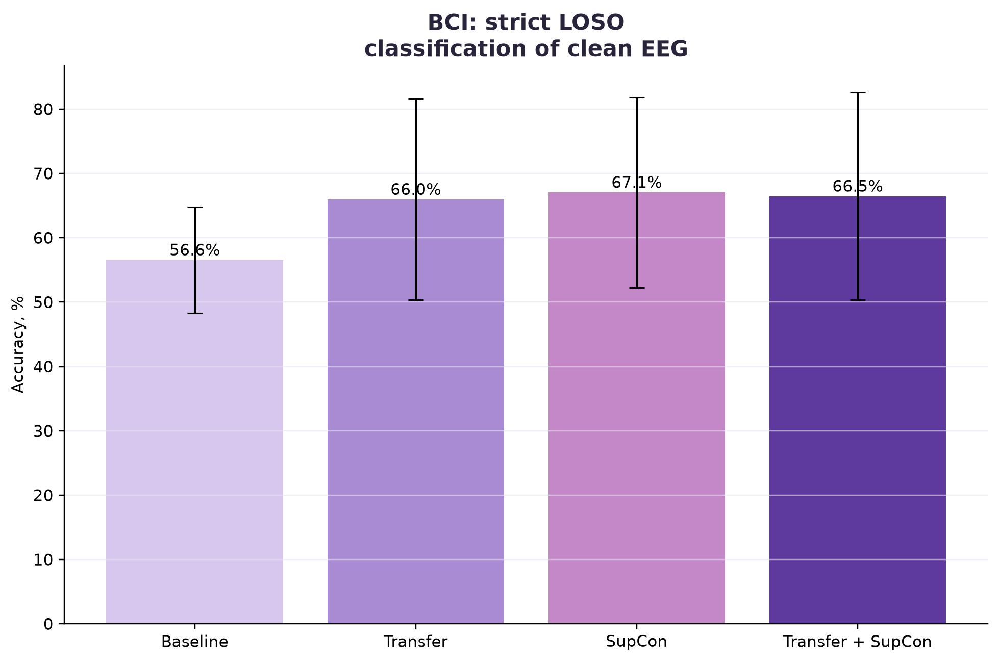


 01_PhysioNet_clean_methods.png


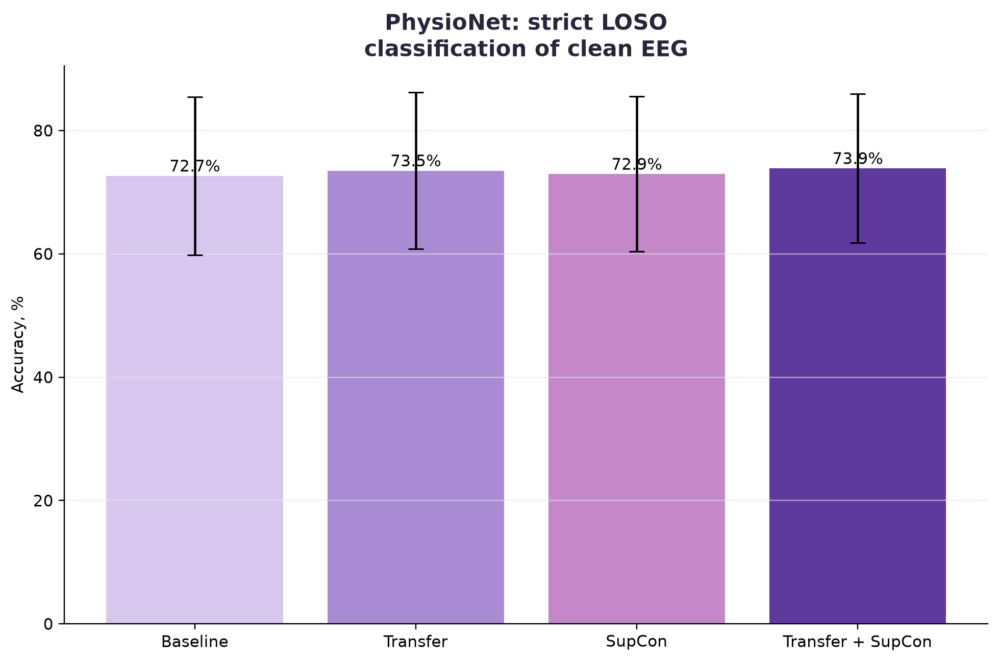


 02_BCI_clean_denoising.png


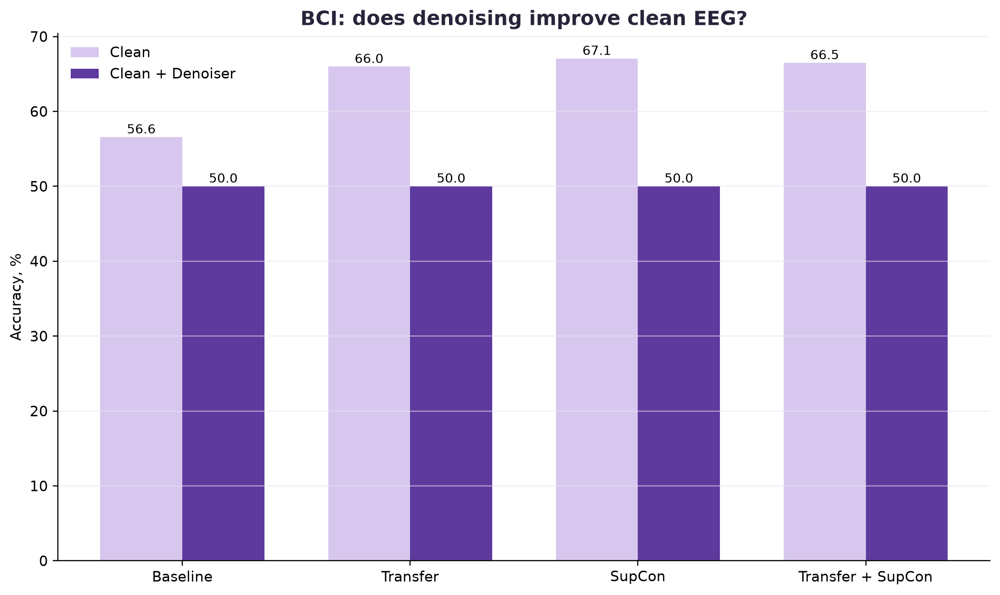


 02_PhysioNet_clean_denoising.png


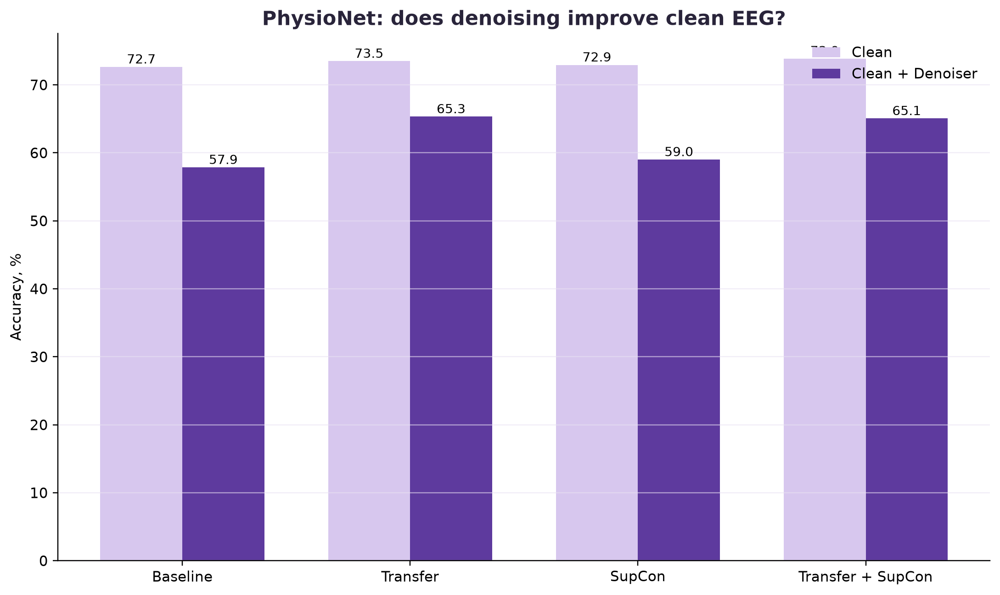


 03_BCI_transfer_supcon_conditions.png


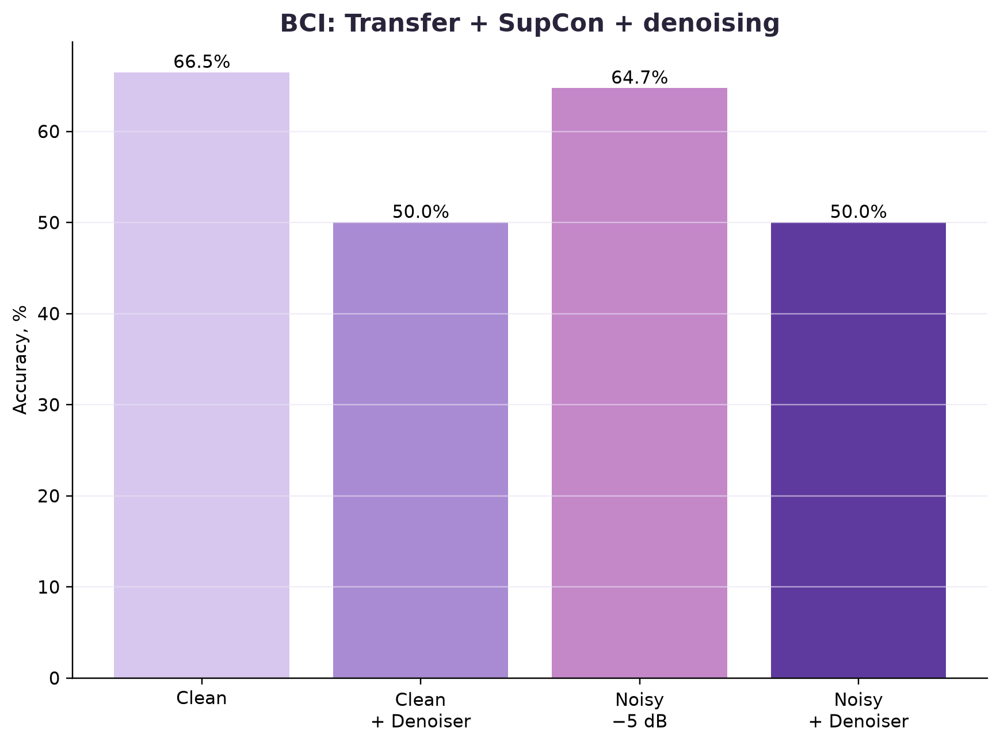


 03_PhysioNet_transfer_supcon_conditions.png


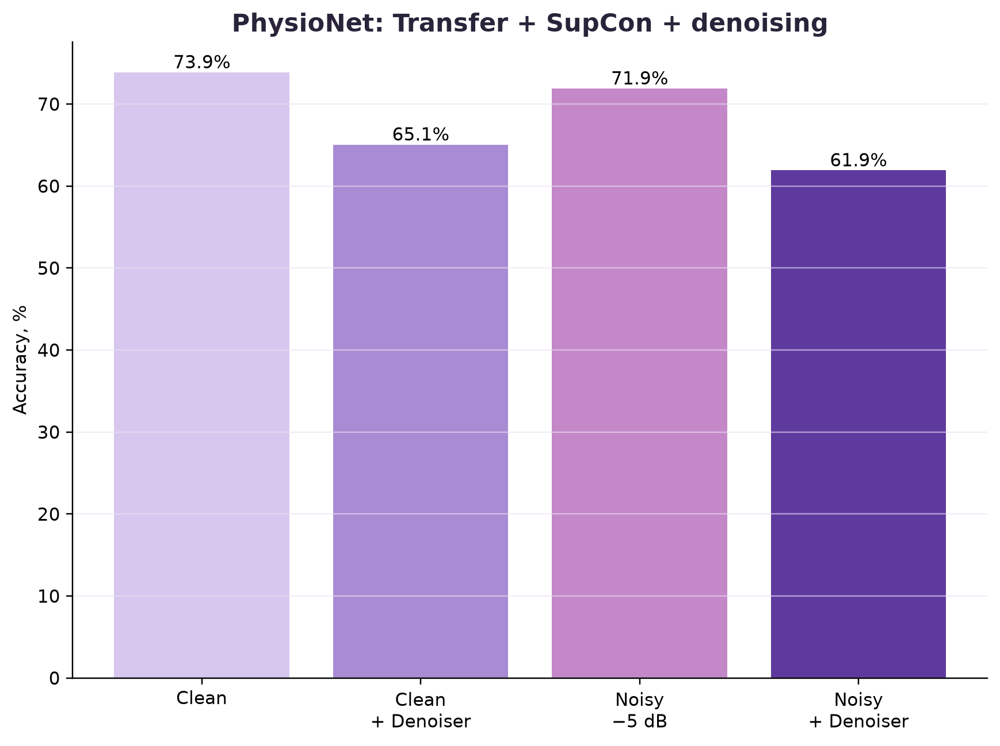


 04_BCI_subject_clean_denoising.png


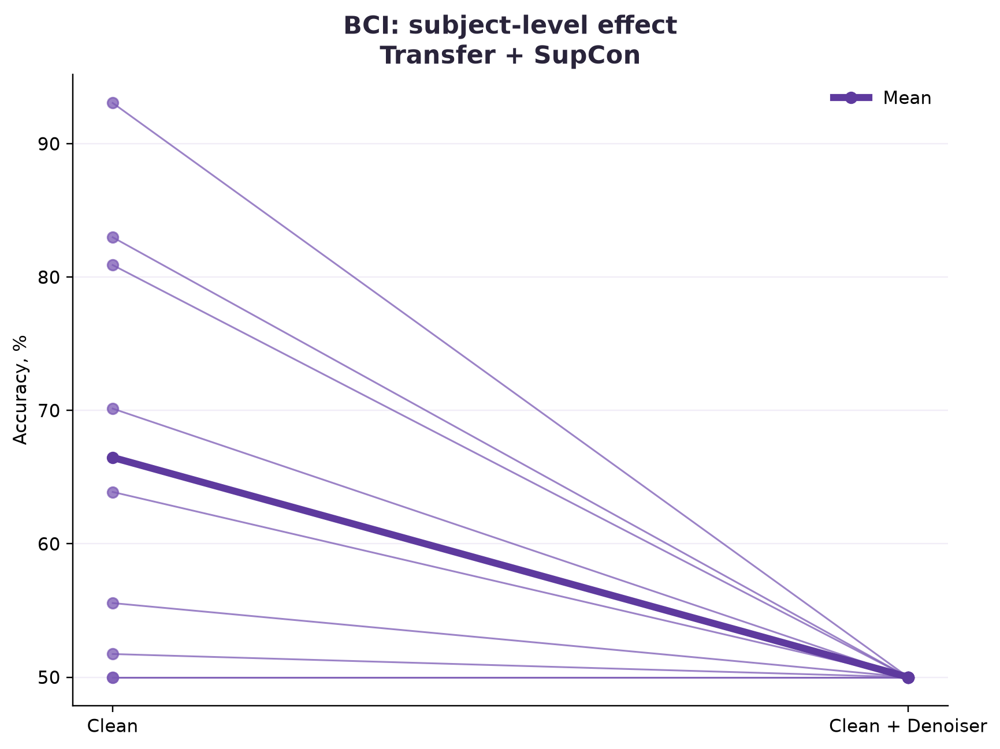


 04_PhysioNet_subject_clean_denoising.png


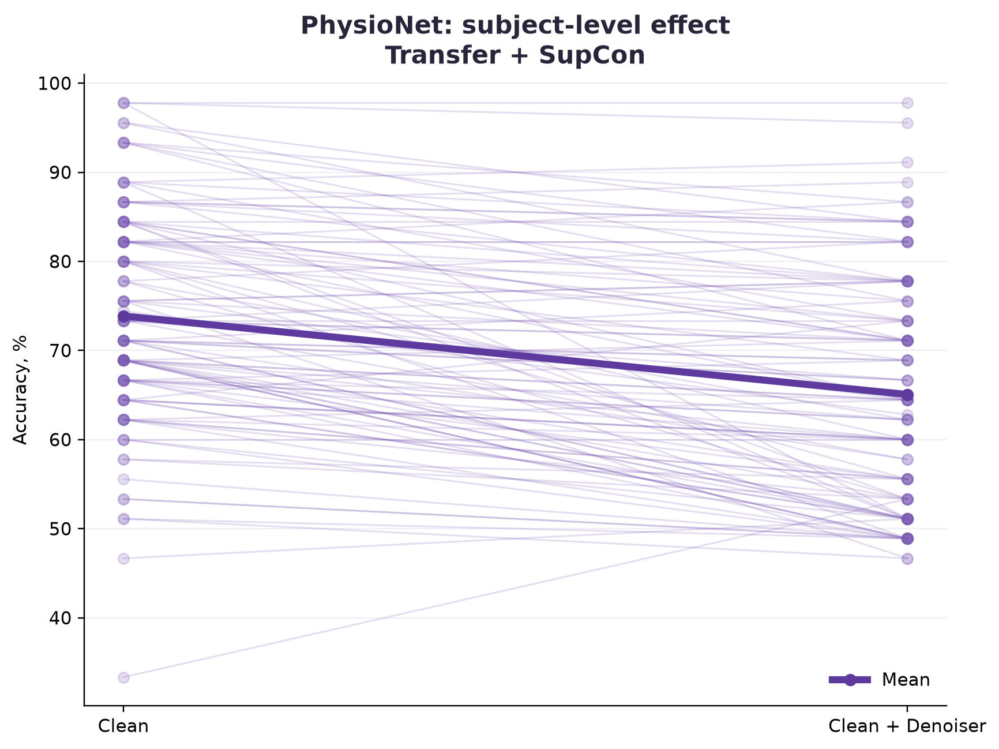


 05_BCI_vs_sota.png


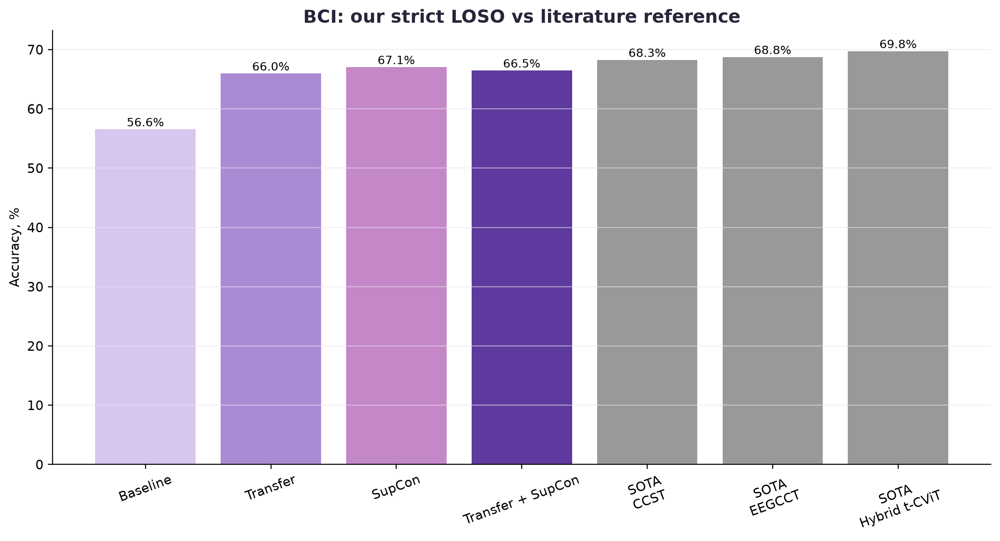


 05_PhysioNet_vs_sota.png


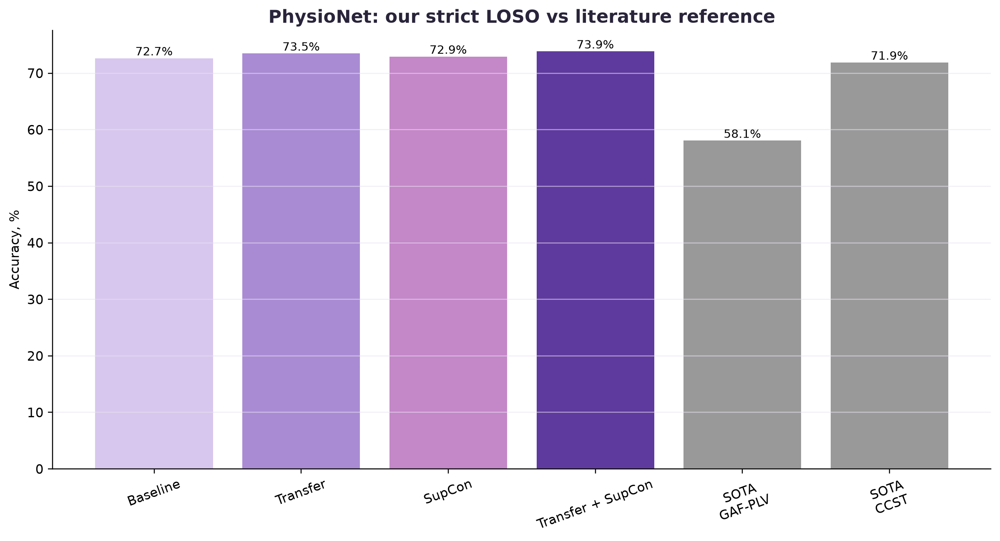


 06_BCI_vs_PhysioNet_clean.png


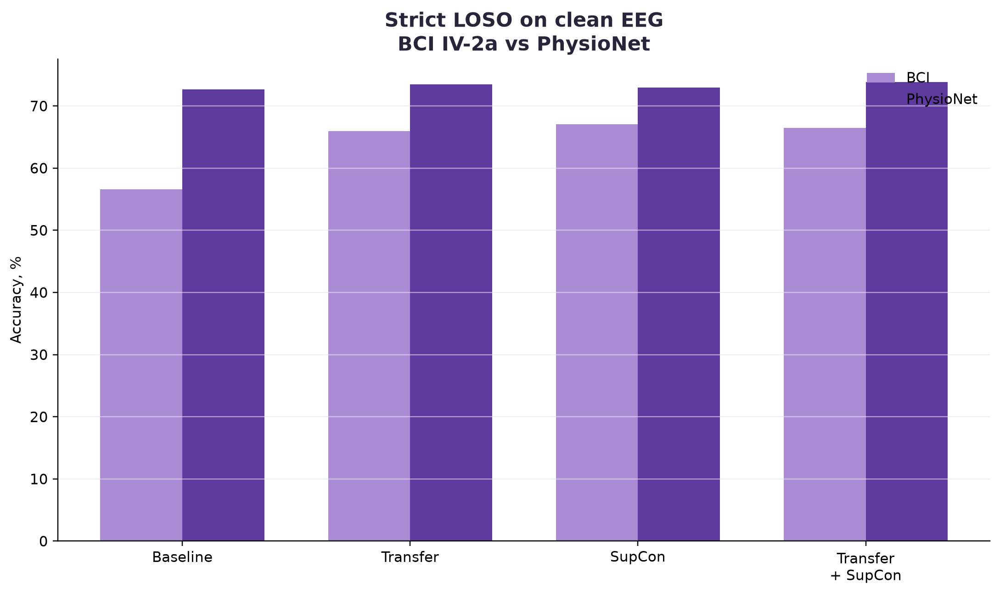

In [87]:
# ============================================================
# SHOW SAVED PLOTS IN NOTEBOOK
# ============================================================

from IPython.display import display, Image

plot_files = sorted(
    PLOT_DIR.glob("*.png")
)

print(
    "Plots found:",
    len(plot_files)
)

for p in plot_files:
    print("\n", p.name)
    display(
        Image(
            filename=str(p)
        )
    )

In [88]:
# ============================================================
# 1. FIND BEST BCI DENOISER CHECKPOINT
# ============================================================

from pathlib import Path

BASE_DIR = Path("/Users/irina/Desktop/master project")

candidates = []

for p in BASE_DIR.rglob("*.pt"):

    s = str(p).lower()

    if (
        "denois" in s
        or "mse" in s
        or "psd" in s
        or "task" in s
    ):
        candidates.append(p)

print("Candidates:", len(candidates))

for p in candidates:
    print(p)

Candidates: 2021
/Users/irina/Desktop/master project/taskaware_multichannel_denoiser.pt
/Users/irina/Desktop/master project/multichannel_bci_denoiser.pt
/Users/irina/Desktop/master project/models_v2/cho2017_task_informed_pretrained.pt
/Users/irina/Desktop/master project/models_v2/cho2017_task_informed_pretrained_full.pt
/Users/irina/Desktop/master project/models_physionet_external/physionet_CNN_MSE.pt
/Users/irina/Desktop/master project/models_physionet_external/physionet_CNN_MSE_PSD.pt
/Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models/MSE_last.pt
/Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models/MSE_PSD_best.pt
/Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models/MSE_COV_best.pt
/Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models/MSE_COV_last.pt
/Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models/MSE

In [89]:
# ============================================================
# 2. CHECK STRICT-LOSO CLEAN CLASSIFIERS
# ============================================================

NIGHT_MODEL_DIR = (
    BASE_DIR
    / "results_v2"
    / "strict_loso_denoising_binary"
    / "models"
)

for dataset in ["BCI", "PhysioNet"]:

    for method in [
        "transfer",
        "transfer_supcon",
    ]:

        files = sorted(
            NIGHT_MODEL_DIR.glob(
                f"{dataset}_S*_{method}_clean.pt"
            )
        )

        print(
            dataset,
            method,
            "checkpoints:",
            len(files),
        )

BCI transfer checkpoints: 9
BCI transfer_supcon checkpoints: 9
PhysioNet transfer checkpoints: 106
PhysioNet transfer_supcon checkpoints: 106


для каждого strict LOSO fold:

train subjects:
    train classifier from Cho on clean EEG
    train MSE+PSD denoiser

val subject:
    early stopping / checkpoint selection

test subject:
    classifier FREEZE

    Clean
    Clean → denoiser
    Noisy -5 dB
    Noisy -5 dB → denoiser

In [91]:
# ============================================================
# FIND STRICT SUBJECT-INDEPENDENT DENOISER CHECKPOINTS
# ============================================================

from pathlib import Path

BASE_DIR = Path("/Users/irina/Desktop/master project")

hits = []

for p in BASE_DIR.rglob("*.pt"):

    s = str(p).lower()

    if (
        "denois" in s
        and (
            "subject_independent" in s
            or "strict" in s
            or "loso" in s
            or "fold" in s
        )
    ):
        hits.append(p)

print("Found:", len(hits))

for p in sorted(hits):
    print(p)

Found: 1891
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_baseline_clean.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_baseline_clean_denoised.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_baseline_noisy.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_baseline_noisy_denoised.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_supcon_clean.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_supcon_clean_denoised.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_supcon_noisy.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models/BCI_SA01_supcon_noisy_denoised.pt
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/mode

In [92]:
# ============================================================
# FIND REAL PER-FOLD DENOISER CHECKPOINTS
# ============================================================

from pathlib import Path

BASE_DIR = Path("/Users/irina/Desktop/master project")

denoiser_hits = []

for p in BASE_DIR.rglob("*.pt"):

    name = p.name.lower()
    path = str(p).lower()

    # исключаем наши classifier checkpoints
    if any(
        x in name
        for x in [
            "baseline",
            "transfer",
            "supcon",
            "classifier",
        ]
    ):
        continue

    # ищем признаки именно denoiser model
    if (
        "denois" in name
        or "denois" in p.parent.name.lower()
        or "mse_psd" in name
        or "mse+psd" in name
        or "task" in name
    ):
        denoiser_hits.append(p)


print("Potential denoisers:", len(denoiser_hits))

for p in sorted(denoiser_hits):
    print(p)

Potential denoisers: 79
/Users/irina/Desktop/master project/models_physionet_external/downstream_guided_tuning/MSE_PSD_fixed_-5.pt
/Users/irina/Desktop/master project/models_physionet_external/downstream_guided_tuning/MSE_PSD_uniform_-5_5.pt
/Users/irina/Desktop/master project/models_physionet_external/downstream_guided_tuning/MSE_PSD_uniform_-7_0.pt
/Users/irina/Desktop/master project/models_physionet_external/full_external_validation/physionet_CNN_MSE_PSD.pt
/Users/irina/Desktop/master project/models_physionet_external/physionet_CNN_MSE_PSD.pt
/Users/irina/Desktop/master project/models_v2/ablation_task_informed/A01_MSE_PSD.pt
/Users/irina/Desktop/master project/models_v2/ablation_task_informed/A02_MSE_PSD.pt
/Users/irina/Desktop/master project/models_v2/ablation_task_informed/A03_MSE_PSD.pt
/Users/irina/Desktop/master project/models_v2/ablation_task_informed/A04_MSE_PSD.pt
/Users/irina/Desktop/master project/models_v2/ablation_task_informed/A05_MSE_PSD.pt
/Users/irina/Desktop/master 

In [93]:
# ============================================================
# SEARCH OLD SUBJECT-INDEPENDENT EXPERIMENT DIRECTORIES
# ============================================================

for p in sorted(BASE_DIR.rglob("*")):

    if not p.is_dir():
        continue

    s = str(p).lower()

    if (
        "subject_independent" in s
        or "subject-independent" in s
        or "loso" in s
    ):
        if (
            "denois" in s
            or "noise" in s
        ):
            print(p)

/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/plots
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/results
/Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/tables
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/denoisers
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/models
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/plots
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/results
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/separate_plots


In [94]:
from pathlib import Path

OLD_DENOISER_DIR = (
    BASE_DIR
    / "results_v2"
    / "subject_independent_transfer_denoising"
    / "denoisers"
)

bci_den_ckpts = sorted(
    OLD_DENOISER_DIR.glob("BCI*_MSE_PSD.pt")
)

phys_den_ckpts = sorted(
    OLD_DENOISER_DIR.glob("PHYS*_MSE_PSD.pt")
)

print("BCI denoisers:", len(bci_den_ckpts))
for p in bci_den_ckpts:
    print(" ", p.name)

print()

print("PhysioNet denoisers:", len(phys_den_ckpts))
for p in phys_den_ckpts:
    print(" ", p.name)

BCI denoisers: 9
  BCI_fold01_MSE_PSD.pt
  BCI_fold02_MSE_PSD.pt
  BCI_fold03_MSE_PSD.pt
  BCI_fold04_MSE_PSD.pt
  BCI_fold05_MSE_PSD.pt
  BCI_fold06_MSE_PSD.pt
  BCI_fold07_MSE_PSD.pt
  BCI_fold08_MSE_PSD.pt
  BCI_fold09_MSE_PSD.pt

PhysioNet denoisers: 5
  PHYS_fold01_MSE_PSD.pt
  PHYS_fold02_MSE_PSD.pt
  PHYS_fold03_MSE_PSD.pt
  PHYS_fold04_MSE_PSD.pt
  PHYS_fold05_MSE_PSD.pt


In [95]:
# ============================================================
# PHYSIONET 106-FOLD STRICT LOSO DENOISER
# MSE + PSD
# frozen clean classifier for checkpoint selection
# resume-safe
# ============================================================

import gc
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# ============================================================
# CONFIG
# ============================================================

DENOISER_DEVICE = DEVICE

DENOISER_EPOCHS = 150
DENOISER_PATIENCE = 20

DENOISER_LR = 1e-3
DENOISER_WEIGHT_DECAY = 1e-4

PSD_WEIGHT = 0.1

TRAIN_SNR_MIN = -5.0
TRAIN_SNR_MAX = 5.0

VAL_SNR_DB = -5.0

DENOISER_BATCH_SIZE = 64


DENOISER_OUT_DIR = (
    BASE_DIR
    / "results_v2"
    / "strict_loso_physionet_denoisers"
)

DENOISER_MODEL_DIR = (
    DENOISER_OUT_DIR
    / "models"
)

DENOISER_HISTORY_DIR = (
    DENOISER_OUT_DIR
    / "histories"
)

DENOISER_RESULT_DIR = (
    DENOISER_OUT_DIR
    / "results"
)

for p in [
    DENOISER_MODEL_DIR,
    DENOISER_HISTORY_DIR,
    DENOISER_RESULT_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# PSD LOSS
# 8–30 Hz
# ============================================================

PHYS_SFREQ = 160.0


def psd_loss(
    pred,
    target,
    sfreq=PHYS_SFREQ,
    fmin=8.0,
    fmax=30.0,
):
    pred_fft = torch.fft.rfft(
        pred,
        dim=-1,
    )

    target_fft = torch.fft.rfft(
        target,
        dim=-1,
    )

    pred_psd = (
        pred_fft.abs() ** 2
    )

    target_psd = (
        target_fft.abs() ** 2
    )

    freqs = torch.fft.rfftfreq(
        pred.shape[-1],
        d=1.0 / sfreq,
    ).to(pred.device)

    mask = (
        (freqs >= fmin)
        &
        (freqs <= fmax)
    )

    pred_band = pred_psd[
        ...,
        mask
    ]

    target_band = target_psd[
        ...,
        mask
    ]

    pred_band = (
        pred_band
        /
        (
            pred_band.mean(
                dim=-1,
                keepdim=True,
            )
            + 1e-8
        )
    )

    target_band = (
        target_band
        /
        (
            target_band.mean(
                dim=-1,
                keepdim=True,
            )
            + 1e-8
        )
    )

    return F.mse_loss(
        pred_band,
        target_band,
    )


def mse_psd_loss(
    pred,
    target,
):
    mse = F.mse_loss(
        pred,
        target,
    )

    return (
        mse
        + PSD_WEIGHT
        * psd_loss(
            pred,
            target,
        )
    )


# ============================================================
# TRAIN DATASET
# deterministic corruption per epoch
# ============================================================

class StrictLosoDenoisingDataset(
    Dataset
):

    def __init__(
        self,
        X_clean,
        eog_dataset,
        emg_dataset,
        seed=42,
        snr_min=-5.0,
        snr_max=5.0,
    ):
        self.X_clean = np.asarray(
            X_clean,
            dtype=np.float32,
        )

        self.eog_dataset = (
            eog_dataset
        )

        self.emg_dataset = (
            emg_dataset
        )

        self.seed = int(seed)

        self.snr_min = float(
            snr_min
        )

        self.snr_max = float(
            snr_max
        )

        self.epoch = 0


    def set_epoch(
        self,
        epoch,
    ):
        self.epoch = int(
            epoch
        )


    def __len__(
        self,
    ):
        return len(
            self.X_clean
        )


    def __getitem__(
        self,
        idx,
    ):
        clean = (
            self.X_clean[
                idx
            ].copy()
        )

        rng = (
            np.random.default_rng(
                self.seed
                + self.epoch
                * 1_000_003
                + int(idx)
            )
        )

        snr_db = rng.uniform(
            self.snr_min,
            self.snr_max,
        )

        artifact = (
            make_mixed_artifact(
                target_length=
                    clean.shape[-1],

                rng=rng,

                eog_dataset=
                    self.eog_dataset,

                emg_dataset=
                    self.emg_dataset,
            )
        )

        noisy, _ = (
            add_artifact_at_snr(
                clean,
                artifact,
                snr_db,
            )
        )

        # старый pipeline:
        # noisy и clean нормируются
        # ОДНИМ scale = std(noisy)

        scale = (
            noisy.std()
            + 1e-8
        )

        noisy_norm = (
            noisy
            / scale
        ).astype(
            np.float32
        )

        clean_norm = (
            clean
            / scale
        ).astype(
            np.float32
        )

        return (
            torch.from_numpy(
                noisy_norm
            ),
            torch.from_numpy(
                clean_norm
            ),
        )


# ============================================================
# FIXED VALIDATION NOISE
# ============================================================

def make_fixed_noisy_set_loso(
    X_clean,
    snr_db,
    seed,
):

    X_clean = np.asarray(
        X_clean,
        dtype=np.float32,
    )

    X_noisy_norm = np.zeros_like(
        X_clean,
        dtype=np.float32,
    )

    X_clean_norm = np.zeros_like(
        X_clean,
        dtype=np.float32,
    )

    scales = np.zeros(
        len(X_clean),
        dtype=np.float32,
    )

    for idx in range(
        len(X_clean)
    ):

        clean = X_clean[
            idx
        ]

        rng = np.random.default_rng(
            seed + idx
        )

        artifact = (
            make_mixed_artifact(
                target_length=
                    clean.shape[-1],

                rng=rng,

                eog_dataset=eog_test,
                emg_dataset=emg_test,
            )
        )

        noisy, _ = (
            add_artifact_at_snr(
                clean,
                artifact,
                snr_db,
            )
        )

        scale = (
            noisy.std()
            + 1e-8
        )

        scales[idx] = scale

        X_noisy_norm[
            idx
        ] = (
            noisy / scale
        )

        X_clean_norm[
            idx
        ] = (
            clean / scale
        )

    return (
        X_noisy_norm,
        X_clean_norm,
        scales,
    )


# ============================================================
# DENOISER INFERENCE
# ============================================================

def run_denoiser_numpy(
    model,
    X,
    batch_size=64,
):

    outputs = []

    model.eval()

    with torch.no_grad():

        for start in range(
            0,
            len(X),
            batch_size,
        ):

            batch = torch.tensor(
                X[
                    start:
                    start + batch_size
                ],
                dtype=torch.float32,
                device=DENOISER_DEVICE,
            )

            out = model(
                batch
            )

            outputs.append(
                out.cpu().numpy()
            )

            del batch
            del out

    return np.concatenate(
        outputs,
        axis=0,
    )


# ============================================================
# FROZEN VALIDATION CLASSIFIER
# ============================================================

def load_phys_classifier_for_fold(
    test_subject,
    method="transfer",
):

    checkpoint_path = (
        NIGHT_MODEL_DIR
        /
        (
            f"PhysioNet_S{test_subject}_"
            f"{method}_clean.pt"
        )
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            checkpoint_path
        )

    model = build_model(
        method=method,
        input_samples=
            X_phys.shape[-1],
    ).to(DEVICE)

    state = torch.load(
        checkpoint_path,
        map_location=DEVICE,
    )

    model.load_state_dict(
        state
    )

    model.eval()

    return model


def evaluate_array_accuracy(
    model,
    X,
    y,
):
    loader = make_loader(
        X,
        y,
        shuffle=False,
    )

    metrics = evaluate_model(
        model,
        loader,
    )

    del loader

    return metrics


# ============================================================
# ONE FOLD TRAINING
# ============================================================

def train_phys_denoiser_fold(
    fold_idx,
    item,
    classifier_method="transfer",
    max_epochs=DENOISER_EPOCHS,
):

    test_subject = (
        item["test_subject"]
    )

    val_subject = (
        item["val_subject"]
    )

    best_path = (
        DENOISER_MODEL_DIR
        /
        (
            f"PHYS_LOSO_"
            f"S{test_subject}_"
            f"MSE_PSD_best.pt"
        )
    )

    last_path = (
        DENOISER_MODEL_DIR
        /
        (
            f"PHYS_LOSO_"
            f"S{test_subject}_"
            f"MSE_PSD_last.pt"
        )
    )

    history_path = (
        DENOISER_HISTORY_DIR
        /
        (
            f"PHYS_LOSO_"
            f"S{test_subject}_history.csv"
        )
    )


    # --------------------------------------------------------
    # resume: finished fold
    # --------------------------------------------------------

    if best_path.exists():

        print(
            "SKIP finished:",
            test_subject
        )

        return {
            "fold":
                fold_idx,

            "test_subject":
                test_subject,

            "val_subject":
                val_subject,

            "status":
                "already_done",

            "checkpoint":
                str(best_path),
        }


    # --------------------------------------------------------
    # materialize ONLY current fold
    # --------------------------------------------------------

    fold = materialize_loso_fold(
        X=X_phys,
        y=y_phys,
        subjects=subjects_phys,
        test_subject=test_subject,
        val_subject=val_subject,
    )

    X_train = fold[
        "X_train"
    ]

    X_val = fold[
        "X_val"
    ]

    y_val = fold[
        "y_val"
    ]


    # --------------------------------------------------------
    # train dataset
    # artifacts TRAIN split
    # --------------------------------------------------------

    train_dataset = (
        StrictLosoDenoisingDataset(
            X_train,

            eog_dataset=
                eog_train,

            emg_dataset=
                emg_train,

            seed=
                SEED
                + fold_idx * 1000,

            snr_min=
                TRAIN_SNR_MIN,

            snr_max=
                TRAIN_SNR_MAX,
        )
    )


    # --------------------------------------------------------
    # fixed validation corruption
    # --------------------------------------------------------

    (
        X_val_noisy_norm,
        X_val_clean_norm,
        val_scales,
    ) = make_fixed_noisy_set_loso(
        X_val,
        snr_db=VAL_SNR_DB,
        seed=
            SEED
            + 100_000
            + fold_idx * 1000,
    )


    # --------------------------------------------------------
    # frozen clean classifier
    # --------------------------------------------------------

    classifier = (
        load_phys_classifier_for_fold(
            test_subject,
            method=
                classifier_method,
        )
    )

    for p in (
        classifier.parameters()
    ):
        p.requires_grad = False


    # --------------------------------------------------------
    # denoiser
    # --------------------------------------------------------

    model = (
        MultichannelResidualDenoiser(
            n_channels=22,
            hidden=64,
        )
        .to(
            DENOISER_DEVICE
        )
    )

    optimizer = (
        torch.optim.AdamW(
            model.parameters(),
            lr=DENOISER_LR,
            weight_decay=
                DENOISER_WEIGHT_DECAY,
        )
    )


    best_val_acc = -np.inf
    best_val_f1 = -np.inf

    best_epoch = 0
    patience_counter = 0

    start_epoch = 1
    history = []


    # --------------------------------------------------------
    # resume partial fold
    # --------------------------------------------------------

    if last_path.exists():

        state = torch.load(
            last_path,
            map_location=
                DENOISER_DEVICE,
        )

        model.load_state_dict(
            state[
                "model_state_dict"
            ]
        )

        optimizer.load_state_dict(
            state[
                "optimizer_state_dict"
            ]
        )

        start_epoch = (
            int(
                state["epoch"]
            )
            + 1
        )

        best_val_acc = float(
            state[
                "best_val_acc"
            ]
        )

        best_val_f1 = float(
            state[
                "best_val_f1"
            ]
        )

        best_epoch = int(
            state[
                "best_epoch"
            ]
        )

        patience_counter = int(
            state[
                "patience_counter"
            ]
        )

        history = state.get(
            "history",
            [],
        )

        print(
            "RESUME fold",
            fold_idx,
            "from epoch",
            start_epoch,
        )


    # ========================================================
    # TRAIN
    # ========================================================

    for epoch in range(
        start_epoch,
        max_epochs + 1,
    ):

        train_dataset.set_epoch(
            epoch
        )

        generator = (
            torch.Generator()
        )

        generator.manual_seed(
            SEED
            + epoch
            + fold_idx * 1000
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=
                DENOISER_BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            generator=generator,
        )

        model.train()

        batch_losses = []

        for noisy, clean in train_loader:

            noisy = noisy.to(
                DENOISER_DEVICE
            )

            clean = clean.to(
                DENOISER_DEVICE
            )

            optimizer.zero_grad()

            pred = model(
                noisy
            )

            loss = mse_psd_loss(
                pred,
                clean,
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )

            optimizer.step()

            batch_losses.append(
                float(
                    loss.item()
                )
            )

            del noisy
            del clean
            del pred
            del loss


        train_loss = float(
            np.mean(
                batch_losses
            )
        )

        del train_loader


        # ----------------------------------------------------
        # VALIDATION DENOISING
        # ----------------------------------------------------

        val_denoised_norm = (
            run_denoiser_numpy(
                model,
                X_val_noisy_norm,
            )
        )


        # classifier expects original signal scale
        # restore each trial to its original scale

        val_denoised = (
            val_denoised_norm
            * val_scales[
                :,
                None,
                None,
            ]
        )


        # ----------------------------------------------------
        # frozen downstream selection
        # ----------------------------------------------------

        val_metrics = (
            evaluate_array_accuracy(
                classifier,
                val_denoised,
                y_val,
            )
        )

        val_acc = float(
            val_metrics[
                "accuracy"
            ]
        )

        val_f1 = float(
            val_metrics[
                "macro_f1"
            ]
        )


        row = {
            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "val_accuracy":
                val_acc,

            "val_macro_f1":
                val_f1,
        }

        history.append(
            row
        )


        print(
            f"fold {fold_idx:03d}"
            f" | test={test_subject}"
            f" | epoch {epoch:03d}"
            f" | train={train_loss:.5f}"
            f" | val_acc={val_acc:.4f}"
            f" | val_f1={val_f1:.4f}"
            f" | best={best_val_acc:.4f}"
        )


        improved = (
            val_acc
            > best_val_acc
            + 1e-12
            or
            (
                abs(
                    val_acc
                    - best_val_acc
                )
                <= 1e-12
                and
                val_f1
                > best_val_f1
            )
        )


        if improved:

            best_val_acc = (
                val_acc
            )

            best_val_f1 = (
                val_f1
            )

            best_epoch = (
                epoch
            )

            patience_counter = 0

            torch.save(
                {
                    "model_state_dict":
                        model.state_dict(),

                    "fold":
                        fold_idx,

                    "test_subject":
                        test_subject,

                    "val_subject":
                        val_subject,

                    "best_epoch":
                        best_epoch,

                    "best_val_acc":
                        best_val_acc,

                    "best_val_f1":
                        best_val_f1,

                    "variant":
                        "MSE_PSD",

                    "protocol":
                        "strict_LOSO",
                },
                best_path,
            )

        else:

            patience_counter += 1


        # ----------------------------------------------------
        # SAVE RESUME STATE EVERY EPOCH
        # ----------------------------------------------------

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "best_val_acc":
                    best_val_acc,

                "best_val_f1":
                    best_val_f1,

                "best_epoch":
                    best_epoch,

                "patience_counter":
                    patience_counter,

                "history":
                    history,

                "test_subject":
                    test_subject,

                "val_subject":
                    val_subject,
            },
            last_path,
        )


        pd.DataFrame(
            history
        ).to_csv(
            history_path,
            index=False,
        )


        del val_denoised_norm
        del val_denoised

        gc.collect()

        if (
            DEVICE.type
            == "mps"
        ):
            torch.mps.empty_cache()


        if (
            patience_counter
            >= DENOISER_PATIENCE
        ):

            print(
                "EARLY STOP:"
                f" best epoch {best_epoch}"
            )

            break


    # ========================================================
    # CLEANUP
    # ========================================================

    result = {
        "fold":
            fold_idx,

        "test_subject":
            test_subject,

        "val_subject":
            val_subject,

        "best_epoch":
            best_epoch,

        "best_val_accuracy":
            best_val_acc,

        "best_val_macro_f1":
            best_val_f1,

        "checkpoint":
            str(best_path),

        "status":
            "trained",
    }


    del classifier
    del model
    del train_dataset

    del fold
    del X_train
    del X_val
    del y_val

    del X_val_noisy_norm
    del X_val_clean_norm
    del val_scales

    gc.collect()

    if (
        DEVICE.type
        == "mps"
    ):
        torch.mps.empty_cache()

    return result

In [97]:
# ============================================================
# LOAD EEGDenoiseNet TRAIN / TEST ARTIFACT SPLITS
# ============================================================

from datasets import load_from_disk

EOG_TRAIN_PATH = (
    EEGDENOISE_DIR
    / "EEGDenoiseNet_EOG"
    / "train"
)

EMG_TRAIN_PATH = (
    EEGDENOISE_DIR
    / "EEGDenoiseNet_EMG"
    / "train"
)

EOG_TEST_PATH = (
    EEGDENOISE_DIR
    / "EEGDenoiseNet_EOG"
    / "test"
)

EMG_TEST_PATH = (
    EEGDENOISE_DIR
    / "EEGDenoiseNet_EMG"
    / "test"
)

print("EOG train:", EOG_TRAIN_PATH.exists())
print("EMG train:", EMG_TRAIN_PATH.exists())
print("EOG test :", EOG_TEST_PATH.exists())
print("EMG test :", EMG_TEST_PATH.exists())

eog_train = load_from_disk(
    str(EOG_TRAIN_PATH)
)

emg_train = load_from_disk(
    str(EMG_TRAIN_PATH)
)

eog_test = load_from_disk(
    str(EOG_TEST_PATH)
)

emg_test = load_from_disk(
    str(EMG_TEST_PATH)
)

print()
print("Loaded:")
print("eog_train:", len(eog_train))
print("emg_train:", len(emg_train))
print("eog_test :", len(eog_test))
print("emg_test :", len(emg_test))

EOG train: True
EMG train: True
EOG test : True
EMG test : True

Loaded:
eog_train: 27180
emg_train: 44930
eog_test : 6820
emg_test : 11050


In [98]:
# ============================================================
# SANITY — ONE FOLD ONLY
# ============================================================

phys_plan = make_loso_plan(
    subjects_phys
)

verify_loso_plan(
    subjects_phys,
    phys_plan,
)

sanity_result = (
    train_phys_denoiser_fold(
        fold_idx=1,
        item=phys_plan[0],
        classifier_method="transfer",
        max_epochs=3,
    )
)

print()
print(sanity_result)

OK — 106 strict LOSO folds, no subject leakage
Transferred tensors: 13
fold 001 | test=1 | epoch 001 | train=0.22890 | val_acc=0.9111 | val_f1=0.9107 | best=-inf
fold 001 | test=1 | epoch 002 | train=0.16434 | val_acc=0.9111 | val_f1=0.9107 | best=0.9111
fold 001 | test=1 | epoch 003 | train=0.15540 | val_acc=0.9111 | val_f1=0.9111 | best=0.9111

{'fold': 1, 'test_subject': np.int64(1), 'val_subject': np.int64(2), 'best_epoch': 3, 'best_val_accuracy': 0.9111111111111111, 'best_val_macro_f1': 0.9110671936758893, 'checkpoint': '/Users/irina/Desktop/master project/results_v2/strict_loso_physionet_denoisers/models/PHYS_LOSO_S1_MSE_PSD_best.pt', 'status': 'trained'}


In [99]:
# ============================================================
# REMOVE SANITY FOLD
# ============================================================

sanity_files = [
    DENOISER_MODEL_DIR
    / "PHYS_LOSO_S1_MSE_PSD_best.pt",

    DENOISER_MODEL_DIR
    / "PHYS_LOSO_S1_MSE_PSD_last.pt",

    DENOISER_HISTORY_DIR
    / "PHYS_LOSO_S1_history.csv",
]

for p in sanity_files:
    if p.exists():
        p.unlink()
        print("Deleted:", p.name)

print("Sanity cleanup complete.")

Deleted: PHYS_LOSO_S1_MSE_PSD_best.pt
Deleted: PHYS_LOSO_S1_MSE_PSD_last.pt
Deleted: PHYS_LOSO_S1_history.csv
Sanity cleanup complete.


In [100]:
# ============================================================
# FULL 106-FOLD STRICT LOSO DENOISER RUN
# ============================================================

phys_denoiser_rows = []

for fold_idx, item in enumerate(
    phys_plan,
    start=1,
):

    print()
    print("#" * 100)
    print(
        f"PHYS DENOISER "
        f"{fold_idx}/106"
        f" | test={item['test_subject']}"
        f" | val={item['val_subject']}"
    )
    print("#" * 100)

    result = train_phys_denoiser_fold(
        fold_idx=fold_idx,
        item=item,
        classifier_method="transfer",
    )

    phys_denoiser_rows.append(
        result
    )

    pd.DataFrame(
        phys_denoiser_rows
    ).to_csv(
        DENOISER_RESULT_DIR
        / "training_progress.csv",
        index=False,
    )

    print(
        "Completed:",
        len(
            list(
                DENOISER_MODEL_DIR.glob(
                    "PHYS_LOSO_*_MSE_PSD_best.pt"
                )
            )
        ),
        "/ 106",
    )


phys_denoiser_summary = pd.DataFrame(
    phys_denoiser_rows
)

phys_denoiser_summary.to_csv(
    DENOISER_RESULT_DIR
    / "training_summary.csv",
    index=False,
)

display(
    phys_denoiser_summary
)

print()
print("=" * 80)
print(
    "FINISHED CHECKPOINTS:",
    len(
        list(
            DENOISER_MODEL_DIR.glob(
                "PHYS_LOSO_*_MSE_PSD_best.pt"
            )
        )
    ),
    "/ 106",
)
print("=" * 80)


####################################################################################################
PHYS DENOISER 1/106 | test=1 | val=2
####################################################################################################
Transferred tensors: 13
fold 001 | test=1 | epoch 001 | train=0.23722 | val_acc=0.9111 | val_f1=0.9111 | best=-inf
fold 001 | test=1 | epoch 002 | train=0.16314 | val_acc=0.9111 | val_f1=0.9111 | best=0.9111
fold 001 | test=1 | epoch 003 | train=0.15469 | val_acc=0.9111 | val_f1=0.9111 | best=0.9111
fold 001 | test=1 | epoch 004 | train=0.15340 | val_acc=0.9111 | val_f1=0.9111 | best=0.9111
fold 001 | test=1 | epoch 005 | train=0.15257 | val_acc=0.9111 | val_f1=0.9111 | best=0.9111
fold 001 | test=1 | epoch 006 | train=0.14853 | val_acc=0.8889 | val_f1=0.8887 | best=0.9111
fold 001 | test=1 | epoch 007 | train=0.14796 | val_acc=0.9111 | val_f1=0.9111 | best=0.9111
fold 001 | test=1 | epoch 008 | train=0.14647 | val_acc=0.9333 | val_f1=0.9332 | best=0

,fold,test_subject,val_subject,best_epoch,best_val_accuracy,best_val_macro_f1,checkpoint,status
0,1,1,2,8,0.933333,0.933201,/Users/irina/Desktop/master project/results_v2...,trained
1,2,2,3,2,0.911111,0.911067,/Users/irina/Desktop/master project/results_v2...,trained
2,3,3,4,1,0.866667,0.865000,/Users/irina/Desktop/master project/results_v2...,trained
3,4,4,5,2,0.711111,0.711111,/Users/irina/Desktop/master project/results_v2...,trained
4,5,5,6,13,0.888889,0.888669,/Users/irina/Desktop/master project/results_v2...,trained
...,...,...,...,...,...,...,...,...
101,102,105,106,1,0.733333,0.733202,/Users/irina/Desktop/master project/results_v2...,trained
102,103,106,107,15,0.711111,0.708810,/Users/irina/Desktop/master project/results_v2...,trained
103,104,107,108,2,0.800000,0.799604,/Users/irina/Desktop/master project/results_v2...,trained
104,105,108,109,1,0.644444,0.644269,/Users/irina/Desktop/master project/results_v2...,trained



FINISHED CHECKPOINTS: 106 / 106


Папка: /Users/irina/Desktop/master project/results_v2/strict_loso_physionet_denoisers
Источник: /Users/irina/Desktop/master project/results_v2/strict_loso_physionet_denoisers/results/training_summary.csv

========== CHECK ==========
Строк результатов: 106
Фолдов: 106 / 106
Чекпоинтов: 106 / 106
Отсутствующие фолды: нет

Статусы:
status
trained    106

========== VALIDATION SUMMARY ==========


,count,mean,std,min,median,max
best_val_accuracy,106.0,0.7676,0.1076,0.4889,0.7778,1.0
best_val_macro_f1,106.0,0.7627,0.1189,0.3284,0.7777,1.0
best_epoch,106.0,5.7170,7.6877,1.0000,3.0000,61.0



========== WORST 10 FOLDS ==========


,fold,test_subject,best_epoch,best_val_accuracy,best_val_macro_f1
36,37,37,1,0.488889,0.328358
65,66,66,1,0.511111,0.338235
23,24,24,3,0.533333,0.518103
37,38,38,2,0.555556,0.555336
77,78,78,5,0.555556,0.527311
83,84,84,3,0.577778,0.563998
85,86,86,21,0.577778,0.570136
14,15,15,7,0.600000,0.598214
74,75,75,1,0.600000,0.599802
24,25,25,6,0.622222,0.621475



========== BEST 10 FOLDS ==========


,fold,test_subject,best_epoch,best_val_accuracy,best_val_macro_f1
30,31,31,3,1.000000,1.000000
16,17,17,1,0.977778,0.977734
20,21,21,1,0.955556,0.955357
100,101,104,5,0.955556,0.955534
0,1,1,8,0.933333,0.933201
55,56,56,1,0.933333,0.933333
84,85,85,5,0.933333,0.933201
87,88,89,23,0.933333,0.932802
96,97,99,13,0.933333,0.933201
1,2,2,2,0.911111,0.911067


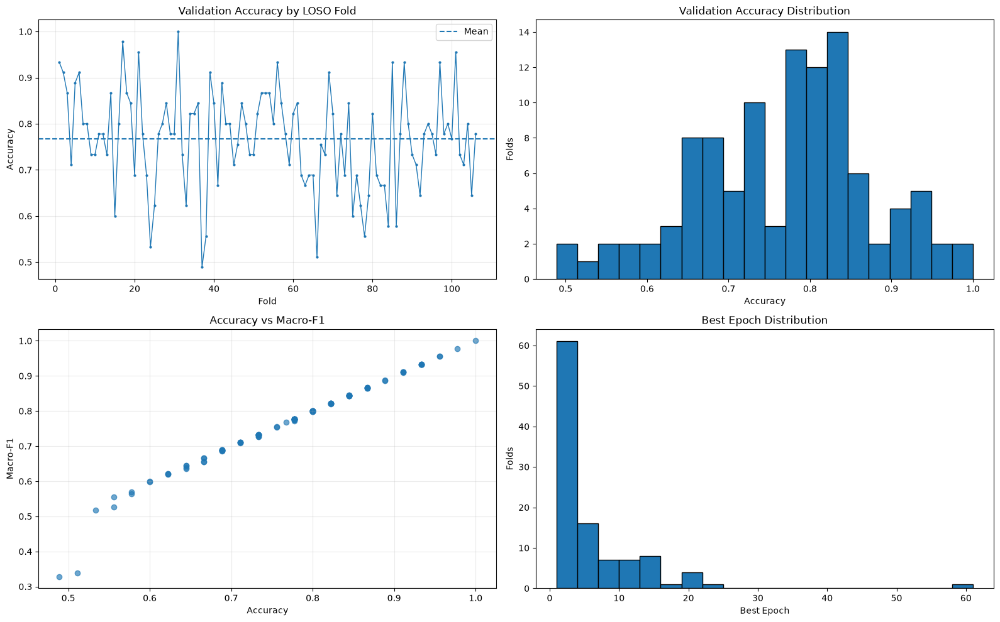


========== COMPLETE ==========
Отчёт сохранён: /Users/irina/Desktop/master project/results_v2/strict_loso_physionet_denoisers/post_analysis
Mean validation accuracy: 0.7676
Mean validation macro-F1: 0.7627

ВАЖНО: это VALIDATION, не итоговые TEST-метрики.


In [101]:

# ============================================================
# PHYSIONET — 106 STRICT-LOSO DENOISERS
# POST-TRAINING AUDIT: TABLES + STATISTICS + PLOTS
# Без переобучения и без изменения checkpoint
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Находим результаты
ROOT = Path.home() / "Desktop" / "master project"
RUN_DIR = ROOT / "results_v2" / "strict_loso_physionet_denoisers"
EXPECTED_FOLDS = 106

print("Папка:", RUN_DIR)

if not RUN_DIR.exists():
    raise FileNotFoundError(
        f"Папка не найдена: {RUN_DIR}\n"
        "Проверь путь к проекту."
    )

# 2. Ищем таблицу обучения
required = {
    "fold", "test_subject", "best_epoch",
    "best_val_accuracy", "best_val_macro_f1"
}

df = None
source = None

# Сначала таблицы, уже находящиеся в памяти ноутбука
for name in [
    "results_df", "summary_df", "fold_results_df",
    "df_results", "df_summary", "results"
]:
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame) and required.issubset(obj.columns):
        if len(obj) >= EXPECTED_FOLDS:
            df = obj.copy()
            source = f"Jupyter variable: {name}"
            break

# Затем файлы CSV
if df is None:
    csv_files = sorted(
        RUN_DIR.rglob("*.csv"),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    for path in csv_files:
        try:
            candidate = pd.read_csv(path)
            if required.issubset(candidate.columns):
                df = candidate.copy()
                source = str(path)
                break
        except Exception:
            continue

if df is None:
    raise RuntimeError(
        "Не найдена итоговая таблица обучения.\n"
        "Чекпоинты остаются на месте. "
        "Нужно восстановить таблицу из журнала обучения."
    )

print("Источник:", source)

# 3. Проверка 106 фолдов
df["fold"] = pd.to_numeric(df["fold"], errors="coerce")
df = df.sort_values("fold").drop_duplicates("fold", keep="last")
df = df.reset_index(drop=True)

for col in ["best_epoch", "best_val_accuracy", "best_val_macro_f1"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

expected = set(range(1, EXPECTED_FOLDS + 1))
actual = set(df["fold"].dropna().astype(int))
missing = sorted(expected - actual)

checkpoints = list(RUN_DIR.rglob(
    "PHYS_LOSO_S*_MSE_PSD_best.pt"
))

ckpt_subjects = set()
for p in checkpoints:
    m = re.search(r"PHYS_LOSO_S(\d+)_MSE_PSD_best\.pt$", p.name)
    if m:
        ckpt_subjects.add(int(m.group(1)))

print("\n========== CHECK ==========")
print("Строк результатов:", len(df))
print("Фолдов:", len(actual), "/", EXPECTED_FOLDS)
print("Чекпоинтов:", len(ckpt_subjects), "/", EXPECTED_FOLDS)
print("Отсутствующие фолды:", missing or "нет")

if "status" in df.columns:
    print("\nСтатусы:")
    print(df["status"].value_counts(dropna=False).to_string())

# 4. Общая статистика
metrics = ["best_val_accuracy", "best_val_macro_f1", "best_epoch"]

stats = df[metrics].agg(
    ["count", "mean", "std", "min", "median", "max"]
).T

print("\n========== VALIDATION SUMMARY ==========")
display(stats.round(4))

print("\n========== WORST 10 FOLDS ==========")
display(
    df.nsmallest(10, "best_val_accuracy")[
        ["fold", "test_subject", "best_epoch",
         "best_val_accuracy", "best_val_macro_f1"]
    ]
)

print("\n========== BEST 10 FOLDS ==========")
display(
    df.nlargest(10, "best_val_accuracy")[
        ["fold", "test_subject", "best_epoch",
         "best_val_accuracy", "best_val_macro_f1"]
    ]
)

# 5. Графики
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(
    df["fold"], df["best_val_accuracy"],
    marker=".", markersize=4, linewidth=1
)
axes[0, 0].axhline(
    df["best_val_accuracy"].mean(),
    linestyle="--", label="Mean"
)
axes[0, 0].set_title("Validation Accuracy by LOSO Fold")
axes[0, 0].set_xlabel("Fold")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.25)

axes[0, 1].hist(
    df["best_val_accuracy"].dropna(),
    bins=20, edgecolor="black"
)
axes[0, 1].set_title("Validation Accuracy Distribution")
axes[0, 1].set_xlabel("Accuracy")
axes[0, 1].set_ylabel("Folds")

axes[1, 0].scatter(
    df["best_val_accuracy"],
    df["best_val_macro_f1"],
    alpha=0.65
)
axes[1, 0].set_title("Accuracy vs Macro-F1")
axes[1, 0].set_xlabel("Accuracy")
axes[1, 0].set_ylabel("Macro-F1")
axes[1, 0].grid(alpha=0.25)

axes[1, 1].hist(
    df["best_epoch"].dropna(),
    bins=20, edgecolor="black"
)
axes[1, 1].set_title("Best Epoch Distribution")
axes[1, 1].set_xlabel("Best Epoch")
axes[1, 1].set_ylabel("Folds")

plt.tight_layout()

# 6. Сохранение отчёта
REPORT_DIR = RUN_DIR / "post_analysis"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(REPORT_DIR / "fold_metrics.csv", index=False)
stats.to_csv(REPORT_DIR / "validation_summary.csv")
fig.savefig(
    REPORT_DIR / "training_diagnostics.png",
    dpi=180, bbox_inches="tight"
)

plt.show()

print("\n========== COMPLETE ==========")
print("Отчёт сохранён:", REPORT_DIR)
print("Mean validation accuracy:",
      round(df["best_val_accuracy"].mean(), 4))
print("Mean validation macro-F1:",
      round(df["best_val_macro_f1"].mean(), 4))
print("\nВАЖНО: это VALIDATION, не итоговые TEST-метрики.")


In [102]:

# Проверяем объекты, доступные в текущем Jupyter
import inspect

keywords = [
    "denois", "classif", "predict", "evaluat",
    "align", "checkpoint", "model", "test",
    "phys", "bci", "cho", "supcon"
]

for name, obj in sorted(globals().copy().items()):
    if name.startswith("_"):
        continue

    if any(k in name.lower() for k in keywords):
        if inspect.isfunction(obj) or inspect.isclass(obj):
            print(f"[FUNCTION/CLASS] {name}")
        elif isinstance(obj, (str, int, float, bool)):
            print(f"[VALUE] {name} = {str(obj)[:150]}")
        else:
            print(f"[OBJECT] {name}: {type(obj).__name__}")


[OBJECT] BCI_DENOISER_PATH: PosixPath
[OBJECT] BCI_LABELS_ROOT: PosixPath
[OBJECT] BCI_ROOT: PosixPath
[OBJECT] CHO_CHECKPOINT: PosixPath
[VALUE] DENOISER_BATCH_SIZE = 64
[OBJECT] DENOISER_DEVICE: device
[VALUE] DENOISER_EPOCHS = 150
[OBJECT] DENOISER_HISTORY_DIR: PosixPath
[VALUE] DENOISER_LR = 0.001
[OBJECT] DENOISER_MODEL_DIR: PosixPath
[OBJECT] DENOISER_OUT_DIR: PosixPath
[VALUE] DENOISER_PATIENCE = 20
[OBJECT] DENOISER_RESULT_DIR: PosixPath
[VALUE] DENOISER_WEIGHT_DECAY = 0.0001
[OBJECT] EEGDENOISE_DIR: PosixPath
[OBJECT] EMG_TEST_PATH: PosixPath
[OBJECT] EOG_TEST_PATH: PosixPath
[OBJECT] EXCLUDED_PHYS_SUBJECTS: set
[OBJECT] MODEL_DIR: PosixPath
[FUNCTION/CLASS] MultichannelResidualDenoiser
[OBJECT] NIGHT_MODEL_DIR: PosixPath
[OBJECT] OLD_DENOISER_DIR: PosixPath
[OBJECT] PHYSIONET_DENOISER_PATH: PosixPath
[OBJECT] PHYS_DENOISER: MultichannelResidualDenoiser
[OBJECT] PHYS_DENOISER_MODEL_DIR: PosixPath
[VALUE] PHYS_SFREQ = 160.0
[FUNCTION/CLASS] PhysionetMI
[FUNCTION/CLASS] StrictLo

In [103]:

from pathlib import Path
import inspect
import torch

print("========== PATHS ==========")

names = [
    "CHO_CHECKPOINT",
    "BCI_DENOISER_PATH",
    "PHYSIONET_DENOISER_PATH",
    "PHYS_DENOISER_MODEL_DIR",
    "DENOISER_MODEL_DIR",
    "BCI_ROOT",
    "BCI_LABELS_ROOT",
    "MODEL_DIR",
    "PHYS_ROOT",
]

for name in names:
    obj = globals().get(name)
    if obj is not None:
        p = Path(obj)
        print(f"{name}: {p} | exists={p.exists()}")

print("\n========== DATA ARRAYS ==========")

for name, obj in sorted(globals().copy().items()):
    if name.startswith("_"):
        continue
    if isinstance(obj, (torch.Tensor,)):
        print(name, tuple(obj.shape))
    elif hasattr(obj, "shape") and any(
        k in name.lower() for k in
        ["x_", "y_", "label", "subject", "noise"]
    ):
        print(name, obj.shape)

print("\n========== FUNCTIONS ==========")

for name, obj in sorted(globals().copy().items()):
    if name.startswith("_"):
        continue
    if inspect.isfunction(obj) and any(
        k in name.lower() for k in
        ["load", "eval", "predict", "align", "preprocess", "noise"]
    ):
        try:
            print(name, inspect.signature(obj))
        except Exception:
            print(name)

print("\n========== DENOISER ARCHITECTURE ==========")
print(inspect.signature(MultichannelResidualDenoiser))

print("\n========== CHECKPOINT FORMAT ==========")

p = Path(CHO_CHECKPOINT)

if p.is_file():
    try:
        ckpt = torch.load(p, map_location="cpu", weights_only=True)
        if isinstance(ckpt, dict):
            print("Cho checkpoint keys:", list(ckpt.keys())[:20])
        else:
            print("Cho checkpoint type:", type(ckpt).__name__)
    except Exception as e:
        print("Cho checkpoint read error:", repr(e))

print("\n========== SAMPLE LOSO CHECKPOINT ==========")

root = Path(PHYS_DENOISER_MODEL_DIR)
files = sorted(root.rglob("*.pt"))

print("Checkpoint files:", len(files))

if files:
    p = files[0]
    print("Sample:", p.name)
    try:
        ckpt = torch.load(p, map_location="cpu", weights_only=True)
        if isinstance(ckpt, dict):
            print("Keys:", list(ckpt.keys())[:20])
        else:
            print("Type:", type(ckpt).__name__)
    except Exception as e:
        print("Read error:", repr(e))


========== PATHS ==========
CHO_CHECKPOINT: /Users/irina/Desktop/master project/models_v2/cho2017_binary_unified_eegnet.pt | exists=True
BCI_DENOISER_PATH: /Users/irina/Desktop/master project/multichannel_bci_denoiser.pt | exists=True
PHYSIONET_DENOISER_PATH: /Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models/FULL_best.pt | exists=True
PHYS_DENOISER_MODEL_DIR: /Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/models | exists=True
DENOISER_MODEL_DIR: /Users/irina/Desktop/master project/results_v2/strict_loso_physionet_denoisers/models | exists=True
BCI_ROOT: /Users/irina/Desktop/master project/BCICIV_2a_gdf | exists=True
BCI_LABELS_ROOT: /Users/irina/Desktop/master project/true_labels | exists=True
MODEL_DIR: /Users/irina/Desktop/master project/results_v2/strict_loso_denoising_binary/models | exists=True

========== DATA ARRAYS ==========
X_bci (2592, 22, 876)
X_bci_small (8, 22, 876)
X_bci_small_denoised (8, 22, 876)

In [108]:
def load_denoiser(
    checkpoint_path,
    device=DEVICE,
):
    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64,
    ).to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,   # важно для наших локальных trusted checkpoints
    )

    if (
        isinstance(state, dict)
        and "model_state_dict" in state
    ):
        state_dict = state["model_state_dict"]
    else:
        state_dict = state

    model.load_state_dict(
        state_dict
    )

    model.eval()

    return model

In [109]:
# ============================================================
# QUICK CHECK BCI A01
# ============================================================

subject = np.unique(subjects_bci)[0]
fold_idx = 1

mask = subjects_bci == subject

X_test = X_bci[mask]
y_test = y_bci[mask]

X_noisy = create_mixed_noisy_dataset(
    X_test,
    snr_db=-5.0,
    seed=SEED + 200_000 + fold_idx * 1000,
)

den_path = (
    OLD_DENOISER_DIR
    / "BCI_fold01_MSE_PSD.pt"
)

denoiser = load_denoiser(
    den_path
)

X_clean_den = denoise_with_scale(
    denoiser,
    X_test,
)

X_noisy_den = denoise_with_scale(
    denoiser,
    X_noisy,
)

model = load_final_classifier(
    dataset="BCI",
    subject=subject,
    method="transfer",
    input_samples=X_test.shape[-1],
)

for name, X_eval in {
    "clean": X_test,
    "clean_denoised": X_clean_den,
    "noisy": X_noisy,
    "noisy_denoised": X_noisy_den,
}.items():

    loader = make_loader(
        X_eval,
        y_test,
        shuffle=False,
    )

    metrics = evaluate_model(
        model,
        loader,
    )

    print(
        name,
        round(
            metrics["accuracy"],
            4,
        )
    )

Transferred tensors: 13
clean 0.7986
clean_denoised 0.7986
noisy 0.6319
noisy_denoised 0.7743


In [110]:
# ============================================================
# FINAL STRICT-LOSO FROZEN EVALUATION
#
# DATASETS:
#   BCI IV-2a
#   PhysioNet
#
# CLASSIFIERS:
#   Transfer
#   Transfer + SupCon
#
# DENOISERS:
#   BCI:
#       9 old strict-LOSO MSE+PSD fold models
#
#   PhysioNet:
#       106 new strict-LOSO MSE+PSD fold models
#
# CONDITIONS:
#   Clean
#   Clean -> Denoiser
#   Noisy -5 dB
#   Noisy -5 dB -> Denoiser
#
# IMPORTANT:
#   classifiers are frozen
#   no training here
# ============================================================

import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch


# ============================================================
# PATHS
# ============================================================

BASE_DIR = Path(
    "/Users/irina/Desktop/master project"
)

NIGHT_MODEL_DIR = (
    BASE_DIR
    / "results_v2"
    / "strict_loso_denoising_binary"
    / "models"
)

OLD_DENOISER_DIR = (
    BASE_DIR
    / "results_v2"
    / "subject_independent_transfer_denoising"
    / "denoisers"
)

DENOISER_MODEL_DIR = (
    BASE_DIR
    / "results_v2"
    / "strict_loso_physionet_denoisers"
    / "models"
)

FINAL_DIR = (
    BASE_DIR
    / "results_v2"
    / "strict_loso_frozen_final"
)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# CONFIG
# ============================================================

FINAL_METHODS = [
    "transfer",
    "transfer_supcon",
]

TEST_SNR_DB = -5.0


# ============================================================
# SAFE DENOISER LOADER
# PyTorch 2.6: weights_only=False
# ============================================================

def load_denoiser(
    checkpoint_path,
    device=DEVICE,
):
    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64,
    ).to(device)

    state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    if (
        isinstance(state, dict)
        and "model_state_dict" in state
    ):
        state_dict = state[
            "model_state_dict"
        ]
    else:
        state_dict = state

    model.load_state_dict(
        state_dict
    )

    model.eval()

    return model


# ============================================================
# DENOISER INFERENCE
# correct scale handling
#
# denoiser was trained on:
#   noisy_norm = noisy / std(noisy)
#   clean_norm = clean / std(noisy)
#
# therefore:
#   normalize -> denoise -> restore scale
# ============================================================

def denoise_with_scale(
    model,
    X,
):
    X = np.asarray(
        X,
        dtype=np.float32,
    )

    scales = (
        X.std(
            axis=(1, 2),
            keepdims=True,
        )
        + 1e-8
    )

    X_norm = (
        X / scales
    ).astype(
        np.float32
    )

    X_den_norm = denoise_array(
        model,
        X_norm,
    )

    X_den = (
        X_den_norm
        * scales
    ).astype(
        np.float32
    )

    return X_den


# ============================================================
# LOAD FROZEN CLEAN CLASSIFIER
# ============================================================

def load_final_classifier(
    dataset,
    subject,
    method,
    input_samples,
):
    checkpoint_path = (
        NIGHT_MODEL_DIR
        /
        (
            f"{dataset}_S{subject}_"
            f"{method}_clean.pt"
        )
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            checkpoint_path
        )

    model = build_model(
        method=method,
        input_samples=input_samples,
    ).to(DEVICE)

    state = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False,
    )

    if (
        isinstance(state, dict)
        and "model_state_dict" in state
    ):
        state = state[
            "model_state_dict"
        ]

    model.load_state_dict(
        state
    )

    model.eval()

    return model


# ============================================================
# EVALUATE ONE ARRAY
# ============================================================

def evaluate_array_final(
    model,
    X,
    y,
):
    loader = make_loader(
        X,
        y,
        shuffle=False,
    )

    metrics = evaluate_model(
        model,
        loader,
    )

    del loader

    return metrics


# ============================================================
# EVALUATE 4 CONDITIONS
# ============================================================

def evaluate_conditions(
    dataset,
    subject,
    fold_idx,
    method,
    model,
    y_test,
    conditions,
):
    rows = []

    for condition, X_eval in (
        conditions.items()
    ):
        metrics = evaluate_array_final(
            model,
            X_eval,
            y_test,
        )

        row = {
            "dataset":
                dataset,

            "test_subject":
                subject,

            "fold":
                fold_idx,

            "method":
                method,

            "condition":
                condition,

            "accuracy":
                metrics[
                    "accuracy"
                ],

            "balanced_accuracy":
                metrics[
                    "balanced_accuracy"
                ],

            "macro_f1":
                metrics[
                    "macro_f1"
                ],

            "kappa":
                metrics[
                    "kappa"
                ],

            "n_test":
                len(y_test),
        }

        rows.append(
            row
        )

        print(
            f"{method:18s}"
            f" | {condition:18s}"
            f" | acc={metrics['accuracy']:.4f}"
        )

    return rows


# ============================================================
# RESUME SUPPORT
# ============================================================

PROGRESS_PATH = (
    FINAL_DIR
    / "strict_loso_frozen_progress.csv"
)


if PROGRESS_PATH.exists():
    final_frozen_df = pd.read_csv(
        PROGRESS_PATH
    )

    print(
        "Resume rows:",
        len(
            final_frozen_df
        )
    )

    all_rows = (
        final_frozen_df
        .to_dict(
            "records"
        )
    )

else:
    final_frozen_df = pd.DataFrame()
    all_rows = []


def already_done(
    dataset,
    subject,
    method,
):
    if final_frozen_df.empty:
        return False

    part = final_frozen_df[
        (
            final_frozen_df[
                "dataset"
            ]
            == dataset
        )
        &
        (
            final_frozen_df[
                "test_subject"
            ].astype(str)
            == str(subject)
        )
        &
        (
            final_frozen_df[
                "method"
            ]
            == method
        )
    ]

    return (
        part[
            "condition"
        ].nunique()
        == 4
    )


# ============================================================
# BCI
# ============================================================

print()
print("#" * 100)
print("BCI STRICT LOSO FROZEN EVALUATION")
print("#" * 100)

bci_subject_list = list(
    np.unique(
        subjects_bci
    )
)

assert len(
    bci_subject_list
) == 9


for fold_idx, subject in enumerate(
    bci_subject_list,
    start=1,
):
    print()
    print("#" * 90)
    print(
        f"BCI {fold_idx}/9"
        f" | TEST={subject}"
    )
    print("#" * 90)

    mask = (
        subjects_bci
        == subject
    )

    X_test = (
        X_bci[
            mask
        ]
        .astype(
            np.float32
        )
    )

    y_test = y_bci[
        mask
    ]


    # --------------------------------------------------------
    # FIXED NOISY TEST
    # --------------------------------------------------------

    X_noisy = (
        create_mixed_noisy_dataset(
            X_test,
            snr_db=TEST_SNR_DB,
            seed=(
                SEED
                + 200_000
                + fold_idx * 1000
            ),
        )
    )


    # --------------------------------------------------------
    # LOAD FOLD-SPECIFIC BCI DENOISER
    # --------------------------------------------------------

    den_path = (
        OLD_DENOISER_DIR
        /
        (
            f"BCI_fold"
            f"{fold_idx:02d}"
            f"_MSE_PSD.pt"
        )
    )

    if not den_path.exists():
        raise FileNotFoundError(
            den_path
        )

    denoiser = load_denoiser(
        den_path
    )


    # --------------------------------------------------------
    # IMPORTANT:
    # correct normalization / scale restoration
    # --------------------------------------------------------

    X_clean_den = (
        denoise_with_scale(
            denoiser,
            X_test,
        )
    )

    X_noisy_den = (
        denoise_with_scale(
            denoiser,
            X_noisy,
        )
    )


    conditions = {
        "clean":
            X_test,

        "clean_denoised":
            X_clean_den,

        "noisy":
            X_noisy,

        "noisy_denoised":
            X_noisy_den,
    }


    # --------------------------------------------------------
    # FROZEN CLASSIFIERS
    # --------------------------------------------------------

    for method in FINAL_METHODS:

        if already_done(
            "BCI",
            subject,
            method,
        ):
            print(
                "SKIP",
                method,
                "- already done"
            )
            continue

        model = load_final_classifier(
            dataset="BCI",
            subject=subject,
            method=method,
            input_samples=
                X_test.shape[-1],
        )

        new_rows = (
            evaluate_conditions(
                dataset="BCI",
                subject=subject,
                fold_idx=fold_idx,
                method=method,
                model=model,
                y_test=y_test,
                conditions=conditions,
            )
        )

        all_rows.extend(
            new_rows
        )

        final_frozen_df = pd.DataFrame(
            all_rows
        )

        final_frozen_df.to_csv(
            PROGRESS_PATH,
            index=False,
        )

        del model

        gc.collect()

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


    del denoiser
    del X_test
    del X_noisy
    del X_clean_den
    del X_noisy_den

    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


# ============================================================
# PHYSIONET
# ============================================================

print()
print("#" * 100)
print("PHYSIONET STRICT LOSO FROZEN EVALUATION")
print("#" * 100)

phys_subject_list = list(
    np.unique(
        subjects_phys
    )
)

assert len(
    phys_subject_list
) == 106


for fold_idx, subject in enumerate(
    phys_subject_list,
    start=1,
):
    print()
    print("#" * 90)
    print(
        f"PhysioNet "
        f"{fold_idx}/106"
        f" | TEST={subject}"
    )
    print("#" * 90)

    mask = (
        subjects_phys
        == subject
    )

    X_test = (
        X_phys[
            mask
        ]
        .astype(
            np.float32
        )
    )

    y_test = y_phys[
        mask
    ]


    # --------------------------------------------------------
    # FIXED NOISY TEST
    # --------------------------------------------------------

    X_noisy = (
        create_mixed_noisy_dataset(
            X_test,
            snr_db=TEST_SNR_DB,
            seed=(
                SEED
                + 200_000
                + fold_idx * 1000
            ),
        )
    )


    # --------------------------------------------------------
    # LOAD EXACT STRICT-LOSO DENOISER
    # --------------------------------------------------------

    den_path = (
        DENOISER_MODEL_DIR
        /
        (
            f"PHYS_LOSO_"
            f"S{subject}_"
            f"MSE_PSD_best.pt"
        )
    )

    if not den_path.exists():
        raise FileNotFoundError(
            den_path
        )

    denoiser = load_denoiser(
        den_path
    )


    # --------------------------------------------------------
    # correct scale pipeline
    # --------------------------------------------------------

    X_clean_den = (
        denoise_with_scale(
            denoiser,
            X_test,
        )
    )

    X_noisy_den = (
        denoise_with_scale(
            denoiser,
            X_noisy,
        )
    )


    conditions = {
        "clean":
            X_test,

        "clean_denoised":
            X_clean_den,

        "noisy":
            X_noisy,

        "noisy_denoised":
            X_noisy_den,
    }


    # --------------------------------------------------------
    # FROZEN CLASSIFIERS
    # --------------------------------------------------------

    for method in FINAL_METHODS:

        if already_done(
            "PhysioNet",
            subject,
            method,
        ):
            print(
                "SKIP",
                method,
                "- already done"
            )
            continue

        model = load_final_classifier(
            dataset="PhysioNet",
            subject=subject,
            method=method,
            input_samples=
                X_test.shape[-1],
        )

        new_rows = (
            evaluate_conditions(
                dataset="PhysioNet",
                subject=subject,
                fold_idx=fold_idx,
                method=method,
                model=model,
                y_test=y_test,
                conditions=conditions,
            )
        )

        all_rows.extend(
            new_rows
        )

        final_frozen_df = pd.DataFrame(
            all_rows
        )

        final_frozen_df.to_csv(
            PROGRESS_PATH,
            index=False,
        )

        del model

        gc.collect()

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


    del denoiser
    del X_test
    del X_noisy
    del X_clean_den
    del X_noisy_den

    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


# ============================================================
# CLEAN DUPLICATES
# ============================================================

final_frozen_df = (
    pd.DataFrame(
        all_rows
    )
    .drop_duplicates(
        subset=[
            "dataset",
            "test_subject",
            "method",
            "condition",
        ],
        keep="last",
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# SAVE SUBJECT-LEVEL RESULTS
# ============================================================

final_subject_path = (
    FINAL_DIR
    / "strict_loso_frozen_subject_results.csv"
)

final_frozen_df.to_csv(
    final_subject_path,
    index=False,
)


# ============================================================
# SUMMARY
# ============================================================

final_summary = (
    final_frozen_df
    .groupby(
        [
            "dataset",
            "method",
            "condition",
        ],
        as_index=False,
    )
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),

        std_accuracy=(
            "accuracy",
            "std",
        ),

        median_accuracy=(
            "accuracy",
            "median",
        ),

        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean",
        ),

        mean_macro_f1=(
            "macro_f1",
            "mean",
        ),

        mean_kappa=(
            "kappa",
            "mean",
        ),

        n_subjects=(
            "test_subject",
            "nunique",
        ),
    )
)


final_summary[
    "mean_accuracy_pct"
] = (
    final_summary[
        "mean_accuracy"
    ]
    * 100
)

final_summary[
    "std_accuracy_pct"
] = (
    final_summary[
        "std_accuracy"
    ]
    * 100
)


final_summary_path = (
    FINAL_DIR
    / "strict_loso_frozen_summary.csv"
)

final_summary.to_csv(
    final_summary_path,
    index=False,
)


# ============================================================
# DIRECT DENOISING GAINS
# ============================================================

gain_rows = []

for dataset in [
    "BCI",
    "PhysioNet",
]:

    for method in FINAL_METHODS:

        part = (
            final_frozen_df[
                (
                    final_frozen_df[
                        "dataset"
                    ]
                    == dataset
                )
                &
                (
                    final_frozen_df[
                        "method"
                    ]
                    == method
                )
            ]
            .pivot(
                index="test_subject",
                columns="condition",
                values="accuracy",
            )
        )

        if not all(
            c in part.columns
            for c in [
                "clean",
                "clean_denoised",
                "noisy",
                "noisy_denoised",
            ]
        ):
            continue

        clean_gain = (
            part[
                "clean_denoised"
            ]
            -
            part[
                "clean"
            ]
        )

        noisy_gain = (
            part[
                "noisy_denoised"
            ]
            -
            part[
                "noisy"
            ]
        )

        gain_rows.append({
            "dataset":
                dataset,

            "method":
                method,

            "clean_gain_mean":
                clean_gain.mean(),

            "clean_gain_pp":
                clean_gain.mean()
                * 100,

            "clean_improved_subjects":
                int(
                    (
                        clean_gain > 0
                    ).sum()
                ),

            "clean_equal_subjects":
                int(
                    (
                        clean_gain == 0
                    ).sum()
                ),

            "clean_worse_subjects":
                int(
                    (
                        clean_gain < 0
                    ).sum()
                ),

            "noisy_gain_mean":
                noisy_gain.mean(),

            "noisy_gain_pp":
                noisy_gain.mean()
                * 100,

            "noisy_improved_subjects":
                int(
                    (
                        noisy_gain > 0
                    ).sum()
                ),

            "noisy_equal_subjects":
                int(
                    (
                        noisy_gain == 0
                    ).sum()
                ),

            "noisy_worse_subjects":
                int(
                    (
                        noisy_gain < 0
                    ).sum()
                ),

            "n_subjects":
                len(part),
        })


gain_df = pd.DataFrame(
    gain_rows
)

gain_df.to_csv(
    FINAL_DIR
    / "strict_loso_frozen_denoising_gains.csv",
    index=False,
)


# ============================================================
# COMPLETENESS CHECK
# ============================================================

expected_rows = (
    9 * 2 * 4
    +
    106 * 2 * 4
)

actual_rows = len(
    final_frozen_df
)


print()
print("=" * 100)
print("FINAL STRICT-LOSO FROZEN EVALUATION FINISHED")
print("=" * 100)

print(
    "Rows:",
    actual_rows,
    "/",
    expected_rows,
)

print(
    "Subject results:",
    final_subject_path
)

print(
    "Summary:",
    final_summary_path
)


print()
print("=" * 100)
print("FINAL SUMMARY")
print("=" * 100)

display(
    final_summary.round(4)
)


print()
print("=" * 100)
print("DENOISING GAINS")
print("=" * 100)

display(
    gain_df[
        [
            "dataset",
            "method",
            "clean_gain_pp",
            "clean_improved_subjects",
            "clean_equal_subjects",
            "clean_worse_subjects",
            "noisy_gain_pp",
            "noisy_improved_subjects",
            "noisy_equal_subjects",
            "noisy_worse_subjects",
            "n_subjects",
        ]
    ].round(3)
)


####################################################################################################
BCI STRICT LOSO FROZEN EVALUATION
####################################################################################################

##########################################################################################
BCI 1/9 | TEST=A01
##########################################################################################
Transferred tensors: 13
transfer           | clean              | acc=0.7986
transfer           | clean_denoised     | acc=0.7986
transfer           | noisy              | acc=0.6319
transfer           | noisy_denoised     | acc=0.7743
Transferred tensors: 13
transfer_supcon    | clean              | acc=0.8090
transfer_supcon    | clean_denoised     | acc=0.8090
transfer_supcon    | noisy              | acc=0.5625
transfer_supcon    | noisy_denoised     | acc=0.8056

########################################################################################

,dataset,method,condition,mean_accuracy,std_accuracy,median_accuracy,mean_balanced_accuracy,mean_macro_f1,mean_kappa,n_subjects,mean_accuracy_pct,std_accuracy_pct
0,BCI,transfer,clean,0.6597,0.1563,0.6597,0.6597,0.5989,0.3194,9,65.9722,15.6250
1,BCI,transfer,clean_denoised,0.6578,0.1545,0.6667,0.6578,0.5969,0.3156,9,65.7793,15.4476
2,BCI,transfer,noisy,0.5783,0.0811,0.5521,0.5783,0.4820,0.1566,9,57.8318,8.1062
3,BCI,transfer,noisy_denoised,0.6478,0.1335,0.6736,0.6478,0.5862,0.2955,9,64.7762,13.3513
4,BCI,transfer_supcon,clean,0.6647,0.1615,0.6389,0.6647,0.6102,0.3295,9,66.4738,16.1506
5,BCI,transfer_supcon,clean_denoised,0.6601,0.1600,0.6354,0.6601,0.6024,0.3202,9,66.0108,16.0009
6,BCI,transfer_supcon,noisy,0.5899,0.1074,0.5625,0.5899,0.4950,0.1798,9,58.9892,10.7365
7,BCI,transfer_supcon,noisy_denoised,0.6485,0.1464,0.6562,0.6485,0.5867,0.2971,9,64.8534,14.6378
8,PhysioNet,transfer,clean,0.7349,0.1272,0.7333,0.7355,0.7260,0.4703,106,73.4913,12.7229
9,PhysioNet,transfer,clean_denoised,0.7362,0.1253,0.7333,0.7367,0.7276,0.4728,106,73.6181,12.5332



DENOISING GAINS


,dataset,method,clean_gain_pp,clean_improved_subjects,clean_equal_subjects,clean_worse_subjects,noisy_gain_pp,noisy_improved_subjects,noisy_equal_subjects,noisy_worse_subjects,n_subjects
0,BCI,transfer,-0.193,1,4,4,6.944,6,3,0,9
1,BCI,transfer_supcon,-0.463,0,3,6,5.864,4,3,2,9
2,PhysioNet,transfer,0.127,27,57,22,0.526,49,25,32,106
3,PhysioNet,transfer_supcon,0.126,21,68,17,0.942,47,29,30,106


Rows: 920
Datasets: <ArrowStringArray>
['BCI', 'PhysioNet']
Length: 2, dtype: str
Methods: <ArrowStringArray>
['transfer', 'transfer_supcon']
Length: 2, dtype: str
Conditions: <ArrowStringArray>
['clean', 'clean_denoised', 'noisy', 'noisy_denoised']
Length: 4, dtype: str

COMPLETENESS
BCI 72 / 72
PhysioNet 848 / 848

FINAL SUMMARY


,dataset,method,condition,mean_accuracy_pct,std_accuracy_pct,mean_macro_f1_pct,mean_kappa,n_subjects
0,BCI,transfer,clean,65.972,15.625,59.888,0.319,9
1,BCI,transfer,clean_denoised,65.779,15.448,59.693,0.316,9
2,BCI,transfer,noisy,57.832,8.106,48.202,0.157,9
3,BCI,transfer,noisy_denoised,64.776,13.351,58.617,0.296,9
4,BCI,transfer_supcon,clean,66.474,16.151,61.016,0.329,9
5,BCI,transfer_supcon,clean_denoised,66.011,16.001,60.240,0.320,9
6,BCI,transfer_supcon,noisy,58.989,10.736,49.497,0.180,9
7,BCI,transfer_supcon,noisy_denoised,64.853,14.638,58.670,0.297,9
8,PhysioNet,transfer,clean,73.491,12.723,72.604,0.470,106
9,PhysioNet,transfer,clean_denoised,73.618,12.533,72.759,0.473,106



MAIN ACCURACY TABLE, %


,dataset,method,Clean,Clean + Denoiser,Noisy −5 dB,Noisy + Denoiser
0,BCI,transfer,65.97,65.78,57.83,64.78
1,BCI,transfer_supcon,66.47,66.01,58.99,64.85
2,PhysioNet,transfer,73.49,73.62,71.79,72.32
3,PhysioNet,transfer_supcon,73.87,73.99,71.54,72.48



DENOISING STATISTICS


,dataset,method,comparison,n,mean_delta_pp,ci95_low_pp,ci95_high_pp,improved,equal,worse,wilcoxon_p,holm_p,significant_005
0,BCI,transfer,Clean + Denoiser vs Clean,9,-0.19290,-0.46296,0.11574,1,4,4,0.18675,0.18675,False
1,BCI,transfer,Noisy + Denoiser vs Noisy,9,6.94444,2.00521,13.38735,6,3,0,0.01783,0.03566,True
2,BCI,transfer_supcon,Clean + Denoiser vs Clean,9,-0.46296,-0.84877,-0.19290,0,3,6,0.01741,0.03483,True
3,BCI,transfer_supcon,Noisy + Denoiser vs Noisy,9,5.86420,0.11574,13.58025,4,3,2,0.20208,0.20208,False
4,PhysioNet,transfer,Clean + Denoiser vs Clean,106,0.12676,-0.23061,0.48413,27,57,22,0.43261,0.86521,False
5,PhysioNet,transfer,Noisy + Denoiser vs Noisy,106,0.52606,-0.29155,1.34367,49,25,32,0.09908,0.09908,False
6,PhysioNet,transfer_supcon,Clean + Denoiser vs Clean,106,0.12579,-0.20964,0.46122,21,68,17,0.47146,0.86521,False
7,PhysioNet,transfer_supcon,Noisy + Denoiser vs Noisy,106,0.94242,0.27254,1.61426,47,29,30,0.01360,0.02721,True



MAIN ROBUSTNESS RESULT


,dataset,method,mean_before,mean_after,mean_delta_pp,ci95_low_pp,ci95_high_pp,improved,equal,worse,holm_p
1,BCI,transfer,0.57832,0.64776,6.94444,2.00521,13.38735,6,3,0,0.03566
3,BCI,transfer_supcon,0.58989,0.64853,5.86420,0.11574,13.58025,4,3,2,0.20208
5,PhysioNet,transfer,0.71790,0.72316,0.52606,-0.29155,1.34367,49,25,32,0.09908
7,PhysioNet,transfer_supcon,0.71539,0.72481,0.94242,0.27254,1.61426,47,29,30,0.02721



TRANSFER + SUPCON VS TRANSFER


,dataset,condition,mean_delta_pp,ci95_low_pp,ci95_high_pp,wilcoxon_p,holm_p
0,BCI,clean,0.50154,-1.00309,1.89043,0.40278,1.0
1,BCI,clean_denoised,0.23148,-1.11883,1.38889,0.51018,1.0
2,BCI,noisy,1.15741,-1.69753,3.93519,0.47329,1.0
3,BCI,noisy_denoised,0.07716,-1.92901,2.04475,0.71968,1.0
4,PhysioNet,clean,0.37638,-0.56701,1.29979,0.76949,1.0
5,PhysioNet,clean_denoised,0.37541,-0.55092,1.29784,0.54692,1.0
6,PhysioNet,noisy,-0.25157,-1.23690,0.73375,0.40992,1.0
7,PhysioNet,noisy_denoised,0.16479,-0.77568,1.08722,0.99746,1.0


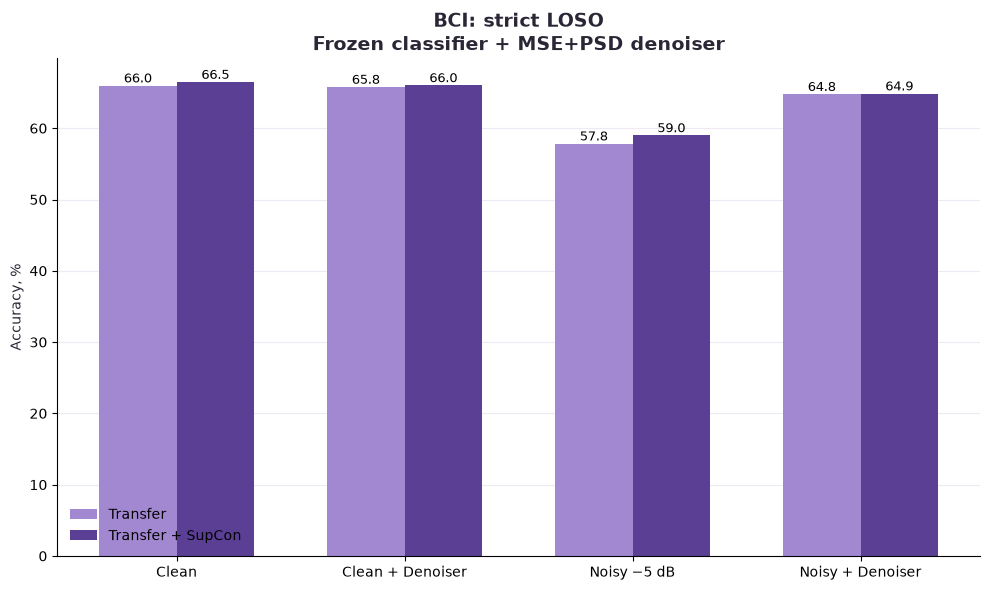

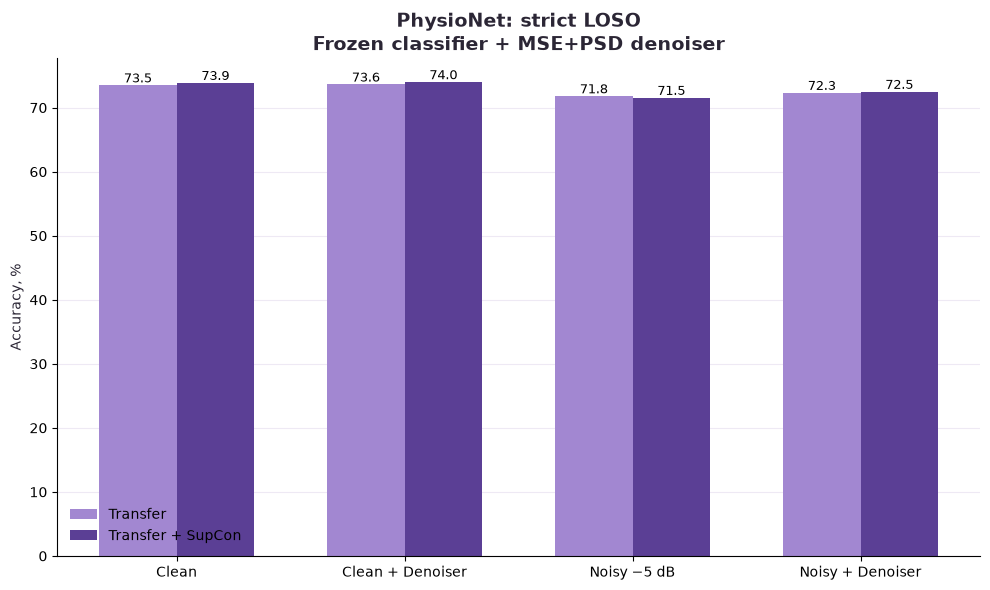

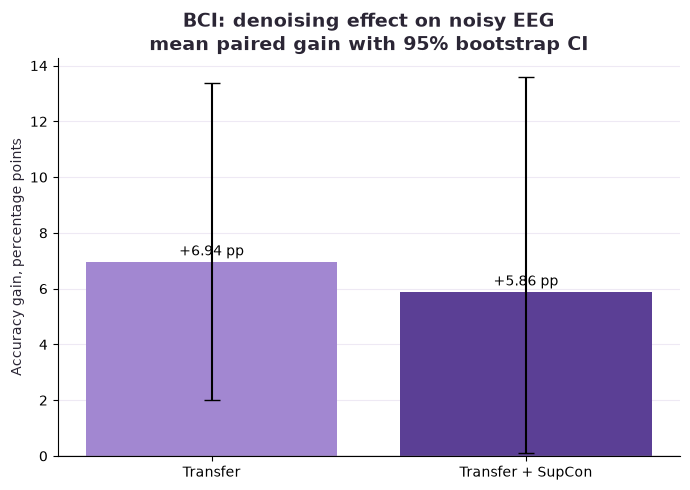

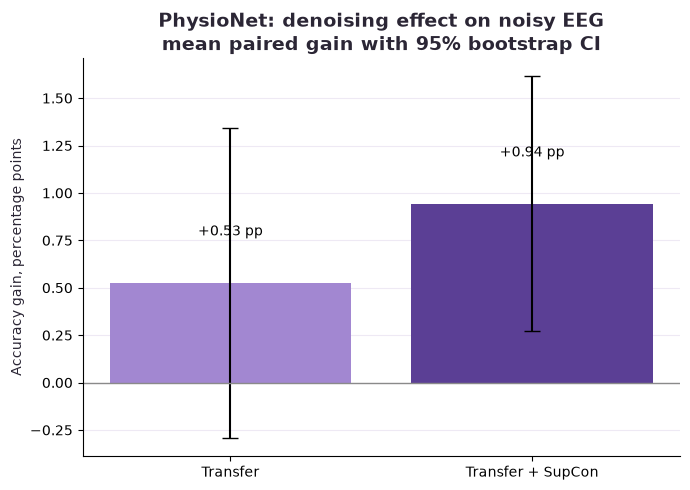

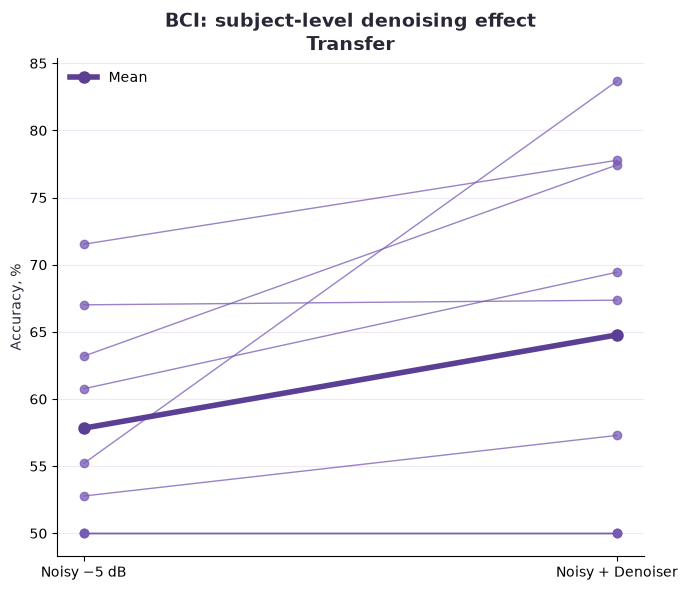

...

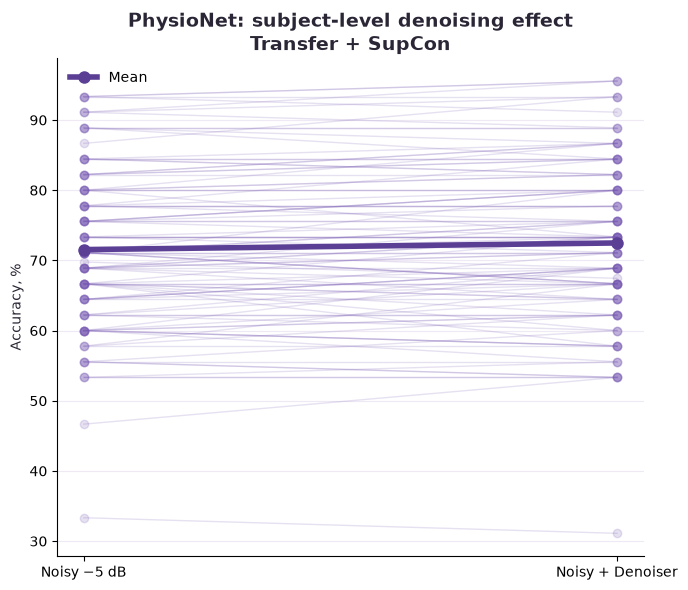

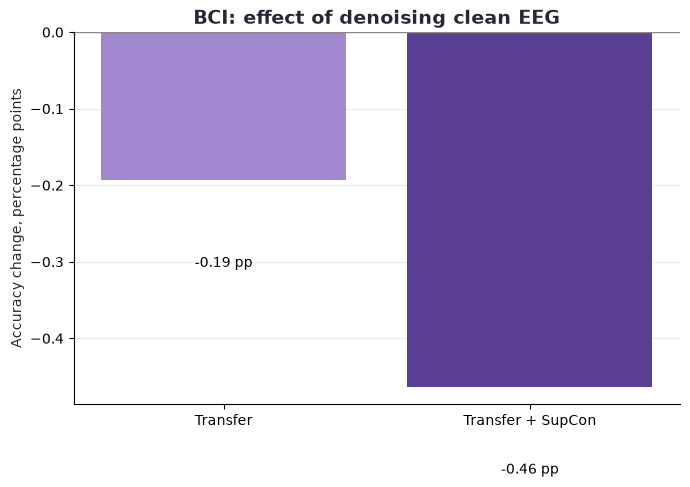

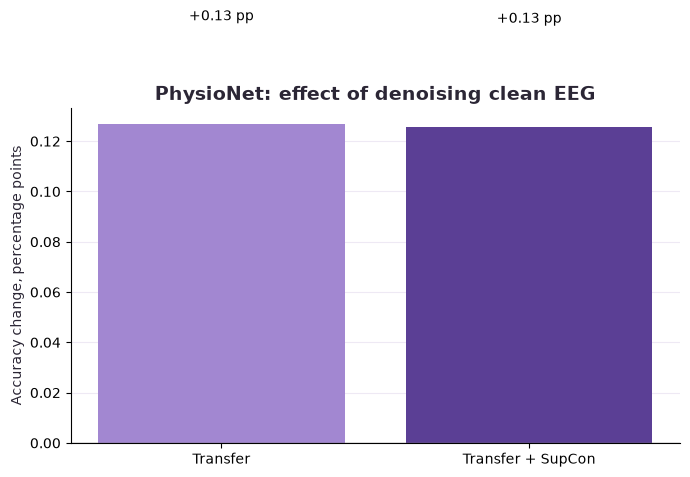

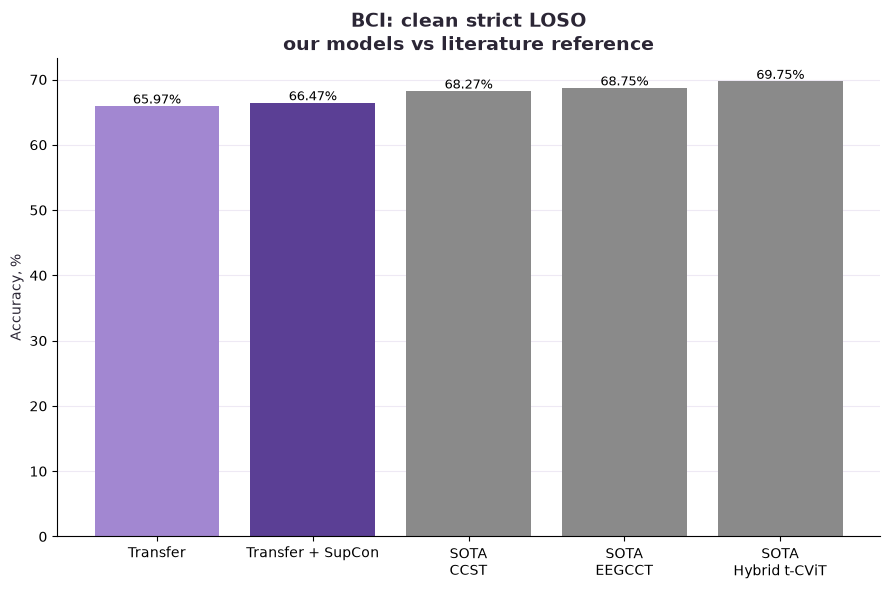

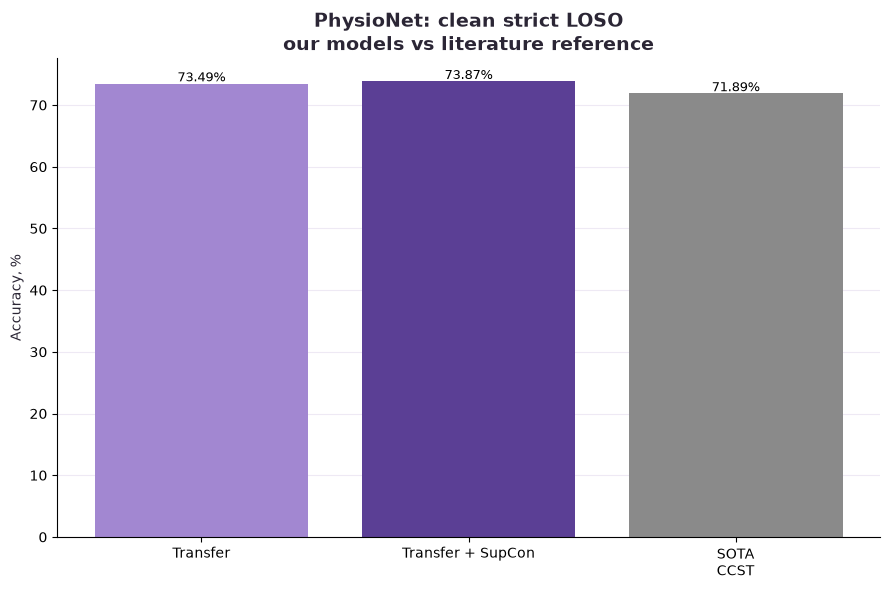


BEST CONFIGURATION


,dataset,method,condition,mean_accuracy_pct,std_accuracy_pct,mean_macro_f1_pct,mean_kappa
0,BCI,transfer_supcon,clean,66.474,16.151,61.016,0.329
1,PhysioNet,transfer_supcon,clean_denoised,73.993,12.214,73.435,0.480



####################################################################################################
FINAL INTERPRETATION
####################################################################################################

BCI
------------------------------------------------------------
Transfer
  noisy gain: +6.94 pp
  95% CI: [+2.01, +13.39]
  improved: 6/9
  Holm p: 0.035665
Transfer + SupCon
  noisy gain: +5.86 pp
  95% CI: [+0.12, +13.58]
  improved: 4/9
  Holm p: 0.202076

PhysioNet
------------------------------------------------------------
Transfer
  noisy gain: +0.53 pp
  95% CI: [-0.29, +1.34]
  improved: 49/106
  Holm p: 0.099081
Transfer + SupCon
  noisy gain: +0.94 pp
  95% CI: [+0.27, +1.61]
  improved: 47/106
  Holm p: 0.027206

SAVED
Tables: /Users/irina/Desktop/master project/results_v2/strict_loso_frozen_final/tables
Plots: /Users/irina/Desktop/master project/results_v2/strict_loso_frozen_final/plots


In [111]:
# ============================================================
# FINAL STATISTICS + TABLES + PLOTS
# strict LOSO / frozen classifier / correct denoising
#
# INPUT:
# strict_loso_frozen_subject_results.csv
#
# NO TRAINING
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon


# ============================================================
# PATHS
# ============================================================

BASE_DIR = Path(
    "/Users/irina/Desktop/master project"
)

FINAL_DIR = (
    BASE_DIR
    / "results_v2"
    / "strict_loso_frozen_final"
)

RESULT_PATH = (
    FINAL_DIR
    / "strict_loso_frozen_subject_results.csv"
)

TABLE_DIR = (
    FINAL_DIR
    / "tables"
)

PLOT_DIR = (
    FINAL_DIR
    / "plots"
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# COLORS
# ============================================================

PURPLE_DARK = "#5B3F95"
PURPLE = "#7759B3"
PURPLE_MID = "#A287D1"
PURPLE_LIGHT = "#D9CCED"

PINK_PURPLE = "#C184C6"
GREY = "#8A8A8A"

TEXT = "#2B2635"
GRID = "#E9E2F1"


METHOD_LABELS = {
    "transfer":
        "Transfer",

    "transfer_supcon":
        "Transfer + SupCon",
}


CONDITION_LABELS = {
    "clean":
        "Clean",

    "clean_denoised":
        "Clean + Denoiser",

    "noisy":
        "Noisy −5 dB",

    "noisy_denoised":
        "Noisy + Denoiser",
}


# ============================================================
# LOAD
# ============================================================

df = pd.read_csv(
    RESULT_PATH
)

df = (
    df
    .drop_duplicates(
        subset=[
            "dataset",
            "test_subject",
            "method",
            "condition",
        ],
        keep="last",
    )
    .reset_index(
        drop=True
    )
)


print(
    "Rows:",
    len(df)
)

print(
    "Datasets:",
    df["dataset"].unique()
)

print(
    "Methods:",
    df["method"].unique()
)

print(
    "Conditions:",
    df["condition"].unique()
)


# ============================================================
# COMPLETENESS
# ============================================================

expected = {
    "BCI": 9 * 2 * 4,
    "PhysioNet": 106 * 2 * 4,
}

print()
print("=" * 90)
print("COMPLETENESS")
print("=" * 90)

for dataset, n_expected in expected.items():

    n_actual = len(
        df[
            df["dataset"]
            == dataset
        ]
    )

    print(
        dataset,
        n_actual,
        "/",
        n_expected,
    )


# ============================================================
# SUMMARY
# ============================================================

summary = (
    df
    .groupby(
        [
            "dataset",
            "method",
            "condition",
        ],
        as_index=False,
    )
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),

        std_accuracy=(
            "accuracy",
            "std",
        ),

        median_accuracy=(
            "accuracy",
            "median",
        ),

        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean",
        ),

        mean_macro_f1=(
            "macro_f1",
            "mean",
        ),

        mean_kappa=(
            "kappa",
            "mean",
        ),

        n_subjects=(
            "test_subject",
            "nunique",
        ),
    )
)


for col in [
    "mean_accuracy",
    "std_accuracy",
    "median_accuracy",
    "mean_balanced_accuracy",
    "mean_macro_f1",
]:

    summary[
        col + "_pct"
    ] = (
        summary[col]
        * 100
    )


summary.to_csv(
    TABLE_DIR
    / "01_final_summary.csv",
    index=False,
)


print()
print("=" * 90)
print("FINAL SUMMARY")
print("=" * 90)

display(
    summary[
        [
            "dataset",
            "method",
            "condition",
            "mean_accuracy_pct",
            "std_accuracy_pct",
            "mean_macro_f1_pct",
            "mean_kappa",
            "n_subjects",
        ]
    ].round(3)
)


# ============================================================
# MAIN WIDE TABLE
# ============================================================

wide = (
    summary
    .pivot_table(
        index=[
            "dataset",
            "method",
        ],
        columns="condition",
        values="mean_accuracy_pct",
    )
    .reset_index()
)

wide.columns.name = None

wide = wide.rename(
    columns={
        "clean":
            "Clean",

        "clean_denoised":
            "Clean + Denoiser",

        "noisy":
            "Noisy −5 dB",

        "noisy_denoised":
            "Noisy + Denoiser",
    }
)


wide.to_csv(
    TABLE_DIR
    / "02_main_accuracy_table.csv",
    index=False,
)


print()
print("=" * 90)
print("MAIN ACCURACY TABLE, %")
print("=" * 90)

display(
    wide.round(2)
)


# ============================================================
# BOOTSTRAP CI
# ============================================================

def bootstrap_mean_ci(
    values,
    n_boot=20000,
    seed=42,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(
        seed
    )

    boot = np.empty(
        n_boot,
        dtype=np.float64,
    )

    for i in range(
        n_boot
    ):

        sample = rng.choice(
            values,
            size=len(values),
            replace=True,
        )

        boot[i] = (
            sample.mean()
        )

    low, high = np.percentile(
        boot,
        [2.5, 97.5],
    )

    return float(low), float(high)


# ============================================================
# WILCOXON
# robust to ties / zero differences
# ============================================================

def safe_wilcoxon(
    delta,
):

    delta = np.asarray(
        delta,
        dtype=float,
    )

    delta = delta[
        np.isfinite(delta)
    ]

    if len(delta) == 0:
        return np.nan, np.nan

    if np.allclose(
        delta,
        0,
    ):
        return 0.0, 1.0

    try:

        result = wilcoxon(
            delta,
            zero_method="pratt",
            alternative="two-sided",
            method="approx",
        )

        return (
            float(result.statistic),
            float(result.pvalue),
        )

    except Exception:

        return np.nan, np.nan


# ============================================================
# HOLM CORRECTION
# ============================================================

def holm_adjust(
    p_values,
):

    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    output = np.full(
        len(p_values),
        np.nan,
    )

    valid = np.where(
        np.isfinite(
            p_values
        )
    )[0]

    if len(valid) == 0:
        return output

    p = p_values[
        valid
    ]

    order = np.argsort(
        p
    )

    p_sorted = p[
        order
    ]

    m = len(
        p_sorted
    )

    corrected = np.zeros(
        m
    )

    running_max = 0.0

    for i, value in enumerate(
        p_sorted
    ):

        adj = (
            (m - i)
            * value
        )

        running_max = max(
            running_max,
            adj,
        )

        corrected[
            i
        ] = min(
            running_max,
            1.0,
        )

    unsorted = np.empty(
        m
    )

    unsorted[
        order
    ] = corrected

    output[
        valid
    ] = unsorted

    return output


# ============================================================
# PAIRED COMPARISON
# ============================================================

def paired_comparison(
    before,
    after,
):

    before = np.asarray(
        before,
        dtype=float,
    )

    after = np.asarray(
        after,
        dtype=float,
    )

    valid = (
        np.isfinite(before)
        &
        np.isfinite(after)
    )

    before = before[
        valid
    ]

    after = after[
        valid
    ]

    delta = (
        after
        - before
    )

    ci_low, ci_high = (
        bootstrap_mean_ci(
            delta
        )
    )

    W, p = safe_wilcoxon(
        delta
    )

    return {
        "n":
            len(delta),

        "mean_before":
            before.mean(),

        "mean_after":
            after.mean(),

        "mean_delta":
            delta.mean(),

        "median_delta":
            np.median(delta),

        "ci95_low":
            ci_low,

        "ci95_high":
            ci_high,

        "improved":
            int(
                (delta > 0).sum()
            ),

        "equal":
            int(
                np.isclose(
                    delta,
                    0,
                ).sum()
            ),

        "worse":
            int(
                (delta < 0).sum()
            ),

        "wilcoxon_W":
            W,

        "wilcoxon_p":
            p,
    }


# ============================================================
# DENOISING STATISTICS
# ============================================================

denoise_rows = []

for dataset in [
    "BCI",
    "PhysioNet",
]:

    for method in [
        "transfer",
        "transfer_supcon",
    ]:

        part = (
            df[
                (
                    df["dataset"]
                    == dataset
                )
                &
                (
                    df["method"]
                    == method
                )
            ]
            .pivot(
                index="test_subject",
                columns="condition",
                values="accuracy",
            )
        )

        comparisons = [
            (
                "clean",
                "clean_denoised",
                "Clean + Denoiser vs Clean",
            ),
            (
                "noisy",
                "noisy_denoised",
                "Noisy + Denoiser vs Noisy",
            ),
        ]

        for before, after, label in comparisons:

            stats = paired_comparison(
                part[before],
                part[after],
            )

            denoise_rows.append({
                "dataset":
                    dataset,

                "method":
                    method,

                "comparison":
                    label,

                **stats,
            })


denoise_stats = pd.DataFrame(
    denoise_rows
)


# Holm:
# separate family for each
# dataset × comparison

denoise_stats[
    "holm_p"
] = np.nan


for dataset in (
    denoise_stats[
        "dataset"
    ].unique()
):

    for comparison in (
        denoise_stats[
            "comparison"
        ].unique()
    ):

        mask = (
            (
                denoise_stats[
                    "dataset"
                ]
                == dataset
            )
            &
            (
                denoise_stats[
                    "comparison"
                ]
                == comparison
            )
        )

        denoise_stats.loc[
            mask,
            "holm_p"
        ] = holm_adjust(
            denoise_stats.loc[
                mask,
                "wilcoxon_p",
            ].values
        )


for col in [
    "mean_delta",
    "median_delta",
    "ci95_low",
    "ci95_high",
]:

    denoise_stats[
        col + "_pp"
    ] = (
        denoise_stats[col]
        * 100
    )


denoise_stats[
    "significant_005"
] = (
    denoise_stats[
        "holm_p"
    ]
    < 0.05
)


denoise_stats.to_csv(
    TABLE_DIR
    / "03_denoising_statistics.csv",
    index=False,
)


print()
print("=" * 90)
print("DENOISING STATISTICS")
print("=" * 90)

display(
    denoise_stats[
        [
            "dataset",
            "method",
            "comparison",
            "n",
            "mean_delta_pp",
            "ci95_low_pp",
            "ci95_high_pp",
            "improved",
            "equal",
            "worse",
            "wilcoxon_p",
            "holm_p",
            "significant_005",
        ]
    ].round(5)
)


# ============================================================
# MAIN ROBUSTNESS RESULT
# noisy denoised vs noisy
# ============================================================

robustness = (
    denoise_stats[
        denoise_stats[
            "comparison"
        ]
        ==
        "Noisy + Denoiser vs Noisy"
    ]
    .copy()
)


robustness.to_csv(
    TABLE_DIR
    / "04_main_robustness_result.csv",
    index=False,
)


print()
print("=" * 90)
print("MAIN ROBUSTNESS RESULT")
print("=" * 90)

display(
    robustness[
        [
            "dataset",
            "method",
            "mean_before",
            "mean_after",
            "mean_delta_pp",
            "ci95_low_pp",
            "ci95_high_pp",
            "improved",
            "equal",
            "worse",
            "holm_p",
        ]
    ].round(5)
)


# ============================================================
# CLEAN SAFETY RESULT
# Does denoising hurt clean EEG?
# ============================================================

clean_safety = (
    denoise_stats[
        denoise_stats[
            "comparison"
        ]
        ==
        "Clean + Denoiser vs Clean"
    ]
    .copy()
)


clean_safety.to_csv(
    TABLE_DIR
    / "05_clean_signal_safety.csv",
    index=False,
)


# ============================================================
# TRANSFER VS TRANSFER+SUPCON
# ============================================================

method_rows = []

for dataset in [
    "BCI",
    "PhysioNet",
]:

    for condition in [
        "clean",
        "clean_denoised",
        "noisy",
        "noisy_denoised",
    ]:

        part = (
            df[
                (
                    df["dataset"]
                    == dataset
                )
                &
                (
                    df["condition"]
                    == condition
                )
            ]
            .pivot(
                index="test_subject",
                columns="method",
                values="accuracy",
            )
        )

        stats = paired_comparison(
            part[
                "transfer"
            ],
            part[
                "transfer_supcon"
            ],
        )

        method_rows.append({
            "dataset":
                dataset,

            "condition":
                condition,

            "comparison":
                "Transfer + SupCon vs Transfer",

            **stats,
        })


method_stats = pd.DataFrame(
    method_rows
)


method_stats[
    "holm_p"
] = np.nan


for dataset in (
    method_stats[
        "dataset"
    ].unique()
):

    mask = (
        method_stats[
            "dataset"
        ]
        == dataset
    )

    method_stats.loc[
        mask,
        "holm_p"
    ] = holm_adjust(
        method_stats.loc[
            mask,
            "wilcoxon_p",
        ].values
    )


for col in [
    "mean_delta",
    "ci95_low",
    "ci95_high",
]:

    method_stats[
        col + "_pp"
    ] = (
        method_stats[col]
        * 100
    )


method_stats.to_csv(
    TABLE_DIR
    / "06_transfer_vs_supcon_statistics.csv",
    index=False,
)


print()
print("=" * 90)
print("TRANSFER + SUPCON VS TRANSFER")
print("=" * 90)

display(
    method_stats[
        [
            "dataset",
            "condition",
            "mean_delta_pp",
            "ci95_low_pp",
            "ci95_high_pp",
            "wilcoxon_p",
            "holm_p",
        ]
    ].round(5)
)


# ============================================================
# PLOT HELPER
# ============================================================

def finish_plot(
    ax,
    title,
    ylabel="Accuracy, %",
):

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        color=TEXT,
    )

    ax.set_ylabel(
        ylabel,
        color=TEXT,
    )

    ax.grid(
        axis="y",
        color=GRID,
        alpha=0.75,
    )

    ax.set_axisbelow(
        True
    )

    ax.spines[
        ["top", "right"]
    ].set_visible(
        False
    )


# ============================================================
# PLOT 1
# FOUR CONDITIONS — one plot per dataset
# ============================================================

condition_order = [
    "clean",
    "clean_denoised",
    "noisy",
    "noisy_denoised",
]


for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = (
        summary[
            summary["dataset"]
            == dataset
        ]
        .copy()
    )

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    x = np.arange(
        len(
            condition_order
        )
    )

    width = 0.34


    for offset, method, color in [
        (
            -width / 2,
            "transfer",
            PURPLE_MID,
        ),
        (
            width / 2,
            "transfer_supcon",
            PURPLE_DARK,
        ),
    ]:

        values = []

        for condition in condition_order:

            row = part[
                (
                    part[
                        "method"
                    ]
                    == method
                )
                &
                (
                    part[
                        "condition"
                    ]
                    == condition
                )
            ]

            values.append(
                row.iloc[0][
                    "mean_accuracy_pct"
                ]
            )

        bars = ax.bar(
            x + offset,
            values,
            width,
            label=
                METHOD_LABELS[
                    method
                ],
            color=color,
        )

        for bar in bars:

            h = bar.get_height()

            ax.text(
                bar.get_x()
                + bar.get_width()
                / 2,
                h + 0.45,
                f"{h:.1f}",
                ha="center",
                fontsize=9,
            )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        [
            CONDITION_LABELS[
                c
            ]
            for c in condition_order
        ]
    )

    ax.legend(
        frameon=False
    )

    finish_plot(
        ax,
        (
            f"{dataset}: strict LOSO\n"
            "Frozen classifier + MSE+PSD denoiser"
        ),
    )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"01_{dataset}_four_conditions.png",
        dpi=240,
        bbox_inches="tight",
    )

    plt.show()


# ============================================================
# PLOT 2
# DENOISING GAIN
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = robustness[
        robustness[
            "dataset"
        ]
        == dataset
    ].copy()

    labels = [
        METHOD_LABELS[m]
        for m in part[
            "method"
        ]
    ]

    values = (
        part[
            "mean_delta_pp"
        ].values
    )

    low = (
        values
        -
        part[
            "ci95_low_pp"
        ].values
    )

    high = (
        part[
            "ci95_high_pp"
        ].values
        -
        values
    )

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )

    bars = ax.bar(
        labels,
        values,
        yerr=[
            low,
            high,
        ],
        capsize=6,
        color=[
            PURPLE_MID,
            PURPLE_DARK,
        ],
    )

    ax.axhline(
        0,
        linewidth=1,
        color=GREY,
    )

    finish_plot(
        ax,
        (
            f"{dataset}: denoising effect on noisy EEG\n"
            "mean paired gain with 95% bootstrap CI"
        ),
        ylabel=
            "Accuracy gain, percentage points",
    )

    for bar, value in zip(
        bars,
        values,
    ):

        ax.text(
            bar.get_x()
            + bar.get_width()
            / 2,
            value + 0.25,
            f"{value:+.2f} pp",
            ha="center",
            fontsize=10,
        )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"02_{dataset}_denoising_gain.png",
        dpi=240,
        bbox_inches="tight",
    )

    plt.show()


# ============================================================
# PLOT 3
# SUBJECT PAIRS: Noisy -> Noisy+Denoised
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    for method in [
        "transfer",
        "transfer_supcon",
    ]:

        part = (
            df[
                (
                    df["dataset"]
                    == dataset
                )
                &
                (
                    df["method"]
                    == method
                )
            ]
            .pivot(
                index="test_subject",
                columns="condition",
                values="accuracy",
            )
        )

        fig, ax = plt.subplots(
            figsize=(7, 6)
        )

        alpha = (
            0.75
            if dataset == "BCI"
            else 0.18
        )

        for _, row in part.iterrows():

            ax.plot(
                [0, 1],
                [
                    row[
                        "noisy"
                    ] * 100,
                    row[
                        "noisy_denoised"
                    ] * 100,
                ],
                marker="o",
                linewidth=1,
                alpha=alpha,
                color=PURPLE,
            )


        mean_before = (
            part[
                "noisy"
            ].mean()
            * 100
        )

        mean_after = (
            part[
                "noisy_denoised"
            ].mean()
            * 100
        )


        ax.plot(
            [0, 1],
            [
                mean_before,
                mean_after,
            ],
            marker="o",
            linewidth=4,
            markersize=8,
            color=PURPLE_DARK,
            label="Mean",
        )


        ax.set_xticks(
            [0, 1]
        )

        ax.set_xticklabels(
            [
                "Noisy −5 dB",
                "Noisy + Denoiser",
            ]
        )

        ax.legend(
            frameon=False
        )

        finish_plot(
            ax,
            (
                f"{dataset}: subject-level denoising effect\n"
                f"{METHOD_LABELS[method]}"
            ),
        )

        plt.tight_layout()

        plt.savefig(
            PLOT_DIR
            / (
                f"03_{dataset}_"
                f"{method}_subject_pairs.png"
            ),
            dpi=240,
            bbox_inches="tight",
        )

        plt.show()


# ============================================================
# PLOT 4
# CLEAN SAFETY
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = clean_safety[
        clean_safety[
            "dataset"
        ]
        == dataset
    ]

    values = (
        part[
            "mean_delta_pp"
        ].values
    )

    labels = [
        METHOD_LABELS[
            m
        ]
        for m in part[
            "method"
        ]
    ]

    fig, ax = plt.subplots(
        figsize=(7, 5)
    )

    bars = ax.bar(
        labels,
        values,
        color=[
            PURPLE_MID,
            PURPLE_DARK,
        ],
    )

    ax.axhline(
        0,
        linewidth=1,
        color=GREY,
    )

    finish_plot(
        ax,
        (
            f"{dataset}: effect of denoising clean EEG"
        ),
        ylabel=
            "Accuracy change, percentage points",
    )

    for bar, value in zip(
        bars,
        values,
    ):

        ax.text(
            bar.get_x()
            + bar.get_width()
            / 2,
            value
            + (
                0.04
                if value >= 0
                else -0.10
            ),
            f"{value:+.2f} pp",
            ha="center",
            va=(
                "bottom"
                if value >= 0
                else "top"
            ),
        )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"04_{dataset}_clean_safety.png",
        dpi=240,
        bbox_inches="tight",
    )

    plt.show()


# ============================================================
# SOTA REFERENCE
#
# These are the literature reference values
# we already used earlier.
# Keep protocol comparability caveat in thesis text.
# ============================================================

SOTA = {
    "BCI": [
        (
            "CCST",
            68.27,
        ),
        (
            "EEGCCT",
            68.75,
        ),
        (
            "Hybrid t-CViT",
            69.75,
        ),
    ],

    "PhysioNet": [
        (
            "CCST",
            71.89,
        ),
    ],
}


# ============================================================
# PLOT 5
# OUR CLEAN STRICT LOSO VS SOTA
# ============================================================

for dataset in [
    "BCI",
    "PhysioNet",
]:

    ours = summary[
        (
            summary[
                "dataset"
            ]
            == dataset
        )
        &
        (
            summary[
                "condition"
            ]
            == "clean"
        )
    ]

    labels = [
        METHOD_LABELS[
            m
        ]
        for m in ours[
            "method"
        ]
    ]

    values = (
        ours[
            "mean_accuracy_pct"
        ]
        .tolist()
    )

    colors = [
        PURPLE_MID,
        PURPLE_DARK,
    ]

    for sota_name, sota_acc in SOTA[
        dataset
    ]:

        labels.append(
            f"SOTA\n{sota_name}"
        )

        values.append(
            sota_acc
        )

        colors.append(
            GREY
        )


    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    bars = ax.bar(
        labels,
        values,
        color=colors,
    )

    finish_plot(
        ax,
        (
            f"{dataset}: clean strict LOSO\n"
            "our models vs literature reference"
        ),
    )

    for bar, value in zip(
        bars,
        values,
    ):

        ax.text(
            bar.get_x()
            + bar.get_width()
            / 2,
            value + 0.35,
            f"{value:.2f}%",
            ha="center",
            fontsize=9,
        )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"05_{dataset}_clean_vs_sota.png",
        dpi=240,
        bbox_inches="tight",
    )

    plt.show()


# ============================================================
# BEST CONFIG TABLE
# ============================================================

best = (
    summary
    .sort_values(
        [
            "dataset",
            "mean_accuracy",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        "dataset",
        as_index=False,
    )
    .first()
)


best.to_csv(
    TABLE_DIR
    / "07_best_configuration.csv",
    index=False,
)


print()
print("=" * 90)
print("BEST CONFIGURATION")
print("=" * 90)

display(
    best[
        [
            "dataset",
            "method",
            "condition",
            "mean_accuracy_pct",
            "std_accuracy_pct",
            "mean_macro_f1_pct",
            "mean_kappa",
        ]
    ].round(3)
)


# ============================================================
# AUTOMATIC INTERPRETATION
# ============================================================

print()
print("#" * 100)
print("FINAL INTERPRETATION")
print("#" * 100)


for dataset in [
    "BCI",
    "PhysioNet",
]:

    print()
    print(dataset)
    print("-" * 60)

    for method in [
        "transfer",
        "transfer_supcon",
    ]:

        row = robustness[
            (
                robustness[
                    "dataset"
                ]
                == dataset
            )
            &
            (
                robustness[
                    "method"
                ]
                == method
            )
        ].iloc[0]

        print(
            METHOD_LABELS[
                method
            ]
        )

        print(
            "  noisy gain:",
            f"{row['mean_delta_pp']:+.2f} pp"
        )

        print(
            "  95% CI:",
            (
                f"[{row['ci95_low_pp']:+.2f}, "
                f"{row['ci95_high_pp']:+.2f}]"
            )
        )

        print(
            "  improved:",
            f"{int(row['improved'])}/{int(row['n'])}"
        )

        print(
            "  Holm p:",
            f"{row['holm_p']:.6f}"
        )


print()
print("=" * 100)
print("SAVED")
print("=" * 100)

print(
    "Tables:",
    TABLE_DIR
)

print(
    "Plots:",
    PLOT_DIR
)

# ============================================================
# EXPERIMENT: SUBJECT-INVARIANT REPRESENTATION LEARNING
#
# 1. Transfer + SupCon baseline
# 2. Transfer + SupCon + GRL
# 3. Transfer + SupCon + MixStyle
# 4. Transfer + SupCon + GRL + MixStyle
#
# Dataset selection:
#   Stage 1 — BCI IV-2a strict LOSO
#   Stage 2 — frozen recipe on PhysioNet strict LOSO
# ============================================================

# Subject-Invariant Representation Learning

## Цель

Улучшить subject-independent motor-imagery classification, не меняя основной EEGNet pipeline.

Используем один и тот же базовый подход:

**Cho2017 pretraining → target dataset → strict LOSO**

Сравниваем:

1. **Transfer + SupCon** — текущий baseline.
2. **Transfer + SupCon + GRL** — backbone учится сохранять информацию о движении,
   но терять информацию о личности subject.
3. **Transfer + SupCon + MixStyle** — статистики признаков искусственно
   смешиваются между разными subjects, чтобы модель меньше зависела от
   индивидуального EEG-стиля.
4. **Transfer + SupCon + GRL + MixStyle** — объединение обоих механизмов.

### Протокол

На первом этапе гиперпараметры и архитектуру выбираем только на BCI IV-2a.

- strict LOSO;
- test subject полностью unseen;
- отдельный validation subject;
- source initialization: Cho2017;
- binary L/R motor imagery;
- выбор checkpoint только по validation accuracy.

После выбора лучшей конфигурации весь рецепт фиксируется и без изменения
гиперпараметров переносится на PhysioNet.

In [113]:
required = [
    "np",
    "pd",
    "torch",
    "nn",
    "F",
    "Dataset",
    "DataLoader",
    "DEVICE",
    "SEED",
    "EPOCHS",
    "PATIENCE",
    "LEARNING_RATE",
    "WEIGHT_DECAY",
    "make_loader",
    "make_loso_plan",
    "verify_loso_plan",
    "materialize_loso_fold",
    "make_binary_model",
    "SupConLoss",
    "evaluate_model",
    "X_bci",
    "y_bci",
    "subjects_bci",
]

for name in required:
    print(
        f"{name:30s}",
        "OK" if name in globals() else "MISSING"
    )

np                             OK
pd                             OK
torch                          OK
nn                             OK
F                              OK
Dataset                        OK
DataLoader                     OK
DEVICE                         OK
SEED                           OK
EPOCHS                         OK
PATIENCE                       OK
LEARNING_RATE                  OK
WEIGHT_DECAY                   OK
make_loader                    OK
make_loso_plan                 OK
verify_loso_plan               OK
materialize_loso_fold          OK
make_binary_model              OK
SupConLoss                     OK
evaluate_model                 OK
X_bci                          OK
y_bci                          OK
subjects_bci                   OK


In [114]:
# ============================================================
# SUBJECT-INVARIANT EXPERIMENT — MODEL PREFLIGHT
# ничего не обучает
# ============================================================

import inspect

_probe = make_binary_model(
    transfer=True,
    input_samples=X_bci.shape[-1],
)

print("=" * 80)
print("BINARY MODEL")
print("=" * 80)

print("type:", type(_probe))
print()
print(_probe)

print()
print("ATTRIBUTES:")
for attr in [
    "backbone",
    "classifier",
    "fc",
    "feature_dim",
    "features",
]:
    print(
        f"{attr:20s}",
        hasattr(_probe, attr),
        (
            getattr(_probe, attr)
            if hasattr(_probe, attr)
            and attr == "feature_dim"
            else ""
        )
    )


print()
print("=" * 80)
print("FORWARD SIGNATURE")
print("=" * 80)

print(
    inspect.signature(
        _probe.forward
    )
)


print()
print("=" * 80)
print("SUPCON LOSS")
print("=" * 80)

print(
    "class:",
    SupConLoss
)

print(
    "forward:",
    inspect.signature(
        SupConLoss.forward
    )
)


print()
print("=" * 80)
print("SUPCON MODEL EXISTS?")
print("=" * 80)

print(
    "SupConEEGNet:",
    "OK"
    if "SupConEEGNet" in globals()
    else "MISSING"
)

if "SupConEEGNet" in globals():
    print(
        "init:",
        inspect.signature(
            SupConEEGNet.__init__
        )
    )


print()
print("=" * 80)
print("CURRENT SUPCON TRAIN FUNCTION?")
print("=" * 80)

print(
    "train_supcon_fold:",
    "OK"
    if "train_supcon_fold" in globals()
    else "MISSING"
)

if "train_supcon_fold" in globals():
    print(
        inspect.signature(
            train_supcon_fold
        )
    )

Transferred tensors: 13
BINARY MODEL
type: <class '__main__.BinaryEEGNet'>

BinaryEEGNet(
  (backbone): EEGNetBackbone(
    (conv1): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), padding=(0, 32), bias=False)
    (bn1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (depthwise): Conv2d(8, 16, kernel_size=(22, 1), stride=(1, 1), groups=8, bias=False)
    (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (pool1): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (dropout1): Dropout(p=0.5, inplace=False)
    (conv2): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
    (conv3): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (pool2): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (dropout2): Dropout(p=0.5, in

In [116]:
probe_supcon = SupConEEGNet(
    transfer=True,
    input_samples=X_bci.shape[-1],
)

print(probe_supcon)

print("\nATTRIBUTES:")
for name in dir(probe_supcon):
    if not name.startswith("_"):
        obj = getattr(probe_supcon, name)

        if isinstance(
            obj,
            torch.nn.Module
        ):
            print(
                f"{name:25s}",
                type(obj).__name__
            )

for attr in [
    "feature_dim",
    "projection_dim",
]:
    if hasattr(
        probe_supcon,
        attr
    ):
        print(
            attr,
            "=",
            getattr(
                probe_supcon,
                attr
            )
        )

Transferred tensors: 13
SupConEEGNet(
  (backbone): EEGNetBackbone(
    (conv1): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), padding=(0, 32), bias=False)
    (bn1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (depthwise): Conv2d(8, 16, kernel_size=(22, 1), stride=(1, 1), groups=8, bias=False)
    (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (pool1): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (dropout1): Dropout(p=0.5, inplace=False)
    (conv2): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
    (conv3): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (pool2): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (dropout2): Dropout(p=0.5, inplace=False)
  )
  (projector): Sequential(
    (0):

In [117]:
x_probe = torch.randn(
    4,
    22,
    X_bci.shape[-1],
).to(DEVICE)

probe_supcon = probe_supcon.to(
    DEVICE
)

probe_supcon.eval()

with torch.no_grad():

    out = probe_supcon(
        x_probe
    )

print(
    "forward type:",
    type(out)
)

if isinstance(
    out,
    (tuple, list)
):
    for i, item in enumerate(
        out
    ):
        print(
            i,
            item.shape
            if hasattr(
                item,
                "shape"
            )
            else type(item)
        )
else:
    print(
        "shape:",
        out.shape
    )

forward type: <class 'torch.Tensor'>
shape: torch.Size([4, 2])


In [118]:
# ============================================================
# SUBJECT-INVARIANT EXTENSIONS
#
# Existing pipeline is reused:
#   SupConEEGNet(transfer=True)
#
# New:
#   1. GRL / subject adversarial
#   2. Subject-wise MixStyle
#   3. GRL + MixStyle
# ============================================================

import copy
import gc

from sklearn.metrics import (
    accuracy_score,
    f1_score,
)


# ============================================================
# CONFIG
# ============================================================

SI_BASE_DIR = (
    BASE_DIR
    / "results_v2"
    / "subject_invariant_ablation"
)

SI_MODEL_DIR = (
    SI_BASE_DIR
    / "models"
)

SI_RESULT_DIR = (
    SI_BASE_DIR
    / "results"
)

SI_HISTORY_DIR = (
    SI_BASE_DIR
    / "histories"
)

for p in [
    SI_MODEL_DIR,
    SI_RESULT_DIR,
    SI_HISTORY_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )


SI_METHODS = [
    "transfer_supcon_grl",
    "transfer_supcon_mixstyle",
    "transfer_supcon_grl_mixstyle",
]


# SupCon оставляем тем же, что раньше
SI_LAMBDA_SUPCON = 0.15

# GRL
SI_LAMBDA_ADV = 0.10

# MixStyle
SI_MIXSTYLE_P = 0.50
SI_MIXSTYLE_ALPHA = 0.30

SI_BATCH_SIZE = 64


print("Output:", SI_BASE_DIR)
print("Device:", DEVICE)
print("Methods:", SI_METHODS)

Output: /Users/irina/Desktop/master project/results_v2/subject_invariant_ablation
Device: mps
Methods: ['transfer_supcon_grl', 'transfer_supcon_mixstyle', 'transfer_supcon_grl_mixstyle']


In [119]:
# ============================================================
# SUBJECT-AWARE DATASET
# нужен только потому, что GRL и MixStyle должны знать,
# от какого train-subject пришёл trial
# ============================================================

class SubjectAwareEEGDataset(Dataset):

    def __init__(
        self,
        X,
        y,
        subject_ids,
    ):
        self.X = np.asarray(
            X,
            dtype=np.float32,
        )

        self.y = np.asarray(
            y,
            dtype=np.int64,
        )

        self.subject_ids = np.asarray(
            subject_ids,
            dtype=np.int64,
        )


    def __len__(self):
        return len(
            self.y
        )


    def __getitem__(
        self,
        idx,
    ):
        return (
            torch.from_numpy(
                self.X[idx]
            ),
            torch.tensor(
                self.y[idx],
                dtype=torch.long,
            ),
            torch.tensor(
                self.subject_ids[idx],
                dtype=torch.long,
            ),
        )


def make_subject_loader(
    X,
    y,
    subject_ids,
    shuffle,
):

    ds = SubjectAwareEEGDataset(
        X=X,
        y=y,
        subject_ids=subject_ids,
    )

    return DataLoader(
        ds,
        batch_size=SI_BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
    )

In [120]:
# ============================================================
# GRADIENT REVERSAL
#
# Subject classifier:
#     пытается определить человека
#
# Backbone через GRL:
#     получает обратный градиент
#     и учится делать subject ID неразличимым
# ============================================================

class GradientReversalFunction(
    torch.autograd.Function
):

    @staticmethod
    def forward(
        ctx,
        x,
        coeff,
    ):
        ctx.coeff = coeff
        return x.view_as(x)


    @staticmethod
    def backward(
        ctx,
        grad_output,
    ):
        return (
            -ctx.coeff
            * grad_output,
            None,
        )


def grad_reverse(
    x,
    coeff=1.0,
):
    return (
        GradientReversalFunction
        .apply(
            x,
            coeff,
        )
    )


def grl_schedule(
    progress,
):
    """
    progress: 0 ... 1

    В начале почти не мешаем backbone.
    К концу усиливаем adversarial pressure.
    """

    return (
        2.0
        /
        (
            1.0
            + np.exp(
                -10.0
                * progress
            )
        )
        - 1.0
    )

In [121]:
# ============================================================
# SUBJECT-WISE MIXSTYLE
#
# Не перемешиваем сами EEG trials.
# Перемешиваем статистики FEATURE MAP между разными subjects.
#
# Смысл:
#   "движение оставь,
#    индивидуальный EEG-стиль меняй"
# ============================================================

class SubjectMixStyle(nn.Module):

    def __init__(
        self,
        p=0.5,
        alpha=0.3,
        eps=1e-6,
    ):
        super().__init__()

        self.p = p
        self.alpha = alpha
        self.eps = eps


    def forward(
        self,
        x,
        subject_ids,
    ):

        # только train
        if not self.training:
            return x

        if x.shape[0] < 2:
            return x

        if (
            torch.rand(
                1,
                device=x.device,
            ).item()
            > self.p
        ):
            return x


        # EEGNet backbone:
        # [B, C, 1, T]
        dims = tuple(
            range(
                2,
                x.ndim,
            )
        )


        mu = x.mean(
            dim=dims,
            keepdim=True,
        )

        var = x.var(
            dim=dims,
            keepdim=True,
            unbiased=False,
        )

        sigma = torch.sqrt(
            var
            + self.eps
        )


        mu_det = mu.detach()
        sigma_det = sigma.detach()


        x_norm = (
            x - mu
        ) / sigma


        B = x.shape[0]

        perm = torch.arange(
            B,
            device=x.device,
        )


        # каждому trial подбираем trial ДРУГОГО subject
        for i in range(B):

            candidates = torch.where(
                subject_ids
                != subject_ids[i]
            )[0]

            if len(candidates) > 0:

                random_idx = torch.randint(
                    low=0,
                    high=len(candidates),
                    size=(1,),
                    device=x.device,
                )

                perm[i] = candidates[
                    random_idx
                ]


        mu_other = mu_det[
            perm
        ]

        sigma_other = sigma_det[
            perm
        ]


        beta_dist = (
            torch.distributions.Beta(
                SI_MIXSTYLE_ALPHA,
                SI_MIXSTYLE_ALPHA,
            )
        )

        lam = beta_dist.sample(
            (B,)
        ).to(
            x.device
        )


        shape = [
            B
        ] + [
            1
        ] * (
            x.ndim - 1
        )

        lam = lam.view(
            *shape
        )


        mu_mix = (
            lam * mu_det
            +
            (1.0 - lam)
            * mu_other
        )

        sigma_mix = (
            lam * sigma_det
            +
            (1.0 - lam)
            * sigma_other
        )


        return (
            x_norm
            * sigma_mix
            + mu_mix
        )

In [122]:
# ============================================================
# BUILDER
# ============================================================

def build_si_model(
    method,
    n_train_subjects,
    input_samples,
):

    if method == (
        "transfer_supcon_grl"
    ):

        return SubjectInvariantSupConEEGNet(
            n_train_subjects=
                n_train_subjects,
            use_grl=True,
            use_mixstyle=False,
            input_samples=
                input_samples,
        )


    elif method == (
        "transfer_supcon_mixstyle"
    ):

        return SubjectInvariantSupConEEGNet(
            n_train_subjects=
                n_train_subjects,
            use_grl=False,
            use_mixstyle=True,
            input_samples=
                input_samples,
        )


    elif method == (
        "transfer_supcon_grl_mixstyle"
    ):

        return SubjectInvariantSupConEEGNet(
            n_train_subjects=
                n_train_subjects,
            use_grl=True,
            use_mixstyle=True,
            input_samples=
                input_samples,
        )


    else:

        raise ValueError(
            f"Unknown method: {method}"
        )

In [123]:
# ============================================================
# TRAIN ONE SUBJECT-INVARIANT FOLD
# ============================================================

def train_si_fold(
    model,
    train_loader,
    val_loader,
    method_name,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    patience=PATIENCE,
):

    model = model.to(
        DEVICE
    )


    optimizer = (
        torch.optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=
                weight_decay,
        )
    )


    ce_loss_fn = (
        nn.CrossEntropyLoss()
    )

    subject_loss_fn = (
        nn.CrossEntropyLoss()
    )

    supcon_loss_fn = (
        SupConLoss()
    )


    best_val_acc = -1.0
    best_val_f1 = -1.0

    best_epoch = None
    best_state = None

    patience_counter = 0

    history = []


    total_steps = max(
        1,
        epochs
        * len(train_loader),
    )

    global_step = 0


    for epoch in range(
        1,
        epochs + 1,
    ):

        # ====================================================
        # TRAIN
        # ====================================================

        model.train()


        sum_loss = 0.0
        sum_ce = 0.0
        sum_sc = 0.0
        sum_adv = 0.0

        n_batches = 0

        y_true_train = []
        y_pred_train = []


        for (
            xb,
            yb,
            sb,
        ) in train_loader:

            xb = xb.to(
                DEVICE
            )

            yb = yb.to(
                DEVICE
            )

            sb = sb.to(
                DEVICE
            )


            optimizer.zero_grad()


            progress = min(
                1.0,
                global_step
                / total_steps,
            )


            coeff = (
                grl_schedule(
                    progress
                )
                if model.use_grl
                else 0.0
            )


            (
                logits,
                projection,
                subject_logits,
            ) = model.forward_train(
                xb,
                sb,
                grl_coeff=coeff,
            )


            # ---------------------------------------------
            # L/R classification
            # ---------------------------------------------

            loss_ce = (
                ce_loss_fn(
                    logits,
                    yb,
                )
            )


            # ---------------------------------------------
            # SAME SupCon
            # ---------------------------------------------

            loss_sc = (
                supcon_loss_fn(
                    projection,
                    yb,
                )
            )


            loss = (
                loss_ce
                +
                SI_LAMBDA_SUPCON
                * loss_sc
            )


            # ---------------------------------------------
            # subject adversarial
            # ---------------------------------------------

            if model.use_grl:

                loss_adv = (
                    subject_loss_fn(
                        subject_logits,
                        sb,
                    )
                )

                loss = (
                    loss
                    +
                    SI_LAMBDA_ADV
                    * loss_adv
                )

            else:

                loss_adv = (
                    torch.tensor(
                        0.0,
                        device=DEVICE,
                    )
                )


            loss.backward()


            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )


            optimizer.step()


            pred = (
                logits
                .argmax(
                    dim=1
                )
            )


            y_true_train.extend(
                yb.detach()
                .cpu()
                .numpy()
            )

            y_pred_train.extend(
                pred.detach()
                .cpu()
                .numpy()
            )


            sum_loss += (
                loss.item()
            )

            sum_ce += (
                loss_ce.item()
            )

            sum_sc += (
                loss_sc.item()
            )

            sum_adv += (
                loss_adv.item()
            )

            n_batches += 1
            global_step += 1


        train_acc = (
            accuracy_score(
                y_true_train,
                y_pred_train,
            )
        )


        # ====================================================
        # VALIDATION
        #
        # IMPORTANT:
        # no MixStyle
        # no subject discriminator
        # only L/R classifier
        # ====================================================

        model.eval()

        val_true = []
        val_pred = []


        with torch.no_grad():

            for (
                xb,
                yb,
                _,
            ) in val_loader:

                xb = xb.to(
                    DEVICE
                )

                logits = model(
                    xb
                )

                pred = logits.argmax(
                    dim=1
                )


                val_true.extend(
                    yb.numpy()
                )

                val_pred.extend(
                    pred.cpu()
                    .numpy()
                )


        val_acc = (
            accuracy_score(
                val_true,
                val_pred,
            )
        )

        val_f1 = (
            f1_score(
                val_true,
                val_pred,
                average="macro",
                zero_division=0,
            )
        )


        row = {
            "epoch":
                epoch,

            "train_accuracy":
                train_acc,

            "val_accuracy":
                val_acc,

            "val_macro_f1":
                val_f1,

            "loss":
                sum_loss
                / n_batches,

            "ce_loss":
                sum_ce
                / n_batches,

            "supcon_loss":
                sum_sc
                / n_batches,

            "subject_loss":
                sum_adv
                / n_batches,

            "grl_coeff":
                coeff,
        }


        history.append(
            row
        )


        print(
            f"{method_name:32s}"
            f" | ep={epoch:03d}"
            f" | train={train_acc:.4f}"
            f" | val={val_acc:.4f}"
            f" | f1={val_f1:.4f}"
            f" | CE={row['ce_loss']:.4f}"
            f" | SC={row['supcon_loss']:.4f}"
            f" | ADV={row['subject_loss']:.4f}"
            f" | GRL={coeff:.3f}"
        )


        # ====================================================
        # BEST CHECKPOINT:
        # val accuracy
        # tie-break macro F1
        # ====================================================

        improved = (
            val_acc
            > best_val_acc
            + 1e-12
        ) or (
            abs(
                val_acc
                - best_val_acc
            )
            <= 1e-12
            and
            val_f1
            > best_val_f1
        )


        if improved:

            best_val_acc = (
                val_acc
            )

            best_val_f1 = (
                val_f1
            )

            best_epoch = (
                epoch
            )

            best_state = (
                copy.deepcopy(
                    model.state_dict()
                )
            )

            patience_counter = 0


        else:

            patience_counter += 1


        if (
            patience_counter
            >= patience
        ):

            print(
                f"Early stopping at "
                f"epoch {epoch}"
            )

            break


    if best_state is None:
        raise RuntimeError(
            "No best checkpoint selected."
        )


    model.load_state_dict(
        best_state
    )


    return {
        "model":
            model,

        "best_epoch":
            best_epoch,

        "best_val_accuracy":
            best_val_acc,

        "best_val_macro_f1":
            best_val_f1,

        "history":
            pd.DataFrame(
                history
            ),
    }

In [125]:
# ============================================================
# SUBJECT-INVARIANT SUPCON EEGNET
# ============================================================

class SubjectInvariantSupConEEGNet(
    nn.Module
):

    def __init__(
        self,
        n_train_subjects,
        use_grl=False,
        use_mixstyle=False,
        input_samples=876,
    ):
        super().__init__()

        # exact same existing Transfer + SupCon base
        base = SupConEEGNet(
            transfer=True,
            input_samples=input_samples,
            projection_dim=128,
        )

        self.backbone = base.backbone
        self.projector = base.projector
        self.fc = base.fc
        self.feature_dim = base.feature_dim

        self.use_grl = use_grl
        self.use_mixstyle = use_mixstyle

        if self.use_mixstyle:
            self.mixstyle = SubjectMixStyle(
                p=SI_MIXSTYLE_P,
                alpha=SI_MIXSTYLE_ALPHA,
            )

        if self.use_grl:
            self.subject_classifier = nn.Sequential(
                nn.Linear(
                    self.feature_dim,
                    128,
                ),
                nn.ReLU(),
                nn.Dropout(0.25),
                nn.Linear(
                    128,
                    n_train_subjects,
                ),
            )

    def forward_train(
        self,
        x,
        subject_ids,
        grl_coeff=1.0,
    ):
        feature_map = self.backbone(x)

        if self.use_mixstyle:
            feature_map = self.mixstyle(
                feature_map,
                subject_ids,
            )

        features = feature_map.flatten(1)

        logits = self.fc(
            features
        )

        projection = self.projector(
            features
        )

        projection = F.normalize(
            projection,
            dim=1,
        )

        subject_logits = None

        if self.use_grl:
            reversed_features = grad_reverse(
                features,
                coeff=grl_coeff,
            )

            subject_logits = (
                self.subject_classifier(
                    reversed_features
                )
            )

        return (
            logits,
            projection,
            subject_logits,
        )

    def forward(
        self,
        x,
    ):
        # inference:
        # no MixStyle, no GRL
        features = (
            self.backbone(x)
            .flatten(1)
        )

        return self.fc(
            features
        )

In [126]:
# ============================================================
# SANITY — ONE BCI FOLD / 2 EPOCHS
# ============================================================

bci_si_plan = make_loso_plan(
    subjects_bci
)

verify_loso_plan(
    subjects_bci,
    bci_si_plan,
)


sanity_item = (
    bci_si_plan[0]
)

test_subject = (
    sanity_item[
        "test_subject"
    ]
)

val_subject = (
    sanity_item[
        "val_subject"
    ]
)


train_mask = (
    (subjects_bci != test_subject)
    &
    (subjects_bci != val_subject)
)

val_mask = (
    subjects_bci
    == val_subject
)


X_train_si = (
    X_bci[
        train_mask
    ]
)

y_train_si = (
    y_bci[
        train_mask
    ]
)

subjects_train_raw = (
    subjects_bci[
        train_mask
    ]
)


X_val_si = (
    X_bci[
        val_mask
    ]
)

y_val_si = (
    y_bci[
        val_mask
    ]
)


# ------------------------------------------------------------
# train subjects -> integer IDs 0..6
# ------------------------------------------------------------

train_subject_names = sorted(
    np.unique(
        subjects_train_raw
    )
)


subject_to_id = {
    s: i
    for i, s
    in enumerate(
        train_subject_names
    )
}


train_subject_ids = np.asarray(
    [
        subject_to_id[s]
        for s
        in subjects_train_raw
    ],
    dtype=np.int64,
)


# validation subject ID не используется,
# поэтому просто zeros
val_subject_ids = np.zeros(
    len(
        y_val_si
    ),
    dtype=np.int64,
)


print(
    "TEST:",
    test_subject
)

print(
    "VAL:",
    val_subject
)

print(
    "TRAIN SUBJECTS:",
    train_subject_names
)

print(
    "n train subjects:",
    len(
        train_subject_names
    )
)


train_loader_si = (
    make_subject_loader(
        X_train_si,
        y_train_si,
        train_subject_ids,
        shuffle=True,
    )
)


val_loader_si = (
    make_subject_loader(
        X_val_si,
        y_val_si,
        val_subject_ids,
        shuffle=False,
    )
)


sanity_model = (
    build_si_model(
        method=
            "transfer_supcon_grl_mixstyle",

        n_train_subjects=
            len(
                train_subject_names
            ),

        input_samples=
            X_bci.shape[-1],
    )
)


sanity_result = (
    train_si_fold(
        model=
            sanity_model,

        train_loader=
            train_loader_si,

        val_loader=
            val_loader_si,

        method_name=
            "SANITY GRL+MixStyle",

        epochs=2,

        patience=2,
    )
)


print()
print("=" * 80)

print(
    "BEST EPOCH:",
    sanity_result[
        "best_epoch"
    ]
)

print(
    "BEST VAL ACC:",
    sanity_result[
        "best_val_accuracy"
    ]
)

print(
    "BEST VAL F1:",
    sanity_result[
        "best_val_macro_f1"
    ]
)

OK — 9 strict LOSO folds, no subject leakage
TEST: A01
VAL: A02
TRAIN SUBJECTS: ['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
n train subjects: 7
Transferred tensors: 13
SANITY GRL+MixStyle              | ep=001 | train=0.5169 | val=0.5000 | f1=0.3333 | CE=0.6918 | SC=4.1532 | ADV=1.8339 | GRL=0.984
SANITY GRL+MixStyle              | ep=002 | train=0.6086 | val=0.5000 | f1=0.3333 | CE=0.6517 | SC=4.1207 | ADV=1.6379 | GRL=1.000

BEST EPOCH: 1
BEST VAL ACC: 0.5
BEST VAL F1: 0.3333333333333333


In [127]:
# ============================================================
# ADD CONTROL METHOD
# exact Transfer + SupCon, without GRL / MixStyle
# ============================================================

def build_si_model(
    method,
    n_train_subjects,
    input_samples,
):

    if method == "transfer_supcon_control":

        return SubjectInvariantSupConEEGNet(
            n_train_subjects=n_train_subjects,
            use_grl=False,
            use_mixstyle=False,
            input_samples=input_samples,
        )

    elif method == "transfer_supcon_grl":

        return SubjectInvariantSupConEEGNet(
            n_train_subjects=n_train_subjects,
            use_grl=True,
            use_mixstyle=False,
            input_samples=input_samples,
        )

    elif method == "transfer_supcon_mixstyle":

        return SubjectInvariantSupConEEGNet(
            n_train_subjects=n_train_subjects,
            use_grl=False,
            use_mixstyle=True,
            input_samples=input_samples,
        )

    elif method == "transfer_supcon_grl_mixstyle":

        return SubjectInvariantSupConEEGNet(
            n_train_subjects=n_train_subjects,
            use_grl=True,
            use_mixstyle=True,
            input_samples=input_samples,
        )

    else:
        raise ValueError(
            f"Unknown method: {method}"
        )

In [128]:
# ============================================================
# ONE-FOLD MINI ABLATION
# A01 test / A02 validation
#
# Purpose:
# make sure the new training pipeline can actually learn
# before starting 27 full LOSO runs.
# ============================================================

MINI_METHODS = [
    "transfer_supcon_control",
    "transfer_supcon_grl",
    "transfer_supcon_mixstyle",
    "transfer_supcon_grl_mixstyle",
]

mini_results = []

for method in MINI_METHODS:

    print()
    print("#" * 100)
    print(method)
    print("#" * 100)

    torch.manual_seed(SEED)
    np.random.seed(SEED)

    model = build_si_model(
        method=method,
        n_train_subjects=len(
            train_subject_names
        ),
        input_samples=X_bci.shape[-1],
    )

    result = train_si_fold(
        model=model,
        train_loader=train_loader_si,
        val_loader=val_loader_si,
        method_name=method,
        epochs=10,
        patience=10,
    )

    mini_results.append({
        "method":
            method,

        "best_epoch":
            result[
                "best_epoch"
            ],

        "best_val_accuracy":
            result[
                "best_val_accuracy"
            ],

        "best_val_macro_f1":
            result[
                "best_val_macro_f1"
            ],
    })

    del model
    del result

    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


mini_df = pd.DataFrame(
    mini_results
)

print()
print("=" * 100)
print("ONE-FOLD MINI ABLATION")
print("=" * 100)

display(
    mini_df.sort_values(
        "best_val_accuracy",
        ascending=False,
    )
)


####################################################################################################
transfer_supcon_control
####################################################################################################
Transferred tensors: 13
transfer_supcon_control          | ep=001 | train=0.5605 | val=0.5000 | f1=0.3333 | CE=0.6769 | SC=4.1550 | ADV=0.0000 | GRL=0.000
transfer_supcon_control          | ep=002 | train=0.6463 | val=0.5000 | f1=0.3333 | CE=0.6226 | SC=4.1177 | ADV=0.0000 | GRL=0.000
transfer_supcon_control          | ep=003 | train=0.6771 | val=0.5000 | f1=0.3333 | CE=0.5700 | SC=4.1085 | ADV=0.0000 | GRL=0.000
transfer_supcon_control          | ep=004 | train=0.6944 | val=0.5035 | f1=0.3410 | CE=0.5536 | SC=4.0981 | ADV=0.0000 | GRL=0.000
transfer_supcon_control          | ep=005 | train=0.7138 | val=0.5000 | f1=0.3333 | CE=0.5227 | SC=4.0846 | ADV=0.0000 | GRL=0.000
transfer_supcon_control          | ep=006 | train=0.6994 | val=0.5000 | f1=0.3333 | CE=0.5314 

,method,best_epoch,best_val_accuracy,best_val_macro_f1
1,transfer_supcon_grl,9,0.586806,0.564629
2,transfer_supcon_mixstyle,7,0.576389,0.572908
3,transfer_supcon_grl_mixstyle,6,0.569444,0.492727
0,transfer_supcon_control,9,0.545139,0.469091


In [129]:
# ============================================================
# EXACT OLD TRANSFER+SUPCON BASELINE
# SAME SPLIT:
# TEST = A01
# VAL  = A02
#
# This checks whether our reconstructed trainer
# reproduces the original SupCon pipeline.
# ============================================================

old_train_loader = make_loader(
    X_train_si,
    y_train_si,
    shuffle=True,
)

old_val_loader = make_loader(
    X_val_si,
    y_val_si,
    shuffle=False,
)


torch.manual_seed(SEED)
np.random.seed(SEED)


old_supcon_model = SupConEEGNet(
    transfer=True,
    input_samples=X_bci.shape[-1],
    projection_dim=128,
).to(DEVICE)


old_result = train_supcon_fold(
    model=old_supcon_model,
    train_loader=old_train_loader,
    val_loader=old_val_loader,

    # сначала тоже 10 эпох,
    # чтобы сравнение было 1:1
    epochs=10,

    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,

    patience=10,

    lambda_supcon=0.15,

    device=DEVICE,
)

print()
print("=" * 80)
print("OLD EXACT TRANSFER+SUPCON")
print("=" * 80)

print(old_result)

Transferred tensors: 13
epoch 01 | loss=1.3032 | train=0.5635 | val=0.5000 | best=0.5000
epoch 02 | loss=1.2424 | train=0.6453 | val=0.5000 | best=0.5000
epoch 03 | loss=1.1892 | train=0.6811 | val=0.5000 | best=0.5000
epoch 04 | loss=1.1714 | train=0.6944 | val=0.5000 | best=0.5000
epoch 05 | loss=1.1368 | train=0.7143 | val=0.5000 | best=0.5000
epoch 06 | loss=1.1437 | train=0.6944 | val=0.5347 | best=0.5347
epoch 07 | loss=1.1462 | train=0.7133 | val=0.5000 | best=0.5347
epoch 08 | loss=1.1366 | train=0.7183 | val=0.5243 | best=0.5347
epoch 09 | loss=1.1402 | train=0.7059 | val=0.5382 | best=0.5382
epoch 10 | loss=1.1310 | train=0.7098 | val=0.5000 | best=0.5382

OLD EXACT TRANSFER+SUPCON
{'model': SupConEEGNet(
  (backbone): EEGNetBackbone(
    (conv1): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), padding=(0, 32), bias=False)
    (bn1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (depthwise): Conv2d(8, 16, kernel_size=(22, 1), s

In [130]:
# ============================================================
# FULL BCI STRICT-LOSO
# SUBJECT-INVARIANT ABLATION
#
# 3 NEW METHODS:
#   Transfer + SupCon + GRL
#   Transfer + SupCon + MixStyle
#   Transfer + SupCon + GRL + MixStyle
#
# 9 subjects × 3 = 27 trainings
#
# Baseline Transfer+SupCon is already available
# from the previous strict-LOSO experiment.
# ============================================================

BCI_SI_METHODS = [
    "transfer_supcon_grl",
    "transfer_supcon_mixstyle",
    "transfer_supcon_grl_mixstyle",
]

BCI_SI_PROGRESS_PATH = (
    SI_RESULT_DIR
    / "bci_subject_invariant_progress.csv"
)

BCI_SI_FINAL_PATH = (
    SI_RESULT_DIR
    / "bci_subject_invariant_results.csv"
)


# ============================================================
# RESUME
# ============================================================

if BCI_SI_PROGRESS_PATH.exists():

    bci_si_results = pd.read_csv(
        BCI_SI_PROGRESS_PATH
    )

    print(
        "Resume:",
        len(bci_si_results),
        "completed runs"
    )

else:

    bci_si_results = pd.DataFrame()


all_rows = (
    bci_si_results
    .to_dict("records")
    if len(bci_si_results)
    else []
)


def si_already_done(
    test_subject,
    method,
):

    if len(bci_si_results) == 0:
        return False

    mask = (
        (
            bci_si_results[
                "test_subject"
            ].astype(str)
            == str(test_subject)
        )
        &
        (
            bci_si_results[
                "method"
            ]
            == method
        )
    )

    return mask.any()


# ============================================================
# PLAN
# ============================================================

bci_si_plan = make_loso_plan(
    subjects_bci
)

verify_loso_plan(
    subjects_bci,
    bci_si_plan,
)


print()
print("=" * 100)
print("BCI SUBJECT-INVARIANT STRICT LOSO")
print("=" * 100)

print(
    "Folds:",
    len(bci_si_plan)
)

print(
    "Methods:",
    BCI_SI_METHODS
)

print(
    "Total:",
    len(bci_si_plan)
    * len(BCI_SI_METHODS)
)


# ============================================================
# RUN
# ============================================================

for fold_idx, item in enumerate(
    bci_si_plan,
    start=1,
):

    test_subject = (
        item[
            "test_subject"
        ]
    )

    val_subject = (
        item[
            "val_subject"
        ]
    )


    print()
    print("#" * 100)
    print(
        f"BCI FOLD {fold_idx}/9"
        f" | TEST={test_subject}"
        f" | VAL={val_subject}"
    )
    print("#" * 100)


    # --------------------------------------------------------
    # masks
    # --------------------------------------------------------

    train_mask = (
        (subjects_bci != test_subject)
        &
        (subjects_bci != val_subject)
    )

    val_mask = (
        subjects_bci
        == val_subject
    )

    test_mask = (
        subjects_bci
        == test_subject
    )


    # --------------------------------------------------------
    # arrays
    # --------------------------------------------------------

    X_train = (
        X_bci[
            train_mask
        ].astype(
            np.float32
        )
    )

    y_train = (
        y_bci[
            train_mask
        ]
    )

    subjects_train = (
        subjects_bci[
            train_mask
        ]
    )


    X_val = (
        X_bci[
            val_mask
        ].astype(
            np.float32
        )
    )

    y_val = (
        y_bci[
            val_mask
        ]
    )


    X_test = (
        X_bci[
            test_mask
        ].astype(
            np.float32
        )
    )

    y_test = (
        y_bci[
            test_mask
        ]
    )


    # --------------------------------------------------------
    # map train subject names -> 0 ... n-1
    # --------------------------------------------------------

    train_subject_names = sorted(
        np.unique(
            subjects_train
        )
    )

    subject_to_id = {
        subject: idx
        for idx, subject
        in enumerate(
            train_subject_names
        )
    }


    train_subject_ids = np.asarray(
        [
            subject_to_id[s]
            for s in subjects_train
        ],
        dtype=np.int64,
    )


    # validation subject id is irrelevant:
    # GRL/MixStyle disabled during validation
    val_subject_ids = np.zeros(
        len(y_val),
        dtype=np.int64,
    )


    print(
        "TRAIN:",
        train_subject_names
    )

    print(
        "n train subjects:",
        len(train_subject_names)
    )

    print(
        "train/val/test:",
        len(y_train),
        len(y_val),
        len(y_test),
    )


    # ========================================================
    # METHODS
    # ========================================================

    for method_idx, method in enumerate(
        BCI_SI_METHODS,
        start=1,
    ):

        print()
        print(
            f"[{method_idx}/3]",
            method
        )


        if si_already_done(
            test_subject,
            method,
        ):

            print(
                "SKIP — already completed"
            )

            continue


        # ----------------------------------------------------
        # deterministic start per fold/method
        # ----------------------------------------------------

        run_seed = (
            SEED
            + fold_idx * 100
            + method_idx
        )

        np.random.seed(
            run_seed
        )

        torch.manual_seed(
            run_seed
        )


        # ----------------------------------------------------
        # loaders
        # ----------------------------------------------------

        train_loader = (
            make_subject_loader(
                X=X_train,
                y=y_train,
                subject_ids=
                    train_subject_ids,
                shuffle=True,
            )
        )

        val_loader = (
            make_subject_loader(
                X=X_val,
                y=y_val,
                subject_ids=
                    val_subject_ids,
                shuffle=False,
            )
        )


        test_loader = make_loader(
            X_test,
            y_test,
            shuffle=False,
        )


        # ----------------------------------------------------
        # model
        # ----------------------------------------------------

        model = build_si_model(
            method=method,

            n_train_subjects=
                len(
                    train_subject_names
                ),

            input_samples=
                X_bci.shape[-1],
        )


        # ----------------------------------------------------
        # train
        # ----------------------------------------------------

        result = train_si_fold(
            model=model,

            train_loader=
                train_loader,

            val_loader=
                val_loader,

            method_name=
                method,

            epochs=EPOCHS,

            lr=LEARNING_RATE,

            weight_decay=
                WEIGHT_DECAY,

            patience=PATIENCE,
        )


        model = result[
            "model"
        ]


        # ----------------------------------------------------
        # TEST — completely unseen subject
        # ----------------------------------------------------

        test_metrics = (
            evaluate_model(
                model,
                test_loader,
            )
        )


        print()
        print(
            f"TEST {test_subject}"
            f" | {method}"
            f" | acc="
            f"{test_metrics['accuracy']:.4f}"
            f" | bacc="
            f"{test_metrics['balanced_accuracy']:.4f}"
            f" | f1="
            f"{test_metrics['macro_f1']:.4f}"
        )


        # ----------------------------------------------------
        # save checkpoint
        # ----------------------------------------------------

        checkpoint_path = (
            SI_MODEL_DIR
            /
            (
                f"BCI_S{test_subject}_"
                f"{method}.pt"
            )
        )


        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "method":
                    method,

                "dataset":
                    "BCI",

                "test_subject":
                    test_subject,

                "val_subject":
                    val_subject,

                "train_subjects":
                    train_subject_names,

                "best_epoch":
                    result[
                        "best_epoch"
                    ],

                "best_val_accuracy":
                    result[
                        "best_val_accuracy"
                    ],

                "best_val_macro_f1":
                    result[
                        "best_val_macro_f1"
                    ],

                "lambda_supcon":
                    SI_LAMBDA_SUPCON,

                "lambda_adv":
                    SI_LAMBDA_ADV,

                "mixstyle_p":
                    SI_MIXSTYLE_P,

                "mixstyle_alpha":
                    SI_MIXSTYLE_ALPHA,

                "seed":
                    run_seed,
            },

            checkpoint_path,
        )


        # ----------------------------------------------------
        # save history
        # ----------------------------------------------------

        history_path = (
            SI_HISTORY_DIR
            /
            (
                f"BCI_S{test_subject}_"
                f"{method}.csv"
            )
        )


        result[
            "history"
        ].to_csv(
            history_path,
            index=False,
        )


        # ----------------------------------------------------
        # result row
        # ----------------------------------------------------

        row = {
            "dataset":
                "BCI",

            "fold":
                fold_idx,

            "test_subject":
                test_subject,

            "val_subject":
                val_subject,

            "method":
                method,

            "best_epoch":
                result[
                    "best_epoch"
                ],

            "best_val_accuracy":
                result[
                    "best_val_accuracy"
                ],

            "best_val_macro_f1":
                result[
                    "best_val_macro_f1"
                ],

            "accuracy":
                test_metrics[
                    "accuracy"
                ],

            "balanced_accuracy":
                test_metrics[
                    "balanced_accuracy"
                ],

            "macro_f1":
                test_metrics[
                    "macro_f1"
                ],

            "kappa":
                test_metrics[
                    "kappa"
                ],

            "n_test":
                len(y_test),

            "lambda_supcon":
                SI_LAMBDA_SUPCON,

            "lambda_adv":
                SI_LAMBDA_ADV,

            "mixstyle_p":
                SI_MIXSTYLE_P,

            "mixstyle_alpha":
                SI_MIXSTYLE_ALPHA,

            "seed":
                run_seed,
        }


        all_rows.append(
            row
        )


        bci_si_results = (
            pd.DataFrame(
                all_rows
            )
            .drop_duplicates(
                subset=[
                    "test_subject",
                    "method",
                ],
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )


        bci_si_results.to_csv(
            BCI_SI_PROGRESS_PATH,
            index=False,
        )


        # ----------------------------------------------------
        # cleanup
        # ----------------------------------------------------

        del model
        del result
        del train_loader
        del val_loader
        del test_loader

        gc.collect()

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


    del X_train
    del X_val
    del X_test

    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


# ============================================================
# SAVE FINAL
# ============================================================

bci_si_results = (
    pd.DataFrame(
        all_rows
    )
    .drop_duplicates(
        subset=[
            "test_subject",
            "method",
        ],
        keep="last",
    )
    .reset_index(
        drop=True
    )
)


bci_si_results.to_csv(
    BCI_SI_FINAL_PATH,
    index=False,
)


# ============================================================
# SUMMARY
# ============================================================

bci_si_summary = (
    bci_si_results
    .groupby(
        "method",
        as_index=False,
    )
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),

        std_accuracy=(
            "accuracy",
            "std",
        ),

        median_accuracy=(
            "accuracy",
            "median",
        ),

        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean",
        ),

        mean_macro_f1=(
            "macro_f1",
            "mean",
        ),

        mean_kappa=(
            "kappa",
            "mean",
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean",
        ),

        n_subjects=(
            "test_subject",
            "nunique",
        ),
    )
)


bci_si_summary[
    "mean_accuracy_pct"
] = (
    bci_si_summary[
        "mean_accuracy"
    ]
    * 100
)


bci_si_summary[
    "std_accuracy_pct"
] = (
    bci_si_summary[
        "std_accuracy"
    ]
    * 100
)


print()
print("=" * 100)
print("BCI SUBJECT-INVARIANT RESULTS")
print("=" * 100)

display(
    bci_si_summary[
        [
            "method",
            "mean_accuracy_pct",
            "std_accuracy_pct",
            "mean_balanced_accuracy",
            "mean_macro_f1",
            "mean_kappa",
            "mean_best_epoch",
            "n_subjects",
        ]
    ]
    .sort_values(
        "mean_accuracy_pct",
        ascending=False,
    )
    .round(4)
)


print()
print(
    "Current reference:"
)

print(
    "Transfer + SupCon clean = 66.47%"
)

print(
    "CCST reference          = 68.27%"
)

print(
    "EEGCCT reference        = 68.75%"
)

print(
    "Hybrid t-CViT reference = 69.75%"
)


print()
print(
    "Saved:",
    BCI_SI_FINAL_PATH
)

OK — 9 strict LOSO folds, no subject leakage

BCI SUBJECT-INVARIANT STRICT LOSO
Folds: 9
Methods: ['transfer_supcon_grl', 'transfer_supcon_mixstyle', 'transfer_supcon_grl_mixstyle']
Total: 27

####################################################################################################
BCI FOLD 1/9 | TEST=A01 | VAL=A02
####################################################################################################
TRAIN: ['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
n train subjects: 7
train/val/test: 2016 288 288

[1/3] transfer_supcon_grl
Transferred tensors: 13
transfer_supcon_grl              | ep=001 | train=0.5342 | val=0.5000 | f1=0.3333 | CE=0.6860 | SC=4.1564 | ADV=1.7838 | GRL=0.081
transfer_supcon_grl              | ep=002 | train=0.6567 | val=0.5000 | f1=0.3333 | CE=0.6143 | SC=4.1117 | ADV=1.4333 | GRL=0.163
transfer_supcon_grl              | ep=003 | train=0.6915 | val=0.5000 | f1=0.3333 | CE=0.5616 | SC=4.1023 | ADV=1.2725 | GRL=0.242
transfer_supcon_grl  

,method,mean_accuracy_pct,std_accuracy_pct,mean_balanced_accuracy,mean_macro_f1,mean_kappa,mean_best_epoch,n_subjects
0,transfer_supcon_grl,67.6698,16.4000,0.6767,0.6341,0.3534,10.8889,9
2,transfer_supcon_mixstyle,67.3997,15.7618,0.6740,0.6378,0.3480,12.2222,9
1,transfer_supcon_grl_mixstyle,65.2006,14.5572,0.6520,0.6041,0.3040,9.8889,9



Current reference:
Transfer + SupCon clean = 66.47%
CCST reference          = 68.27%
EEGCCT reference        = 68.75%
Hybrid t-CViT reference = 69.75%

Saved: /Users/irina/Desktop/master project/results_v2/subject_invariant_ablation/results/bci_subject_invariant_results.csv


In [131]:
# ============================================================
# MATCHED-SEED EXPERIMENT
# BCI strict LOSO
#
# Compare:
#   1. Transfer + SupCon
#   2. Transfer + SupCon + GRL
#
# SAME seed within each fold
# SAME split
# SAME optimization settings
#
# Goal:
# verify whether GRL improvement is real,
# not due to random initialization
# ============================================================

from scipy.stats import wilcoxon

MATCHED_DIR = (
    SI_BASE_DIR
    / "matched_seed_grl"
)

MATCHED_MODEL_DIR = (
    MATCHED_DIR
    / "models"
)

MATCHED_RESULT_DIR = (
    MATCHED_DIR
    / "results"
)

MATCHED_HISTORY_DIR = (
    MATCHED_DIR
    / "histories"
)

for p in [
    MATCHED_MODEL_DIR,
    MATCHED_RESULT_DIR,
    MATCHED_HISTORY_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )


MATCHED_METHODS = [
    "transfer_supcon_control",
    "transfer_supcon_grl",
]

PROGRESS_PATH = (
    MATCHED_RESULT_DIR
    / "bci_matched_seed_progress.csv"
)

FINAL_PATH = (
    MATCHED_RESULT_DIR
    / "bci_matched_seed_results.csv"
)


# ============================================================
# RESUME
# ============================================================

if PROGRESS_PATH.exists():

    matched_df = pd.read_csv(
        PROGRESS_PATH
    )

    print(
        "Resume:",
        len(matched_df),
        "completed runs"
    )

else:
    matched_df = pd.DataFrame()


matched_rows = (
    matched_df.to_dict("records")
    if len(matched_df)
    else []
)


def matched_already_done(
    test_subject,
    method,
):

    if len(matched_df) == 0:
        return False

    mask = (
        (
            matched_df[
                "test_subject"
            ].astype(str)
            == str(test_subject)
        )
        &
        (
            matched_df[
                "method"
            ]
            == method
        )
    )

    return mask.any()


# ============================================================
# PLAN
# ============================================================

matched_plan = make_loso_plan(
    subjects_bci
)

verify_loso_plan(
    subjects_bci,
    matched_plan,
)


print()
print("=" * 100)
print("MATCHED-SEED BCI STRICT LOSO")
print("=" * 100)
print("Folds:", len(matched_plan))
print("Methods:", MATCHED_METHODS)
print("Total trainings:", len(matched_plan) * 2)


# ============================================================
# RUN
# ============================================================

for fold_idx, item in enumerate(
    matched_plan,
    start=1,
):

    test_subject = item[
        "test_subject"
    ]

    val_subject = item[
        "val_subject"
    ]


    print()
    print("#" * 100)
    print(
        f"FOLD {fold_idx}/9"
        f" | TEST={test_subject}"
        f" | VAL={val_subject}"
    )
    print("#" * 100)


    # --------------------------------------------------------
    # split
    # --------------------------------------------------------

    train_mask = (
        (subjects_bci != test_subject)
        &
        (subjects_bci != val_subject)
    )

    val_mask = (
        subjects_bci
        == val_subject
    )

    test_mask = (
        subjects_bci
        == test_subject
    )


    X_train = X_bci[
        train_mask
    ].astype(
        np.float32
    )

    y_train = y_bci[
        train_mask
    ]

    subjects_train = subjects_bci[
        train_mask
    ]


    X_val = X_bci[
        val_mask
    ].astype(
        np.float32
    )

    y_val = y_bci[
        val_mask
    ]


    X_test = X_bci[
        test_mask
    ].astype(
        np.float32
    )

    y_test = y_bci[
        test_mask
    ]


    # --------------------------------------------------------
    # train subject labels
    # --------------------------------------------------------

    train_subject_names = sorted(
        np.unique(
            subjects_train
        )
    )

    subject_to_id = {
        s: i
        for i, s
        in enumerate(
            train_subject_names
        )
    }

    train_subject_ids = np.asarray(
        [
            subject_to_id[s]
            for s in subjects_train
        ],
        dtype=np.int64,
    )

    val_subject_ids = np.zeros(
        len(y_val),
        dtype=np.int64,
    )


    print(
        "TRAIN:",
        train_subject_names
    )

    print(
        "train/val/test:",
        len(y_train),
        len(y_val),
        len(y_test),
    )


    # --------------------------------------------------------
    # SAME seed for both methods
    # --------------------------------------------------------

    fold_seed = (
        SEED
        + fold_idx * 100
    )


    for method in MATCHED_METHODS:

        print()
        print("-" * 100)
        print(
            method,
            "| seed =",
            fold_seed
        )
        print("-" * 100)


        if matched_already_done(
            test_subject,
            method,
        ):
            print(
                "SKIP — already done"
            )
            continue


        # ====================================================
        # exact same random state
        # ====================================================

        np.random.seed(
            fold_seed
        )

        torch.manual_seed(
            fold_seed
        )

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(
                fold_seed
            )


        # ====================================================
        # loaders are recreated AFTER seed reset
        # ====================================================

        train_loader = (
            make_subject_loader(
                X=X_train,
                y=y_train,
                subject_ids=
                    train_subject_ids,
                shuffle=True,
            )
        )

        val_loader = (
            make_subject_loader(
                X=X_val,
                y=y_val,
                subject_ids=
                    val_subject_ids,
                shuffle=False,
            )
        )

        test_loader = make_loader(
            X_test,
            y_test,
            shuffle=False,
        )


        # ====================================================
        # model
        # ====================================================

        model = build_si_model(
            method=method,

            n_train_subjects=
                len(
                    train_subject_names
                ),

            input_samples=
                X_bci.shape[-1],
        )


        # ====================================================
        # train
        # ====================================================

        result = train_si_fold(
            model=model,

            train_loader=
                train_loader,

            val_loader=
                val_loader,

            method_name=
                method,

            epochs=EPOCHS,

            lr=LEARNING_RATE,

            weight_decay=
                WEIGHT_DECAY,

            patience=PATIENCE,
        )


        model = result[
            "model"
        ]


        # ====================================================
        # test
        # ====================================================

        test_metrics = evaluate_model(
            model,
            test_loader,
        )


        print()
        print(
            f"TEST {test_subject}"
            f" | {method}"
            f" | acc={test_metrics['accuracy']:.4f}"
            f" | f1={test_metrics['macro_f1']:.4f}"
        )


        # ====================================================
        # save checkpoint
        # ====================================================

        checkpoint_path = (
            MATCHED_MODEL_DIR
            /
            (
                f"BCI_S{test_subject}_"
                f"{method}_"
                f"seed{fold_seed}.pt"
            )
        )


        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "dataset":
                    "BCI",

                "test_subject":
                    test_subject,

                "val_subject":
                    val_subject,

                "method":
                    method,

                "seed":
                    fold_seed,

                "best_epoch":
                    result[
                        "best_epoch"
                    ],

                "best_val_accuracy":
                    result[
                        "best_val_accuracy"
                    ],

                "best_val_macro_f1":
                    result[
                        "best_val_macro_f1"
                    ],

                "lambda_supcon":
                    SI_LAMBDA_SUPCON,

                "lambda_adv":
                    SI_LAMBDA_ADV,
            },
            checkpoint_path,
        )


        # ====================================================
        # history
        # ====================================================

        history_path = (
            MATCHED_HISTORY_DIR
            /
            (
                f"BCI_S{test_subject}_"
                f"{method}_"
                f"seed{fold_seed}.csv"
            )
        )

        result[
            "history"
        ].to_csv(
            history_path,
            index=False,
        )


        # ====================================================
        # row
        # ====================================================

        matched_rows.append({
            "dataset":
                "BCI",

            "fold":
                fold_idx,

            "test_subject":
                test_subject,

            "val_subject":
                val_subject,

            "method":
                method,

            "seed":
                fold_seed,

            "best_epoch":
                result[
                    "best_epoch"
                ],

            "best_val_accuracy":
                result[
                    "best_val_accuracy"
                ],

            "best_val_macro_f1":
                result[
                    "best_val_macro_f1"
                ],

            "accuracy":
                test_metrics[
                    "accuracy"
                ],

            "balanced_accuracy":
                test_metrics[
                    "balanced_accuracy"
                ],

            "macro_f1":
                test_metrics[
                    "macro_f1"
                ],

            "kappa":
                test_metrics[
                    "kappa"
                ],
        })


        matched_df = (
            pd.DataFrame(
                matched_rows
            )
            .drop_duplicates(
                subset=[
                    "test_subject",
                    "method",
                ],
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )


        matched_df.to_csv(
            PROGRESS_PATH,
            index=False,
        )


        # ====================================================
        # cleanup
        # ====================================================

        del model
        del result
        del train_loader
        del val_loader
        del test_loader

        gc.collect()

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


    del X_train
    del X_val
    del X_test

    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


# ============================================================
# SAVE FINAL
# ============================================================

matched_df = (
    pd.DataFrame(
        matched_rows
    )
    .drop_duplicates(
        subset=[
            "test_subject",
            "method",
        ],
        keep="last",
    )
    .sort_values(
        [
            "fold",
            "method",
        ]
    )
    .reset_index(
        drop=True
    )
)


matched_df.to_csv(
    FINAL_PATH,
    index=False,
)


# ============================================================
# SUMMARY
# ============================================================

matched_summary = (
    matched_df
    .groupby(
        "method",
        as_index=False,
    )
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),

        std_accuracy=(
            "accuracy",
            "std",
        ),

        mean_macro_f1=(
            "macro_f1",
            "mean",
        ),

        mean_val_accuracy=(
            "best_val_accuracy",
            "mean",
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean",
        ),

        n_subjects=(
            "test_subject",
            "nunique",
        ),
    )
)

matched_summary[
    "mean_accuracy_pct"
] = (
    matched_summary[
        "mean_accuracy"
    ]
    * 100
)

matched_summary[
    "std_accuracy_pct"
] = (
    matched_summary[
        "std_accuracy"
    ]
    * 100
)


print()
print("=" * 100)
print("MATCHED-SEED SUMMARY")
print("=" * 100)

display(
    matched_summary[
        [
            "method",
            "mean_accuracy_pct",
            "std_accuracy_pct",
            "mean_macro_f1",
            "mean_val_accuracy",
            "mean_best_epoch",
            "n_subjects",
        ]
    ].round(4)
)


# ============================================================
# PAIRED SUBJECT-LEVEL COMPARISON
# ============================================================

paired = (
    matched_df
    .pivot(
        index="test_subject",
        columns="method",
        values="accuracy",
    )
    .reset_index()
)


paired[
    "delta_grl_minus_supcon"
] = (
    paired[
        "transfer_supcon_grl"
    ]
    -
    paired[
        "transfer_supcon_control"
    ]
)


paired[
    "delta_pp"
] = (
    paired[
        "delta_grl_minus_supcon"
    ]
    * 100
)


print()
print("=" * 100)
print("PAIRED SUBJECT RESULTS")
print("=" * 100)

display(
    paired[
        [
            "test_subject",
            "transfer_supcon_control",
            "transfer_supcon_grl",
            "delta_pp",
        ]
    ].round(4)
)


# ============================================================
# BOOTSTRAP 95% CI
# ============================================================

delta = paired[
    "delta_grl_minus_supcon"
].values


rng = np.random.default_rng(
    SEED
)

n_boot = 20000

boot_means = np.empty(
    n_boot,
    dtype=np.float64,
)

for i in range(
    n_boot
):

    sample = rng.choice(
        delta,
        size=len(delta),
        replace=True,
    )

    boot_means[i] = sample.mean()


ci_low, ci_high = np.percentile(
    boot_means,
    [
        2.5,
        97.5,
    ],
)


# ============================================================
# WILCOXON
# ============================================================

if np.allclose(
    delta,
    0,
):

    W = 0.0
    p_value = 1.0

else:

    w_result = wilcoxon(
        delta,
        zero_method="pratt",
        alternative="two-sided",
        method="approx",
    )

    W = float(
        w_result.statistic
    )

    p_value = float(
        w_result.pvalue
    )


# ============================================================
# FINAL PAIRED RESULT
# ============================================================

mean_delta = (
    delta.mean()
)

n_improved = int(
    (delta > 0).sum()
)

n_equal = int(
    np.isclose(
        delta,
        0
    ).sum()
)

n_worse = int(
    (delta < 0).sum()
)


print()
print("=" * 100)
print("GRL EFFECT")
print("=" * 100)

print(
    "Mean SupCon:",
    f"{paired['transfer_supcon_control'].mean() * 100:.2f}%"
)

print(
    "Mean SupCon + GRL:",
    f"{paired['transfer_supcon_grl'].mean() * 100:.2f}%"
)

print(
    "Mean paired gain:",
    f"{mean_delta * 100:+.2f} pp"
)

print(
    "95% bootstrap CI:",
    f"[{ci_low * 100:+.2f}, {ci_high * 100:+.2f}] pp"
)

print(
    "Improved / equal / worse:",
    n_improved,
    "/",
    n_equal,
    "/",
    n_worse,
)

print(
    "Wilcoxon W:",
    W
)

print(
    "Wilcoxon p:",
    f"{p_value:.6f}"
)


print()
print(
    "Saved:",
    FINAL_PATH
)

OK — 9 strict LOSO folds, no subject leakage

MATCHED-SEED BCI STRICT LOSO
Folds: 9
Methods: ['transfer_supcon_control', 'transfer_supcon_grl']
Total trainings: 18

####################################################################################################
FOLD 1/9 | TEST=A01 | VAL=A02
####################################################################################################
TRAIN: ['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
train/val/test: 2016 288 288

----------------------------------------------------------------------------------------------------
transfer_supcon_control | seed = 142
----------------------------------------------------------------------------------------------------
Transferred tensors: 13
transfer_supcon_control          | ep=001 | train=0.5025 | val=0.5000 | f1=0.3333 | CE=0.7012 | SC=4.1602 | ADV=0.0000 | GRL=0.000
transfer_supcon_control          | ep=002 | train=0.5947 | val=0.5000 | f1=0.3333 | CE=0.6618 | SC=4.1212 | ADV=0.0000 | G

,method,mean_accuracy_pct,std_accuracy_pct,mean_macro_f1,mean_val_accuracy,mean_best_epoch,n_subjects
0,transfer_supcon_control,68.2485,14.0605,0.6440,0.7342,16.2222,9
1,transfer_supcon_grl,67.4383,13.9622,0.6437,0.7261,17.2222,9



PAIRED SUBJECT RESULTS


method,test_subject,transfer_supcon_control,transfer_supcon_grl,delta_pp
0,A01,0.8368,0.7708,-6.5972
1,A02,0.5799,0.5938,1.3889
2,A03,0.8542,0.9062,5.2083
3,A04,0.6701,0.7118,4.1667
4,A05,0.5000,0.5000,0.0000
5,A06,0.6076,0.6250,1.7361
6,A07,0.5382,0.4792,-5.9028
7,A08,0.8681,0.7917,-7.6389
8,A09,0.6875,0.6910,0.3472



GRL EFFECT
Mean SupCon: 68.25%
Mean SupCon + GRL: 67.44%
Mean paired gain: -0.81 pp
95% bootstrap CI: [-3.82, +2.04] pp
Improved / equal / worse: 5 / 1 / 3
Wilcoxon W: 20.0
Wilcoxon p: 0.812380

Saved: /Users/irina/Desktop/master project/results_v2/subject_invariant_ablation/matched_seed_grl/results/bci_matched_seed_results.csv


In [132]:
# ============================================================
# UNIVERSAL PIPELINE SELECTION + EXTERNAL DATASET VALIDATION
#
# STAGE 1 — BCI IV-2a
#   3 methods × 9 LOSO folds × 3 matched seeds
#
#   Methods:
#       Transfer + SupCon
#       Transfer + SupCon + GRL
#       Transfer + SupCon + MixStyle
#
#   IMPORTANT:
#       winner is selected ONLY by validation performance
#       BCI test accuracy is NOT used for model selection
#
# STAGE 2 — PhysioNet
#   Freeze winning recipe
#   Run exact same pipeline on 106 strict LOSO folds
#
# Resume-safe.
# ============================================================

import gc

from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

UNIVERSAL_DIR = (
    BASE_DIR
    / "results_v2"
    / "universal_subject_invariant_pipeline"
)

BCI_MULTI_DIR = (
    UNIVERSAL_DIR
    / "bci_multiseed"
)

PHYS_FINAL_DIR = (
    UNIVERSAL_DIR
    / "physionet_frozen_recipe"
)


for p in [
    UNIVERSAL_DIR,
    BCI_MULTI_DIR,
    PHYS_FINAL_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )


BCI_MULTI_METHODS = [
    "transfer_supcon_control",
    "transfer_supcon_grl",
    "transfer_supcon_mixstyle",
]


# 3 genuinely different random starts
MULTI_SEEDS = [
    42,
    123,
    2026,
]


# ------------------------------------------------------------
# fixed hyperparameters
# ------------------------------------------------------------

print("=" * 100)
print("UNIVERSAL PIPELINE EXPERIMENT")
print("=" * 100)

print("Methods:", BCI_MULTI_METHODS)
print("Seeds:", MULTI_SEEDS)

print(
    "SupCon lambda:",
    SI_LAMBDA_SUPCON,
)

print(
    "GRL lambda:",
    SI_LAMBDA_ADV,
)

print(
    "MixStyle p:",
    SI_MIXSTYLE_P,
)

print(
    "MixStyle alpha:",
    SI_MIXSTYLE_ALPHA,
)

print(
    "Epochs:",
    EPOCHS,
)

print(
    "Patience:",
    PATIENCE,
)


# ============================================================
# GENERIC HELPERS
# ============================================================

def clear_device_memory():

    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()

    elif DEVICE.type == "cuda":
        torch.cuda.empty_cache()


def set_run_seed(
    seed,
):
    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            seed
        )


def build_subject_ids(
    raw_subjects,
):

    subject_names = sorted(
        np.unique(
            raw_subjects
        )
    )

    mapping = {
        subject: idx
        for idx, subject
        in enumerate(
            subject_names
        )
    }

    ids = np.asarray(
        [
            mapping[s]
            for s in raw_subjects
        ],
        dtype=np.int64,
    )

    return (
        subject_names,
        ids,
    )


# ============================================================
# ============================================================
#
# STAGE 1
# BCI MULTI-SEED MODEL SELECTION
#
# ============================================================
# ============================================================

print()
print("#" * 100)
print("STAGE 1 — BCI MULTI-SEED STRICT LOSO")
print("#" * 100)


BCI_PROGRESS_PATH = (
    BCI_MULTI_DIR
    / "bci_multiseed_progress.csv"
)

BCI_FINAL_PATH = (
    BCI_MULTI_DIR
    / "bci_multiseed_results.csv"
)

BCI_MODEL_DIR = (
    BCI_MULTI_DIR
    / "models"
)

BCI_HISTORY_DIR = (
    BCI_MULTI_DIR
    / "histories"
)

for p in [
    BCI_MODEL_DIR,
    BCI_HISTORY_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# RESUME BCI
# ============================================================

if BCI_PROGRESS_PATH.exists():

    bci_multi_df = pd.read_csv(
        BCI_PROGRESS_PATH
    )

    print(
        "Resume BCI:",
        len(bci_multi_df),
        "completed runs"
    )

else:

    bci_multi_df = pd.DataFrame()


bci_rows = (
    bci_multi_df.to_dict(
        "records"
    )
    if len(
        bci_multi_df
    )
    else []
)


def bci_run_done(
    test_subject,
    method,
    seed_base,
):

    if len(
        bci_multi_df
    ) == 0:
        return False

    mask = (
        (
            bci_multi_df[
                "test_subject"
            ].astype(str)
            == str(
                test_subject
            )
        )
        &
        (
            bci_multi_df[
                "method"
            ]
            == method
        )
        &
        (
            bci_multi_df[
                "seed_base"
            ]
            == seed_base
        )
    )

    return mask.any()


# ============================================================
# BCI LOSO PLAN
# ============================================================

bci_plan = make_loso_plan(
    subjects_bci
)

verify_loso_plan(
    subjects_bci,
    bci_plan,
)


expected_bci_runs = (
    len(
        bci_plan
    )
    *
    len(
        BCI_MULTI_METHODS
    )
    *
    len(
        MULTI_SEEDS
    )
)


print()
print(
    "BCI expected trainings:",
    expected_bci_runs,
)

print(
    "= 9 folds × 3 methods × 3 seeds"
)


# ============================================================
# BCI RUN
# ============================================================

for fold_idx, item in enumerate(
    bci_plan,
    start=1,
):

    test_subject = (
        item[
            "test_subject"
        ]
    )

    val_subject = (
        item[
            "val_subject"
        ]
    )


    print()
    print("=" * 100)
    print(
        f"BCI FOLD {fold_idx}/9"
        f" | TEST={test_subject}"
        f" | VAL={val_subject}"
    )
    print("=" * 100)


    # --------------------------------------------------------
    # strict split
    # --------------------------------------------------------

    train_mask = (
        (subjects_bci != test_subject)
        &
        (subjects_bci != val_subject)
    )

    val_mask = (
        subjects_bci
        == val_subject
    )

    test_mask = (
        subjects_bci
        == test_subject
    )


    X_train = (
        X_bci[
            train_mask
        ]
        .astype(
            np.float32
        )
    )

    y_train = (
        y_bci[
            train_mask
        ]
    )

    subjects_train = (
        subjects_bci[
            train_mask
        ]
    )


    X_val = (
        X_bci[
            val_mask
        ]
        .astype(
            np.float32
        )
    )

    y_val = (
        y_bci[
            val_mask
        ]
    )


    X_test = (
        X_bci[
            test_mask
        ]
        .astype(
            np.float32
        )
    )

    y_test = (
        y_bci[
            test_mask
        ]
    )


    # --------------------------------------------------------
    # subject discriminator labels
    # --------------------------------------------------------

    (
        train_subject_names,
        train_subject_ids,
    ) = build_subject_ids(
        subjects_train
    )


    val_subject_ids = np.zeros(
        len(
            y_val
        ),
        dtype=np.int64,
    )


    print(
        "Train subjects:",
        len(
            train_subject_names
        )
    )

    print(
        "train/val/test:",
        len(y_train),
        len(y_val),
        len(y_test),
    )


    # ========================================================
    # SEEDS
    # ========================================================

    for seed_base in MULTI_SEEDS:

        # same seed for ALL methods
        # in this particular fold / repetition
        run_seed = (
            seed_base
            +
            fold_idx * 1000
        )


        print()
        print(
            f"--- SEED BASE {seed_base}"
            f" | effective seed {run_seed} ---"
        )


        # ====================================================
        # METHODS
        # ====================================================

        for method in BCI_MULTI_METHODS:

            print()
            print(
                method
            )


            if bci_run_done(
                test_subject,
                method,
                seed_base,
            ):

                print(
                    "SKIP — already completed"
                )

                continue


            # ------------------------------------------------
            # exact same random start between methods
            # ------------------------------------------------

            set_run_seed(
                run_seed
            )


            # ------------------------------------------------
            # recreate loaders AFTER resetting seed
            # ------------------------------------------------

            train_loader = (
                make_subject_loader(
                    X=X_train,
                    y=y_train,
                    subject_ids=
                        train_subject_ids,
                    shuffle=True,
                )
            )

            val_loader = (
                make_subject_loader(
                    X=X_val,
                    y=y_val,
                    subject_ids=
                        val_subject_ids,
                    shuffle=False,
                )
            )

            test_loader = (
                make_loader(
                    X_test,
                    y_test,
                    shuffle=False,
                )
            )


            # ------------------------------------------------
            # model
            # ------------------------------------------------

            model = (
                build_si_model(
                    method=
                        method,

                    n_train_subjects=
                        len(
                            train_subject_names
                        ),

                    input_samples=
                        X_bci.shape[-1],
                )
            )


            # ------------------------------------------------
            # train
            # ------------------------------------------------

            result = (
                train_si_fold(
                    model=
                        model,

                    train_loader=
                        train_loader,

                    val_loader=
                        val_loader,

                    method_name=
                        (
                            f"BCI {method}"
                        ),

                    epochs=
                        EPOCHS,

                    lr=
                        LEARNING_RATE,

                    weight_decay=
                        WEIGHT_DECAY,

                    patience=
                        PATIENCE,
                )
            )


            model = (
                result[
                    "model"
                ]
            )


            # ------------------------------------------------
            # unseen TEST
            # ------------------------------------------------

            test_metrics = (
                evaluate_model(
                    model,
                    test_loader,
                )
            )


            print(
                f"TEST {test_subject}"
                f" | acc="
                f"{test_metrics['accuracy']:.4f}"
                f" | val="
                f"{result['best_val_accuracy']:.4f}"
            )


            # ------------------------------------------------
            # save model
            # ------------------------------------------------

            checkpoint_path = (
                BCI_MODEL_DIR
                /
                (
                    f"BCI_S{test_subject}_"
                    f"{method}_"
                    f"seedbase{seed_base}.pt"
                )
            )


            torch.save(
                {
                    "model_state_dict":
                        model.state_dict(),

                    "dataset":
                        "BCI",

                    "fold":
                        fold_idx,

                    "test_subject":
                        test_subject,

                    "val_subject":
                        val_subject,

                    "method":
                        method,

                    "seed_base":
                        seed_base,

                    "run_seed":
                        run_seed,

                    "best_epoch":
                        result[
                            "best_epoch"
                        ],

                    "best_val_accuracy":
                        result[
                            "best_val_accuracy"
                        ],

                    "best_val_macro_f1":
                        result[
                            "best_val_macro_f1"
                        ],

                    "lambda_supcon":
                        SI_LAMBDA_SUPCON,

                    "lambda_adv":
                        SI_LAMBDA_ADV,

                    "mixstyle_p":
                        SI_MIXSTYLE_P,

                    "mixstyle_alpha":
                        SI_MIXSTYLE_ALPHA,
                },

                checkpoint_path,
            )


            # ------------------------------------------------
            # history
            # ------------------------------------------------

            history_path = (
                BCI_HISTORY_DIR
                /
                (
                    f"BCI_S{test_subject}_"
                    f"{method}_"
                    f"seedbase{seed_base}.csv"
                )
            )


            result[
                "history"
            ].to_csv(
                history_path,
                index=False,
            )


            # ------------------------------------------------
            # row
            # ------------------------------------------------

            bci_rows.append({
                "dataset":
                    "BCI",

                "fold":
                    fold_idx,

                "test_subject":
                    test_subject,

                "val_subject":
                    val_subject,

                "method":
                    method,

                "seed_base":
                    seed_base,

                "run_seed":
                    run_seed,

                "best_epoch":
                    result[
                        "best_epoch"
                    ],

                "best_val_accuracy":
                    result[
                        "best_val_accuracy"
                    ],

                "best_val_macro_f1":
                    result[
                        "best_val_macro_f1"
                    ],

                "accuracy":
                    test_metrics[
                        "accuracy"
                    ],

                "balanced_accuracy":
                    test_metrics[
                        "balanced_accuracy"
                    ],

                "macro_f1":
                    test_metrics[
                        "macro_f1"
                    ],

                "kappa":
                    test_metrics[
                        "kappa"
                    ],
            })


            bci_multi_df = (
                pd.DataFrame(
                    bci_rows
                )
                .drop_duplicates(
                    subset=[
                        "test_subject",
                        "method",
                        "seed_base",
                    ],
                    keep="last",
                )
                .reset_index(
                    drop=True
                )
            )


            bci_multi_df.to_csv(
                BCI_PROGRESS_PATH,
                index=False,
            )


            # ------------------------------------------------
            # cleanup
            # ------------------------------------------------

            del model
            del result
            del train_loader
            del val_loader
            del test_loader

            clear_device_memory()


    del X_train
    del X_val
    del X_test

    clear_device_memory()


# ============================================================
# FINAL BCI TABLE
# ============================================================

bci_multi_df = (
    pd.DataFrame(
        bci_rows
    )
    .drop_duplicates(
        subset=[
            "test_subject",
            "method",
            "seed_base",
        ],
        keep="last",
    )
    .reset_index(
        drop=True
    )
)


bci_multi_df.to_csv(
    BCI_FINAL_PATH,
    index=False,
)


print()
print("=" * 100)
print("BCI MULTI-SEED COMPLETE")
print("=" * 100)

print(
    "Runs:",
    len(
        bci_multi_df
    ),
    "/",
    expected_bci_runs,
)


if len(
    bci_multi_df
) != expected_bci_runs:

    raise RuntimeError(
        "BCI multi-seed experiment is incomplete. "
        "Re-run the cell to resume."
    )


# ============================================================
# SUMMARY BY METHOD
# IMPORTANT:
# SELECTION IS BASED ON VALIDATION ONLY
# ============================================================

bci_method_summary = (
    bci_multi_df
    .groupby(
        "method",
        as_index=False,
    )
    .agg(
        mean_validation_accuracy=(
            "best_val_accuracy",
            "mean",
        ),

        std_validation_accuracy=(
            "best_val_accuracy",
            "std",
        ),

        mean_validation_f1=(
            "best_val_macro_f1",
            "mean",
        ),

        mean_test_accuracy=(
            "accuracy",
            "mean",
        ),

        std_test_accuracy=(
            "accuracy",
            "std",
        ),

        mean_test_f1=(
            "macro_f1",
            "mean",
        ),

        mean_best_epoch=(
            "best_epoch",
            "mean",
        ),

        n_runs=(
            "accuracy",
            "size",
        ),
    )
)


for c in [
    "mean_validation_accuracy",
    "std_validation_accuracy",
    "mean_test_accuracy",
    "std_test_accuracy",
]:

    bci_method_summary[
        c + "_pct"
    ] = (
        bci_method_summary[c]
        * 100
    )


# ============================================================
# RANK BY VALIDATION ONLY
# tie-break = validation F1
# ============================================================

bci_method_summary = (
    bci_method_summary
    .sort_values(
        [
            "mean_validation_accuracy",
            "mean_validation_f1",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


bci_method_summary[
    "validation_rank"
] = (
    np.arange(
        1,
        len(
            bci_method_summary
        ) + 1,
    )
)


summary_path = (
    BCI_MULTI_DIR
    / "bci_method_selection_summary.csv"
)

bci_method_summary.to_csv(
    summary_path,
    index=False,
)


print()
print("=" * 100)
print("BCI MODEL SELECTION — VALIDATION RANKING")
print("=" * 100)

display(
    bci_method_summary[
        [
            "validation_rank",
            "method",
            "mean_validation_accuracy_pct",
            "std_validation_accuracy_pct",
            "mean_validation_f1",
            "mean_test_accuracy_pct",
            "std_test_accuracy_pct",
            "mean_test_f1",
            "mean_best_epoch",
            "n_runs",
        ]
    ].round(4)
)


# ============================================================
# SEED-LEVEL STABILITY
# ============================================================

seed_summary = (
    bci_multi_df
    .groupby(
        [
            "method",
            "seed_base",
        ],
        as_index=False,
    )
    .agg(
        mean_val_accuracy=(
            "best_val_accuracy",
            "mean",
        ),

        mean_test_accuracy=(
            "accuracy",
            "mean",
        ),

        std_test_accuracy=(
            "accuracy",
            "std",
        ),
    )
)


seed_summary[
    "mean_val_accuracy_pct"
] = (
    seed_summary[
        "mean_val_accuracy"
    ]
    * 100
)

seed_summary[
    "mean_test_accuracy_pct"
] = (
    seed_summary[
        "mean_test_accuracy"
    ]
    * 100
)


print()
print("=" * 100)
print("SEED STABILITY")
print("=" * 100)

display(
    seed_summary[
        [
            "method",
            "seed_base",
            "mean_val_accuracy_pct",
            "mean_test_accuracy_pct",
        ]
    ].round(3)
)


# ============================================================
# WINNER
#
# CRITICAL:
# NO TEST METRIC IS USED HERE
# ============================================================

WINNER_METHOD = (
    bci_method_summary
    .iloc[0][
        "method"
    ]
)


winner_val = (
    bci_method_summary
    .iloc[0][
        "mean_validation_accuracy"
    ]
)


winner_bci_test = (
    bci_method_summary
    .iloc[0][
        "mean_test_accuracy"
    ]
)


print()
print("#" * 100)
print("FROZEN WINNER")
print("#" * 100)

print(
    "Selected by VALIDATION only:"
)

print(
    WINNER_METHOD
)

print(
    "BCI mean validation:",
    f"{winner_val * 100:.2f}%"
)

print(
    "BCI test (reported only after selection):",
    f"{winner_bci_test * 100:.2f}%"
)


# ============================================================
# SAVE FROZEN RECIPE
# ============================================================

frozen_recipe = pd.DataFrame(
    [
        {
            "selected_method":
                WINNER_METHOD,

            "selection_dataset":
                "BCI",

            "selection_metric":
                "mean validation accuracy across 9 LOSO folds × 3 seeds",

            "lambda_supcon":
                SI_LAMBDA_SUPCON,

            "lambda_adv":
                SI_LAMBDA_ADV,

            "mixstyle_p":
                SI_MIXSTYLE_P,

            "mixstyle_alpha":
                SI_MIXSTYLE_ALPHA,

            "epochs":
                EPOCHS,

            "patience":
                PATIENCE,

            "learning_rate":
                LEARNING_RATE,

            "weight_decay":
                WEIGHT_DECAY,

            "batch_size":
                SI_BATCH_SIZE,

            "source_pretraining":
                "Cho2017 binary L/R",

            "target_protocol":
                "strict LOSO",

            "n_selection_seeds":
                len(
                    MULTI_SEEDS
                ),
        }
    ]
)


FROZEN_RECIPE_PATH = (
    UNIVERSAL_DIR
    / "frozen_recipe.csv"
)

frozen_recipe.to_csv(
    FROZEN_RECIPE_PATH,
    index=False,
)


# ============================================================
# ============================================================
#
# STAGE 2
# PHYSIONET — FROZEN RECIPE
#
# NOTHING IS TUNED HERE
#
# ============================================================
# ============================================================

print()
print()
print("#" * 100)
print("STAGE 2 — PHYSIONET STRICT LOSO")
print("#" * 100)

print(
    "Frozen method:",
    WINNER_METHOD
)

print(
    "No hyperparameter tuning on PhysioNet."
)


PHYS_PROGRESS_PATH = (
    PHYS_FINAL_DIR
    / "physionet_frozen_recipe_progress.csv"
)

PHYS_RESULT_PATH = (
    PHYS_FINAL_DIR
    / "physionet_frozen_recipe_results.csv"
)

PHYS_MODEL_DIR = (
    PHYS_FINAL_DIR
    / "models"
)

PHYS_HISTORY_DIR = (
    PHYS_FINAL_DIR
    / "histories"
)

for p in [
    PHYS_MODEL_DIR,
    PHYS_HISTORY_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# RESUME PHYSIONET
# ============================================================

if PHYS_PROGRESS_PATH.exists():

    phys_final_df = pd.read_csv(
        PHYS_PROGRESS_PATH
    )

    print(
        "Resume PhysioNet:",
        len(
            phys_final_df
        ),
        "completed folds"
    )

else:

    phys_final_df = pd.DataFrame()


phys_rows = (
    phys_final_df
    .to_dict(
        "records"
    )
    if len(
        phys_final_df
    )
    else []
)


def phys_fold_done(
    test_subject,
):

    if len(
        phys_final_df
    ) == 0:
        return False

    mask = (
        phys_final_df[
            "test_subject"
        ].astype(str)
        ==
        str(
            test_subject
        )
    )

    return mask.any()


# ============================================================
# PHYSIONET PLAN
# ============================================================

phys_plan = make_loso_plan(
    subjects_phys
)

verify_loso_plan(
    subjects_phys,
    phys_plan,
)


print(
    "PhysioNet folds:",
    len(
        phys_plan
    )
)

assert len(
    phys_plan
) == 106


# ============================================================
# IMPORTANT:
#
# Method/hyperparameters are frozen.
#
# For computational practicality we use ONE deterministic
# training seed per PhysioNet fold.
#
# No seed is chosen based on PhysioNet validation/test.
# ============================================================

PHYS_SEED_BASE = MULTI_SEEDS[0]


# ============================================================
# PHYSIONET RUN
# ============================================================

for fold_idx, item in enumerate(
    phys_plan,
    start=1,
):

    test_subject = (
        item[
            "test_subject"
        ]
    )

    val_subject = (
        item[
            "val_subject"
        ]
    )


    print()
    print("=" * 100)
    print(
        f"PHYSIONET {fold_idx}/106"
        f" | TEST={test_subject}"
        f" | VAL={val_subject}"
    )
    print("=" * 100)


    if phys_fold_done(
        test_subject
    ):

        print(
            "SKIP — already completed"
        )

        continue


    # --------------------------------------------------------
    # strict LOSO
    # --------------------------------------------------------

    train_mask = (
        (subjects_phys != test_subject)
        &
        (subjects_phys != val_subject)
    )

    val_mask = (
        subjects_phys
        == val_subject
    )

    test_mask = (
        subjects_phys
        == test_subject
    )


    X_train = (
        X_phys[
            train_mask
        ]
        .astype(
            np.float32
        )
    )

    y_train = (
        y_phys[
            train_mask
        ]
    )

    subjects_train = (
        subjects_phys[
            train_mask
        ]
    )


    X_val = (
        X_phys[
            val_mask
        ]
        .astype(
            np.float32
        )
    )

    y_val = (
        y_phys[
            val_mask
        ]
    )


    X_test = (
        X_phys[
            test_mask
        ]
        .astype(
            np.float32
        )
    )

    y_test = (
        y_phys[
            test_mask
        ]
    )


    # --------------------------------------------------------
    # subject IDs
    # --------------------------------------------------------

    (
        train_subject_names,
        train_subject_ids,
    ) = build_subject_ids(
        subjects_train
    )


    val_subject_ids = np.zeros(
        len(
            y_val
        ),
        dtype=np.int64,
    )


    print(
        "train subjects:",
        len(
            train_subject_names
        )
    )

    print(
        "train / val / test:",
        len(y_train),
        len(y_val),
        len(y_test),
    )


    # --------------------------------------------------------
    # deterministic fixed seed
    # --------------------------------------------------------

    run_seed = (
        PHYS_SEED_BASE
        +
        fold_idx * 1000
    )


    set_run_seed(
        run_seed
    )


    # --------------------------------------------------------
    # loaders
    # --------------------------------------------------------

    train_loader = (
        make_subject_loader(
            X=X_train,
            y=y_train,
            subject_ids=
                train_subject_ids,
            shuffle=True,
        )
    )

    val_loader = (
        make_subject_loader(
            X=X_val,
            y=y_val,
            subject_ids=
                val_subject_ids,
            shuffle=False,
        )
    )

    test_loader = (
        make_loader(
            X_test,
            y_test,
            shuffle=False,
        )
    )


    # --------------------------------------------------------
    # EXACT frozen winning architecture
    # --------------------------------------------------------

    model = (
        build_si_model(
            method=
                WINNER_METHOD,

            n_train_subjects=
                len(
                    train_subject_names
                ),

            input_samples=
                X_phys.shape[-1],
        )
    )


    # --------------------------------------------------------
    # EXACT frozen training recipe
    # --------------------------------------------------------

    result = (
        train_si_fold(
            model=
                model,

            train_loader=
                train_loader,

            val_loader=
                val_loader,

            method_name=
                (
                    f"PHYS {WINNER_METHOD}"
                ),

            epochs=
                EPOCHS,

            lr=
                LEARNING_RATE,

            weight_decay=
                WEIGHT_DECAY,

            patience=
                PATIENCE,
        )
    )


    model = (
        result[
            "model"
        ]
    )


    # --------------------------------------------------------
    # unseen test subject
    # --------------------------------------------------------

    test_metrics = (
        evaluate_model(
            model,
            test_loader,
        )
    )


    print()
    print(
        f"PHYS TEST={test_subject}"
        f" | acc="
        f"{test_metrics['accuracy']:.4f}"
        f" | bacc="
        f"{test_metrics['balanced_accuracy']:.4f}"
        f" | f1="
        f"{test_metrics['macro_f1']:.4f}"
    )


    # --------------------------------------------------------
    # save checkpoint
    # --------------------------------------------------------

    checkpoint_path = (
        PHYS_MODEL_DIR
        /
        (
            f"PhysioNet_S{test_subject}_"
            f"{WINNER_METHOD}.pt"
        )
    )


    torch.save(
        {
            "model_state_dict":
                model.state_dict(),

            "dataset":
                "PhysioNet",

            "fold":
                fold_idx,

            "test_subject":
                test_subject,

            "val_subject":
                val_subject,

            "method":
                WINNER_METHOD,

            "seed":
                run_seed,

            "best_epoch":
                result[
                    "best_epoch"
                ],

            "best_val_accuracy":
                result[
                    "best_val_accuracy"
                ],

            "best_val_macro_f1":
                result[
                    "best_val_macro_f1"
                ],

            "lambda_supcon":
                SI_LAMBDA_SUPCON,

            "lambda_adv":
                SI_LAMBDA_ADV,

            "mixstyle_p":
                SI_MIXSTYLE_P,

            "mixstyle_alpha":
                SI_MIXSTYLE_ALPHA,

            "recipe_selected_on":
                "BCI validation only",
        },

        checkpoint_path,
    )


    # --------------------------------------------------------
    # history
    # --------------------------------------------------------

    result[
        "history"
    ].to_csv(
        PHYS_HISTORY_DIR
        /
        (
            f"PhysioNet_S{test_subject}_"
            f"{WINNER_METHOD}.csv"
        ),
        index=False,
    )


    # --------------------------------------------------------
    # row
    # --------------------------------------------------------

    phys_rows.append({
        "dataset":
            "PhysioNet",

        "fold":
            fold_idx,

        "test_subject":
            test_subject,

        "val_subject":
            val_subject,

        "method":
            WINNER_METHOD,

        "seed":
            run_seed,

        "best_epoch":
            result[
                "best_epoch"
            ],

        "best_val_accuracy":
            result[
                "best_val_accuracy"
            ],

        "best_val_macro_f1":
            result[
                "best_val_macro_f1"
            ],

        "accuracy":
            test_metrics[
                "accuracy"
            ],

        "balanced_accuracy":
            test_metrics[
                "balanced_accuracy"
            ],

        "macro_f1":
            test_metrics[
                "macro_f1"
            ],

        "kappa":
            test_metrics[
                "kappa"
            ],

        "n_test":
            len(
                y_test
            ),
    })


    phys_final_df = (
        pd.DataFrame(
            phys_rows
        )
        .drop_duplicates(
            subset=[
                "test_subject"
            ],
            keep="last",
        )
        .reset_index(
            drop=True
        )
    )


    phys_final_df.to_csv(
        PHYS_PROGRESS_PATH,
        index=False,
    )


    # --------------------------------------------------------
    # cleanup
    # --------------------------------------------------------

    del model
    del result
    del train_loader
    del val_loader
    del test_loader

    del X_train
    del X_val
    del X_test

    clear_device_memory()


# ============================================================
# FINAL PHYSIONET RESULTS
# ============================================================

phys_final_df = (
    pd.DataFrame(
        phys_rows
    )
    .drop_duplicates(
        subset=[
            "test_subject"
        ],
        keep="last",
    )
    .sort_values(
        "fold"
    )
    .reset_index(
        drop=True
    )
)


phys_final_df.to_csv(
    PHYS_RESULT_PATH,
    index=False,
)


# ============================================================
# PHYSIONET SUMMARY
# ============================================================

phys_summary = pd.DataFrame(
    [
        {
            "method":
                WINNER_METHOD,

            "n_subjects":
                phys_final_df[
                    "test_subject"
                ].nunique(),

            "mean_accuracy":
                phys_final_df[
                    "accuracy"
                ].mean(),

            "std_accuracy":
                phys_final_df[
                    "accuracy"
                ].std(),

            "median_accuracy":
                phys_final_df[
                    "accuracy"
                ].median(),

            "mean_balanced_accuracy":
                phys_final_df[
                    "balanced_accuracy"
                ].mean(),

            "mean_macro_f1":
                phys_final_df[
                    "macro_f1"
                ].mean(),

            "mean_kappa":
                phys_final_df[
                    "kappa"
                ].mean(),

            "mean_val_accuracy":
                phys_final_df[
                    "best_val_accuracy"
                ].mean(),

            "mean_best_epoch":
                phys_final_df[
                    "best_epoch"
                ].mean(),
        }
    ]
)


phys_summary[
    "mean_accuracy_pct"
] = (
    phys_summary[
        "mean_accuracy"
    ]
    * 100
)

phys_summary[
    "std_accuracy_pct"
] = (
    phys_summary[
        "std_accuracy"
    ]
    * 100
)


phys_summary.to_csv(
    PHYS_FINAL_DIR
    / "physionet_frozen_recipe_summary.csv",
    index=False,
)


# ============================================================
# FINAL REPORT
# ============================================================

print()
print()
print("#" * 100)
print("UNIVERSAL PIPELINE FINISHED")
print("#" * 100)


print()
print("1. BCI — selected recipe")
print("-" * 80)

print(
    "Winner:",
    WINNER_METHOD
)

print(
    "Selection criterion:",
    "mean validation accuracy across 3 seeds × 9 folds"
)

print(
    "BCI validation:",
    f"{winner_val * 100:.2f}%"
)

print(
    "BCI test after selection:",
    f"{winner_bci_test * 100:.2f}%"
)


print()
print("2. PHYSIONET — frozen external validation")
print("-" * 80)

display(
    phys_summary[
        [
            "method",
            "n_subjects",
            "mean_accuracy_pct",
            "std_accuracy_pct",
            "median_accuracy",
            "mean_balanced_accuracy",
            "mean_macro_f1",
            "mean_kappa",
            "mean_val_accuracy",
            "mean_best_epoch",
        ]
    ].round(4)
)


print()
print("=" * 100)
print("FILES")
print("=" * 100)

print(
    "BCI:",
    BCI_FINAL_PATH
)

print(
    "BCI selection:",
    summary_path
)

print(
    "Frozen recipe:",
    FROZEN_RECIPE_PATH
)

print(
    "PhysioNet:",
    PHYS_RESULT_PATH
)

UNIVERSAL PIPELINE EXPERIMENT
Methods: ['transfer_supcon_control', 'transfer_supcon_grl', 'transfer_supcon_mixstyle']
Seeds: [42, 123, 2026]
SupCon lambda: 0.15
GRL lambda: 0.1
MixStyle p: 0.5
MixStyle alpha: 0.3
Epochs: 60
Patience: 10

####################################################################################################
STAGE 1 — BCI MULTI-SEED STRICT LOSO
####################################################################################################
OK — 9 strict LOSO folds, no subject leakage

BCI expected trainings: 81
= 9 folds × 3 methods × 3 seeds

BCI FOLD 1/9 | TEST=A01 | VAL=A02
Train subjects: 7
train/val/test: 2016 288 288

--- SEED BASE 42 | effective seed 1042 ---

transfer_supcon_control
Transferred tensors: 13
BCI transfer_supcon_control      | ep=001 | train=0.5154 | val=0.5000 | f1=0.3333 | CE=0.7037 | SC=4.1596 | ADV=0.0000 | GRL=0.000
BCI transfer_supcon_control      | ep=002 | train=0.5665 | val=0.5000 | f1=0.3333 | CE=0.6744 | SC=4.1217 | ADV=

,validation_rank,method,mean_validation_accuracy_pct,std_validation_accuracy_pct,mean_validation_f1,mean_test_accuracy_pct,std_test_accuracy_pct,mean_test_f1,mean_best_epoch,n_runs
0,1,transfer_supcon_grl,72.4923,15.9993,0.7089,68.2356,15.8815,0.6392,14.0741,27
1,2,transfer_supcon_control,72.3765,15.2475,0.6984,65.6250,13.0911,0.6064,11.8148,27
2,3,transfer_supcon_mixstyle,71.7721,15.1188,0.7008,66.9882,15.7544,0.6183,12.7778,27



SEED STABILITY


,method,seed_base,mean_val_accuracy_pct,mean_test_accuracy_pct
0,transfer_supcon_control,42,71.914,66.049
1,transfer_supcon_control,123,73.071,66.088
2,transfer_supcon_control,2026,72.145,64.738
3,transfer_supcon_grl,42,73.264,67.747
4,transfer_supcon_grl,123,73.302,69.174
5,transfer_supcon_grl,2026,70.910,67.785
6,transfer_supcon_mixstyle,42,71.528,66.744
7,transfer_supcon_mixstyle,123,72.569,67.168
8,transfer_supcon_mixstyle,2026,71.219,67.052



####################################################################################################
FROZEN WINNER
####################################################################################################
Selected by VALIDATION only:
transfer_supcon_grl
BCI mean validation: 72.49%
BCI test (reported only after selection): 68.24%


####################################################################################################
STAGE 2 — PHYSIONET STRICT LOSO
####################################################################################################
Frozen method: transfer_supcon_grl
No hyperparameter tuning on PhysioNet.
OK — 106 strict LOSO folds, no subject leakage
PhysioNet folds: 106

PHYSIONET 1/106 | TEST=1 | VAL=2
train subjects: 104
train / val / test: 4678 45 45
Transferred tensors: 13
PHYS transfer_supcon_grl         | ep=001 | train=0.5992 | val=0.6000 | f1=0.5132 | CE=0.6632 | SC=4.1371 | ADV=4.5595 | GRL=0.082
PHYS transfer_supcon_grl         | ep=0

,method,n_subjects,mean_accuracy_pct,std_accuracy_pct,median_accuracy,mean_balanced_accuracy,mean_macro_f1,mean_kappa,mean_val_accuracy,mean_best_epoch
0,transfer_supcon_grl,106,73.7848,12.405,0.7333,0.7388,0.7321,0.4767,0.7941,9.8774



FILES
BCI: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/bci_multiseed/bci_multiseed_results.csv
BCI selection: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/bci_multiseed/bci_method_selection_summary.csv
Frozen recipe: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/frozen_recipe.csv
PhysioNet: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/physionet_frozen_recipe/physionet_frozen_recipe_results.csv


BCI multiseed: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/bci_multiseed/bci_multiseed_results.csv
BCI selection: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/bci_multiseed/bci_method_selection_summary.csv
PhysioNet: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/physionet_frozen_recipe/physionet_frozen_recipe_results.csv
Plots: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/final_plots

Loaded:
bci_runs: (81, 14)
bci_sel: (3, 14)
phys: (106, 14)
Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/final_plots/01_bci_validation_ranking.png


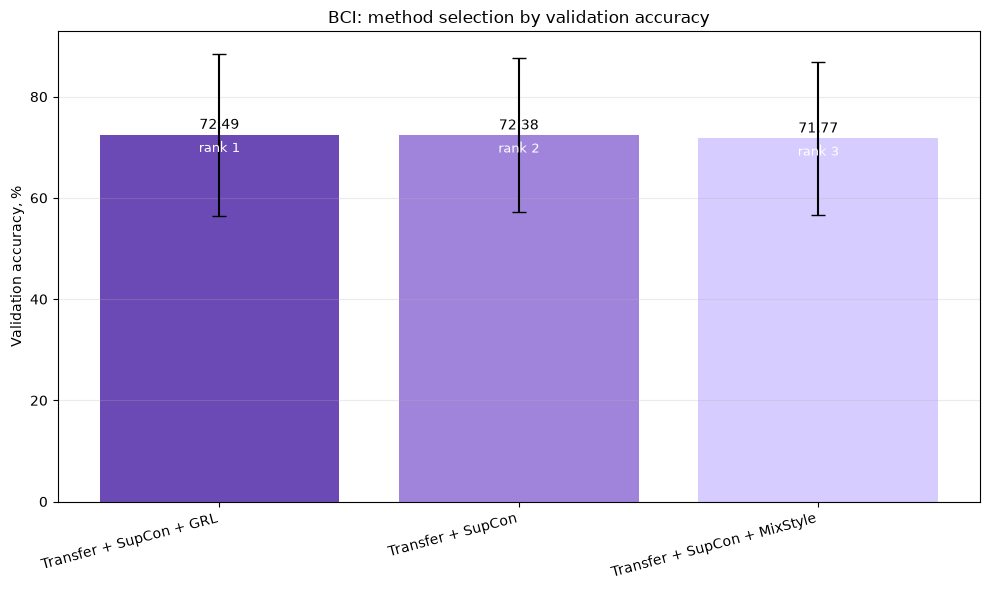

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/final_plots/02_bci_test_accuracy.png


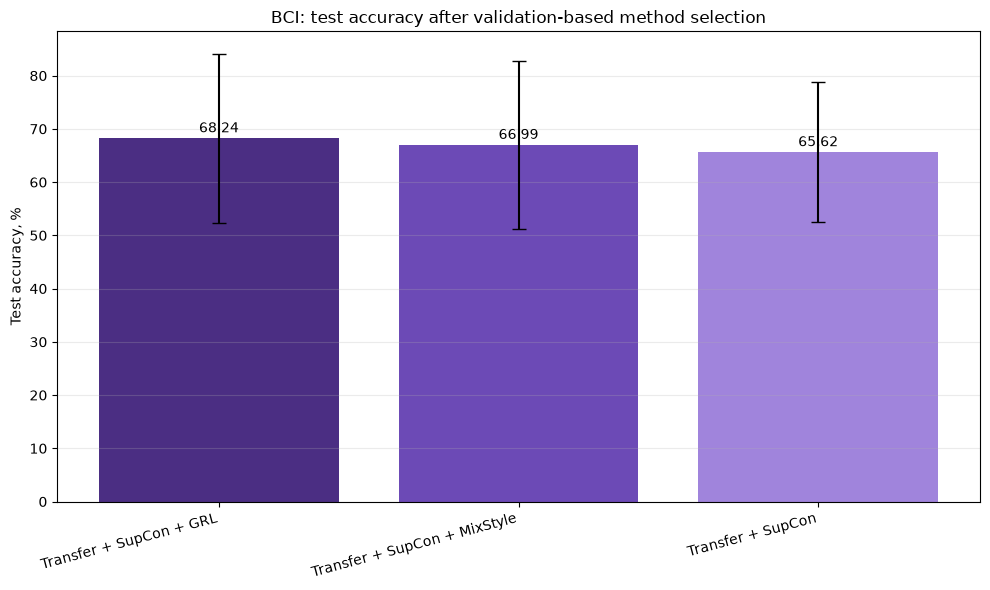

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/final_plots/03_bci_seed_stability.png


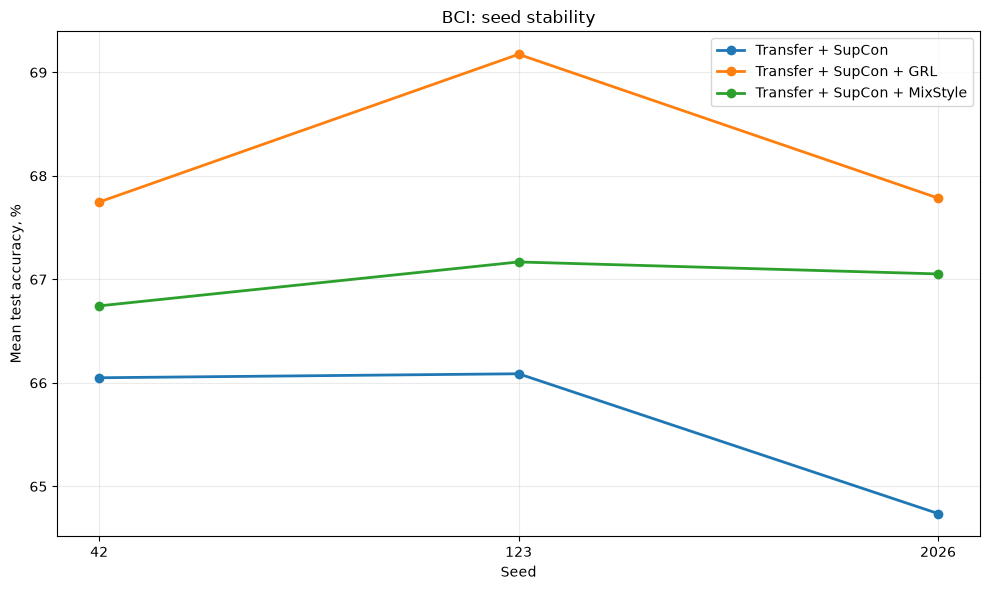

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/final_plots/04_bci_vs_physionet_final.png


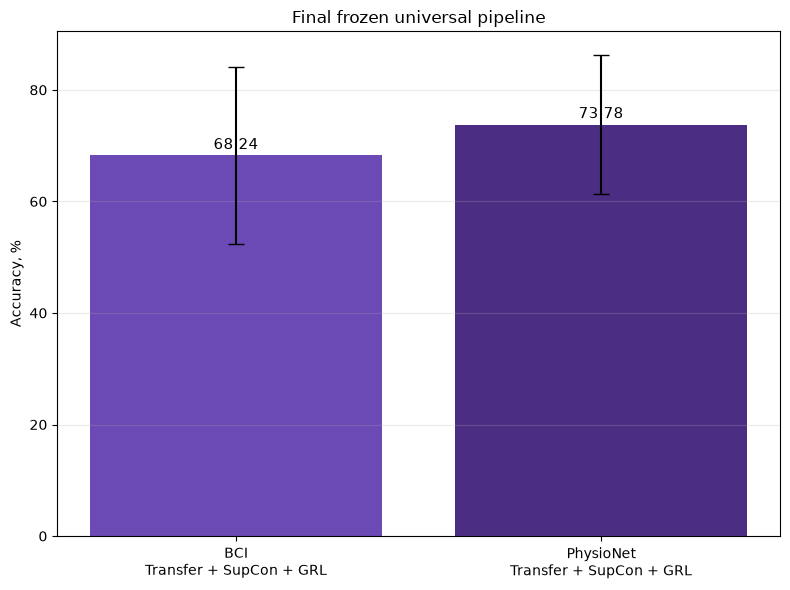

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/final_plots/05_physionet_fold_curve.png


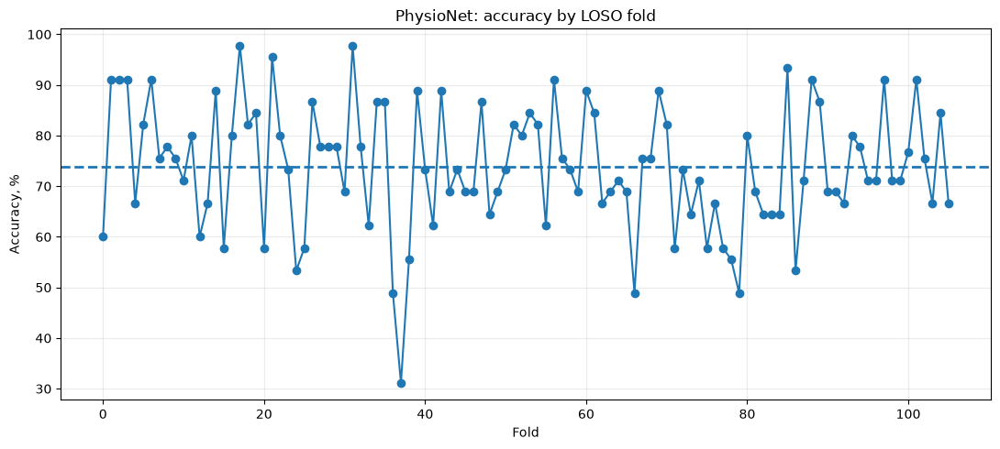

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/final_plots/06_physionet_fold_hist.png


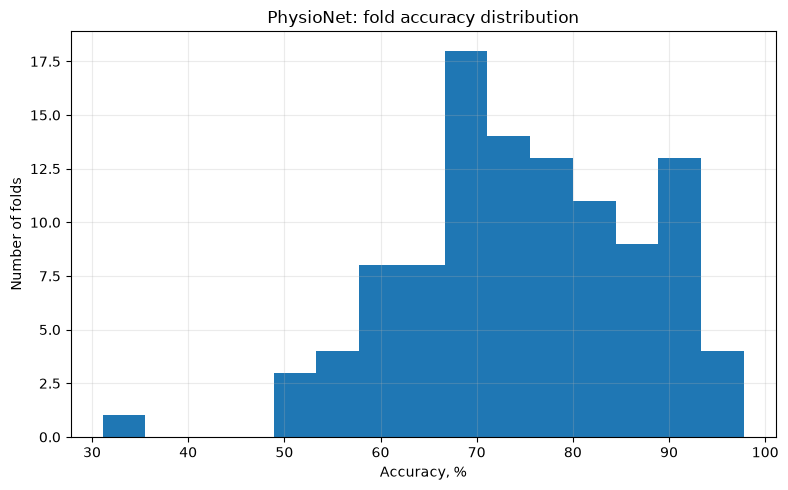


FINAL PLOT SUMMARY


,dataset,method,validation_accuracy_pct,test_accuracy_pct,test_std_pct
0,BCI,Transfer + SupCon + GRL,72.4923,68.2356,15.8815
1,BCI,Transfer + SupCon,72.3765,65.6250,13.0911
2,BCI,Transfer + SupCon + MixStyle,71.7721,66.9882,15.7544
3,PhysioNet,Transfer + SupCon + GRL,NaN,73.7848,12.4050



Saved files:
  01_bci_validation_ranking.png
  02_bci_test_accuracy.png
  03_bci_seed_stability.png
  04_bci_vs_physionet_final.png
  05_physionet_fold_curve.png
  06_physionet_fold_hist.png
  final_plot_summary.csv


In [ ]:
# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
BASE_DIR = Path("/Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline")
BCI_DIR = BASE_DIR / "bci_multiseed"
PHYS_DIR = BASE_DIR / "physionet_frozen_recipe"
PLOT_DIR = BASE_DIR / "final_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

BCI_MULTISED_CSV = BCI_DIR / "bci_multiseed_results.csv"
BCI_SELECTION_CSV = BCI_DIR / "bci_method_selection_summary.csv"
PHYS_CSV = PHYS_DIR / "physionet_frozen_recipe_results.csv"

print("BCI multiseed:", BCI_MULTISED_CSV)
print("BCI selection:", BCI_SELECTION_CSV)
print("PhysioNet:", PHYS_CSV)
print("Plots:", PLOT_DIR)

# ------------------------------------------------------------
# COLORS
# ------------------------------------------------------------
CLR_MAIN = "#6C4AB6"
CLR_ALT = "#A084DC"
CLR_LIGHT = "#D6CCFF"
CLR_DARK = "#4B2E83"
CLR_GRAY = "#9E9E9E"

# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------
def pick_col(df, candidates, required=True):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"None of columns found: {candidates}\nAvailable: {list(df.columns)}")
    return None

def to_pct(series):
    s = pd.to_numeric(series, errors="coerce")
    if s.dropna().empty:
        return s
    # если метрика хранится как 0..1 -> переводим в %
    if s.dropna().max() <= 1.5:
        return s * 100.0
    return s

def beautify_method(name):
    mapping = {
        "transfer_supcon_control": "Transfer + SupCon",
        "transfer_supcon_grl": "Transfer + SupCon + GRL",
        "transfer_supcon_mixstyle": "Transfer + SupCon + MixStyle",
        "transfer_supcon_grl_mixstyle": "Transfer + SupCon + GRL + MixStyle",
        "transfer": "Transfer",
        "transfer_supcon": "Transfer + SupCon",
    }
    return mapping.get(str(name), str(name))

def savefig(name):
    path = PLOT_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=180, bbox_inches="tight")
    print("Saved:", path)

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------
bci_runs = pd.read_csv(BCI_MULTISED_CSV)
bci_sel = pd.read_csv(BCI_SELECTION_CSV)
phys = pd.read_csv(PHYS_CSV)

print("\nLoaded:")
print("bci_runs:", bci_runs.shape)
print("bci_sel:", bci_sel.shape)
print("phys:", phys.shape)

# ------------------------------------------------------------
# NORMALIZE COLUMNS
# ------------------------------------------------------------
# BCI selection summary
sel_method_col = pick_col(bci_sel, ["method"])
sel_rank_col = pick_col(bci_sel, ["validation_rank"], required=False)
sel_val_mean_col = pick_col(bci_sel, ["mean_validation_accuracy_pct", "mean_validation_accuracy"])
sel_val_std_col = pick_col(bci_sel, ["std_validation_accuracy_pct", "std_validation_accuracy"], required=False)
sel_test_mean_col = pick_col(bci_sel, ["mean_test_accuracy_pct", "mean_test_accuracy"])
sel_test_std_col = pick_col(bci_sel, ["std_test_accuracy_pct", "std_test_accuracy"], required=False)
sel_val_f1_col = pick_col(bci_sel, ["mean_validation_f1", "mean_val_f1"], required=False)
sel_test_f1_col = pick_col(bci_sel, ["mean_test_f1", "mean_macro_f1"], required=False)

bci_sel = bci_sel.copy()
bci_sel["val_mean_pct"] = to_pct(bci_sel[sel_val_mean_col])
bci_sel["test_mean_pct"] = to_pct(bci_sel[sel_test_mean_col])
if sel_val_std_col is not None:
    bci_sel["val_std_pct"] = to_pct(bci_sel[sel_val_std_col])
else:
    bci_sel["val_std_pct"] = np.nan
if sel_test_std_col is not None:
    bci_sel["test_std_pct"] = to_pct(bci_sel[sel_test_std_col])
else:
    bci_sel["test_std_pct"] = np.nan

bci_sel["method_label"] = bci_sel[sel_method_col].map(beautify_method)

# BCI multiseed results
run_method_col = pick_col(bci_runs, ["method"])
run_seed_col = pick_col(bci_runs, ["seed", "seed_base"], required=False)
run_val_col = pick_col(
    bci_runs,
    ["best_val_accuracy", "val_accuracy", "mean_val_accuracy", "best_val_acc"],
    required=False
)
run_test_col = pick_col(
    bci_runs,
    ["test_accuracy", "accuracy", "mean_test_accuracy", "best_test_accuracy"],
    required=False
)

bci_runs = bci_runs.copy()
bci_runs["method_label"] = bci_runs[run_method_col].map(beautify_method)
if run_val_col is not None:
    bci_runs["val_pct"] = to_pct(bci_runs[run_val_col])
if run_test_col is not None:
    bci_runs["test_pct"] = to_pct(bci_runs[run_test_col])

# PhysioNet
phys = phys.copy()
phys_method_col = pick_col(phys, ["method"], required=False)
phys_test_col = pick_col(
    phys,
    ["mean_accuracy_pct", "accuracy_pct", "accuracy", "test_accuracy", "mean_test_accuracy"],
    required=False
)
phys_std_col = pick_col(
    phys,
    ["std_accuracy_pct", "std_accuracy", "std_test_accuracy_pct", "std_test_accuracy"],
    required=False
)

if phys_test_col is not None:
    phys["accuracy_pct_norm"] = to_pct(phys[phys_test_col])
if phys_std_col is not None:
    phys["std_pct_norm"] = to_pct(phys[phys_std_col])

# ------------------------------------------------------------
# 1. BCI METHOD SELECTION — VALIDATION RANKING
# ------------------------------------------------------------
plot_df = bci_sel.sort_values("val_mean_pct", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
x = np.arange(len(plot_df))
y = plot_df["val_mean_pct"].values
err = plot_df["val_std_pct"].values if "val_std_pct" in plot_df else None

bars = plt.bar(
    x,
    y,
    yerr=err,
    capsize=5,
    color=[CLR_MAIN, CLR_ALT, CLR_LIGHT][:len(plot_df)]
)

plt.xticks(x, plot_df["method_label"], rotation=15, ha="right")
plt.ylabel("Validation accuracy, %")
plt.title("BCI: method selection by validation accuracy")

for i, v in enumerate(y):
    plt.text(i, v + 0.5, f"{v:.2f}", ha="center", va="bottom", fontsize=10)

if sel_rank_col is not None:
    for i, r in enumerate(plot_df[sel_rank_col]):
        plt.text(i, y[i] - 4, f"rank {int(r)}", ha="center", va="bottom", fontsize=9, color="white")

plt.grid(axis="y", alpha=0.25)
savefig("01_bci_validation_ranking.png")
plt.show()

# ------------------------------------------------------------
# 2. BCI METHOD SELECTION — TEST ACCURACY
# ------------------------------------------------------------
plot_df = bci_sel.sort_values("test_mean_pct", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
x = np.arange(len(plot_df))
y = plot_df["test_mean_pct"].values
err = plot_df["test_std_pct"].values if "test_std_pct" in plot_df else None

plt.bar(
    x,
    y,
    yerr=err,
    capsize=5,
    color=[CLR_DARK, CLR_MAIN, CLR_ALT][:len(plot_df)]
)

plt.xticks(x, plot_df["method_label"], rotation=15, ha="right")
plt.ylabel("Test accuracy, %")
plt.title("BCI: test accuracy after validation-based method selection")

for i, v in enumerate(y):
    plt.text(i, v + 0.5, f"{v:.2f}", ha="center", va="bottom", fontsize=10)

plt.grid(axis="y", alpha=0.25)
savefig("02_bci_test_accuracy.png")
plt.show()

# ------------------------------------------------------------
# 3. BCI SEED STABILITY
# ------------------------------------------------------------
if run_seed_col is not None and run_test_col is not None:
    seed_df = (
        bci_runs.groupby([run_method_col, run_seed_col], as_index=False)["test_pct"]
        .mean()
        .rename(columns={run_method_col: "method", run_seed_col: "seed"})
    )
    seed_df["method_label"] = seed_df["method"].map(beautify_method)

    plt.figure(figsize=(10, 6))

    for method, g in seed_df.groupby("method_label"):
        g = g.sort_values("seed")
        plt.plot(
            g["seed"].astype(str),
            g["test_pct"],
            marker="o",
            linewidth=2,
            label=method
        )

    plt.ylabel("Mean test accuracy, %")
    plt.xlabel("Seed")
    plt.title("BCI: seed stability")
    plt.grid(alpha=0.25)
    plt.legend()
    savefig("03_bci_seed_stability.png")
    plt.show()

# ------------------------------------------------------------
# 4. BCI WINNER VS PHYSIONET FROZEN PIPELINE
# ------------------------------------------------------------
winner_row = bci_sel.sort_values("val_mean_pct", ascending=False).iloc[0]
winner_method = winner_row["method_label"]
bci_winner_test = winner_row["test_mean_pct"]
bci_winner_std = winner_row["test_std_pct"] if "test_std_pct" in winner_row else np.nan

# PhysioNet summary
if "accuracy_pct_norm" in phys.columns:
    if len(phys) == 1:
        phys_mean = float(phys["accuracy_pct_norm"].iloc[0])
        phys_std = float(phys["std_pct_norm"].iloc[0]) if "std_pct_norm" in phys.columns else np.nan
        phys_label = winner_method
    else:
        # если там построчные результаты, усредняем
        phys_mean = float(phys["accuracy_pct_norm"].mean())
        phys_std = float(phys["accuracy_pct_norm"].std())
        if phys_method_col is not None and phys[phys_method_col].nunique() == 1:
            phys_label = beautify_method(phys[phys_method_col].iloc[0])
        else:
            phys_label = "Frozen pipeline"

    plt.figure(figsize=(8, 6))
    labels = [f"BCI\n{winner_method}", f"PhysioNet\n{phys_label}"]
    vals = [bci_winner_test, phys_mean]
    errs = [
        0 if pd.isna(bci_winner_std) else bci_winner_std,
        0 if pd.isna(phys_std) else phys_std,
    ]

    plt.bar(
        np.arange(2),
        vals,
        yerr=errs,
        capsize=6,
        color=[CLR_MAIN, CLR_DARK]
    )
    plt.xticks(np.arange(2), labels)
    plt.ylabel("Accuracy, %")
    plt.title("Final frozen universal pipeline")

    for i, v in enumerate(vals):
        plt.text(i, v + 0.5, f"{v:.2f}", ha="center", va="bottom", fontsize=11)

    plt.grid(axis="y", alpha=0.25)
    savefig("04_bci_vs_physionet_final.png")
    plt.show()

# ------------------------------------------------------------
# 5. PHYSIONET FOLD DISTRIBUTION (если есть построчные fold-результаты)
# ------------------------------------------------------------
phys_fold_col = pick_col(phys, ["fold", "test_subject"], required=False)

if phys_fold_col is not None and "accuracy_pct_norm" in phys.columns and len(phys) > 1:
    phys_fold_df = phys.copy()

    plt.figure(figsize=(11, 5))
    order_x = np.arange(len(phys_fold_df))
    plt.plot(order_x, phys_fold_df["accuracy_pct_norm"].values, marker="o", linewidth=1.5)
    plt.axhline(phys_fold_df["accuracy_pct_norm"].mean(), linestyle="--", linewidth=2)

    plt.xlabel("Fold")
    plt.ylabel("Accuracy, %")
    plt.title("PhysioNet: accuracy by LOSO fold")
    plt.grid(alpha=0.25)
    savefig("05_physionet_fold_curve.png")
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.hist(phys_fold_df["accuracy_pct_norm"].dropna().values, bins=15)
    plt.xlabel("Accuracy, %")
    plt.ylabel("Number of folds")
    plt.title("PhysioNet: fold accuracy distribution")
    plt.grid(alpha=0.25)
    savefig("06_physionet_fold_hist.png")
    plt.show()

# ------------------------------------------------------------
# 6. COMBINED TABLE FOR QUICK VIEW
# ------------------------------------------------------------
summary_rows = []

for _, row in bci_sel.iterrows():
    summary_rows.append({
        "dataset": "BCI",
        "method": row["method_label"],
        "validation_accuracy_pct": row["val_mean_pct"],
        "test_accuracy_pct": row["test_mean_pct"],
        "test_std_pct": row["test_std_pct"] if "test_std_pct" in row else np.nan,
    })

if phys_method_col is not None and "accuracy_pct_norm" in phys.columns:
    if len(phys) == 1:
        summary_rows.append({
            "dataset": "PhysioNet",
            "method": beautify_method(phys[phys_method_col].iloc[0]) if phys_method_col in phys.columns else "Frozen pipeline",
            "validation_accuracy_pct": np.nan,
            "test_accuracy_pct": phys["accuracy_pct_norm"].iloc[0],
            "test_std_pct": phys["std_pct_norm"].iloc[0] if "std_pct_norm" in phys.columns else np.nan,
        })
    else:
        summary_rows.append({
            "dataset": "PhysioNet",
            "method": beautify_method(phys[phys_method_col].iloc[0]) if phys_method_col in phys.columns and phys[phys_method_col].nunique() == 1 else "Frozen pipeline",
            "validation_accuracy_pct": np.nan,
            "test_accuracy_pct": phys["accuracy_pct_norm"].mean(),
            "test_std_pct": phys["accuracy_pct_norm"].std(),
        })

summary_df = pd.DataFrame(summary_rows)
summary_csv = PLOT_DIR / "final_plot_summary.csv"
summary_df.to_csv(summary_csv, index=False)

print("\nFINAL PLOT SUMMARY")
display(summary_df.round(4))

print("\nSaved files:")
for p in sorted(PLOT_DIR.glob("*.png")):
    print(" ", p.name)
print(" ", summary_csv.name)

Plots -> /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/comparison_plots

RESULT TABLE


dataset,BCI,PhysioNet
method,,
Transfer,65.9722,73.4913
Transfer + SupCon,66.4738,73.8677
Transfer + SupCon + GRL,68.2366,73.7848
Transfer + SupCon + MixStyle,66.9882,NaN
Transfer + SupCon + GRL + MixStyle,65.2006,NaN


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/comparison_plots/all_methods_two_datasets_sota_lines.png


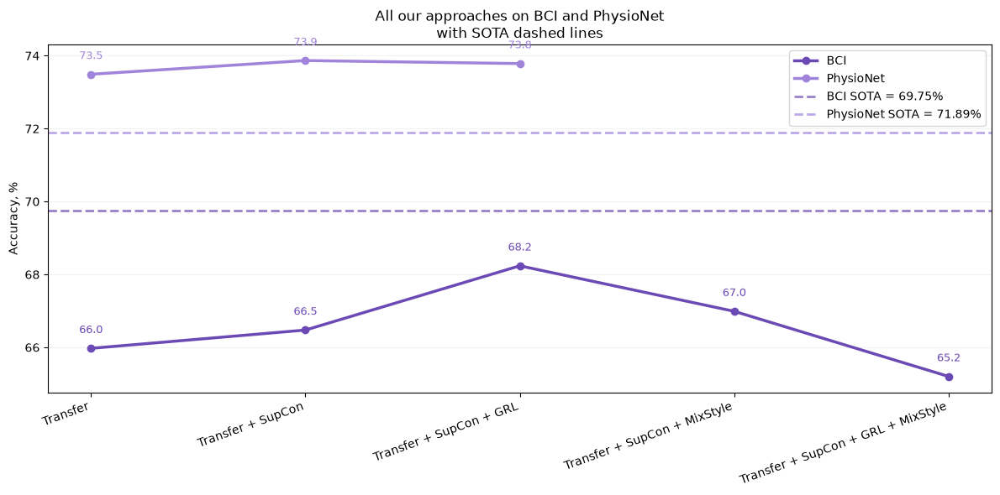

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/comparison_plots/bci_all_methods_vs_sota.png


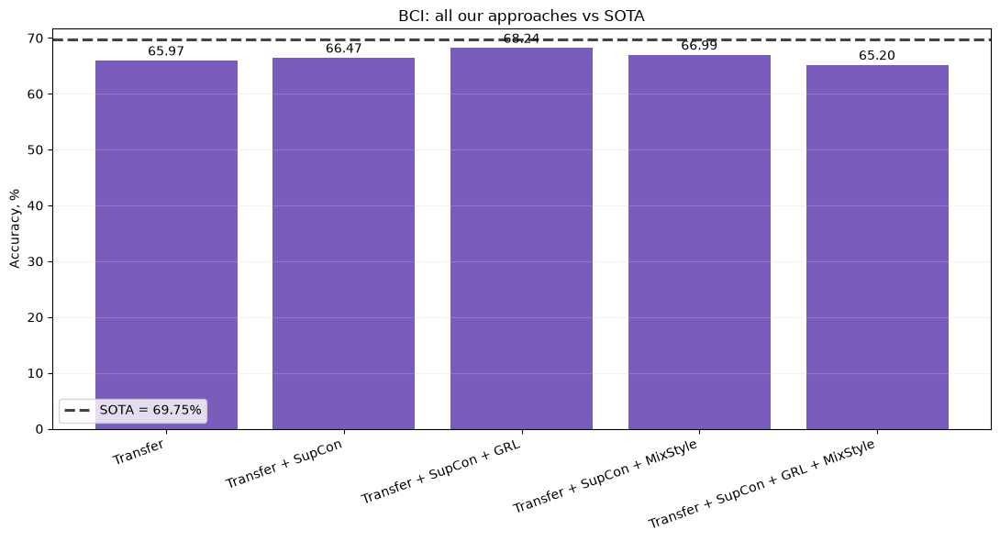

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/comparison_plots/physionet_all_methods_vs_sota.png


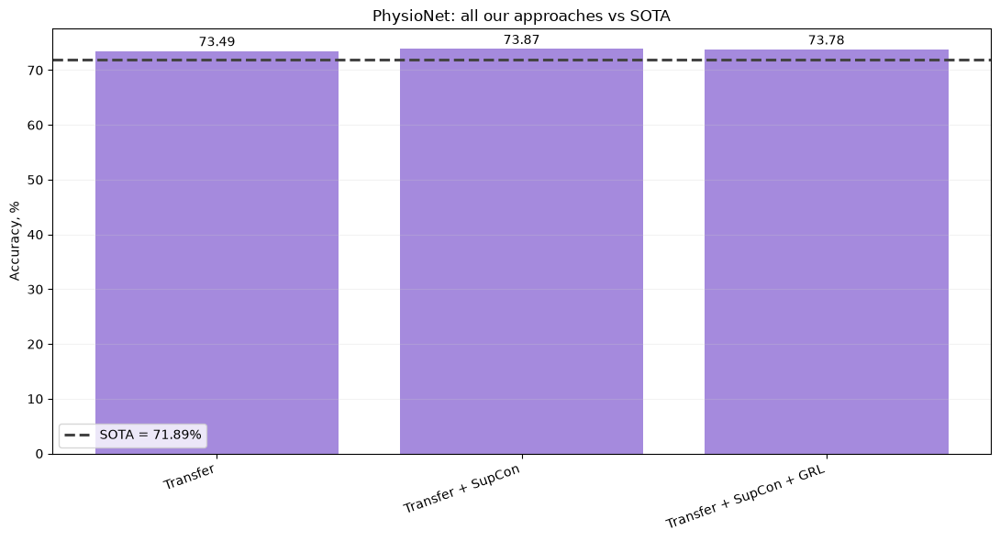


GAP TO SOTA


,dataset,method,accuracy,sota,gap_to_sota_pp
2,BCI,Transfer + SupCon + GRL,68.2366,69.75,-1.5134
3,BCI,Transfer + SupCon + MixStyle,66.9882,69.75,-2.7618
1,BCI,Transfer + SupCon,66.4738,69.75,-3.2762
0,BCI,Transfer,65.9722,69.75,-3.7778
4,BCI,Transfer + SupCon + GRL + MixStyle,65.2006,69.75,-4.5494
6,PhysioNet,Transfer + SupCon,73.8677,71.89,1.9777
7,PhysioNet,Transfer + SupCon + GRL,73.7848,71.89,1.8948
5,PhysioNet,Transfer,73.4913,71.89,1.6013


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/comparison_plots/gap_to_sota.csv


In [134]:
# ------------------------------------------------------------
# SAVE DIR
# ------------------------------------------------------------
BASE_DIR = Path("/Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline")
PLOT_DIR = BASE_DIR / "comparison_plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Plots ->", PLOT_DIR)

# ------------------------------------------------------------
# OUR RESULTS
# accuracy in %
# ------------------------------------------------------------
rows = [
    # ---------------- BCI ----------------
    {"dataset": "BCI", "method": "Transfer",                             "accuracy": 65.9722},
    {"dataset": "BCI", "method": "Transfer + SupCon",                    "accuracy": 66.4738},
    {"dataset": "BCI", "method": "Transfer + SupCon + GRL",              "accuracy": 68.2366},
    {"dataset": "BCI", "method": "Transfer + SupCon + MixStyle",         "accuracy": 66.9882},
    {"dataset": "BCI", "method": "Transfer + SupCon + GRL + MixStyle",   "accuracy": 65.2006},  # BCI-only mini ablation

    # -------------- PhysioNet --------------
    {"dataset": "PhysioNet", "method": "Transfer",                       "accuracy": 73.4913},
    {"dataset": "PhysioNet", "method": "Transfer + SupCon",              "accuracy": 73.8677},
    {"dataset": "PhysioNet", "method": "Transfer + SupCon + GRL",        "accuracy": 73.7848},

    # если потом запустишь эти варианты на PhysioNet — просто раскомментируй/добавь:
    # {"dataset": "PhysioNet", "method": "Transfer + SupCon + MixStyle",       "accuracy": ...},
    # {"dataset": "PhysioNet", "method": "Transfer + SupCon + GRL + MixStyle", "accuracy": ...},
]

df = pd.DataFrame(rows)

# ------------------------------------------------------------
# SOTA LINES
# ------------------------------------------------------------
# BCI best literature ref from your earlier table
# PhysioNet best literature ref from your earlier table
sota = {
    "BCI": 69.75,
    "PhysioNet": 71.89,
}

# ------------------------------------------------------------
# METHOD ORDER
# ------------------------------------------------------------
method_order = [
    "Transfer",
    "Transfer + SupCon",
    "Transfer + SupCon + GRL",
    "Transfer + SupCon + MixStyle",
    "Transfer + SupCon + GRL + MixStyle",
]

dataset_order = ["BCI", "PhysioNet"]

# ------------------------------------------------------------
# COLORS
# ------------------------------------------------------------
CLR_BCI = "#6C4AB6"
CLR_PHYS = "#A084DC"
CLR_SOTA = "#444444"
CLR_GRID = "#CCCCCC"

# ------------------------------------------------------------
# TABLE
# ------------------------------------------------------------
pivot_df = (
    df.pivot(index="method", columns="dataset", values="accuracy")
      .reindex(method_order)
)

print("\nRESULT TABLE")
display(pivot_df.round(4))

# ============================================================
# 1) COMBINED LINE PLOT
# ============================================================
plt.figure(figsize=(12, 6))

x = np.arange(len(method_order))

bci_vals = pivot_df["BCI"].values if "BCI" in pivot_df.columns else np.full(len(method_order), np.nan)
phys_vals = pivot_df["PhysioNet"].values if "PhysioNet" in pivot_df.columns else np.full(len(method_order), np.nan)

plt.plot(x, bci_vals, marker="o", linewidth=2.5, label="BCI", color=CLR_BCI)
plt.plot(x, phys_vals, marker="o", linewidth=2.5, label="PhysioNet", color=CLR_PHYS)

plt.axhline(sota["BCI"], linestyle="--", linewidth=2, color=CLR_BCI, alpha=0.7, label=f"BCI SOTA = {sota['BCI']:.2f}%")
plt.axhline(sota["PhysioNet"], linestyle="--", linewidth=2, color=CLR_PHYS, alpha=0.7, label=f"PhysioNet SOTA = {sota['PhysioNet']:.2f}%")

for i, y in enumerate(bci_vals):
    if pd.notna(y):
        plt.text(i, y + 0.35, f"{y:.1f}", ha="center", va="bottom", fontsize=9, color=CLR_BCI)

for i, y in enumerate(phys_vals):
    if pd.notna(y):
        plt.text(i, y + 0.35, f"{y:.1f}", ha="center", va="bottom", fontsize=9, color=CLR_PHYS)

plt.xticks(x, method_order, rotation=20, ha="right")
plt.ylabel("Accuracy, %")
plt.title("All our approaches on BCI and PhysioNet\nwith SOTA dashed lines")
plt.grid(axis="y", alpha=0.25, color=CLR_GRID)
plt.legend()
plt.tight_layout()

combined_path = PLOT_DIR / "all_methods_two_datasets_sota_lines.png"
plt.savefig(combined_path, dpi=180, bbox_inches="tight")
print("Saved:", combined_path)
plt.show()

# ============================================================
# 2) BCI ONLY
# ============================================================
bci_only = (
    df[df["dataset"] == "BCI"]
    .set_index("method")
    .reindex(method_order)
    .reset_index()
)

plt.figure(figsize=(11, 6))
x = np.arange(len(bci_only))
y = bci_only["accuracy"].values

bars = plt.bar(x, y, color=CLR_BCI, alpha=0.9)
plt.axhline(sota["BCI"], linestyle="--", linewidth=2.2, color=CLR_SOTA, label=f"SOTA = {sota['BCI']:.2f}%")

for i, v in enumerate(y):
    if pd.notna(v):
        plt.text(i, v + 0.35, f"{v:.2f}", ha="center", va="bottom", fontsize=10)

plt.xticks(x, bci_only["method"], rotation=20, ha="right")
plt.ylabel("Accuracy, %")
plt.title("BCI: all our approaches vs SOTA")
plt.grid(axis="y", alpha=0.25, color=CLR_GRID)
plt.legend()
plt.tight_layout()

bci_path = PLOT_DIR / "bci_all_methods_vs_sota.png"
plt.savefig(bci_path, dpi=180, bbox_inches="tight")
print("Saved:", bci_path)
plt.show()

# ============================================================
# 3) PHYSIONET ONLY
# ============================================================
phys_only = (
    df[df["dataset"] == "PhysioNet"]
    .set_index("method")
    .reindex(method_order)
    .reset_index()
)

plt.figure(figsize=(11, 6))
x = np.arange(len(phys_only))
y = phys_only["accuracy"].values

mask = ~pd.isna(y)
plt.bar(np.arange(mask.sum()), y[mask], color=CLR_PHYS, alpha=0.95)

shown_labels = phys_only.loc[mask, "method"].tolist()

for i, v in enumerate(y[mask]):
    plt.text(i, v + 0.35, f"{v:.2f}", ha="center", va="bottom", fontsize=10)

plt.axhline(sota["PhysioNet"], linestyle="--", linewidth=2.2, color=CLR_SOTA, label=f"SOTA = {sota['PhysioNet']:.2f}%")

plt.xticks(np.arange(mask.sum()), shown_labels, rotation=20, ha="right")
plt.ylabel("Accuracy, %")
plt.title("PhysioNet: all our approaches vs SOTA")
plt.grid(axis="y", alpha=0.25, color=CLR_GRID)
plt.legend()
plt.tight_layout()

phys_path = PLOT_DIR / "physionet_all_methods_vs_sota.png"
plt.savefig(phys_path, dpi=180, bbox_inches="tight")
print("Saved:", phys_path)
plt.show()

# ============================================================
# 4) GAP TO SOTA TABLE
# ============================================================
gap_rows = []
for _, row in df.iterrows():
    gap_rows.append({
        "dataset": row["dataset"],
        "method": row["method"],
        "accuracy": row["accuracy"],
        "sota": sota[row["dataset"]],
        "gap_to_sota_pp": row["accuracy"] - sota[row["dataset"]],
    })

gap_df = pd.DataFrame(gap_rows).sort_values(["dataset", "gap_to_sota_pp"], ascending=[True, False])

print("\nGAP TO SOTA")
display(gap_df.round(4))

gap_path = PLOT_DIR / "gap_to_sota.csv"
gap_df.to_csv(gap_path, index=False)
print("Saved:", gap_path)

In [137]:
# ============================================================
# BUILD ONE RESULT CATALOG FROM ALL RECENT EXPERIMENTS
#
# Ищем результаты в results_v2,
# извлекаем subject-level CLEAN/test accuracy,
# объединяем разные эксперименты в единую таблицу.
# ============================================================


ROOT = Path(
    "/Users/irina/Desktop/master project/results_v2"
)

OUT_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "all_methods_plots"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 1. ПОКАЗЫВАЕМ ВСЕ CSV, КОТОРЫЕ ВООБЩЕ ЕСТЬ
# ============================================================

all_csvs = sorted(
    ROOT.rglob("*.csv")
)

print(
    "CSV found:",
    len(all_csvs)
)

for p in all_csvs:
    print(
        p.relative_to(ROOT)
    )

# ============================================================
# 2. HELPERS
# ============================================================

def norm_dataset(x):

    x = str(x).lower()

    if "bci" in x:
        return "BCI"

    if "phys" in x:
        return "PhysioNet"

    return None


def pretty_method(x):

    x = str(x).lower().strip()

    mapping = {

        # original classifier family
        "baseline":
            "Baseline",

        "transfer":
            "Cho Transfer",

        "supcon":
            "SupCon",

        "transfer_supcon":
            "Cho Transfer + SupCon",

        # alignment experiments
        "coral":
            "Cho Transfer + CORAL",

        "transfer_coral":
            "Cho Transfer + CORAL",

        "mmd":
            "Cho Transfer + MMD",

        "transfer_mmd":
            "Cho Transfer + MMD",

        # subject invariant
        "transfer_supcon_control":
            "Cho Transfer + SupCon",

        "transfer_supcon_grl":
            "Cho Transfer + SupCon + GRL",

        "transfer_supcon_mixstyle":
            "Cho Transfer + SupCon + MixStyle",

        "transfer_supcon_grl_mixstyle":
            "Cho Transfer + SupCon + GRL + MixStyle",
    }

    return mapping.get(
        x,
        str(x)
    )


def find_col(
    df,
    variants,
):

    lower = {
        c.lower(): c
        for c in df.columns
    }

    for name in variants:

        if name.lower() in lower:
            return lower[
                name.lower()
            ]

    return None


def normalize_accuracy(
    s,
):

    s = pd.to_numeric(
        s,
        errors="coerce",
    )

    if (
        len(
            s.dropna()
        )
        and
        s.dropna().max()
        <= 1.5
    ):
        return (
            s * 100
        )

    return s



CSV found: 589
ablation_task_informed/A01_FULL_history.csv
ablation_task_informed/A01_MSE_COV_history.csv
ablation_task_informed/A01_MSE_PSD_history.csv
ablation_task_informed/A01_MSE_history.csv
ablation_task_informed/A02_FULL_history.csv
ablation_task_informed/A02_MSE_COV_history.csv
ablation_task_informed/A02_MSE_PSD_history.csv
ablation_task_informed/A02_MSE_history.csv
ablation_task_informed/A03_FULL_history.csv
ablation_task_informed/A03_MSE_COV_history.csv
ablation_task_informed/A03_MSE_PSD_history.csv
ablation_task_informed/A03_MSE_history.csv
ablation_task_informed/A04_FULL_history.csv
ablation_task_informed/A04_MSE_COV_history.csv
ablation_task_informed/A04_MSE_PSD_history.csv
ablation_task_informed/A04_MSE_history.csv
ablation_task_informed/A05_FULL_history.csv
ablation_task_informed/A05_MSE_COV_history.csv
ablation_task_informed/A05_MSE_PSD_history.csv
ablation_task_informed/A05_MSE_history.csv
ablation_task_informed/A06_FULL_history.csv
ablation_task_informed/A06_MSE_COV_h

In [138]:
# ============================================================
# 3. EXTRACT SUBJECT-LEVEL CLASSIFICATION RESULTS
# ============================================================

catalog_rows = []


for path in all_csvs:

    try:
        d = pd.read_csv(
            path
        )
    except Exception:
        continue


    if len(d) == 0:
        continue


    # --------------------------------------------------------
    # Не берём histories:
    # там epochs, а не независимые test subjects.
    # --------------------------------------------------------

    path_text = str(
        path
    ).lower()

    if (
        "/histories/" in path_text
        or "history" in path.name.lower()
    ):
        continue


    method_col = find_col(
        d,
        [
            "method",
            "model",
            "approach",
        ]
    )

    acc_col = find_col(
        d,
        [
            "accuracy",
            "test_accuracy",
            "mean_accuracy",
            "mean_test_accuracy",
        ]
    )

    dataset_col = find_col(
        d,
        [
            "dataset",
        ]
    )


    if (
        method_col is None
        or
        acc_col is None
    ):
        continue


    # --------------------------------------------------------
    # Из summary CSV не хотим получать один pseudo-subject,
    # если рядом существует subject-level result.
    #
    # Для начала собираем только файлы, где видим subject/fold.
    # --------------------------------------------------------

    subject_col = find_col(
        d,
        [
            "test_subject",
            "subject",
            "subject_id",
        ]
    )

    fold_col = find_col(
        d,
        [
            "fold",
        ]
    )


    if (
        subject_col is None
        and
        fold_col is None
    ):
        continue


    tmp = d.copy()


    # --------------------------------------------------------
    # CLEAN ONLY
    #
    # В старом 4-condition эксперименте оставляем только clean.
    # noisy/denoised пойдут на отдельный график.
    # --------------------------------------------------------

    condition_col = find_col(
        tmp,
        [
            "condition",
        ]
    )

    if condition_col is not None:

        clean_mask = (
            tmp[
                condition_col
            ]
            .astype(str)
            .str.lower()
            .eq("clean")
        )

        if clean_mask.any():

            tmp = tmp[
                clean_mask
            ].copy()

        else:

            # файл содержит только noisy/denoising results
            # для SOTA-графика его пропускаем
            continue


    if len(tmp) == 0:
        continue


    # --------------------------------------------------------
    # dataset
    # --------------------------------------------------------

    if dataset_col is not None:

        tmp["_dataset"] = (
            tmp[
                dataset_col
            ]
            .map(
                norm_dataset
            )
        )

    else:

        # пытаемся определить по пути
        dataset_guess = norm_dataset(
            str(path)
        )

        tmp["_dataset"] = (
            dataset_guess
        )


    # --------------------------------------------------------
    # method
    # --------------------------------------------------------

    tmp["_method"] = (
        tmp[
            method_col
        ]
        .map(
            pretty_method
        )
    )


    tmp["_accuracy"] = (
        normalize_accuracy(
            tmp[
                acc_col
            ]
        )
    )


    if subject_col is not None:

        tmp["_subject"] = (
            tmp[
                subject_col
            ]
            .astype(str)
        )

    else:

        tmp["_subject"] = (
            tmp[
                fold_col
            ]
            .astype(str)
        )


    tmp["_source_file"] = str(
        path.relative_to(
            ROOT
        )
    )


    for _, row in tmp.iterrows():

        if (
            row["_dataset"]
            in [
                "BCI",
                "PhysioNet",
            ]
            and
            pd.notna(
                row["_accuracy"]
            )
        ):

            catalog_rows.append({

                "dataset":
                    row[
                        "_dataset"
                    ],

                "method":
                    row[
                        "_method"
                    ],

                "subject":
                    row[
                        "_subject"
                    ],

                "accuracy":
                    float(
                        row[
                            "_accuracy"
                        ]
                    ),

                "source_file":
                    row[
                        "_source_file"
                    ],
            })


catalog = pd.DataFrame(
    catalog_rows
)


print()
print("=" * 100)
print("RAW CATALOG")
print("=" * 100)

print(
    "Rows:",
    len(catalog)
)

display(
    catalog.head(
        20
    )
)


RAW CATALOG
Rows: 2304


,dataset,method,subject,accuracy,source_file
0,BCI,Baseline,A01,61.805556,strict_loso_denoising_binary/results/ALL_stric...
1,BCI,Cho Transfer,A01,79.861111,strict_loso_denoising_binary/results/ALL_stric...
2,BCI,SupCon,A01,79.166667,strict_loso_denoising_binary/results/ALL_stric...
3,BCI,Cho Transfer + SupCon,A01,80.902778,strict_loso_denoising_binary/results/ALL_stric...
4,BCI,Baseline,A02,53.472222,strict_loso_denoising_binary/results/ALL_stric...
5,BCI,Cho Transfer,A02,56.944444,strict_loso_denoising_binary/results/ALL_stric...
6,BCI,SupCon,A02,60.763889,strict_loso_denoising_binary/results/ALL_stric...
7,BCI,Cho Transfer + SupCon,A02,55.555556,strict_loso_denoising_binary/results/ALL_stric...
8,BCI,Baseline,A03,73.611111,strict_loso_denoising_binary/results/ALL_stric...
9,BCI,Cho Transfer,A03,92.361111,strict_loso_denoising_binary/results/ALL_stric...


In [139]:
# ============================================================
# 4. CHOOSE CANONICAL RESULT SOURCE
#
# Приоритет:
# 1. multiseed universal experiment
# 2. subject-invariant ablation
# 3. strict_loso frozen/clean experiment
# 4. прочие старые эксперименты
# ============================================================

def source_priority(
    source,
):

    s = source.lower()

    if (
        "universal_subject_invariant_pipeline/"
        "bci_multiseed/"
        in s
    ):
        return 100

    if (
        "subject_invariant_ablation/"
        in s
    ):
        return 90

    if (
        "strict_loso_frozen"
        in s
    ):
        return 80

    if (
        "strict_loso_denoising_binary"
        in s
    ):
        return 70

    if (
        "coral"
        in s
        or
        "mmd"
        in s
    ):
        return 60

    return 10


catalog[
    "priority"
] = (
    catalog[
        "source_file"
    ]
    .map(
        source_priority
    )
)


# ============================================================
# Посмотрим, откуда вообще пришёл каждый метод
# ============================================================

sources = (
    catalog[
        [
            "dataset",
            "method",
            "source_file",
            "priority",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "dataset",
            "method",
            "priority",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
)


print()
print("=" * 100)
print("AVAILABLE METHOD SOURCES")
print("=" * 100)

display(
    sources
)


AVAILABLE METHOD SOURCES


,dataset,method,source_file,priority
0,BCI,Baseline,strict_loso_denoising_binary/results/ALL_stric...,70
460,BCI,Baseline,strict_loso_denoising_binary/results/BCI_full_...,70
496,BCI,Baseline,strict_loso_denoising_binary/results/BCI_progr...,70
1380,BCI,Cho Transfer,strict_loso_frozen_final/strict_loso_frozen_pr...,80
1610,BCI,Cho Transfer,strict_loso_frozen_final/strict_loso_frozen_su...,80
1,BCI,Cho Transfer,strict_loso_denoising_binary/results/ALL_stric...,70
461,BCI,Cho Transfer,strict_loso_denoising_binary/results/BCI_full_...,70
497,BCI,Cho Transfer,strict_loso_denoising_binary/results/BCI_progr...,70
1930,BCI,Cho Transfer + SupCon,universal_subject_invariant_pipeline/bci_multi...,100
2011,BCI,Cho Transfer + SupCon,universal_subject_invariant_pipeline/bci_multi...,100


In [141]:
# ============================================================
# 5. CANONICAL SOURCE PER DATASET × METHOD
# ============================================================

chosen_sources = (
    sources
    .sort_values(
        "priority",
        ascending=False,
    )
    .drop_duplicates(
        subset=[
            "dataset",
            "method",
        ],
        keep="first",
    )
)


canonical_parts = []


for _, choice in chosen_sources.iterrows():

    part = catalog[
        (
            catalog[
                "dataset"
            ]
            == choice[
                "dataset"
            ]
        )
        &
        (
            catalog[
                "method"
            ]
            == choice[
                "method"
            ]
        )
        &
        (
            catalog[
                "source_file"
            ]
            == choice[
                "source_file"
            ]
        )
    ].copy()


    canonical_parts.append(
        part
    )


canonical = pd.concat(
    canonical_parts,
    ignore_index=True,
)


print()
print("=" * 100)
print("CANONICAL DATA")
print("=" * 100)

display(
    canonical[
        [
            "dataset",
            "method",
            "subject",
            "accuracy",
            "source_file",
        ]
    ].head(
        30
    )
)


CANONICAL DATA


,dataset,method,subject,accuracy,source_file
0,BCI,Cho Transfer + SupCon + MixStyle,A01,85.416667,universal_subject_invariant_pipeline/bci_multi...
1,BCI,Cho Transfer + SupCon + MixStyle,A01,77.083333,universal_subject_invariant_pipeline/bci_multi...
2,BCI,Cho Transfer + SupCon + MixStyle,A01,76.041667,universal_subject_invariant_pipeline/bci_multi...
3,BCI,Cho Transfer + SupCon + MixStyle,A02,58.333333,universal_subject_invariant_pipeline/bci_multi...
4,BCI,Cho Transfer + SupCon + MixStyle,A02,56.944444,universal_subject_invariant_pipeline/bci_multi...
5,BCI,Cho Transfer + SupCon + MixStyle,A02,57.986111,universal_subject_invariant_pipeline/bci_multi...
6,BCI,Cho Transfer + SupCon + MixStyle,A03,91.666667,universal_subject_invariant_pipeline/bci_multi...
7,BCI,Cho Transfer + SupCon + MixStyle,A03,93.402778,universal_subject_invariant_pipeline/bci_multi...
8,BCI,Cho Transfer + SupCon + MixStyle,A03,95.138889,universal_subject_invariant_pipeline/bci_multi...
9,BCI,Cho Transfer + SupCon + MixStyle,A04,50.000000,universal_subject_invariant_pipeline/bci_multi...


In [142]:
# ============================================================
# 6. FINAL METHOD SUMMARY
# ============================================================

method_summary = (
    canonical
    .groupby(
        [
            "dataset",
            "method",
        ],
        as_index=False,
    )
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean",
        ),

        std_accuracy=(
            "accuracy",
            "std",
        ),

        median_accuracy=(
            "accuracy",
            "median",
        ),

        n=(
            "accuracy",
            "size",
        ),

        source_file=(
            "source_file",
            "first",
        ),
    )
)


method_summary = (
    method_summary
    .sort_values(
        [
            "dataset",
            "mean_accuracy",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


print()
print("=" * 100)
print("ALL METHODS — CLEAN CLASSIFICATION")
print("=" * 100)

display(
    method_summary.round(
        3
    )
)


method_summary.to_csv(
    OUT_DIR
    / "all_methods_summary.csv",
    index=False,
)


ALL METHODS — CLEAN CLASSIFICATION


,dataset,method,mean_accuracy,std_accuracy,median_accuracy,n,source_file
3,BCI,Cho Transfer + SupCon + GRL,68.236,15.881,64.236,27,universal_subject_invariant_pipeline/bci_multi...
6,BCI,SupCon,67.052,14.800,60.764,9,strict_loso_denoising_binary/results/BCI_progr...
5,BCI,Cho Transfer + SupCon + MixStyle,66.988,15.754,61.806,27,universal_subject_invariant_pipeline/bci_multi...
1,BCI,Cho Transfer,65.972,15.625,65.972,9,strict_loso_frozen_final/strict_loso_frozen_su...
2,BCI,Cho Transfer + SupCon,65.625,13.091,62.847,27,universal_subject_invariant_pipeline/bci_multi...
4,BCI,Cho Transfer + SupCon + GRL + MixStyle,65.201,14.557,57.986,9,subject_invariant_ablation/results/bci_subject...
0,BCI,Baseline,56.559,8.234,53.472,9,strict_loso_denoising_binary/results/ALL_stric...
9,PhysioNet,Cho Transfer + SupCon,73.868,12.085,73.333,106,strict_loso_frozen_final/strict_loso_frozen_pr...
10,PhysioNet,Cho Transfer + SupCon + GRL,73.785,12.405,73.333,106,universal_subject_invariant_pipeline/physionet...
8,PhysioNet,Cho Transfer,73.491,12.723,73.333,106,strict_loso_frozen_final/strict_loso_frozen_su...


DATA USED FOR RESEARCH JOURNEY


,method,mean_accuracy,std_accuracy,n,source_file
0,Baseline,56.559,8.234,9,strict_loso_denoising_binary/results/ALL_stric...
1,Cho Transfer,65.972,15.625,9,strict_loso_frozen_final/strict_loso_frozen_su...
2,SupCon,67.052,14.800,9,strict_loso_denoising_binary/results/BCI_progr...
3,Cho Transfer + SupCon,65.625,13.091,27,universal_subject_invariant_pipeline/bci_multi...
4,Cho Transfer + SupCon + GRL,68.236,15.881,27,universal_subject_invariant_pipeline/bci_multi...
5,Cho Transfer + SupCon + MixStyle,66.988,15.754,27,universal_subject_invariant_pipeline/bci_multi...
6,Cho Transfer + SupCon + GRL + MixStyle,65.201,14.557,9,subject_invariant_ablation/results/bci_subject...


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/research_journey_plots/01_research_journey_bci.png


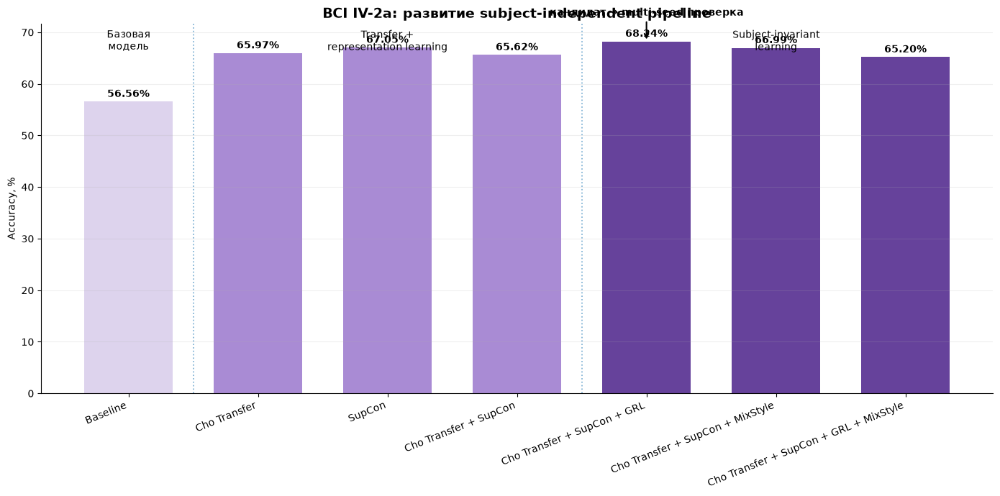

In [143]:
# ============================================================
# FIGURE 1 — RESEARCH JOURNEY
# Evolution of the classification pipeline
#
# Uses existing `method_summary`
# No accuracy values are entered manually
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    "/Users/irina/Desktop/master project/results_v2"
)

JOURNEY_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "research_journey_plots"
)

JOURNEY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Order = логика исследования, а не ranking
# ------------------------------------------------------------

JOURNEY_ORDER = [
    "Baseline",
    "Cho Transfer",
    "SupCon",
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
    "Cho Transfer + SupCon + GRL + MixStyle",
]


# ------------------------------------------------------------
# Берём BCI из уже собранного method_summary
# ------------------------------------------------------------

journey = (
    method_summary[
        method_summary["dataset"] == "BCI"
    ]
    .copy()
)

journey = (
    journey[
        journey["method"].isin(
            JOURNEY_ORDER
        )
    ]
    .copy()
)

journey["order"] = (
    journey["method"]
    .map({
        method: i
        for i, method
        in enumerate(JOURNEY_ORDER)
    })
)

journey = (
    journey
    .sort_values("order")
    .reset_index(drop=True)
)


print("DATA USED FOR RESEARCH JOURNEY")
display(
    journey[
        [
            "method",
            "mean_accuracy",
            "std_accuracy",
            "n",
            "source_file",
        ]
    ].round(3)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 7)
)

x = np.arange(
    len(journey)
)

# цвета по этапам
colors = []

for method in journey["method"]:

    if method == "Baseline":
        colors.append("#DDD3ED")

    elif method in [
        "Cho Transfer",
        "SupCon",
        "Cho Transfer + SupCon",
    ]:
        colors.append("#A98BD4")

    else:
        colors.append("#66429B")


bars = ax.bar(
    x,
    journey["mean_accuracy"],
    color=colors,
    width=0.68,
)


# ------------------------------------------------------------
# value labels
# ------------------------------------------------------------

for bar, value in zip(
    bars,
    journey["mean_accuracy"],
):
    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.45,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )


# ------------------------------------------------------------
# Phase separators
# ------------------------------------------------------------

# После Baseline
ax.axvline(
    0.5,
    linestyle=":",
    linewidth=1.3,
    alpha=0.55,
)

# После Transfer + SupCon
idx_supcon = (
    journey[
        journey["method"]
        == "Cho Transfer + SupCon"
    ].index
)

if len(idx_supcon):
    sep = idx_supcon[0] + 0.5

    ax.axvline(
        sep,
        linestyle=":",
        linewidth=1.3,
        alpha=0.55,
    )


# ------------------------------------------------------------
# Phase titles
# ------------------------------------------------------------

ylim = ax.get_ylim()
phase_y = ylim[1] - 1.0

ax.text(
    0,
    phase_y,
    "Базовая\nмодель",
    ha="center",
    va="top",
    fontsize=10,
)

ax.text(
    2,
    phase_y,
    "Transfer +\nrepresentation learning",
    ha="center",
    va="top",
    fontsize=10,
)

ax.text(
    max(4.5, len(journey) - 2.0),
    phase_y,
    "Subject-invariant\nlearning",
    ha="center",
    va="top",
    fontsize=10,
)


# ------------------------------------------------------------
# Mark candidate selected for stability testing
# ------------------------------------------------------------

grl_idx = journey[
    journey["method"]
    == "Cho Transfer + SupCon + GRL"
].index

if len(grl_idx):

    i = grl_idx[0]

    ax.annotate(
        "кандидат → multi-seed проверка",
        xy=(
            i,
            journey.loc[
                i,
                "mean_accuracy"
            ],
        ),
        xytext=(
            i,
            journey[
                "mean_accuracy"
            ].max() + 5,
        ),
        ha="center",
        fontsize=10,
        fontweight="bold",
        arrowprops={
            "arrowstyle": "->",
            "lw": 1.5,
        },
    )


ax.set_xticks(
    x
)

ax.set_xticklabels(
    journey["method"],
    rotation=22,
    ha="right",
)

ax.set_ylabel(
    "Accuracy, %"
)

ax.set_title(
    "BCI IV-2a: развитие subject-independent pipeline",
    fontsize=14,
    fontweight="bold",
)

ax.grid(
    axis="y",
    alpha=0.20,
)

ax.spines[
    ["top", "right"]
].set_visible(
    False
)

plt.tight_layout()

path = (
    JOURNEY_DIR
    / "01_research_journey_bci.png"
)

plt.savefig(
    path,
    dpi=220,
    bbox_inches="tight",
)

print("Saved:", path)

plt.show()

METHODS


,dataset,method,mean_accuracy,std_accuracy,median_accuracy,n,source_file
0,BCI,Cho Transfer + SupCon + GRL,68.236,15.881,64.236,27,universal_subject_invariant_pipeline/bci_multi...
1,BCI,SupCon,67.052,14.800,60.764,9,strict_loso_denoising_binary/results/BCI_progr...
2,BCI,Cho Transfer + SupCon + MixStyle,66.988,15.754,61.806,27,universal_subject_invariant_pipeline/bci_multi...
3,BCI,Cho Transfer,65.972,15.625,65.972,9,strict_loso_frozen_final/strict_loso_frozen_su...
4,BCI,Cho Transfer + SupCon,65.625,13.091,62.847,27,universal_subject_invariant_pipeline/bci_multi...
5,BCI,Cho Transfer + SupCon + GRL + MixStyle,65.201,14.557,57.986,9,subject_invariant_ablation/results/bci_subject...
6,BCI,Baseline,56.559,8.234,53.472,9,strict_loso_denoising_binary/results/ALL_stric...
7,PhysioNet,Cho Transfer + SupCon,73.868,12.085,73.333,106,strict_loso_frozen_final/strict_loso_frozen_pr...
8,PhysioNet,Cho Transfer + SupCon + GRL,73.785,12.405,73.333,106,universal_subject_invariant_pipeline/physionet...
9,PhysioNet,Cho Transfer,73.491,12.723,73.333,106,strict_loso_frozen_final/strict_loso_frozen_su...



SOTA


,dataset,model,accuracy
0,BCI,CCST,0.6827
1,BCI,EEGCCT,0.6875
2,BCI,Hybrid t-CViT,0.6975
3,PhysioNet,GAF-PLV,0.5807
4,PhysioNet,CCST,0.7189



FINAL WINNER: Cho Transfer + SupCon + GRL

BCI METHODS


,method,mean_accuracy,std_accuracy,n
0,Baseline,56.559,8.234,9
1,Cho Transfer,65.972,15.625,9
2,SupCon,67.052,14.800,9
3,Cho Transfer + SupCon,65.625,13.091,27
4,Cho Transfer + SupCon + GRL,68.236,15.881,27
5,Cho Transfer + SupCon + MixStyle,66.988,15.754,27
6,Cho Transfer + SupCon + GRL + MixStyle,65.201,14.557,9



PHYSIONET METHODS


,method,mean_accuracy,std_accuracy,n
0,Baseline,72.653,12.809,106
1,Cho Transfer,73.491,12.723,106
2,SupCon,72.944,12.550,106
3,Cho Transfer + SupCon,73.868,12.085,106
4,Cho Transfer + SupCon + GRL,73.785,12.405,106


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/research_journey_plots/01_full_research_journey_bci_physionet_sota.png


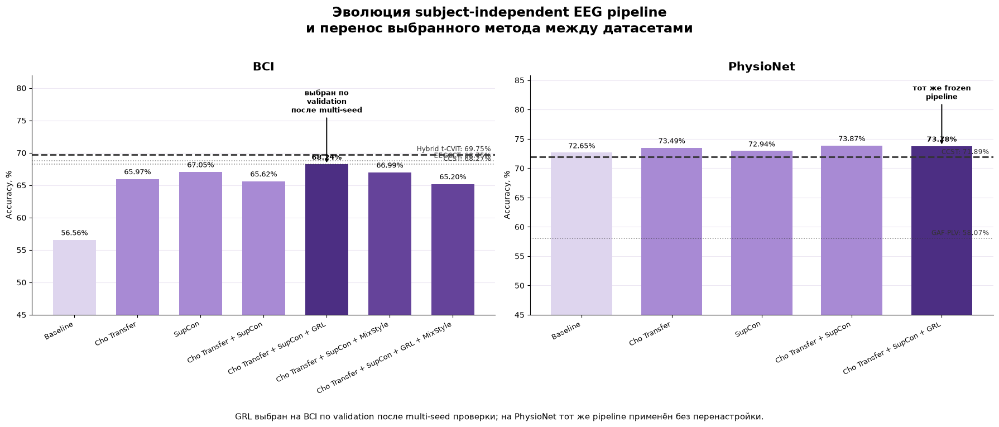

In [144]:
# ============================================================
# FINAL RESEARCH JOURNEY:
# BCI + PHYSIONET + SOTA
#
# Никаких accuracy руками.
# Всё читается из сохранённых результатов.
# ============================================================


# ============================================================
# PATHS
# ============================================================

ROOT = Path(
    "/Users/irina/Desktop/master project/results_v2"
)

ALL_METHODS_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "all_methods_plots"
    / "all_methods_summary.csv"
)

SOTA_PATH = (
    ROOT
    / "strict_loso_denoising_binary"
    / "tables"
    / "06_sota_reference.csv"
)

SELECTION_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_method_selection_summary.csv"
)

PHYS_FINAL_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "physionet_frozen_recipe"
    / "physionet_frozen_recipe_summary.csv"
)

OUT_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "research_journey_plots"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# LOAD
# ============================================================

methods = pd.read_csv(
    ALL_METHODS_PATH
)

sota_raw = pd.read_csv(
    SOTA_PATH
)

selection = pd.read_csv(
    SELECTION_PATH
)

phys_final = pd.read_csv(
    PHYS_FINAL_PATH
)


print("METHODS")
display(methods.round(3))

print()
print("SOTA")
display(sota_raw)


# ============================================================
# METHOD ORDER
# ============================================================

METHOD_ORDER = [
    "Baseline",
    "Cho Transfer",
    "SupCon",
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
    "Cho Transfer + SupCon + GRL + MixStyle",
]


# ============================================================
# DETECT SOTA COLUMNS
# ============================================================

def detect_col(
    df,
    candidates,
):
    lookup = {
        c.lower(): c
        for c in df.columns
    }

    for c in candidates:

        if c.lower() in lookup:
            return lookup[
                c.lower()
            ]

    return None


sota_dataset_col = detect_col(
    sota_raw,
    [
        "dataset",
        "data",
    ],
)

sota_method_col = detect_col(
    sota_raw,
    [
        "method",
        "model",
        "name",
    ],
)

sota_acc_col = detect_col(
    sota_raw,
    [
        "accuracy",
        "accuracy_pct",
        "score",
        "value",
    ],
)


if (
    sota_dataset_col is None
    or
    sota_acc_col is None
):
    raise ValueError(
        "Не удалось определить колонки "
        "dataset/accuracy в SOTA csv."
    )


sota = sota_raw.copy()


sota["_accuracy"] = pd.to_numeric(
    sota[
        sota_acc_col
    ],
    errors="coerce",
)


if (
    sota[
        "_accuracy"
    ]
    .dropna()
    .max()
    <= 1.5
):

    sota[
        "_accuracy"
    ] *= 100


# ============================================================
# NORMALIZE DATASET LABELS
# ============================================================

def norm_dataset(
    value,
):

    s = str(
        value
    ).lower()

    if "bci" in s:
        return "BCI"

    if "phys" in s:
        return "PhysioNet"

    return str(
        value
    )


sota[
    "_dataset"
] = (
    sota[
        sota_dataset_col
    ]
    .map(
        norm_dataset
    )
)


# ============================================================
# FIND FINAL WINNER
# selected by validation only
# ============================================================

winner_row = (
    selection
    .sort_values(
        "validation_rank"
    )
    .iloc[0]
)


WINNER_RAW = (
    winner_row[
        "method"
    ]
)


WINNER_MAP = {
    "transfer_supcon_control":
        "Cho Transfer + SupCon",

    "transfer_supcon_grl":
        "Cho Transfer + SupCon + GRL",

    "transfer_supcon_mixstyle":
        "Cho Transfer + SupCon + MixStyle",
}


WINNER_METHOD = (
    WINNER_MAP.get(
        WINNER_RAW,
        WINNER_RAW,
    )
)


print()
print(
    "FINAL WINNER:",
    WINNER_METHOD
)


# ============================================================
# PREPARE PANEL DATA
# ============================================================

def prepare_dataset(
    dataset,
):

    part = (
        methods[
            methods[
                "dataset"
            ]
            == dataset
        ]
        .copy()
    )

    part = (
        part[
            part[
                "method"
            ]
            .isin(
                METHOD_ORDER
            )
        ]
        .copy()
    )


    part[
        "order"
    ] = (
        part[
            "method"
        ]
        .map({
            method: idx
            for idx, method
            in enumerate(
                METHOD_ORDER
            )
        })
    )


    part = (
        part
        .sort_values(
            "order"
        )
        .reset_index(
            drop=True
        )
    )

    return part


bci = prepare_dataset(
    "BCI"
)

phys = prepare_dataset(
    "PhysioNet"
)


print()
print("BCI METHODS")
display(
    bci[
        [
            "method",
            "mean_accuracy",
            "std_accuracy",
            "n",
        ]
    ].round(3)
)


print()
print("PHYSIONET METHODS")
display(
    phys[
        [
            "method",
            "mean_accuracy",
            "std_accuracy",
            "n",
        ]
    ].round(3)
)


# ============================================================
# COLORS
# ============================================================

COLOR_BASE = "#DED5EE"
COLOR_MID = "#A88AD4"
COLOR_DARK = "#65439A"
COLOR_WINNER = "#4C2E83"

COLOR_SOTA = "#333333"

GRID = "#E7E1EF"


# ============================================================
# BAR COLOR FUNCTION
# ============================================================

def method_color(
    method,
):

    if method == WINNER_METHOD:
        return COLOR_WINNER

    if method == "Baseline":
        return COLOR_BASE

    if method in [
        "Cho Transfer",
        "SupCon",
        "Cho Transfer + SupCon",
    ]:
        return COLOR_MID

    return COLOR_DARK


# ============================================================
# SOTA DRAWER
# ============================================================

def draw_sota(
    ax,
    dataset,
):

    part = (
        sota[
            sota[
                "_dataset"
            ]
            == dataset
        ]
        .dropna(
            subset=[
                "_accuracy"
            ]
        )
        .sort_values(
            "_accuracy"
        )
    )


    if len(part) == 0:
        return


    # рисуем ВСЕ сохранённые SOTA reference
    for i, (_, row) in enumerate(
        part.iterrows()
    ):

        value = (
            row[
                "_accuracy"
            ]
        )


        if (
            sota_method_col is not None
            and
            pd.notna(
                row[
                    sota_method_col
                ]
            )
        ):

            label_name = str(
                row[
                    sota_method_col
                ]
            )

        else:

            label_name = (
                "SOTA"
            )


        ax.axhline(
            value,
            linestyle=(
                "--"
                if i == len(part) - 1
                else ":"
            ),
            linewidth=(
                2.2
                if i == len(part) - 1
                else 1.2
            ),
            alpha=(
                0.9
                if i == len(part) - 1
                else 0.55
            ),
            color=
                COLOR_SOTA,
        )


        # подпись справа внутри панели
        ax.text(
            0.99,
            value + 0.25,
            f"{label_name}: {value:.2f}%",
            transform=
                ax.get_yaxis_transform(),
            ha="right",
            va="bottom",
            fontsize=8.5,
            color=
                COLOR_SOTA,
        )


# ============================================================
# PANEL DRAWER
# ============================================================

def draw_panel(
    ax,
    part,
    dataset,
):

    x = np.arange(
        len(
            part
        )
    )


    colors = [
        method_color(
            m
        )
        for m in part[
            "method"
        ]
    ]


    bars = ax.bar(
        x,
        part[
            "mean_accuracy"
        ],
        width=0.68,
        color=colors,
    )


    # --------------------------------------------------------
    # Accuracy labels
    # --------------------------------------------------------

    for bar, value, method in zip(
        bars,
        part[
            "mean_accuracy"
        ],
        part[
            "method"
        ],
    ):

        weight = (
            "bold"
            if method
            == WINNER_METHOD
            else "normal"
        )

        ax.text(
            bar.get_x()
            + bar.get_width()
            / 2,
            value + 0.45,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight=
                weight,
        )


    # --------------------------------------------------------
    # SOTA
    # --------------------------------------------------------

    draw_sota(
        ax,
        dataset,
    )


    # --------------------------------------------------------
    # winner annotation
    # --------------------------------------------------------

    winner_idx = part[
        part[
            "method"
        ]
        == WINNER_METHOD
    ].index


    if len(
        winner_idx
    ):

        i = (
            winner_idx[0]
        )

        value = (
            part.loc[
                i,
                "mean_accuracy"
            ]
        )


        if dataset == "BCI":

            note = (
                "выбран по\nvalidation\nпосле multi-seed"
            )

        else:

            note = (
                "тот же frozen\npipeline"
            )


        ax.annotate(
            note,
            xy=(
                i,
                value,
            ),
            xytext=(
                i,
                value + 8,
            ),
            ha="center",
            fontsize=9,
            fontweight="bold",
            arrowprops={
                "arrowstyle": "->",
                "lw": 1.4,
            },
        )


    # --------------------------------------------------------
    # axis
    # --------------------------------------------------------

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        part[
            "method"
        ],
        rotation=27,
        ha="right",
        fontsize=9,
    )


    ax.set_ylim(
        45,
        max(
            82,
            part[
                "mean_accuracy"
            ].max()
            + 12,
        )
    )


    ax.set_ylabel(
        "Accuracy, %"
    )


    ax.set_title(
        dataset,
        fontsize=15,
        fontweight="bold",
    )


    ax.grid(
        axis="y",
        color=GRID,
        alpha=0.75,
    )


    ax.set_axisbelow(
        True
    )


    ax.spines[
        ["top", "right"]
    ].set_visible(
        False
    )


# ============================================================
# FINAL TWO-PANEL FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        18,
        7,
    ),
)


draw_panel(
    axes[0],
    bci,
    "BCI",
)

draw_panel(
    axes[1],
    phys,
    "PhysioNet",
)


fig.suptitle(
    (
        "Эволюция subject-independent EEG pipeline\n"
        "и перенос выбранного метода между датасетами"
    ),
    fontsize=17,
    fontweight="bold",
    y=1.02,
)


fig.text(
    0.5,
    -0.04,
    (
        "GRL выбран на BCI по validation после multi-seed проверки; "
        "на PhysioNet тот же pipeline применён без перенастройки."
    ),
    ha="center",
    fontsize=11,
)


plt.tight_layout()


OUT_PATH = (
    OUT_DIR
    / "01_full_research_journey_bci_physionet_sota.png"
)


plt.savefig(
    OUT_PATH,
    dpi=240,
    bbox_inches="tight",
)


print(
    "Saved:",
    OUT_PATH
)


plt.show()

Winner: Cho Transfer + SupCon + GRL

Literature reference table:


,dataset,model,accuracy
0,BCI,CCST,0.6827
1,BCI,EEGCCT,0.6875
2,BCI,Hybrid t-CViT,0.6975
3,PhysioNet,GAF-PLV,0.5807
4,PhysioNet,CCST,0.7189


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/report_pack/01_bci_classifier_evolution.png


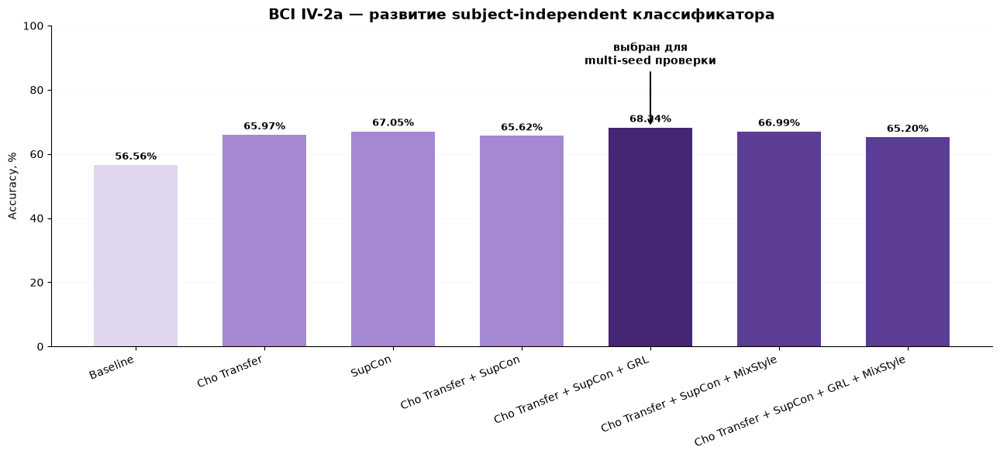

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/report_pack/02_physionet_classifier_evolution.png


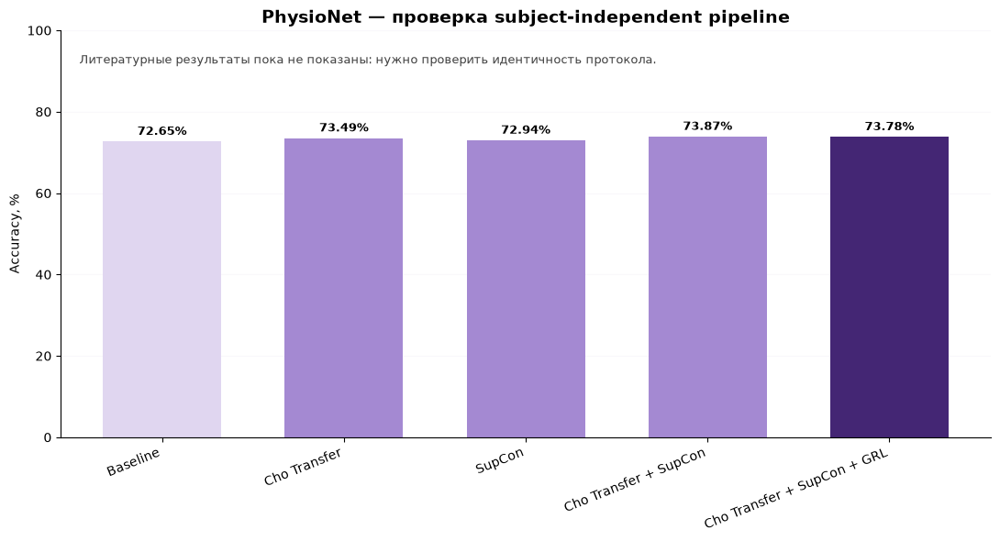


BCI DENOISER ABLATION RAW


,subject,method,accuracy,balanced_accuracy,macro_f1,kappa,reconstruction_snr_db,rmse_uV
0,A01,RAW,0.763889,0.763889,0.761636,0.527778,-5.000000,17.368011
1,A01,MSE,0.784722,0.784722,0.780908,0.569444,3.333439,6.767246
2,A01,MSE_PSD,0.777778,0.777778,0.772467,0.555556,3.647593,6.510960
3,A01,MSE_COV,0.777778,0.777778,0.773407,0.555556,3.094802,6.985086
4,A01,FULL,0.784722,0.784722,0.780044,0.569444,3.016529,7.043665
5,A02,RAW,0.611111,0.611111,0.603462,0.222222,-5.000000,26.325686
6,A02,MSE,0.618056,0.618056,0.608057,0.236111,4.334798,9.433683
7,A02,MSE_PSD,0.631944,0.631944,0.616386,0.263889,3.904625,9.894499
8,A02,MSE_COV,0.590278,0.590278,0.567568,0.180556,3.034590,11.076445
9,A02,FULL,0.618056,0.618056,0.601910,0.236111,3.382359,10.505610


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/report_pack/03_bci_denoiser_ablation.png


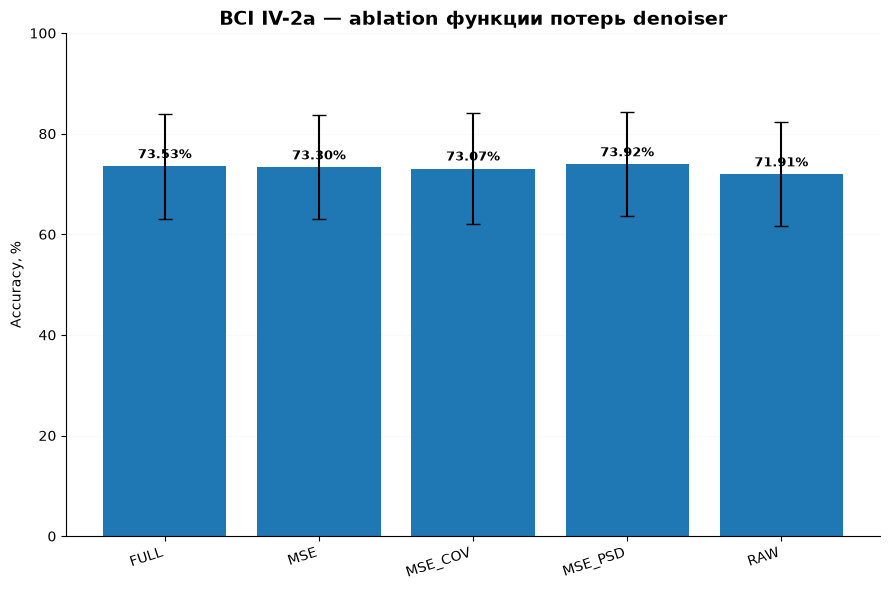

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/report_pack/04_bci_denoising_robustness.png


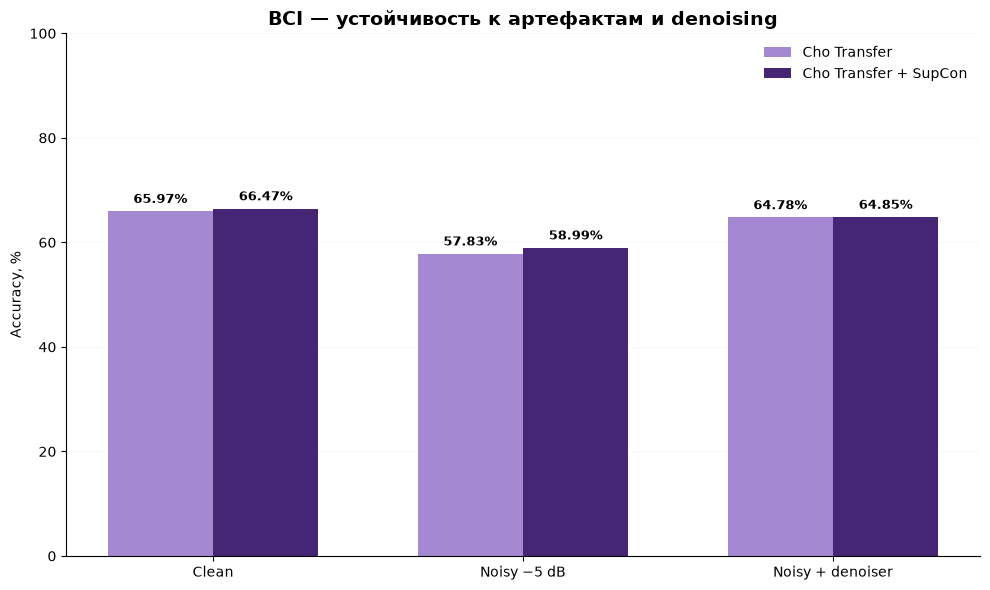

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/report_pack/04_physionet_denoising_robustness.png


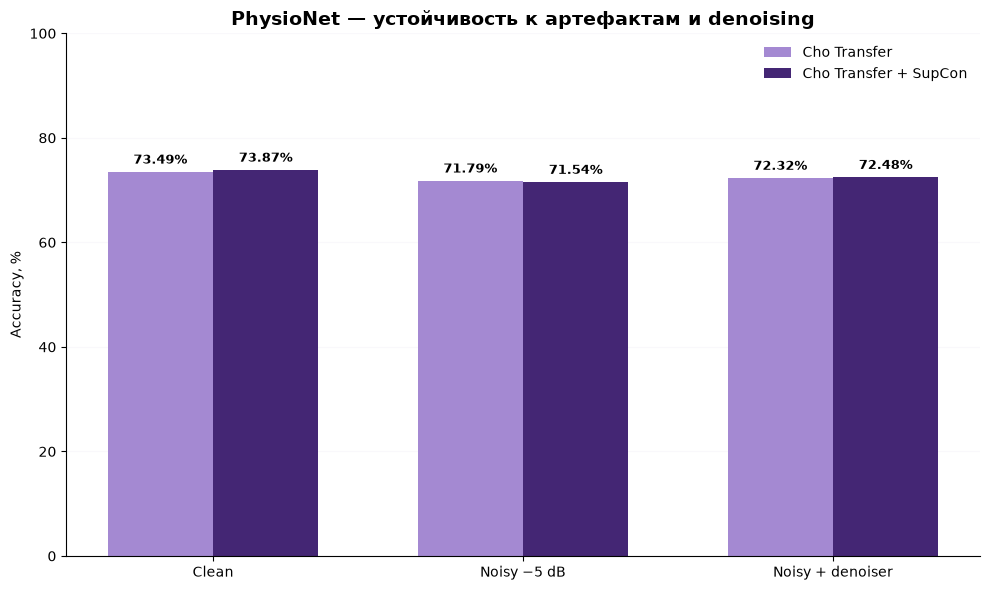

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/report_pack/05_bci_multiseed_stability.png


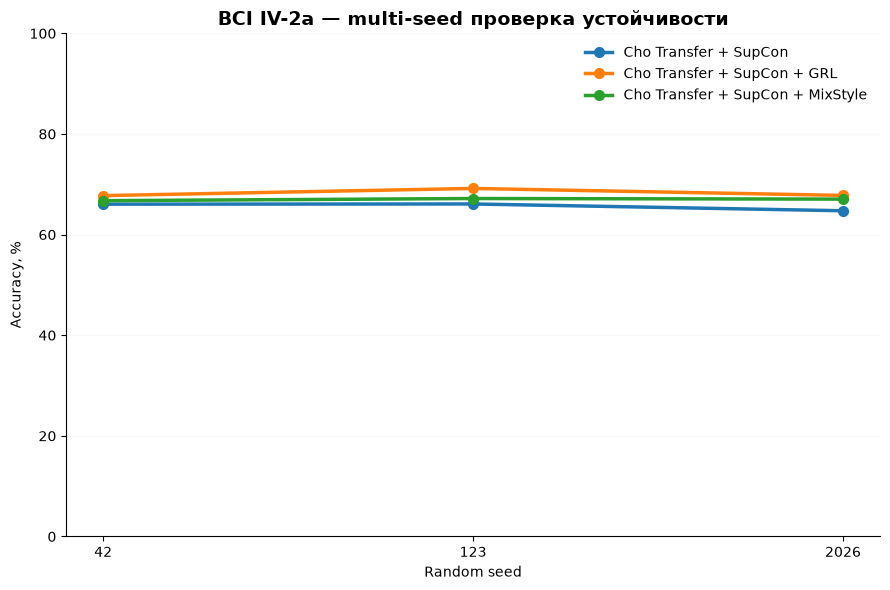

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/report_pack/06_final_frozen_pipeline.png


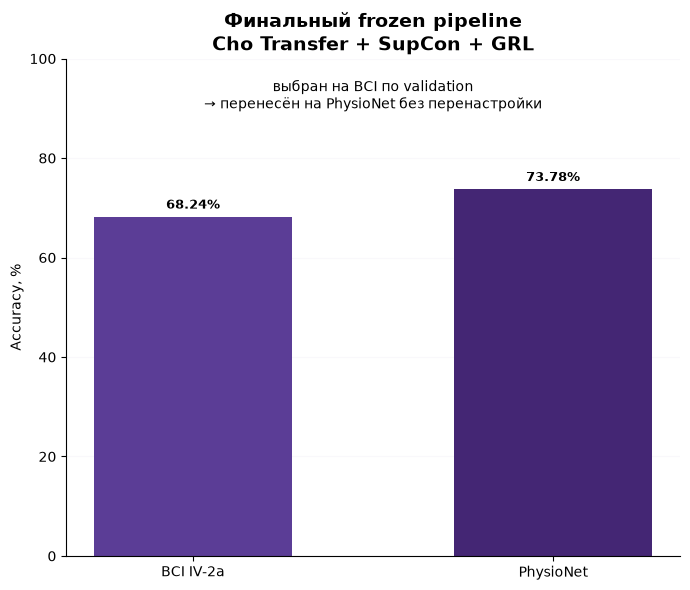


REPORT PACK READY
01_bci_classifier_evolution.png
02_physionet_classifier_evolution.png
03_bci_denoiser_ablation.png
04_bci_denoising_robustness.png
04_physionet_denoising_robustness.png
05_bci_multiseed_stability.png
06_final_frozen_pipeline.png


In [145]:
# ============================================================
# REPORT PACK
# What we actually did during the experiments
#
# 1. BCI classifier evolution
# 2. PhysioNet classifier evolution
# 3. BCI denoiser ablation
# 4. Robustness / denoising
# 5. Multi-seed stability
# 6. Frozen cross-dataset pipeline
#
# IMPORTANT:
# - accuracy axis starts at 0
# - experiment results are read from CSV
# - literature references are clearly marked as references
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PATHS
# ============================================================

ROOT = Path(
    "/Users/irina/Desktop/master project/results_v2"
)

REPORT_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "report_pack"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


ALL_METHODS_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "all_methods_plots"
    / "all_methods_summary.csv"
)

MULTISEED_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_multiseed_results.csv"
)

SELECTION_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_method_selection_summary.csv"
)

PHYS_FINAL_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "physionet_frozen_recipe"
    / "physionet_frozen_recipe_summary.csv"
)

FROZEN_SUMMARY_PATH = (
    ROOT
    / "strict_loso_frozen_final"
    / "strict_loso_frozen_summary.csv"
)

SOTA_PATH = (
    ROOT
    / "strict_loso_denoising_binary"
    / "tables"
    / "06_sota_reference.csv"
)

BCI_ABLATION_PATH = (
    ROOT
    / "ablation_task_informed"
    / "ablation_results.csv"
)


# ============================================================
# COLORS
# ============================================================

PURPLE_1 = "#E0D6F0"
PURPLE_2 = "#C5AFE3"
PURPLE_3 = "#A489D2"
PURPLE_4 = "#8061B8"
PURPLE_5 = "#5B3D96"
PURPLE_6 = "#442674"

GREY = "#555555"
LIGHT_GREY = "#BEBEBE"

GRID = "#E9E4F0"


# ============================================================
# COMMON STYLE
# ============================================================

def finish_axis(
    ax,
    title,
    ylabel="Accuracy, %",
):

    ax.set_ylim(
        0,
        100,
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
    )

    ax.grid(
        axis="y",
        alpha=0.25,
        color=GRID,
    )

    ax.set_axisbelow(
        True
    )

    ax.spines[
        ["top", "right"]
    ].set_visible(
        False
    )


def add_bar_labels(
    ax,
    bars,
    fmt="{:.2f}%",
):

    for bar in bars:

        value = (
            bar.get_height()
        )

        if np.isfinite(
            value
        ):

            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value + 1.0,
                fmt.format(
                    value
                ),
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
            )


def save_plot(
    filename,
):

    path = (
        REPORT_DIR
        / filename
    )

    plt.tight_layout()

    plt.savefig(
        path,
        dpi=220,
        bbox_inches="tight",
    )

    print(
        "Saved:",
        path
    )


# ============================================================
# LOAD MAIN TABLES
# ============================================================

methods = pd.read_csv(
    ALL_METHODS_PATH
)

multi = pd.read_csv(
    MULTISEED_PATH
)

selection = pd.read_csv(
    SELECTION_PATH
)

phys_final = pd.read_csv(
    PHYS_FINAL_PATH
)

frozen = pd.read_csv(
    FROZEN_SUMMARY_PATH
)


# ============================================================
# METHOD ORDER
# ============================================================

METHOD_ORDER = [
    "Baseline",
    "Cho Transfer",
    "SupCon",
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
    "Cho Transfer + SupCon + GRL + MixStyle",
]


# ============================================================
# FINAL WINNER
# ============================================================

LABELS = {
    "transfer_supcon_control":
        "Cho Transfer + SupCon",

    "transfer_supcon_grl":
        "Cho Transfer + SupCon + GRL",

    "transfer_supcon_mixstyle":
        "Cho Transfer + SupCon + MixStyle",
}


winner_raw = (
    selection
    .sort_values(
        "validation_rank"
    )
    .iloc[0][
        "method"
    ]
)

WINNER = LABELS.get(
    winner_raw,
    winner_raw,
)

print(
    "Winner:",
    WINNER
)


# ============================================================
# OPTIONAL LITERATURE TABLE
# ============================================================

sota = None

if SOTA_PATH.exists():

    sota = pd.read_csv(
        SOTA_PATH
    )

    print()
    print("Literature reference table:")

    display(
        sota
    )


# ============================================================
# 1. BCI — CLASSIFIER EVOLUTION
# ============================================================

bci = (
    methods[
        methods["dataset"]
        == "BCI"
    ]
    .copy()
)


bci = bci[
    bci[
        "method"
    ].isin(
        METHOD_ORDER
    )
].copy()


bci[
    "order"
] = (
    bci[
        "method"
    ]
    .map({
        m: i
        for i, m
        in enumerate(
            METHOD_ORDER
        )
    })
)


bci = (
    bci
    .sort_values(
        "order"
    )
    .reset_index(
        drop=True
    )
)


colors = []

for method in bci[
    "method"
]:

    if method == "Baseline":
        colors.append(
            PURPLE_1
        )

    elif method == WINNER:
        colors.append(
            PURPLE_6
        )

    elif (
        "GRL" in method
        or
        "MixStyle" in method
    ):
        colors.append(
            PURPLE_5
        )

    else:
        colors.append(
            PURPLE_3
        )


fig, ax = plt.subplots(
    figsize=(13, 6)
)

x = np.arange(
    len(
        bci
    )
)


bars = ax.bar(
    x,
    bci[
        "mean_accuracy"
    ],
    color=colors,
    width=0.65,
)


add_bar_labels(
    ax,
    bars,
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    bci[
        "method"
    ],
    rotation=22,
    ha="right",
)


finish_axis(
    ax,
    (
        "BCI IV-2a — развитие "
        "subject-independent классификатора"
    ),
)


# Winner mark
winner_idx = bci[
    bci["method"]
    == WINNER
].index


if len(
    winner_idx
):

    i = winner_idx[0]

    ax.annotate(
        "выбран для\nmulti-seed проверки",
        xy=(
            i,
            bci.loc[
                i,
                "mean_accuracy"
            ],
        ),
        xytext=(
            i,
            88,
        ),
        ha="center",
        fontweight="bold",
        arrowprops={
            "arrowstyle": "->",
            "lw": 1.5,
        },
    )


save_plot(
    "01_bci_classifier_evolution.png"
)

plt.show()


# ============================================================
# 2. PHYSIONET — CLASSIFIER EVOLUTION
# ============================================================

phys = (
    methods[
        methods["dataset"]
        == "PhysioNet"
    ]
    .copy()
)


phys[
    "order"
] = (
    phys[
        "method"
    ]
    .map({
        m: i
        for i, m
        in enumerate(
            METHOD_ORDER
        )
    })
)


phys = (
    phys
    .sort_values(
        "order"
    )
    .reset_index(
        drop=True
    )
)


colors = []

for method in phys[
    "method"
]:

    if method == "Baseline":

        colors.append(
            PURPLE_1
        )

    elif method == WINNER:

        colors.append(
            PURPLE_6
        )

    else:

        colors.append(
            PURPLE_3
        )


fig, ax = plt.subplots(
    figsize=(11, 6)
)

x = np.arange(
    len(
        phys
    )
)


bars = ax.bar(
    x,
    phys[
        "mean_accuracy"
    ],
    width=0.65,
    color=colors,
)


add_bar_labels(
    ax,
    bars,
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    phys[
        "method"
    ],
    rotation=22,
    ha="right",
)


finish_axis(
    ax,
    (
        "PhysioNet — проверка "
        "subject-independent pipeline"
    ),
)


# IMPORTANT:
# пока НЕ называем литературу SOTA,
# потому что baseline > published reference
ax.text(
    0.02,
    0.94,
    (
        "Литературные результаты пока не показаны: "
        "нужно проверить идентичность протокола."
    ),
    transform=ax.transAxes,
    fontsize=9,
    va="top",
    alpha=0.75,
)


save_plot(
    "02_physionet_classifier_evolution.png"
)

plt.show()


# ============================================================
# 3. BCI DENOISER ABLATION
# MSE / MSE+PSD / MSE+Cov / FULL
# ============================================================

if BCI_ABLATION_PATH.exists():

    abl = pd.read_csv(
        BCI_ABLATION_PATH
    )


    print()
    print(
        "BCI DENOISER ABLATION RAW"
    )

    display(
        abl
    )


    # ---------------------------------------------
    # Try to identify columns automatically
    # ---------------------------------------------

    method_candidates = [
        "method",
        "variant",
        "loss",
        "model",
        "denoiser",
    ]

    acc_candidates = [
        "accuracy",
        "test_accuracy",
        "classification_accuracy",
        "downstream_accuracy",
        "acc",
    ]


    method_col = next(
        (
            c
            for c in method_candidates
            if c in abl.columns
        ),
        None,
    )


    acc_col = next(
        (
            c
            for c in acc_candidates
            if c in abl.columns
        ),
        None,
    )


    if (
        method_col is not None
        and
        acc_col is not None
    ):

        tmp = abl[
            [
                method_col,
                acc_col,
            ]
        ].copy()


        tmp[
            acc_col
        ] = pd.to_numeric(
            tmp[
                acc_col
            ],
            errors="coerce",
        )


        if (
            tmp[
                acc_col
            ]
            .dropna()
            .max()
            <= 1.5
        ):

            tmp[
                acc_col
            ] *= 100


        abl_summary = (
            tmp
            .groupby(
                method_col,
                as_index=False,
            )
            .agg(
                mean_accuracy=(
                    acc_col,
                    "mean",
                ),

                std_accuracy=(
                    acc_col,
                    "std",
                ),

                n=(
                    acc_col,
                    "size",
                ),
            )
        )


        fig, ax = plt.subplots(
            figsize=(9, 6)
        )


        x = np.arange(
            len(
                abl_summary
            )
        )


        bars = ax.bar(
            x,
            abl_summary[
                "mean_accuracy"
            ],
            yerr=
                abl_summary[
                    "std_accuracy"
                ],
            capsize=5,
        )


        add_bar_labels(
            ax,
            bars,
        )


        ax.set_xticks(
            x
        )

        ax.set_xticklabels(
            abl_summary[
                method_col
            ],
            rotation=18,
            ha="right",
        )


        finish_axis(
            ax,
            (
                "BCI IV-2a — ablation "
                "функции потерь denoiser"
            ),
        )


        save_plot(
            "03_bci_denoiser_ablation.png"
        )

        plt.show()


    else:

        print(
            "Не смог автоматически "
            "распознать method/accuracy "
            "в ablation_results.csv"
        )


# ============================================================
# 4. ROBUSTNESS:
# CLEAN / NOISY / NOISY + DENOISER
# ============================================================

condition_order = [
    "clean",
    "noisy",
    "noisy_denoised",
]


condition_labels = {
    "clean":
        "Clean",

    "noisy":
        "Noisy −5 dB",

    "noisy_denoised":
        "Noisy + denoiser",
}


for dataset in [
    "BCI",
    "PhysioNet",
]:

    part = frozen[
        (
            frozen[
                "dataset"
            ]
            == dataset
        )
        &
        (
            frozen[
                "method"
            ]
            .isin(
                [
                    "transfer",
                    "transfer_supcon",
                ]
            )
        )
        &
        (
            frozen[
                "condition"
            ]
            .isin(
                condition_order
            )
        )
    ].copy()


    if len(
        part
    ) == 0:
        continue


    fig, ax = plt.subplots(
        figsize=(10, 6)
    )


    x = np.arange(
        len(
            condition_order
        )
    )

    width = 0.34


    for offset, method, color in [
        (
            -width / 2,
            "transfer",
            PURPLE_3,
        ),
        (
            width / 2,
            "transfer_supcon",
            PURPLE_6,
        ),
    ]:

        vals = []

        for condition in condition_order:

            row = part[
                (
                    part[
                        "method"
                    ]
                    == method
                )
                &
                (
                    part[
                        "condition"
                    ]
                    == condition
                )
            ]


            vals.append(
                (
                    row[
                        "mean_accuracy"
                    ].iloc[0]
                    * 100
                )
                if len(row)
                else np.nan
            )


        bars = ax.bar(
            x + offset,
            vals,
            width,
            label=(
                "Cho Transfer"
                if method
                == "transfer"
                else
                "Cho Transfer + SupCon"
            ),
            color=color,
        )


        add_bar_labels(
            ax,
            bars,
        )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        [
            condition_labels[c]
            for c in condition_order
        ]
    )


    finish_axis(
        ax,
        (
            f"{dataset} — устойчивость "
            "к артефактам и denoising"
        ),
    )


    ax.legend(
        frameon=False
    )


    save_plot(
        (
            f"04_{dataset.lower()}_"
            "denoising_robustness.png"
        )
    )

    plt.show()


# ============================================================
# 5. MULTI-SEED
# why one run was not enough
# ============================================================

multi[
    "method_label"
] = (
    multi[
        "method"
    ]
    .map(
        LABELS
    )
)


seed_level = (
    multi
    .groupby(
        [
            "method_label",
            "seed_base",
        ],
        as_index=False,
    )
    .agg(
        test_accuracy=(
            "accuracy",
            "mean",
        ),

        validation_accuracy=(
            "best_val_accuracy",
            "mean",
        ),
    )
)


seed_level[
    "test_accuracy"
] *= 100

seed_level[
    "validation_accuracy"
] *= 100


fig, ax = plt.subplots(
    figsize=(9, 6)
)


for method in [
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
]:

    part = (
        seed_level[
            seed_level[
                "method_label"
            ]
            == method
        ]
        .sort_values(
            "seed_base"
        )
    )


    ax.plot(
        part[
            "seed_base"
        ].astype(str),
        part[
            "test_accuracy"
        ],
        marker="o",
        linewidth=2.5,
        markersize=7,
        label=method,
    )


finish_axis(
    ax,
    (
        "BCI IV-2a — multi-seed "
        "проверка устойчивости"
    ),
)


ax.set_xlabel(
    "Random seed"
)

ax.legend(
    frameon=False
)


save_plot(
    "05_bci_multiseed_stability.png"
)

plt.show()


# ============================================================
# 6. FINAL FROZEN PIPELINE
# ============================================================

selected = (
    selection
    .sort_values(
        "validation_rank"
    )
    .iloc[0]
)


bci_final = (
    selected[
        "mean_test_accuracy"
    ]
)


if bci_final <= 1.5:

    bci_final *= 100


phys_value = (
    phys_final
    .iloc[0][
        "mean_accuracy"
    ]
)


if phys_value <= 1.5:

    phys_value *= 100


fig, ax = plt.subplots(
    figsize=(7, 6)
)


bars = ax.bar(
    [
        "BCI IV-2a",
        "PhysioNet",
    ],
    [
        bci_final,
        phys_value,
    ],
    color=[
        PURPLE_5,
        PURPLE_6,
    ],
    width=0.55,
)


add_bar_labels(
    ax,
    bars,
)


finish_axis(
    ax,
    (
        "Финальный frozen pipeline\n"
        "Cho Transfer + SupCon + GRL"
    ),
)


ax.text(
    0.5,
    90,
    (
        "выбран на BCI по validation\n"
        "→ перенесён на PhysioNet "
        "без перенастройки"
    ),
    ha="center",
    fontsize=10,
)


save_plot(
    "06_final_frozen_pipeline.png"
)

plt.show()


print()
print("=" * 100)
print("REPORT PACK READY")
print("=" * 100)

for p in sorted(
    REPORT_DIR.glob(
        "*.png"
    )
):
    print(
        p.name
    )

FINAL SELECTED METHOD: Cho Transfer + SupCon + GRL
Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/01_BCI_classifier_evolution.png


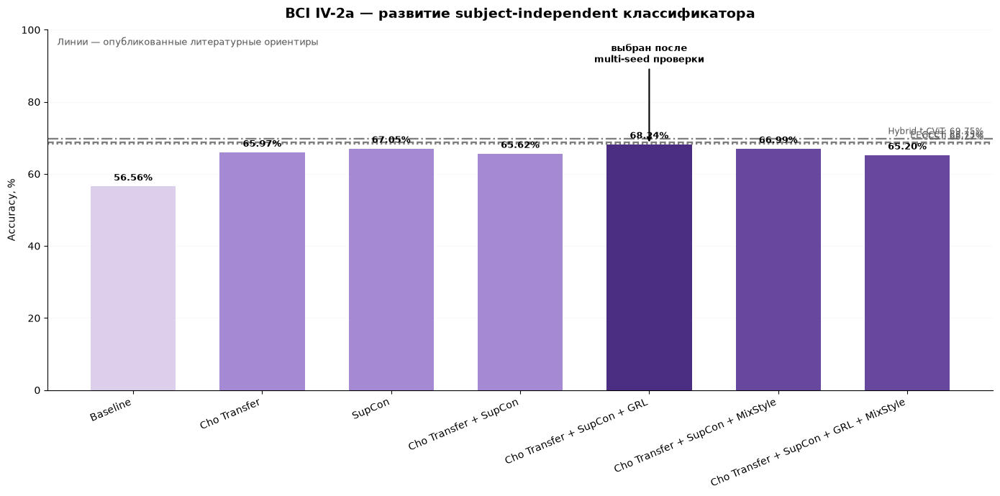

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/02_PhysioNet_classifier_evolution.png


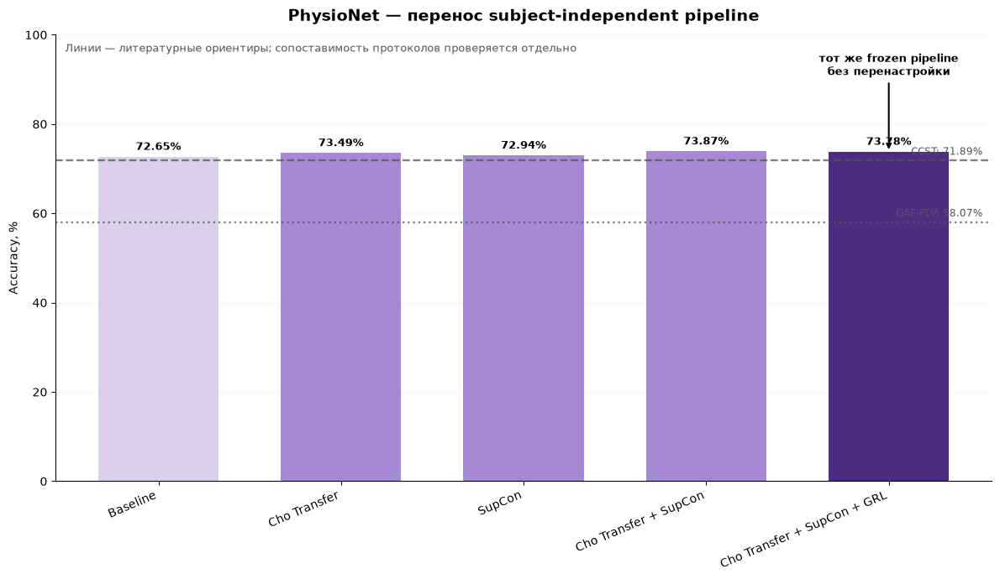


BCI DENOISER ABLATION


,method,mean_accuracy,std_accuracy,n
0,FULL,73.534,10.408,9
1,MSE,73.302,10.342,9
2,MSE_COV,73.071,10.990,9
3,MSE_PSD,73.920,10.371,9
4,RAW,71.914,10.342,9


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/03_BCI_denoiser_ablation.png


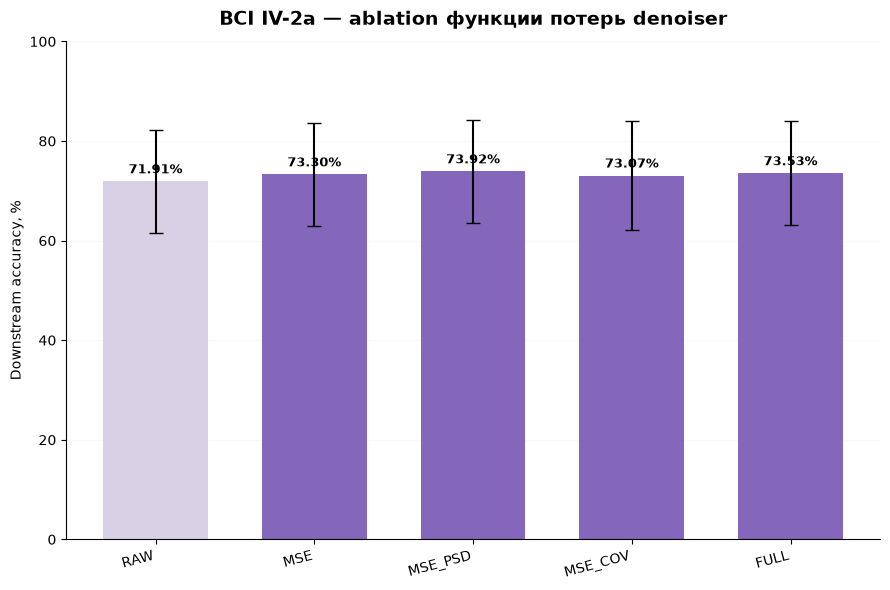


PHYSIONET ABLATION CANDIDATES
score=5 rows=  162 | /Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/physionet_ablation_subject_results.csv
score=5 rows=    6 | /Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/physionet_ablation_global_results.csv

AUTO-SELECTED PHYSIONET ABLATION:
/Users/irina/Desktop/master project/results_physionet_external/physionet_ablation/physionet_ablation_subject_results.csv


,method,mean_accuracy,std_accuracy,n
0,Clean,72.464,12.016,27
1,FULL,70.156,10.187,27
2,MSE,69.744,10.694,27
3,MSE_COV,69.584,11.217,27
4,MSE_PSD,69.744,9.940,27
5,Raw,66.942,9.354,27


Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/04_PhysioNet_denoiser_ablation.png


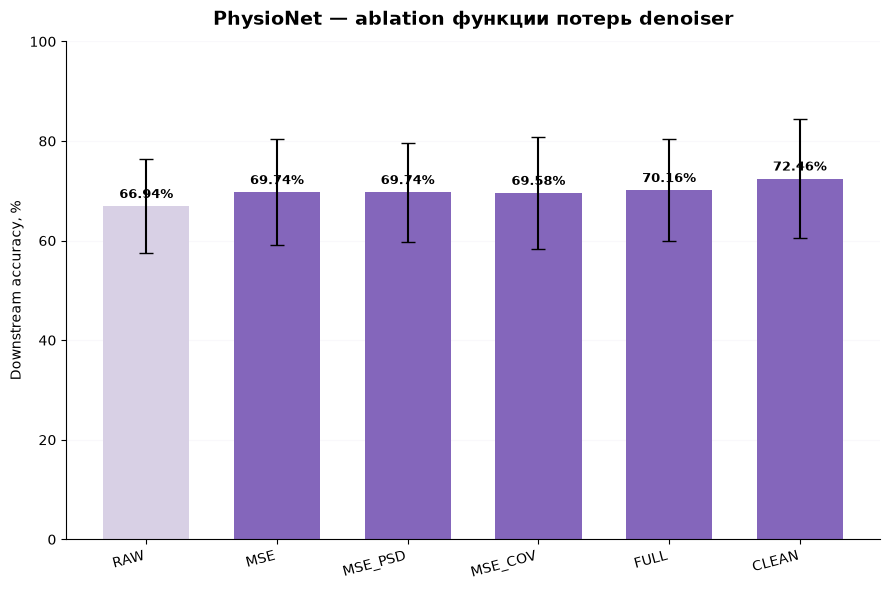

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/05_BCI_denoising_robustness.png


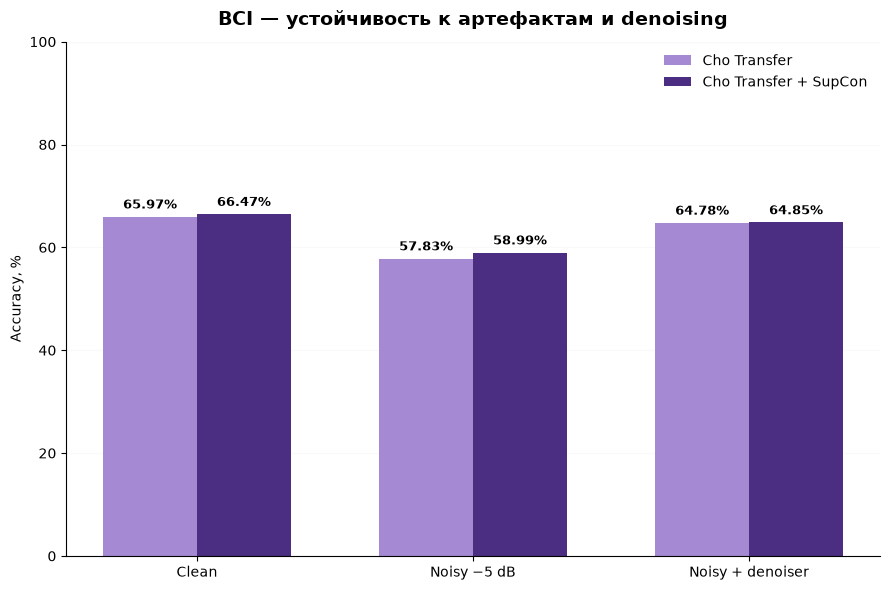

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/06_PhysioNet_denoising_robustness.png


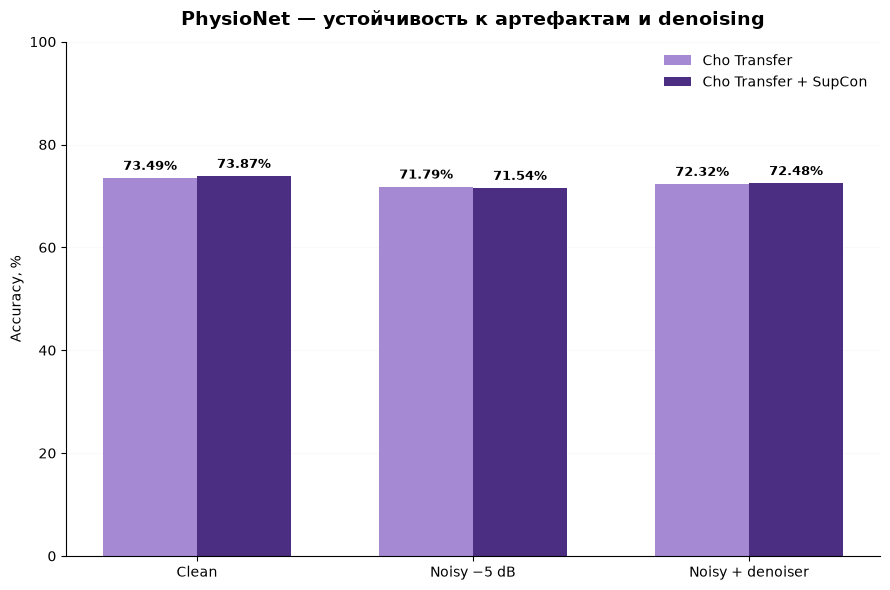

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/07_BCI_multiseed_stability.png


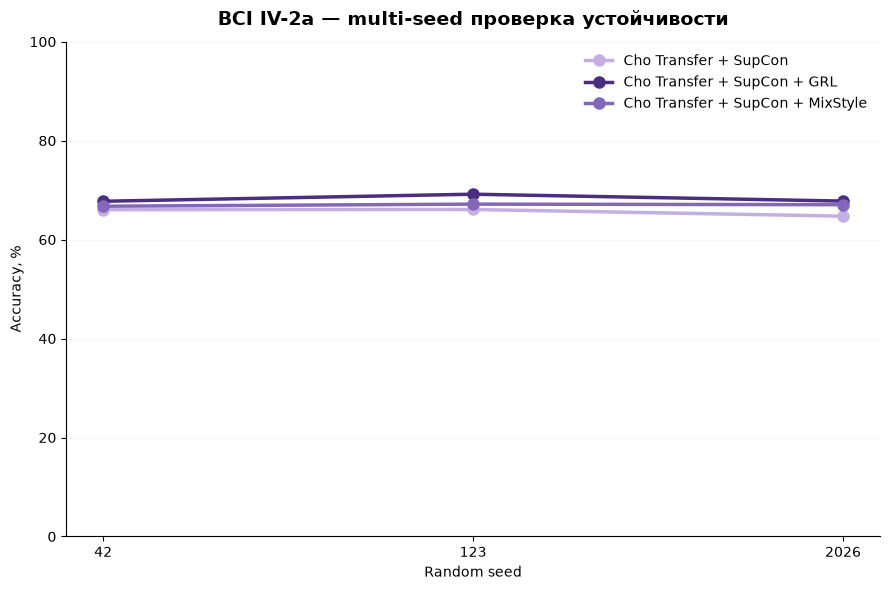

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/08_BCI_multiseed_mean_sd.png


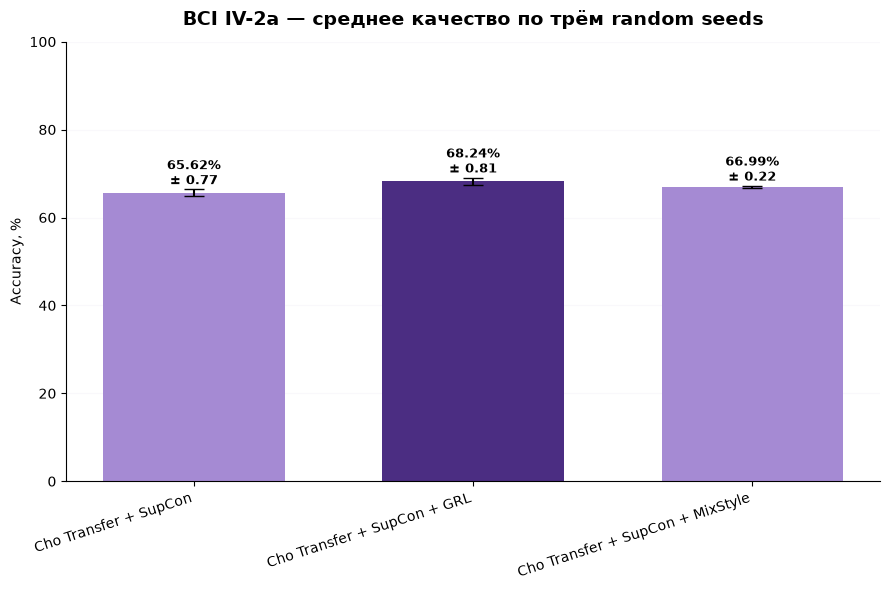

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/09_final_frozen_pipeline.png


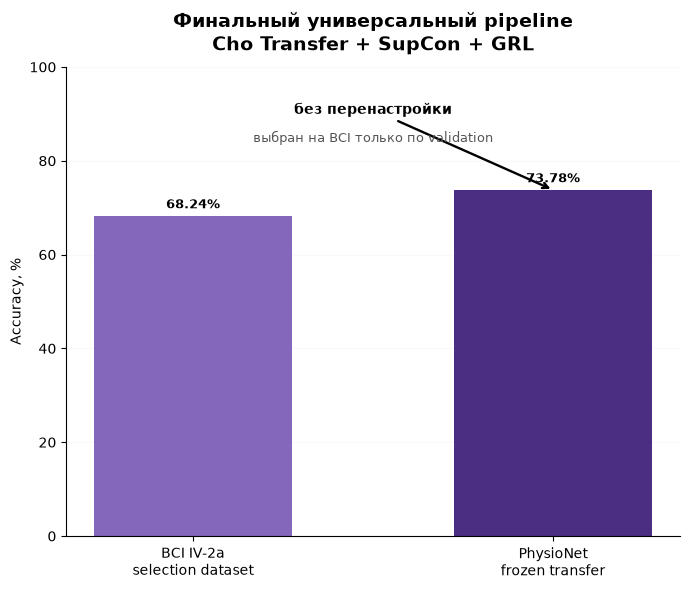

Saved: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES/10_denoising_gain_both_datasets.png


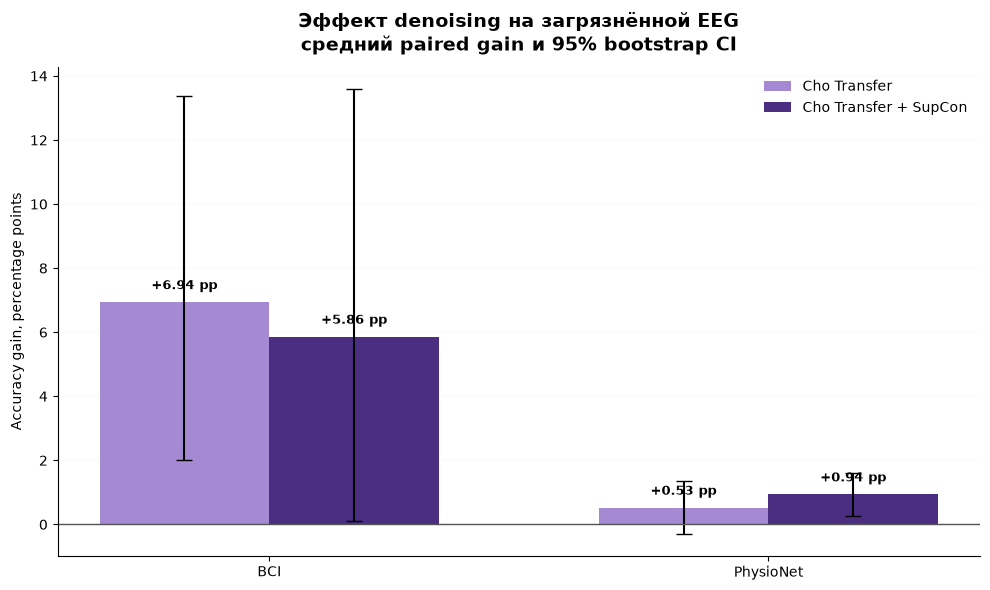


MASTER REPORT PACK READY
01_BCI_classifier_evolution.png
02_PhysioNet_classifier_evolution.png
03_BCI_denoiser_ablation.png
04_PhysioNet_denoiser_ablation.png
05_BCI_denoising_robustness.png
06_PhysioNet_denoising_robustness.png
07_BCI_multiseed_stability.png
08_BCI_multiseed_mean_sd.png
09_final_frozen_pipeline.png
10_denoising_gain_both_datasets.png

Output directory:
/Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/MASTER_REPORT_FIGURES


In [146]:
# ============================================================
# MASTER REPORT FIGURES
# ============================================================
#
# Builds the complete figure pack for the thesis/report:
#
# 01 BCI classifier evolution + literature references
# 02 PhysioNet classifier evolution + literature references
# 03 BCI denoiser ablation
# 04 PhysioNet denoiser ablation
# 05 BCI robustness: clean / noisy / denoised
# 06 PhysioNet robustness: clean / noisy / denoised
# 07 BCI multi-seed stability
# 08 BCI multi-seed mean ± SD
# 09 Final frozen pipeline: BCI -> PhysioNet
# 10 Denoising gain on both datasets
#
# IMPORTANT:
# - No experiment accuracy is entered manually
# - Reads saved CSV results
# - Accuracy axes start from zero
# ============================================================



# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/Users/irina/Desktop/master project"
)

ROOT = (
    PROJECT_ROOT
    / "results_v2"
)

REPORT_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "MASTER_REPORT_FIGURES"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


ALL_METHODS_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "all_methods_plots"
    / "all_methods_summary.csv"
)

MULTISEED_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_multiseed_results.csv"
)

SELECTION_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_method_selection_summary.csv"
)

PHYS_FINAL_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "physionet_frozen_recipe"
    / "physionet_frozen_recipe_summary.csv"
)

FROZEN_SUBJECT_PATH = (
    ROOT
    / "strict_loso_frozen_final"
    / "strict_loso_frozen_subject_results.csv"
)

FROZEN_SUMMARY_PATH = (
    ROOT
    / "strict_loso_frozen_final"
    / "strict_loso_frozen_summary.csv"
)

DENOISING_STATS_PATH = (
    ROOT
    / "strict_loso_frozen_final"
    / "tables"
    / "03_denoising_statistics.csv"
)

BCI_ABLATION_PATH = (
    ROOT
    / "ablation_task_informed"
    / "ablation_results.csv"
)

SOTA_PATH = (
    ROOT
    / "strict_loso_denoising_binary"
    / "tables"
    / "06_sota_reference.csv"
)


# ============================================================
# COLORS
# ============================================================

PURPLE_0 = "#EEE8F6"
PURPLE_1 = "#DCCFEC"
PURPLE_2 = "#C4AFE2"
PURPLE_3 = "#A58AD3"
PURPLE_4 = "#8466BB"
PURPLE_5 = "#68479F"
PURPLE_6 = "#4B2D82"

GREY = "#555555"
LIGHT_GREY = "#AAAAAA"
GRID = "#E9E4F0"

COLOR_RAW = "#D8D0E5"
COLOR_MAIN = PURPLE_4
COLOR_WINNER = PURPLE_6


# ============================================================
# HELPERS
# ============================================================

def pct(series):
    s = pd.to_numeric(
        series,
        errors="coerce",
    )

    if (
        len(s.dropna())
        and
        s.dropna().max()
        <= 1.5
    ):
        s = s * 100

    return s


def detect_col(
    df,
    candidates,
):
    lower = {
        c.lower(): c
        for c in df.columns
    }

    for candidate in candidates:
        if candidate.lower() in lower:
            return lower[
                candidate.lower()
            ]

    return None


def save_plot(
    fig,
    filename,
):
    path = (
        REPORT_DIR
        / filename
    )

    fig.tight_layout()

    fig.savefig(
        path,
        dpi=240,
        bbox_inches="tight",
    )

    print(
        "Saved:",
        path
    )


def clean_axes(
    ax,
    title,
    ylabel="Accuracy, %",
    ylim=(0, 100),
):
    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12,
    )

    ax.set_ylabel(
        ylabel
    )

    if ylim is not None:
        ax.set_ylim(
            *ylim
        )

    ax.grid(
        axis="y",
        alpha=0.25,
        color=GRID,
    )

    ax.set_axisbelow(
        True
    )

    ax.spines[
        ["top", "right"]
    ].set_visible(
        False
    )


def add_bar_labels(
    ax,
    bars,
    offset=1.0,
    fmt="{:.2f}%",
):
    for bar in bars:

        h = (
            bar.get_height()
        )

        if np.isfinite(h):

            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                h + offset,
                fmt.format(h),
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
            )


# ============================================================
# LOAD MAIN RESULTS
# ============================================================

methods = pd.read_csv(
    ALL_METHODS_PATH
)

multi = pd.read_csv(
    MULTISEED_PATH
)

selection = pd.read_csv(
    SELECTION_PATH
)

phys_final = pd.read_csv(
    PHYS_FINAL_PATH
)

frozen_subject = pd.read_csv(
    FROZEN_SUBJECT_PATH
)

frozen_summary = pd.read_csv(
    FROZEN_SUMMARY_PATH
)

denoising_stats = pd.read_csv(
    DENOISING_STATS_PATH
)

sota = pd.read_csv(
    SOTA_PATH
)


# ============================================================
# NORMALIZE LITERATURE REFERENCES
# ============================================================

sota_dataset_col = detect_col(
    sota,
    [
        "dataset",
    ],
)

sota_model_col = detect_col(
    sota,
    [
        "model",
        "method",
        "name",
    ],
)

sota_acc_col = detect_col(
    sota,
    [
        "accuracy",
        "accuracy_pct",
        "score",
    ],
)

if (
    sota_dataset_col is None
    or
    sota_acc_col is None
):
    raise ValueError(
        "Cannot detect SOTA dataset/accuracy columns."
    )

sota = sota.copy()

sota[
    "accuracy_pct"
] = pct(
    sota[
        sota_acc_col
    ]
)


def normalize_dataset(
    x,
):
    s = str(x).lower()

    if "bci" in s:
        return "BCI"

    if "phys" in s:
        return "PhysioNet"

    return str(x)


sota[
    "dataset_norm"
] = (
    sota[
        sota_dataset_col
    ]
    .map(
        normalize_dataset
    )
)


def draw_literature_refs(
    ax,
    dataset,
):
    refs = (
        sota[
            sota[
                "dataset_norm"
            ]
            == dataset
        ]
        .dropna(
            subset=[
                "accuracy_pct"
            ]
        )
        .sort_values(
            "accuracy_pct"
        )
        .reset_index(
            drop=True
        )
    )

    styles = [
        ":",
        "--",
        "-.",
        (0, (4, 2)),
    ]

    for i, row in refs.iterrows():

        value = (
            row[
                "accuracy_pct"
            ]
        )

        if sota_model_col is not None:
            model = str(
                row[
                    sota_model_col
                ]
            )
        else:
            model = "Literature"

        ax.axhline(
            value,
            color=GREY,
            linestyle=
                styles[
                    i % len(styles)
                ],
            linewidth=1.7,
            alpha=0.75,
        )

        ax.text(
            0.99,
            value + 0.7,
            f"{model}: {value:.2f}%",
            transform=
                ax.get_yaxis_transform(),
            ha="right",
            va="bottom",
            fontsize=8.5,
            color=GREY,
        )


# ============================================================
# METHOD NAMES / ORDER
# ============================================================

METHOD_ORDER = [
    "Baseline",
    "Cho Transfer",
    "SupCon",
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
    "Cho Transfer + SupCon + GRL + MixStyle",
]


METHOD_MAP = {
    "transfer_supcon_control":
        "Cho Transfer + SupCon",

    "transfer_supcon_grl":
        "Cho Transfer + SupCon + GRL",

    "transfer_supcon_mixstyle":
        "Cho Transfer + SupCon + MixStyle",
}


# ============================================================
# WINNER
# selected ONLY by validation
# ============================================================

winner_row = (
    selection
    .sort_values(
        "validation_rank"
    )
    .iloc[0]
)

WINNER_RAW = (
    winner_row[
        "method"
    ]
)

WINNER = (
    METHOD_MAP.get(
        WINNER_RAW,
        WINNER_RAW,
    )
)

print(
    "FINAL SELECTED METHOD:",
    WINNER
)


# ============================================================
# PREPARE METHOD TABLE
# ============================================================

methods = methods.copy()

methods[
    "order"
] = (
    methods[
        "method"
    ]
    .map({
        m: i
        for i, m
        in enumerate(
            METHOD_ORDER
        )
    })
)


# ============================================================
# FIGURE 01
# BCI CLASSIFIER EVOLUTION + LITERATURE
# ============================================================

bci = (
    methods[
        methods[
            "dataset"
        ]
        == "BCI"
    ]
    .query(
        "method in @METHOD_ORDER"
    )
    .sort_values(
        "order"
    )
    .reset_index(
        drop=True
    )
)


colors = []

for method in bci[
    "method"
]:

    if method == "Baseline":
        colors.append(
            PURPLE_1
        )

    elif method == WINNER:
        colors.append(
            PURPLE_6
        )

    elif (
        "GRL" in method
        or
        "MixStyle" in method
    ):
        colors.append(
            PURPLE_5
        )

    else:
        colors.append(
            PURPLE_3
        )


fig, ax = plt.subplots(
    figsize=(14, 7)
)

x = np.arange(
    len(bci)
)

bars = ax.bar(
    x,
    bci[
        "mean_accuracy"
    ],
    color=colors,
    width=0.66,
)

add_bar_labels(
    ax,
    bars,
)

draw_literature_refs(
    ax,
    "BCI",
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    bci[
        "method"
    ],
    rotation=23,
    ha="right",
)


clean_axes(
    ax,
    "BCI IV-2a — развитие subject-independent классификатора",
)


winner_idx = (
    bci[
        bci[
            "method"
        ]
        == WINNER
    ]
    .index
)


if len(
    winner_idx
):

    i = (
        winner_idx[0]
    )

    ax.annotate(
        "выбран после\nmulti-seed проверки",
        xy=(
            i,
            bci.loc[
                i,
                "mean_accuracy"
            ],
        ),
        xytext=(
            i,
            91,
        ),
        ha="center",
        fontsize=9,
        fontweight="bold",
        arrowprops={
            "arrowstyle": "->",
            "lw": 1.5,
        },
    )


ax.text(
    0.01,
    0.98,
    "Линии — опубликованные литературные ориентиры",
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    color=GREY,
)


save_plot(
    fig,
    "01_BCI_classifier_evolution.png",
)

plt.show()


# ============================================================
# FIGURE 02
# PHYSIONET CLASSIFIER EVOLUTION + LITERATURE
# ============================================================

phys = (
    methods[
        methods[
            "dataset"
        ]
        == "PhysioNet"
    ]
    .query(
        "method in @METHOD_ORDER"
    )
    .sort_values(
        "order"
    )
    .reset_index(
        drop=True
    )
)


colors = []

for method in phys[
    "method"
]:

    if method == "Baseline":
        colors.append(
            PURPLE_1
        )

    elif method == WINNER:
        colors.append(
            PURPLE_6
        )

    else:
        colors.append(
            PURPLE_3
        )


fig, ax = plt.subplots(
    figsize=(12, 7)
)

x = np.arange(
    len(phys)
)

bars = ax.bar(
    x,
    phys[
        "mean_accuracy"
    ],
    width=0.66,
    color=colors,
)

add_bar_labels(
    ax,
    bars,
)

draw_literature_refs(
    ax,
    "PhysioNet",
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    phys[
        "method"
    ],
    rotation=23,
    ha="right",
)


clean_axes(
    ax,
    "PhysioNet — перенос subject-independent pipeline",
)


winner_idx_phys = (
    phys[
        phys[
            "method"
        ]
        == WINNER
    ]
    .index
)


if len(
    winner_idx_phys
):

    i = (
        winner_idx_phys[0]
    )

    ax.annotate(
        "тот же frozen pipeline\nбез перенастройки",
        xy=(
            i,
            phys.loc[
                i,
                "mean_accuracy"
            ],
        ),
        xytext=(
            i,
            91,
        ),
        ha="center",
        fontsize=9,
        fontweight="bold",
        arrowprops={
            "arrowstyle": "->",
            "lw": 1.5,
        },
    )


ax.text(
    0.01,
    0.98,
    (
        "Линии — литературные ориентиры; "
        "сопоставимость протоколов проверяется отдельно"
    ),
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    color=GREY,
)


save_plot(
    fig,
    "02_PhysioNet_classifier_evolution.png",
)

plt.show()


# ============================================================
# ABLATION HELPERS
# ============================================================

def detect_ablation_columns(
    df,
):

    method_col = detect_col(
        df,
        [
            "method",
            "variant",
            "loss",
            "model",
            "denoiser",
            "ablation",
        ],
    )

    accuracy_col = detect_col(
        df,
        [
            "accuracy",
            "test_accuracy",
            "downstream_accuracy",
            "classification_accuracy",
            "acc",
        ],
    )

    return (
        method_col,
        accuracy_col,
    )


def make_ablation_summary(
    path,
):

    d = pd.read_csv(
        path
    )

    method_col, accuracy_col = (
        detect_ablation_columns(
            d
        )
    )

    if (
        method_col is None
        or
        accuracy_col is None
    ):
        return None


    work = d[
        [
            method_col,
            accuracy_col,
        ]
    ].copy()


    work[
        accuracy_col
    ] = pct(
        work[
            accuracy_col
        ]
    )


    summary = (
        work
        .dropna()
        .groupby(
            method_col,
            as_index=False,
        )
        .agg(
            mean_accuracy=(
                accuracy_col,
                "mean",
            ),

            std_accuracy=(
                accuracy_col,
                "std",
            ),

            n=(
                accuracy_col,
                "size",
            ),
        )
    )


    summary = summary.rename(
        columns={
            method_col:
                "method"
        }
    )


    return summary


def normalize_ablation_name(
    name,
):

    s = str(
        name
    ).upper().replace(
        "+",
        "_"
    ).replace(
        " ",
        "_"
    )


    replacements = {
        "MSEPSD":
            "MSE_PSD",

        "MSE_COVARIANCE":
            "MSE_COV",

        "RAW_NOISY":
            "RAW",
    }

    return replacements.get(
        s,
        s,
    )


def plot_ablation(
    summary,
    dataset,
    filename,
):

    summary = summary.copy()

    summary[
        "method_norm"
    ] = (
        summary[
            "method"
        ]
        .map(
            normalize_ablation_name
        )
    )


    order = [
        "RAW",
        "MSE",
        "MSE_PSD",
        "MSE_COV",
        "FULL",
    ]


    summary[
        "order"
    ] = (
        summary[
            "method_norm"
        ]
        .map({
            name: i
            for i, name
            in enumerate(
                order
            )
        })
        .fillna(
            999
        )
    )


    summary = (
        summary
        .sort_values(
            "order"
        )
        .reset_index(
            drop=True
        )
    )


    fig, ax = plt.subplots(
        figsize=(9, 6)
    )


    colors = [
        (
            COLOR_RAW
            if m == "RAW"
            else PURPLE_4
        )
        for m in summary[
            "method_norm"
        ]
    ]


    x = np.arange(
        len(summary)
    )


    bars = ax.bar(
        x,
        summary[
            "mean_accuracy"
        ],
        yerr=
            summary[
                "std_accuracy"
            ],
        capsize=5,
        width=0.66,
        color=colors,
    )


    add_bar_labels(
        ax,
        bars,
    )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        summary[
            "method_norm"
        ],
        rotation=15,
        ha="right",
    )


    clean_axes(
        ax,
        f"{dataset} — ablation функции потерь denoiser",
        ylabel=
            "Downstream accuracy, %",
    )


    save_plot(
        fig,
        filename,
    )

    plt.show()


    return summary


# ============================================================
# FIGURE 03
# BCI DENOISER ABLATION
# ============================================================

bci_ablation = (
    make_ablation_summary(
        BCI_ABLATION_PATH
    )
)


if bci_ablation is not None:

    print()
    print(
        "BCI DENOISER ABLATION"
    )

    display(
        bci_ablation.round(
            3
        )
    )


    bci_ablation = (
        plot_ablation(
            bci_ablation,
            "BCI IV-2a",
            "03_BCI_denoiser_ablation.png",
        )
    )


# ============================================================
# FIND PHYSIONET ABLATION AUTOMATICALLY
# ============================================================

phys_ablation_candidates = []


for p in PROJECT_ROOT.rglob(
    "*.csv"
):

    path_lower = str(
        p
    ).lower()


    if (
        "physionet" not in path_lower
        or
        "ablation" not in path_lower
        or
        "history" in path_lower
    ):
        continue


    try:

        d = pd.read_csv(
            p
        )

        method_col, accuracy_col = (
            detect_ablation_columns(
                d
            )
        )


        if (
            method_col is not None
            and
            accuracy_col is not None
        ):

            unique_methods = (
                d[
                    method_col
                ]
                .astype(str)
                .str.upper()
                .unique()
            )


            score = 0


            for token in [
                "RAW",
                "MSE",
                "PSD",
                "COV",
                "FULL",
            ]:

                if any(
                    token in m
                    for m in unique_methods
                ):
                    score += 1


            phys_ablation_candidates.append(
                (
                    score,
                    len(d),
                    p,
                )
            )

    except Exception:

        pass


phys_ablation_candidates = sorted(
    phys_ablation_candidates,
    key=lambda x: (
        x[0],
        x[1],
    ),
    reverse=True,
)


print()
print("=" * 100)
print(
    "PHYSIONET ABLATION CANDIDATES"
)
print("=" * 100)


for score, n_rows, p in (
    phys_ablation_candidates[
        :10
    ]
):

    print(
        f"score={score}"
        f" rows={n_rows:5d}"
        f" | {p}"
    )


# ============================================================
# FIGURE 04
# PHYSIONET DENOISER ABLATION
# ============================================================

phys_ablation = None
phys_ablation_path = None


if len(
    phys_ablation_candidates
):

    phys_ablation_path = (
        phys_ablation_candidates[
            0
        ][2]
    )


    print()
    print(
        "AUTO-SELECTED PHYSIONET ABLATION:"
    )

    print(
        phys_ablation_path
    )


    phys_ablation = (
        make_ablation_summary(
            phys_ablation_path
        )
    )


    if phys_ablation is not None:

        display(
            phys_ablation.round(
                3
            )
        )


        phys_ablation = (
            plot_ablation(
                phys_ablation,
                "PhysioNet",
                "04_PhysioNet_denoiser_ablation.png",
            )
        )


else:

    print(
        "WARNING: PhysioNet ablation CSV "
        "was not found automatically."
    )


# ============================================================
# FIGURES 05 + 06
# ROBUSTNESS / DENOISING
# ============================================================

condition_order = [
    "clean",
    "noisy",
    "noisy_denoised",
]


condition_labels = {
    "clean":
        "Clean",

    "noisy":
        "Noisy −5 dB",

    "noisy_denoised":
        "Noisy + denoiser",
}


robust_method_labels = {
    "transfer":
        "Cho Transfer",

    "transfer_supcon":
        "Cho Transfer + SupCon",
}


for dataset, filename in [
    (
        "BCI",
        "05_BCI_denoising_robustness.png",
    ),
    (
        "PhysioNet",
        "06_PhysioNet_denoising_robustness.png",
    ),
]:

    part = (
        frozen_summary[
            (
                frozen_summary[
                    "dataset"
                ]
                == dataset
            )
            &
            (
                frozen_summary[
                    "method"
                ]
                .isin(
                    [
                        "transfer",
                        "transfer_supcon",
                    ]
                )
            )
            &
            (
                frozen_summary[
                    "condition"
                ]
                .isin(
                    condition_order
                )
            )
        ]
        .copy()
    )


    fig, ax = plt.subplots(
        figsize=(9, 6)
    )


    x = np.arange(
        len(
            condition_order
        )
    )

    width = 0.34


    for (
        offset,
        method,
        color,
    ) in [
        (
            -width / 2,
            "transfer",
            PURPLE_3,
        ),
        (
            width / 2,
            "transfer_supcon",
            PURPLE_6,
        ),
    ]:

        vals = []


        for condition in (
            condition_order
        ):

            row = part[
                (
                    part[
                        "method"
                    ]
                    == method
                )
                &
                (
                    part[
                        "condition"
                    ]
                    == condition
                )
            ]


            if len(row):

                value = (
                    row.iloc[0][
                        "mean_accuracy"
                    ]
                )

                if value <= 1.5:
                    value *= 100

            else:

                value = np.nan


            vals.append(
                value
            )


        bars = ax.bar(
            x + offset,
            vals,
            width,
            color=color,
            label=
                robust_method_labels[
                    method
                ],
        )


        add_bar_labels(
            ax,
            bars,
        )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        [
            condition_labels[c]
            for c in condition_order
        ]
    )


    clean_axes(
        ax,
        f"{dataset} — устойчивость к артефактам и denoising",
    )


    ax.legend(
        frameon=False
    )


    save_plot(
        fig,
        filename,
    )

    plt.show()


# ============================================================
# FIGURE 07
# MULTI-SEED STABILITY
# ============================================================

multi = multi.copy()


multi[
    "method_label"
] = (
    multi[
        "method"
    ]
    .map(
        METHOD_MAP
    )
)


seed_level = (
    multi
    .groupby(
        [
            "method_label",
            "seed_base",
        ],
        as_index=False,
    )
    .agg(
        test_accuracy=(
            "accuracy",
            "mean",
        ),

        validation_accuracy=(
            "best_val_accuracy",
            "mean",
        ),
    )
)


seed_level[
    "test_accuracy"
] = pct(
    seed_level[
        "test_accuracy"
    ]
)

seed_level[
    "validation_accuracy"
] = pct(
    seed_level[
        "validation_accuracy"
    ]
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


multi_colors = {
    "Cho Transfer + SupCon":
        PURPLE_2,

    "Cho Transfer + SupCon + GRL":
        PURPLE_6,

    "Cho Transfer + SupCon + MixStyle":
        PURPLE_4,
}


for method in [
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
]:

    part = (
        seed_level[
            seed_level[
                "method_label"
            ]
            == method
        ]
        .sort_values(
            "seed_base"
        )
    )


    ax.plot(
        part[
            "seed_base"
        ].astype(str),
        part[
            "test_accuracy"
        ],
        marker="o",
        linewidth=2.5,
        markersize=8,
        label=method,
        color=
            multi_colors[
                method
            ],
    )


clean_axes(
    ax,
    "BCI IV-2a — multi-seed проверка устойчивости",
)


ax.set_xlabel(
    "Random seed"
)

ax.legend(
    frameon=False,
)


save_plot(
    fig,
    "07_BCI_multiseed_stability.png",
)

plt.show()


# ============================================================
# FIGURE 08
# MULTI-SEED MEAN ± SD
# ============================================================

seed_summary = (
    seed_level
    .groupby(
        "method_label",
        as_index=False,
    )
    .agg(
        mean_test_accuracy=(
            "test_accuracy",
            "mean",
        ),

        std_across_seeds=(
            "test_accuracy",
            "std",
        ),

        mean_validation_accuracy=(
            "validation_accuracy",
            "mean",
        ),
    )
)


seed_order = [
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
]


seed_summary[
    "order"
] = (
    seed_summary[
        "method_label"
    ]
    .map({
        m: i
        for i, m
        in enumerate(
            seed_order
        )
    })
)


seed_summary = (
    seed_summary
    .sort_values(
        "order"
    )
    .reset_index(
        drop=True
    )
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


x = np.arange(
    len(
        seed_summary
    )
)


colors = [
    (
        PURPLE_6
        if m == WINNER
        else PURPLE_3
    )
    for m in seed_summary[
        "method_label"
    ]
]


bars = ax.bar(
    x,
    seed_summary[
        "mean_test_accuracy"
    ],
    yerr=
        seed_summary[
            "std_across_seeds"
        ],
    capsize=7,
    width=0.65,
    color=colors,
)


for (
    bar,
    mean,
    sd,
) in zip(
    bars,
    seed_summary[
        "mean_test_accuracy"
    ],
    seed_summary[
        "std_across_seeds"
    ],
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,
        mean + sd + 1.2,
        f"{mean:.2f}%\n± {sd:.2f}",
        ha="center",
        fontsize=9,
        fontweight="bold",
    )


ax.set_xticks(
    x
)

ax.set_xticklabels(
    seed_summary[
        "method_label"
    ],
    rotation=18,
    ha="right",
)


clean_axes(
    ax,
    "BCI IV-2a — среднее качество по трём random seeds",
)


save_plot(
    fig,
    "08_BCI_multiseed_mean_sd.png",
)

plt.show()


# ============================================================
# FIGURE 09
# FINAL FROZEN PIPELINE
# ============================================================

bci_final = (
    winner_row[
        "mean_test_accuracy"
    ]
)

if bci_final <= 1.5:
    bci_final *= 100


phys_value = (
    phys_final
    .iloc[0][
        "mean_accuracy"
    ]
)

if phys_value <= 1.5:
    phys_value *= 100


fig, ax = plt.subplots(
    figsize=(7, 6)
)


bars = ax.bar(
    [
        "BCI IV-2a\nselection dataset",
        "PhysioNet\nfrozen transfer",
    ],
    [
        bci_final,
        phys_value,
    ],
    width=0.55,
    color=[
        PURPLE_4,
        PURPLE_6,
    ],
)


add_bar_labels(
    ax,
    bars,
)


clean_axes(
    ax,
    (
        "Финальный универсальный pipeline\n"
        f"{WINNER}"
    ),
)


ax.annotate(
    "без перенастройки",
    xy=(
        1,
        phys_value,
    ),
    xytext=(
        0.5,
        90,
    ),
    ha="center",
    fontsize=10,
    fontweight="bold",
    arrowprops={
        "arrowstyle": "->",
        "lw": 1.7,
    },
)


ax.text(
    0.5,
    84,
    "выбран на BCI только по validation",
    ha="center",
    fontsize=9,
    color=GREY,
)


save_plot(
    fig,
    "09_final_frozen_pipeline.png",
)

plt.show()


# ============================================================
# FIGURE 10
# DENOISING GAIN
# ============================================================

gain_part = (
    denoising_stats[
        denoising_stats[
            "comparison"
        ]
        ==
        "Noisy + Denoiser vs Noisy"
    ]
    .copy()
)


gain_part[
    "method_label"
] = (
    gain_part[
        "method"
    ]
    .map({
        "transfer":
            "Cho Transfer",

        "transfer_supcon":
            "Cho Transfer + SupCon",
    })
)


datasets = [
    "BCI",
    "PhysioNet",
]


fig, ax = plt.subplots(
    figsize=(10, 6)
)


x = np.arange(
    len(
        datasets
    )
)

width = 0.34


for (
    offset,
    method,
    color,
) in [
    (
        -width / 2,
        "Cho Transfer",
        PURPLE_3,
    ),
    (
        width / 2,
        "Cho Transfer + SupCon",
        PURPLE_6,
    ),
]:

    vals = []
    lows = []
    highs = []


    for dataset in datasets:

        row = gain_part[
            (
                gain_part[
                    "dataset"
                ]
                == dataset
            )
            &
            (
                gain_part[
                    "method_label"
                ]
                == method
            )
        ]


        if len(
            row
        ):

            r = row.iloc[0]

            mean = (
                r[
                    "mean_delta_pp"
                ]
            )

            low = (
                r[
                    "ci95_low_pp"
                ]
            )

            high = (
                r[
                    "ci95_high_pp"
                ]
            )


            vals.append(
                mean
            )

            lows.append(
                mean - low
            )

            highs.append(
                high - mean
            )

        else:

            vals.append(
                np.nan
            )

            lows.append(
                np.nan
            )

            highs.append(
                np.nan
            )


    bars = ax.bar(
        x + offset,
        vals,
        width,
        yerr=[
            lows,
            highs,
        ],
        capsize=6,
        color=color,
        label=method,
    )


    for bar, value in zip(
        bars,
        vals,
    ):

        if np.isfinite(
            value
        ):

            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                value + 0.4,
                f"{value:+.2f} pp",
                ha="center",
                fontsize=9,
                fontweight="bold",
            )


ax.axhline(
    0,
    color=GREY,
    linewidth=1,
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    datasets
)


clean_axes(
    ax,
    (
        "Эффект denoising на загрязнённой EEG\n"
        "средний paired gain и 95% bootstrap CI"
    ),
    ylabel=
        "Accuracy gain, percentage points",
    ylim=None,
)


ax.legend(
    frameon=False
)


save_plot(
    fig,
    "10_denoising_gain_both_datasets.png",
)

plt.show()


# ============================================================
# SAVE REPORT TABLES
# ============================================================

methods.to_csv(
    REPORT_DIR
    / "classifier_methods_used.csv",
    index=False,
)

seed_level.to_csv(
    REPORT_DIR
    / "multiseed_seed_level.csv",
    index=False,
)

seed_summary.to_csv(
    REPORT_DIR
    / "multiseed_summary.csv",
    index=False,
)

sota.to_csv(
    REPORT_DIR
    / "literature_references_used.csv",
    index=False,
)

if bci_ablation is not None:

    bci_ablation.to_csv(
        REPORT_DIR
        / "bci_denoiser_ablation_summary.csv",
        index=False,
    )


if phys_ablation is not None:

    phys_ablation.to_csv(
        REPORT_DIR
        / "physionet_denoiser_ablation_summary.csv",
        index=False,
    )


# ============================================================
# FINAL MANIFEST
# ============================================================

print()
print("=" * 100)
print("MASTER REPORT PACK READY")
print("=" * 100)

for p in sorted(
    REPORT_DIR.glob(
        "*.png"
    )
):
    print(
        p.name
    )

print()
print(
    "Output directory:"
)

print(
    REPORT_DIR
)

✓ 05_BCI_representation_subject_invariant.png


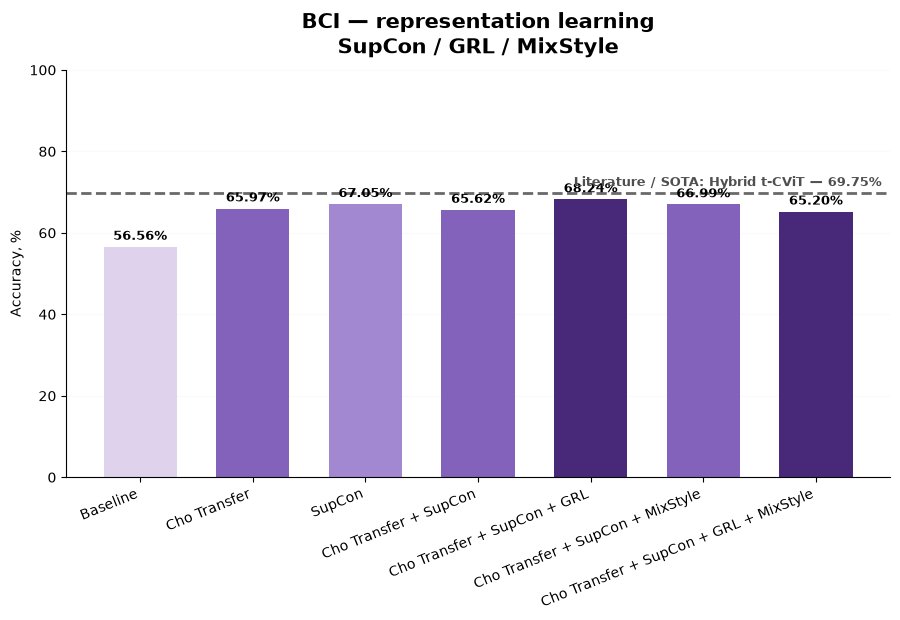

✓ 06_PhysioNet_representation_subject_invariant.png


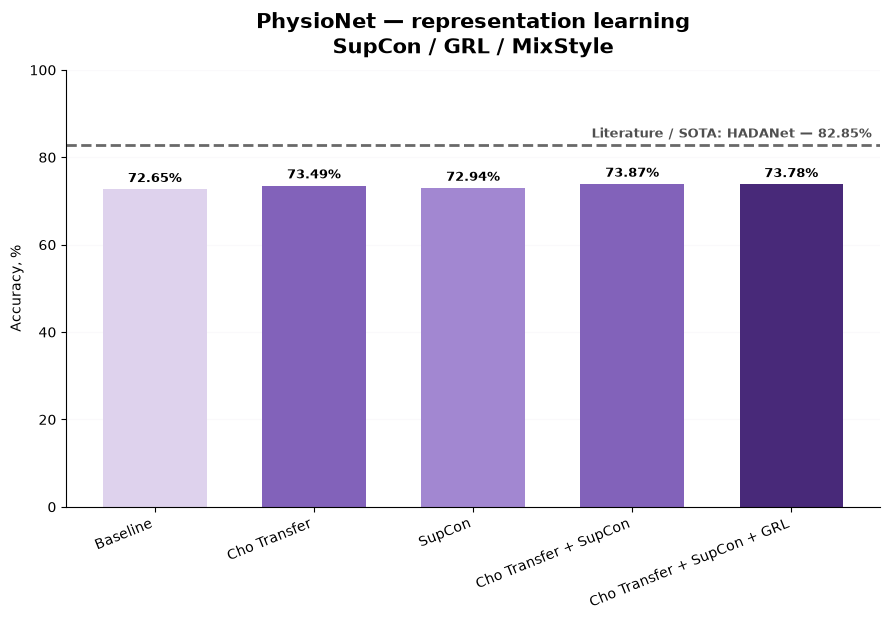

✓ 08_PhysioNet_denoiser_ablation.png


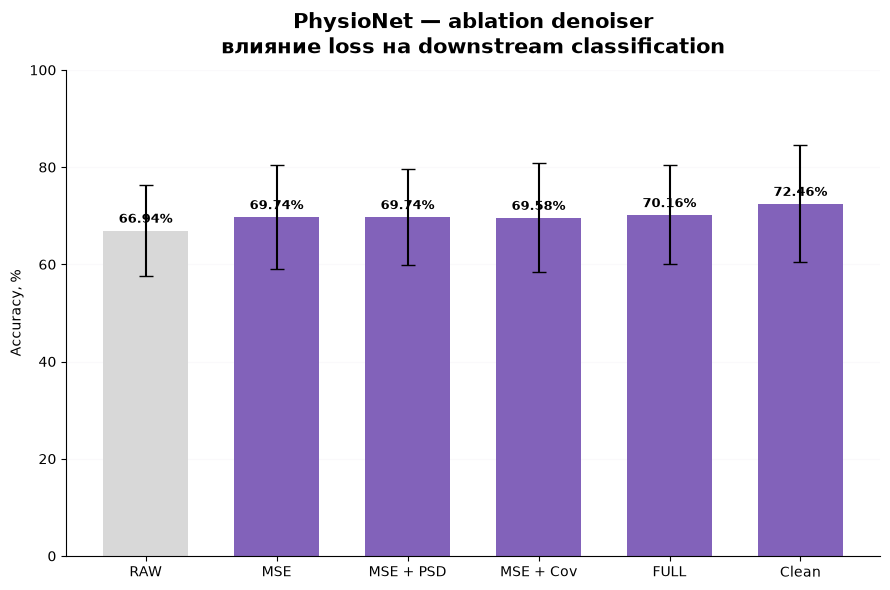

✓ 09_BCI_robustness.png


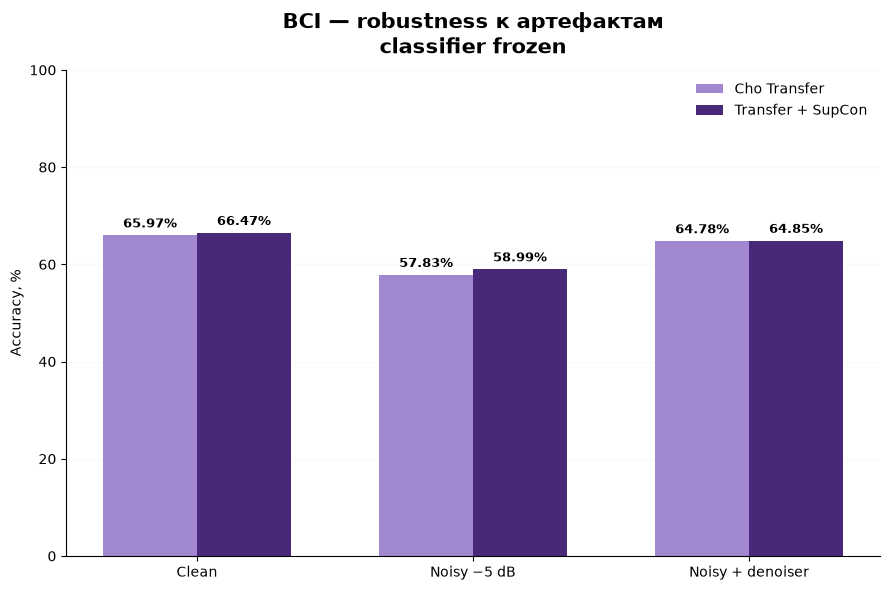

✓ 10_PhysioNet_robustness.png


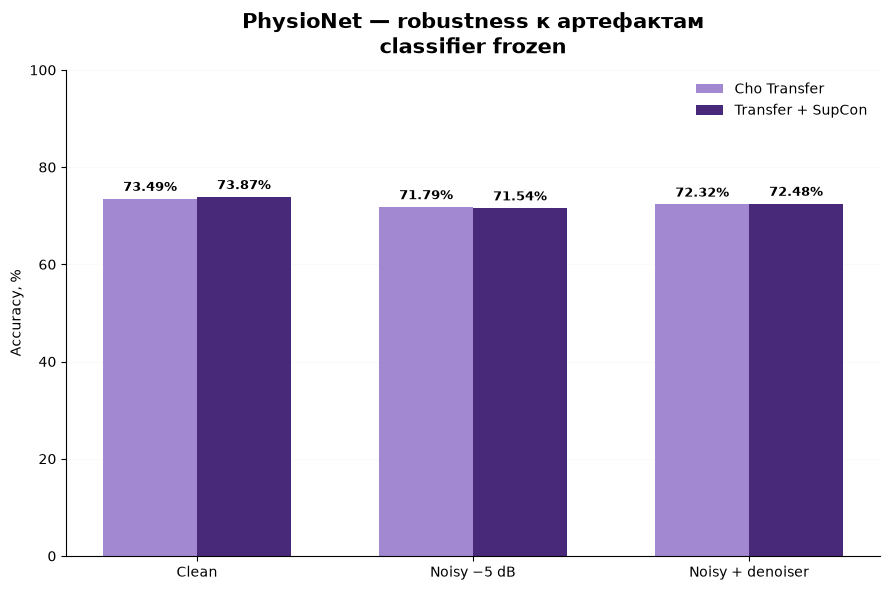

✓ 11_BCI_multiseed_stability.png


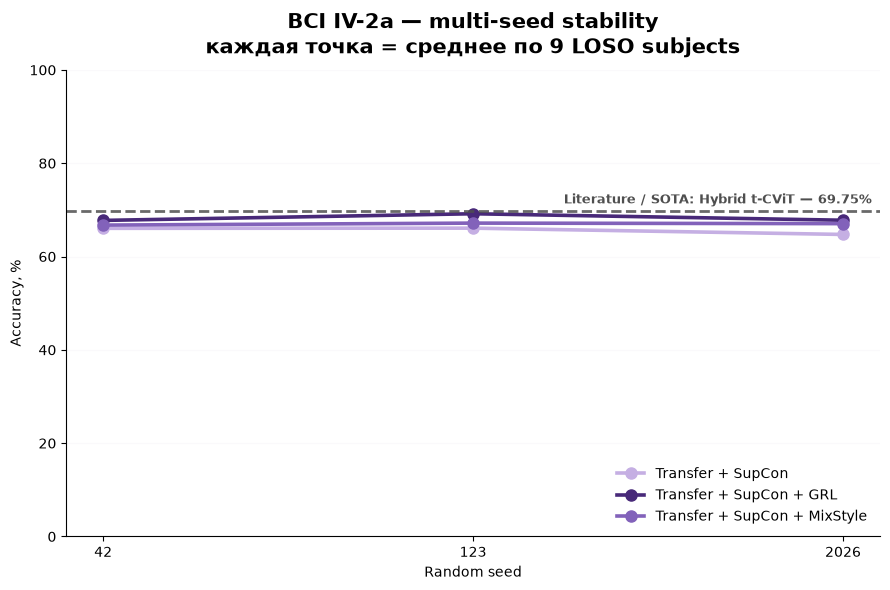

✓ 12_BCI_multiseed_validation_vs_test.png


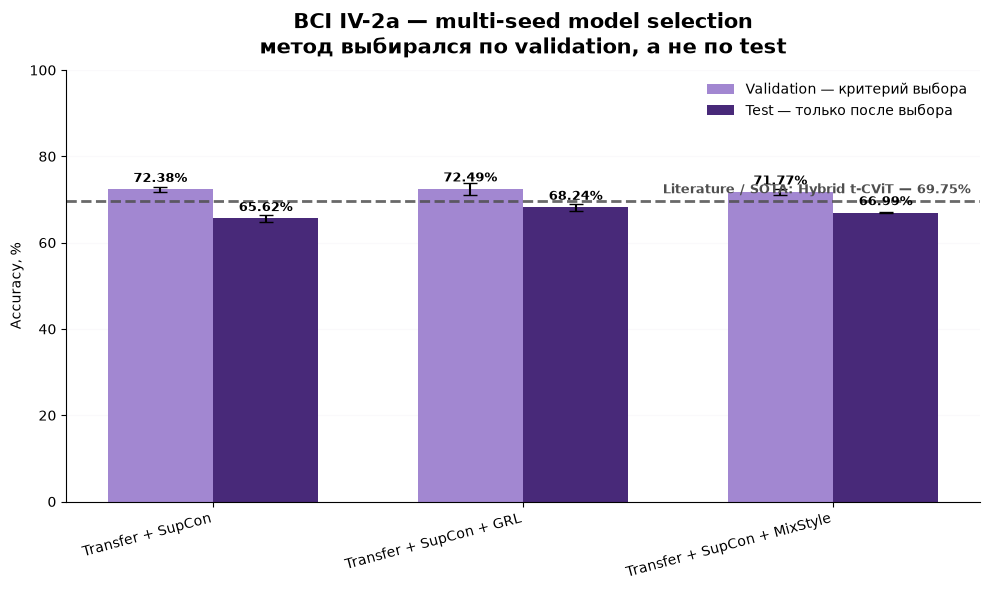

✓ 13_final_frozen_pipeline.png


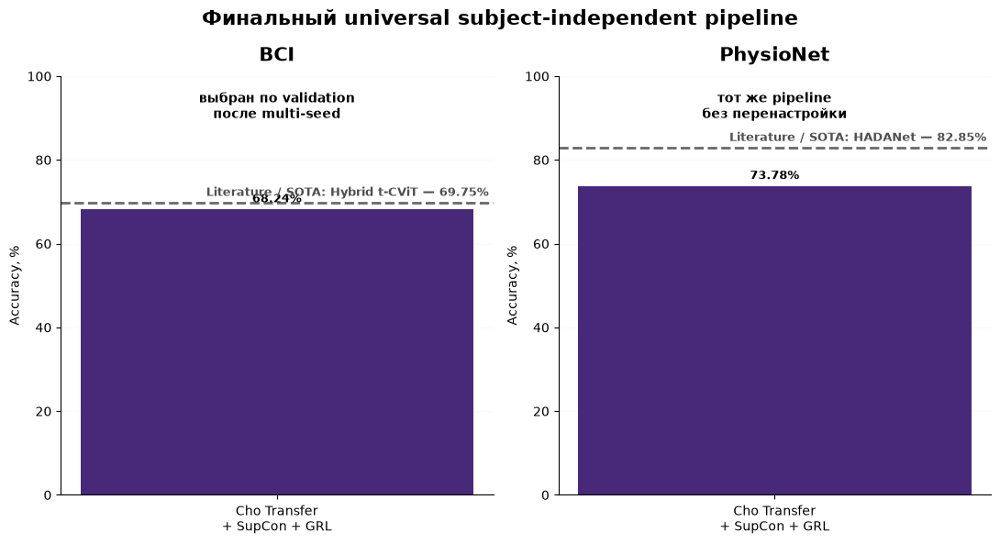


ГОТОВО — ГРАФИКИ ДЛЯ ОТЧЁТА
05_BCI_representation_subject_invariant.png
06_PhysioNet_representation_subject_invariant.png
08_PhysioNet_denoiser_ablation.png
09_BCI_robustness.png
10_PhysioNet_robustness.png
11_BCI_multiseed_stability.png
12_BCI_multiseed_validation_vs_test.png
13_final_frozen_pipeline.png

Папка: /Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/FINAL_REPORT_FIGURES


In [149]:
# ============================================================
# FINAL MASTER REPORT FIGURES
#
# Что рисуем:
#
# 01 BCI        — Domain Generalization
# 02 PhysioNet  — Domain Generalization
# 03 BCI        — architecture / alignment
# 04 PhysioNet  — architecture / alignment
# 05 BCI        — SupCon / GRL / MixStyle
# 06 PhysioNet  — SupCon / frozen GRL
# 07 BCI        — denoiser ablation
# 08 PhysioNet  — denoiser ablation
# 09 BCI        — clean / noisy / denoised
# 10 PhysioNet  — clean / noisy / denoised
# 11 BCI        — multi-seed stability
# 12 BCI        — validation vs test after multi-seed
# 13 Final      — frozen pipeline BCI -> PhysioNet
#
# IMPORTANT:
# - наши accuracy НЕ вводятся руками
# - старые CSV находятся автоматически по содержимому
# - все accuracy-графики начинаются с 0
# - SOTA = одна верхняя literature reference line
# ============================================================

# from pathlib import Path
# import warnings

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# warnings.filterwarnings("ignore")


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/Users/irina/Desktop/master project"
)

ROOT = (
    PROJECT_ROOT
    / "results_v2"
)

OUT_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "FINAL_REPORT_FIGURES"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# COLORS
# ============================================================

PURPLE_0 = "#EEE8F6"
PURPLE_1 = "#DED2ED"
PURPLE_2 = "#C5AFE3"
PURPLE_3 = "#A287D1"
PURPLE_4 = "#8262BA"
PURPLE_5 = "#65449E"
PURPLE_6 = "#482979"

GREY = "#4F4F4F"
LIGHT_GREY = "#B7B7B7"
GRID = "#EAE5F0"

RAW_COLOR = "#D8D8D8"


# ============================================================
# LITERATURE
#
# BCI берём автоматически из сохранённого literature CSV.
# PhysioNet: добавляем сильный опубликованный reference HADANet.
# ============================================================

PHYSIONET_HADANET = 82.85


# ============================================================
# HELPERS
# ============================================================

def detect_col(df, candidates):

    lookup = {
        str(c).lower(): c
        for c in df.columns
    }

    for candidate in candidates:

        if candidate.lower() in lookup:

            return lookup[
                candidate.lower()
            ]

    return None


def to_pct(values):

    s = pd.to_numeric(
        values,
        errors="coerce",
    )

    if (
        len(s.dropna()) > 0
        and
        s.dropna().max() <= 1.5
    ):

        s = s * 100

    return s


def norm_dataset(x):

    s = str(x).lower()

    if "bci" in s:
        return "BCI"

    if "phys" in s:
        return "PhysioNet"

    return None


METHOD_MAP = {

    # standard
    "baseline":
        "Baseline",

    "scratch":
        "Baseline",

    "transfer":
        "Cho Transfer",

    "cho_transfer":
        "Cho Transfer",

    # DG
    "coral":
        "CORAL",

    "transfer_coral":
        "Transfer + CORAL",

    "mmd":
        "MMD",

    "transfer_mmd":
        "Transfer + MMD",

    "dann":
        "DANN",

    "transfer_dann":
        "Transfer + DANN",

    # SupCon
    "supcon":
        "SupCon",

    "transfer_supcon":
        "Transfer + SupCon",

    "transfer_supcon_control":
        "Transfer + SupCon",

    # Subject invariant
    "transfer_supcon_grl":
        "Transfer + SupCon + GRL",

    "transfer_supcon_mixstyle":
        "Transfer + SupCon + MixStyle",

    "transfer_supcon_grl_mixstyle":
        "Transfer + SupCon + GRL + MixStyle",

    # architecture
    "two_head":
        "Two-head",

    "two_head_baseline":
        "Two-head",

    "two_head_transfer":
        "Two-head + Transfer",

    "dsbn":
        "DSBN",

    "dsbn_transfer":
        "DSBN + Transfer",

    "dsbn_two_head_baseline":
        "Two-head + DSBN",

    "dsbn_two_head_transfer":
        "Two-head + DSBN + Transfer",

    "partial_share":
        "Partial sharing",

    "partial_share_baseline":
        "Partial sharing",

    "partial_share_transfer":
        "Partial sharing + Transfer",
}


def pretty_method(x):

    raw = str(x).strip()

    key = (
        raw.lower()
        .replace("+", "_")
        .replace("-", "_")
        .replace(" ", "_")
    )

    while "__" in key:
        key = key.replace(
            "__",
            "_",
        )

    return METHOD_MAP.get(
        key,
        raw,
    )


def style_accuracy_axis(
    ax,
    title,
):

    ax.set_ylim(
        0,
        100,
    )

    ax.set_ylabel(
        "Accuracy, %"
    )

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=12,
    )

    ax.grid(
        axis="y",
        alpha=0.22,
        color=GRID,
    )

    ax.set_axisbelow(
        True
    )

    ax.spines[
        ["top", "right"]
    ].set_visible(
        False
    )


def label_bars(
    ax,
    bars,
    offset=1.0,
):

    for bar in bars:

        h = bar.get_height()

        if np.isfinite(h):

            ax.text(
                bar.get_x()
                + bar.get_width() / 2,
                h + offset,
                f"{h:.2f}%",
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
            )


def save_fig(
    fig,
    name,
):

    path = (
        OUT_DIR
        / name
    )

    fig.tight_layout()

    fig.savefig(
        path,
        dpi=250,
        bbox_inches="tight",
    )

    print(
        "✓",
        name
    )


# ============================================================
# LITERATURE / SOTA
# ============================================================

LIT_PATH = (
    ROOT
    / "strict_loso_denoising_binary"
    / "tables"
    / "06_sota_reference.csv"
)

lit = pd.read_csv(
    LIT_PATH
)

lit_dataset_col = detect_col(
    lit,
    ["dataset"],
)

lit_model_col = detect_col(
    lit,
    ["model", "method"],
)

lit_acc_col = detect_col(
    lit,
    ["accuracy", "accuracy_pct"],
)

lit["_dataset"] = (
    lit[
        lit_dataset_col
    ]
    .map(
        norm_dataset
    )
)

lit["_accuracy"] = to_pct(
    lit[
        lit_acc_col
    ]
)


def best_literature_reference(
    dataset,
):

    if dataset == "PhysioNet":

        saved = lit[
            lit["_dataset"]
            == "PhysioNet"
        ]["_accuracy"]

        best_saved = (
            saved.max()
            if len(saved)
            else np.nan
        )

        # strongest literature reference
        if (
            np.isnan(best_saved)
            or
            PHYSIONET_HADANET
            > best_saved
        ):
            return (
                "HADANet",
                PHYSIONET_HADANET,
            )


    part = lit[
        lit["_dataset"]
        == dataset
    ]

    if len(part) == 0:
        return None, None


    idx = part[
        "_accuracy"
    ].idxmax()


    name = (
        str(
            part.loc[
                idx,
                lit_model_col,
            ]
        )
        if lit_model_col
        is not None
        else
        "Literature"
    )


    value = (
        part.loc[
            idx,
            "_accuracy",
        ]
    )


    return (
        name,
        value,
    )


def add_sota(
    ax,
    dataset,
):

    name, value = (
        best_literature_reference(
            dataset
        )
    )

    if value is None:
        return


    ax.axhline(
        value,
        color=GREY,
        linestyle="--",
        linewidth=2.0,
        alpha=0.85,
    )


    ax.text(
        0.99,
        value + 1.0,
        (
            f"Literature / SOTA: "
            f"{name} — {value:.2f}%"
        ),
        transform=
            ax.get_yaxis_transform(),
        ha="right",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color=GREY,
    )


# ============================================================
# UNIVERSAL CSV SCAN
#
# Сканируем один раз.
# Никаких диагностических выводов.
# ============================================================

ALL_CSV = []

for p in PROJECT_ROOT.rglob(
    "*.csv"
):

    text = str(
        p
    ).lower()


    if (
        "history" in text
        or
        "histories" in text
    ):
        continue


    try:

        d = pd.read_csv(
            p
        )

    except Exception:

        continue


    if len(d) == 0:
        continue


    ALL_CSV.append(
        (
            p,
            d,
        )
    )


# ============================================================
# EXTRACT GENERIC CLASSIFICATION RESULT
# ============================================================

def extract_classification_result(
    path,
    df,
):

    method_col = detect_col(
        df,
        [
            "method",
            "model",
            "approach",
            "variant",
            "configuration",
            "config",
            "architecture",
        ],
    )


    acc_col = detect_col(
        df,
        [
            "accuracy",
            "test_accuracy",
            "mean_accuracy",
            "mean_test_accuracy",
            "acc",
        ],
    )


    dataset_col = detect_col(
        df,
        [
            "dataset",
            "data",
        ],
    )


    if (
        method_col is None
        or
        acc_col is None
    ):
        return pd.DataFrame()


    tmp = df.copy()


    # clean only
    condition_col = detect_col(
        tmp,
        [
            "condition",
            "state",
        ],
    )


    if condition_col is not None:

        cond = (
            tmp[
                condition_col
            ]
            .astype(str)
            .str.lower()
        )

        if (
            cond == "clean"
        ).any():

            tmp = tmp[
                cond == "clean"
            ].copy()


    if len(tmp) == 0:

        return pd.DataFrame()


    # dataset
    if dataset_col is not None:

        tmp["_dataset"] = (
            tmp[
                dataset_col
            ]
            .map(
                norm_dataset
            )
        )

    else:

        dataset_guess = norm_dataset(
            str(
                path
            )
        )

        tmp["_dataset"] = (
            dataset_guess
        )


    tmp["_method"] = (
        tmp[
            method_col
        ]
        .map(
            pretty_method
        )
    )


    tmp["_accuracy"] = to_pct(
        tmp[
            acc_col
        ]
    )


    tmp = tmp.dropna(
        subset=[
            "_dataset",
            "_accuracy",
        ]
    )


    if len(tmp) == 0:

        return pd.DataFrame()


    result = (
        tmp
        .groupby(
            [
                "_dataset",
                "_method",
            ],
            as_index=False,
        )
        .agg(
            mean_accuracy=(
                "_accuracy",
                "mean",
            ),

            std_accuracy=(
                "_accuracy",
                "std",
            ),

            n=(
                "_accuracy",
                "size",
            ),
        )
        .rename(
            columns={
                "_dataset":
                    "dataset",

                "_method":
                    "method",
            }
        )
    )


    result[
        "source_file"
    ] = str(
        path.relative_to(
            PROJECT_ROOT
        )
    )


    return result


# ============================================================
# ALL CLASSIFICATION CANDIDATES
# ============================================================

classification_parts = []


for path, df in ALL_CSV:

    part = extract_classification_result(
        path,
        df,
    )

    if len(part):

        classification_parts.append(
            part
        )


if classification_parts:

    CLASS_ALL = pd.concat(
        classification_parts,
        ignore_index=True,
    )

else:

    CLASS_ALL = pd.DataFrame(
        columns=[
            "dataset",
            "method",
            "mean_accuracy",
            "std_accuracy",
            "n",
            "source_file",
        ]
    )


# ============================================================
# SOURCE QUALITY
#
# Чтобы не брать progress.csv вместо final.
# ============================================================

def source_score(
    source,
):

    s = str(
        source
    ).lower()

    score = 0


    if "summary" in s:
        score += 30

    if "final" in s:
        score += 25

    if "results" in s:
        score += 10

    if "progress" in s:
        score -= 30

    if "checkpoint" in s:
        score -= 20

    return score


CLASS_ALL[
    "source_score"
] = (
    CLASS_ALL[
        "source_file"
    ]
    .map(
        source_score
    )
)


# ============================================================
# BRANCH PICKER
#
# Выбирает один связный экспериментальный источник,
# в котором присутствует максимум нужных методов.
# ============================================================

def pick_branch(
    wanted_tokens,
    dataset,
):

    candidates = []


    for source in CLASS_ALL[
        "source_file"
    ].unique():

        part = CLASS_ALL[
            (
                CLASS_ALL[
                    "source_file"
                ]
                == source
            )
            &
            (
                CLASS_ALL[
                    "dataset"
                ]
                == dataset
            )
        ].copy()


        if len(part) == 0:
            continue


        names = (
            part[
                "method"
            ]
            .astype(str)
            .str.lower()
            .tolist()
        )


        hits = 0


        for token in wanted_tokens:

            if any(
                token.lower()
                in name
                for name in names
            ):
                hits += 1


        if hits == 0:
            continue


        score = (
            hits * 100
            +
            source_score(
                source
            )
            +
            min(
                len(part),
                20,
            )
        )


        candidates.append(
            (
                score,
                source,
                part,
            )
        )


    if not candidates:

        return pd.DataFrame()


    candidates = sorted(
        candidates,
        key=lambda x: x[0],
        reverse=True,
    )


    return (
        candidates[0][2]
        .drop_duplicates(
            subset=[
                "method",
            ]
        )
        .copy()
    )


# ============================================================
# GENERIC METHOD PLOT
# ============================================================

def plot_branch(
    table,
    dataset,
    title,
    filename,
    order=None,
    sota=True,
):

    if (
        table is None
        or
        len(table) == 0
    ):

        return


    part = table.copy()


    if order is not None:

        part[
            "_order"
        ] = (
            part[
                "method"
            ]
            .map({
                name: i
                for i, name
                in enumerate(
                    order
                )
            })
            .fillna(
                999
            )
        )


        part = (
            part
            .sort_values(
                "_order"
            )
            .reset_index(
                drop=True
            )
        )


    fig, ax = plt.subplots(
        figsize=(
            max(
                9,
                len(part)
                * 1.3,
            ),
            6.3,
        )
    )


    x = np.arange(
        len(part)
    )


    colors = []


    for method in part[
        "method"
    ]:

        if method == "Baseline":

            colors.append(
                PURPLE_1
            )

        elif (
            "GRL"
            in method
            or
            "DANN"
            in method
        ):

            colors.append(
                PURPLE_6
            )

        elif (
            "Transfer"
            in method
        ):

            colors.append(
                PURPLE_4
            )

        else:

            colors.append(
                PURPLE_3
            )


    bars = ax.bar(
        x,
        part[
            "mean_accuracy"
        ],
        width=0.65,
        color=colors,
    )


    label_bars(
        ax,
        bars,
    )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        part[
            "method"
        ],
        rotation=22,
        ha="right",
    )


    style_accuracy_axis(
        ax,
        title,
    )


    if sota:

        add_sota(
            ax,
            dataset,
        )


    save_fig(
        fig,
        filename,
    )

    plt.show()


# ============================================================
# ============================================================
# 01–02 DOMAIN GENERALIZATION
# ============================================================
# ============================================================

DG_TOKENS = [
    "coral",
    "mmd",
    "dann",
]


DG_ORDER = [
    "Baseline",
    "Cho Transfer",
    "CORAL",
    "Transfer + CORAL",
    "MMD",
    "Transfer + MMD",
    "DANN",
    "Transfer + DANN",
]


bci_dg = pick_branch(
    DG_TOKENS,
    "BCI",
)

phys_dg = pick_branch(
    DG_TOKENS,
    "PhysioNet",
)


plot_branch(
    bci_dg,
    "BCI",
    (
        "BCI IV-2a — Domain Generalization\n"
        "что дали CORAL / MMD / DANN"
    ),
    "01_BCI_domain_generalization.png",
    DG_ORDER,
    sota=True,
)


plot_branch(
    phys_dg,
    "PhysioNet",
    (
        "PhysioNet — Domain Generalization\n"
        "Baseline / Transfer / CORAL / MMD / DANN"
    ),
    "02_PhysioNet_domain_generalization.png",
    DG_ORDER,
    sota=True,
)


# ============================================================
# ============================================================
# 03–04 ARCHITECTURE / ALIGNMENT
# ============================================================
# ============================================================

ARCH_TOKENS = [
    "dsbn",
    "partial",
    "two-head",
    "two_head",
]


ARCH_ORDER = [
    "Baseline",
    "Cho Transfer",
    "Two-head",
    "Two-head + Transfer",
    "DSBN",
    "DSBN + Transfer",
    "Two-head + DSBN",
    "Two-head + DSBN + Transfer",
    "Partial sharing",
    "Partial sharing + Transfer",
]


bci_arch = pick_branch(
    ARCH_TOKENS,
    "BCI",
)

phys_arch = pick_branch(
    ARCH_TOKENS,
    "PhysioNet",
)


plot_branch(
    bci_arch,
    "BCI",
    (
        "BCI IV-2a — архитектурные варианты\n"
        "Two-head / DSBN / Partial sharing"
    ),
    "03_BCI_architecture_alignment.png",
    ARCH_ORDER,
    sota=True,
)


plot_branch(
    phys_arch,
    "PhysioNet",
    (
        "PhysioNet — архитектурные варианты\n"
        "Two-head / DSBN / Partial sharing"
    ),
    "04_PhysioNet_architecture_alignment.png",
    ARCH_ORDER,
    sota=True,
)


# ============================================================
# ============================================================
# 05–06 REPRESENTATION / SUBJECT-INVARIANT
#
# Здесь берём конкретно уже собранные финальные файлы,
# а не смешиваем разные branches.
# ============================================================
# ============================================================

ALL_METHODS_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "all_methods_plots"
    / "all_methods_summary.csv"
)


all_methods = pd.read_csv(
    ALL_METHODS_PATH
)


REP_ORDER = [
    "Baseline",
    "Cho Transfer",
    "SupCon",
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
    "Cho Transfer + SupCon + GRL + MixStyle",
]


for dataset, filename in [
    (
        "BCI",
        "05_BCI_representation_subject_invariant.png",
    ),
    (
        "PhysioNet",
        "06_PhysioNet_representation_subject_invariant.png",
    ),
]:

    part = (
        all_methods[
            all_methods[
                "dataset"
            ]
            == dataset
        ]
        .copy()
    )


    part = part[
        part[
            "method"
        ]
        .isin(
            REP_ORDER
        )
    ].copy()


    plot_branch(
        part,
        dataset,
        (
            f"{dataset} — representation learning\n"
            "SupCon / GRL / MixStyle"
        ),
        filename,
        REP_ORDER,
        sota=True,
    )


# ============================================================
# ============================================================
# 07–08 DENOISER ABLATION
# ============================================================
# ============================================================

def find_best_ablation(
    dataset,
):

    candidates = []


    for path, df in ALL_CSV:

        method_col = detect_col(
            df,
            [
                "method",
                "variant",
                "loss",
                "model",
                "denoiser",
            ],
        )


        acc_col = detect_col(
            df,
            [
                "accuracy",
                "test_accuracy",
                "classification_accuracy",
                "downstream_accuracy",
            ],
        )


        if (
            method_col is None
            or
            acc_col is None
        ):
            continue


        # dataset
        dataset_col = detect_col(
            df,
            [
                "dataset",
            ],
        )


        if dataset_col is not None:

            ds_values = (
                df[
                    dataset_col
                ]
                .map(
                    norm_dataset
                )
            )

            if (
                ds_values
                == dataset
            ).sum() == 0:

                continue

            work = df[
                ds_values
                == dataset
            ].copy()

        else:

            guess = norm_dataset(
                str(
                    path
                )
            )

            if guess != dataset:

                continue

            work = df.copy()


        methods_here = (
            work[
                method_col
            ]
            .astype(str)
            .str.upper()
            .tolist()
        )


        score = 0


        for token in [
            "RAW",
            "MSE",
            "PSD",
            "COV",
            "FULL",
        ]:

            if any(
                token
                in m
                for m
                in methods_here
            ):

                score += 1


        if score < 3:
            continue


        source_quality = (
            source_score(
                str(
                    path
                )
            )
        )


        candidates.append(
            (
                score * 100
                + source_quality
                + min(
                    len(work),
                    100,
                ),
                path,
                work,
                method_col,
                acc_col,
            )
        )


    if not candidates:

        return pd.DataFrame()


    candidates = sorted(
        candidates,
        key=lambda x: x[0],
        reverse=True,
    )


    (
        _,
        path,
        work,
        method_col,
        acc_col,
    ) = candidates[0]


    work = work.copy()


    work[
        "_accuracy"
    ] = to_pct(
        work[
            acc_col
        ]
    )


    summary = (
        work
        .groupby(
            method_col,
            as_index=False,
        )
        .agg(
            mean_accuracy=(
                "_accuracy",
                "mean",
            ),

            std_accuracy=(
                "_accuracy",
                "std",
            ),

            n=(
                "_accuracy",
                "size",
            ),
        )
        .rename(
            columns={
                method_col:
                    "method"
            }
        )
    )


    return summary


def ablation_label(
    x,
):

    s = (
        str(x)
        .upper()
        .replace(
            "+",
            "_"
        )
        .replace(
            " ",
            "_"
        )
    )


    if (
        "RAW"
        in s
    ):
        return "RAW"

    if (
        "FULL"
        in s
    ):
        return "FULL"

    if (
        "PSD"
        in s
        and
        "MSE"
        in s
    ):
        return "MSE + PSD"

    if (
        "COV"
        in s
        and
        "MSE"
        in s
    ):
        return "MSE + Cov"

    if (
        s == "MSE"
        or
        s.endswith(
            "_MSE"
        )
    ):
        return "MSE"

    return str(x)


def plot_ablation(
    data,
    dataset,
    filename,
):

    if len(data) == 0:
        return


    d = data.copy()


    d[
        "label"
    ] = (
        d[
            "method"
        ]
        .map(
            ablation_label
        )
    )


    order = [
        "RAW",
        "MSE",
        "MSE + PSD",
        "MSE + Cov",
        "FULL",
    ]


    d[
        "_order"
    ] = (
        d[
            "label"
        ]
        .map({
            m: i
            for i, m
            in enumerate(
                order
            )
        })
        .fillna(
            999
        )
    )


    d = (
        d
        .sort_values(
            "_order"
        )
        .drop_duplicates(
            "label"
        )
        .reset_index(
            drop=True
        )
    )


    fig, ax = plt.subplots(
        figsize=(9, 6)
    )


    x = np.arange(
        len(d)
    )


    colors = [
        (
            RAW_COLOR
            if label
            == "RAW"
            else
            PURPLE_4
        )
        for label
        in d[
            "label"
        ]
    ]


    bars = ax.bar(
        x,
        d[
            "mean_accuracy"
        ],
        yerr=
            d[
                "std_accuracy"
            ],
        capsize=5,
        width=0.65,
        color=colors,
    )


    label_bars(
        ax,
        bars,
    )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        d[
            "label"
        ]
    )


    style_accuracy_axis(
        ax,
        (
            f"{dataset} — ablation denoiser\n"
            "влияние loss на downstream classification"
        ),
    )


    save_fig(
        fig,
        filename,
    )

    plt.show()


bci_ablation = find_best_ablation(
    "BCI"
)

phys_ablation = find_best_ablation(
    "PhysioNet"
)


plot_ablation(
    bci_ablation,
    "BCI IV-2a",
    "07_BCI_denoiser_ablation.png",
)


plot_ablation(
    phys_ablation,
    "PhysioNet",
    "08_PhysioNet_denoiser_ablation.png",
)


# ============================================================
# ============================================================
# 09–10 ROBUSTNESS
# ============================================================
# ============================================================

FROZEN_SUMMARY_PATH = (
    ROOT
    / "strict_loso_frozen_final"
    / "strict_loso_frozen_summary.csv"
)


frozen = pd.read_csv(
    FROZEN_SUMMARY_PATH
)


CONDITIONS = [
    "clean",
    "noisy",
    "noisy_denoised",
]


CONDITION_LABELS = {
    "clean":
        "Clean",

    "noisy":
        "Noisy −5 dB",

    "noisy_denoised":
        "Noisy + denoiser",
}


ROBUST_METHODS = {
    "transfer":
        "Cho Transfer",

    "transfer_supcon":
        "Transfer + SupCon",
}


def plot_robustness(
    dataset,
    filename,
):

    part = frozen[
        (
            frozen[
                "dataset"
            ]
            == dataset
        )
        &
        (
            frozen[
                "method"
            ]
            .isin(
                ROBUST_METHODS.keys()
            )
        )
        &
        (
            frozen[
                "condition"
            ]
            .isin(
                CONDITIONS
            )
        )
    ].copy()


    if len(part) == 0:
        return


    fig, ax = plt.subplots(
        figsize=(9, 6)
    )


    x = np.arange(
        len(
            CONDITIONS
        )
    )

    width = 0.34


    for offset, method, color in [

        (
            -width / 2,
            "transfer",
            PURPLE_3,
        ),

        (
            width / 2,
            "transfer_supcon",
            PURPLE_6,
        ),
    ]:

        vals = []


        for condition in CONDITIONS:

            row = part[
                (
                    part[
                        "method"
                    ]
                    == method
                )
                &
                (
                    part[
                        "condition"
                    ]
                    == condition
                )
            ]


            if len(row):

                value = (
                    row.iloc[0][
                        "mean_accuracy"
                    ]
                )

                if value <= 1.5:
                    value *= 100

            else:

                value = np.nan


            vals.append(
                value
            )


        bars = ax.bar(
            x + offset,
            vals,
            width,
            color=color,
            label=
                ROBUST_METHODS[
                    method
                ],
        )


        label_bars(
            ax,
            bars,
        )


    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        [
            CONDITION_LABELS[c]
            for c in CONDITIONS
        ]
    )


    style_accuracy_axis(
        ax,
        (
            f"{dataset} — robustness к артефактам\n"
            "classifier frozen"
        ),
    )


    ax.legend(
        frameon=False,
    )


    save_fig(
        fig,
        filename,
    )

    plt.show()


plot_robustness(
    "BCI",
    "09_BCI_robustness.png",
)


plot_robustness(
    "PhysioNet",
    "10_PhysioNet_robustness.png",
)


# ============================================================
# ============================================================
# 11 MULTI-SEED STABILITY
# ============================================================
# ============================================================

MULTI_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_multiseed_results.csv"
)


multi = pd.read_csv(
    MULTI_PATH
)


multi[
    "method_label"
] = (
    multi[
        "method"
    ]
    .map(
        pretty_method
    )
)


seed_level = (
    multi
    .groupby(
        [
            "method_label",
            "seed_base",
        ],
        as_index=False,
    )
    .agg(
        validation=(
            "best_val_accuracy",
            "mean",
        ),

        test=(
            "accuracy",
            "mean",
        ),
    )
)


seed_level[
    "validation"
] = to_pct(
    seed_level[
        "validation"
    ]
)

seed_level[
    "test"
] = to_pct(
    seed_level[
        "test"
    ]
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


SEED_COLORS = {

    "Transfer + SupCon":
        PURPLE_2,

    "Transfer + SupCon + GRL":
        PURPLE_6,

    "Transfer + SupCon + MixStyle":
        PURPLE_4,
}


for method in [

    "Transfer + SupCon",
    "Transfer + SupCon + GRL",
    "Transfer + SupCon + MixStyle",
]:

    part = (
        seed_level[
            seed_level[
                "method_label"
            ]
            == method
        ]
        .sort_values(
            "seed_base"
        )
    )


    if len(part) == 0:
        continue


    ax.plot(
        part[
            "seed_base"
        ].astype(str),
        part[
            "test"
        ],
        marker="o",
        markersize=8,
        linewidth=2.6,
        color=
            SEED_COLORS[
                method
            ],
        label=method,
    )


style_accuracy_axis(
    ax,
    (
        "BCI IV-2a — multi-seed stability\n"
        "каждая точка = среднее по 9 LOSO subjects"
    ),
)


add_sota(
    ax,
    "BCI",
)


ax.set_xlabel(
    "Random seed"
)

ax.legend(
    frameon=False,
    loc="lower right",
)


save_fig(
    fig,
    "11_BCI_multiseed_stability.png",
)

plt.show()


# ============================================================
# ============================================================
# 12 VALIDATION vs TEST
#
# Это понятнее прежней mean±SD картинки:
# видно, ПОЧЕМУ GRL был выбран.
# ============================================================
# ============================================================

seed_summary = (
    seed_level
    .groupby(
        "method_label",
        as_index=False,
    )
    .agg(
        validation_mean=(
            "validation",
            "mean",
        ),

        validation_std=(
            "validation",
            "std",
        ),

        test_mean=(
            "test",
            "mean",
        ),

        test_std=(
            "test",
            "std",
        ),
    )
)


ORDER = [
    "Transfer + SupCon",
    "Transfer + SupCon + GRL",
    "Transfer + SupCon + MixStyle",
]


seed_summary[
    "_order"
] = (
    seed_summary[
        "method_label"
    ]
    .map({
        m: i
        for i, m
        in enumerate(
            ORDER
        )
    })
)


seed_summary = (
    seed_summary
    .sort_values(
        "_order"
    )
    .reset_index(
        drop=True
    )
)


fig, ax = plt.subplots(
    figsize=(10, 6)
)


x = np.arange(
    len(seed_summary)
)

width = 0.34


bars_val = ax.bar(
    x - width / 2,
    seed_summary[
        "validation_mean"
    ],
    width,
    yerr=
        seed_summary[
            "validation_std"
        ],
    capsize=5,
    color=
        PURPLE_3,
    label=
        "Validation — критерий выбора",
)


bars_test = ax.bar(
    x + width / 2,
    seed_summary[
        "test_mean"
    ],
    width,
    yerr=
        seed_summary[
            "test_std"
        ],
    capsize=5,
    color=
        PURPLE_6,
    label=
        "Test — только после выбора",
)


label_bars(
    ax,
    bars_val,
)

label_bars(
    ax,
    bars_test,
)


ax.set_xticks(
    x
)

ax.set_xticklabels(
    seed_summary[
        "method_label"
    ],
    rotation=15,
    ha="right",
)


style_accuracy_axis(
    ax,
    (
        "BCI IV-2a — multi-seed model selection\n"
        "метод выбирался по validation, а не по test"
    ),
)


add_sota(
    ax,
    "BCI",
)


ax.legend(
    frameon=False,
)


save_fig(
    fig,
    "12_BCI_multiseed_validation_vs_test.png",
)

plt.show()


# ============================================================
# ============================================================
# 13 FINAL FROZEN PIPELINE
#
# Два subplot, потому что у датасетов РАЗНЫЕ SOTA.
# ============================================================
# ============================================================

SELECTION_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_method_selection_summary.csv"
)


PHYS_FINAL_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "physionet_frozen_recipe"
    / "physionet_frozen_recipe_summary.csv"
)


selection = pd.read_csv(
    SELECTION_PATH
)

phys_final = pd.read_csv(
    PHYS_FINAL_PATH
)


winner = (
    selection
    .sort_values(
        "validation_rank"
    )
    .iloc[0]
)


bci_final = (
    winner[
        "mean_test_accuracy"
    ]
)

if bci_final <= 1.5:

    bci_final *= 100


phys_final_acc = (
    phys_final
    .iloc[0][
        "mean_accuracy"
    ]
)

if phys_final_acc <= 1.5:

    phys_final_acc *= 100


fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 6),
)


for (
    ax,
    dataset,
    value,
    subtitle,
) in [

    (
        axes[0],
        "BCI",
        bci_final,
        "выбран по validation\nпосле multi-seed",
    ),

    (
        axes[1],
        "PhysioNet",
        phys_final_acc,
        "тот же pipeline\nбез перенастройки",
    ),
]:

    bars = ax.bar(
        [
            "Cho Transfer\n+ SupCon + GRL"
        ],
        [
            value
        ],
        color=
            PURPLE_6,
        width=0.48,
    )


    label_bars(
        ax,
        bars,
    )


    style_accuracy_axis(
        ax,
        dataset,
    )


    add_sota(
        ax,
        dataset,
    )


    ax.text(
        0.5,
        0.90,
        subtitle,
        transform=
            ax.transAxes,
        ha="center",
        fontsize=10,
        fontweight="bold",
    )


fig.suptitle(
    (
        "Финальный universal subject-independent pipeline"
    ),
    fontsize=16,
    fontweight="bold",
)


save_fig(
    fig,
    "13_final_frozen_pipeline.png",
)

plt.show()


# ============================================================
# MANIFEST
# ============================================================

print()
print("=" * 100)
print("ГОТОВО — ГРАФИКИ ДЛЯ ОТЧЁТА")
print("=" * 100)

for p in sorted(
    OUT_DIR.glob(
        "*.png"
    )
):

    print(
        p.name
    )


print()
print(
    "Папка:",
    OUT_DIR
)

✓ 01_protocol.png


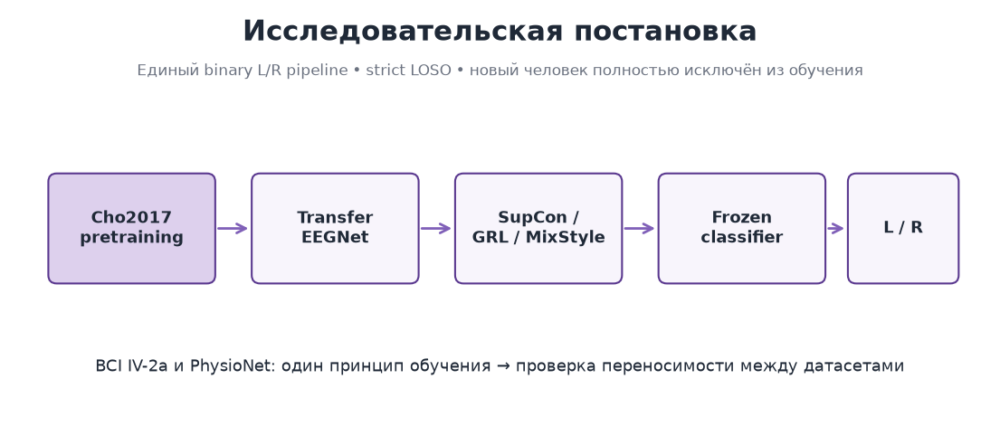

✓ 02_BCI_internal_evolution.png


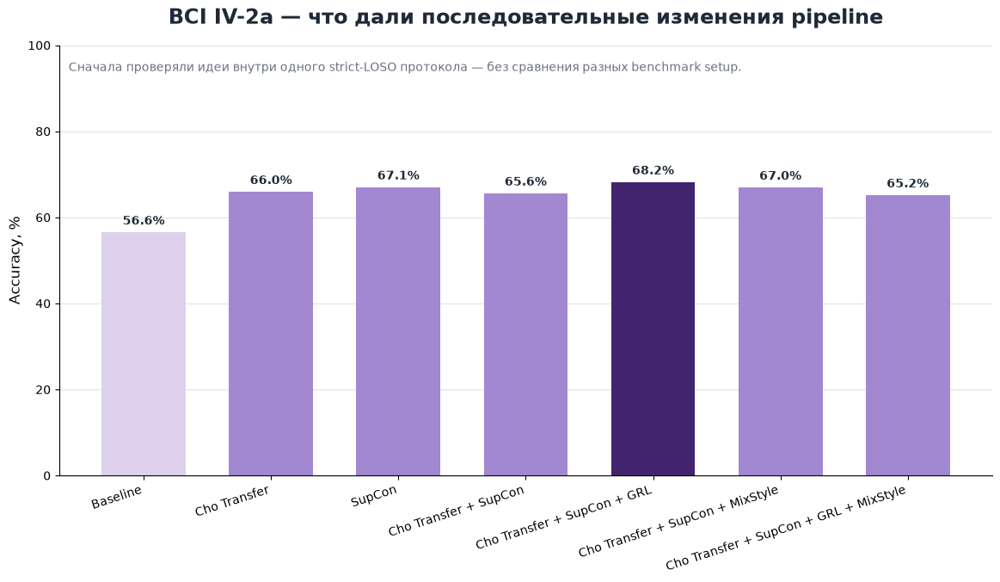

✓ 03_PhysioNet_internal_evolution.png


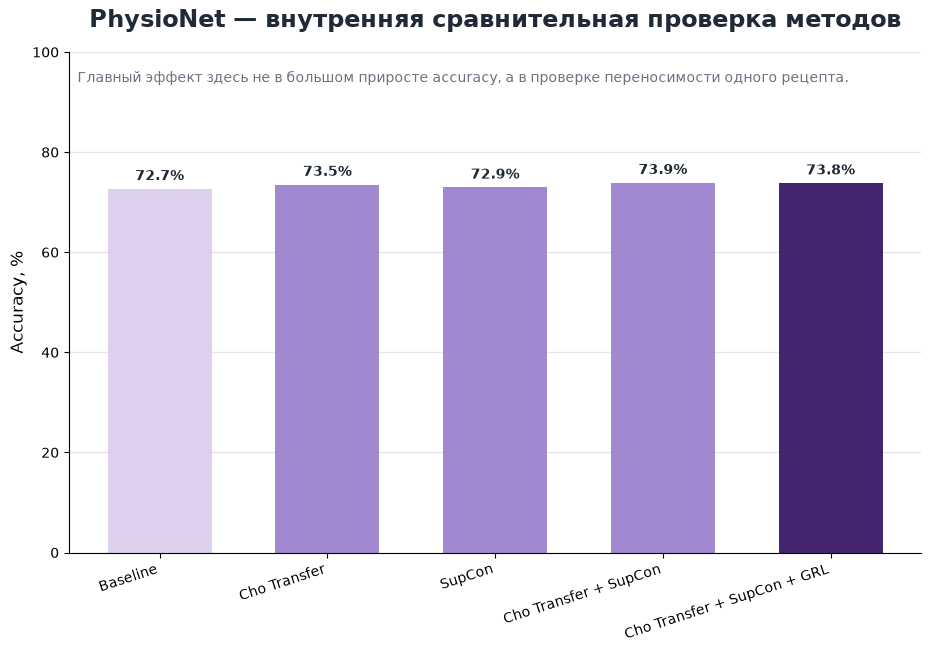

✓ 04_BCI_denoiser_ablation.png


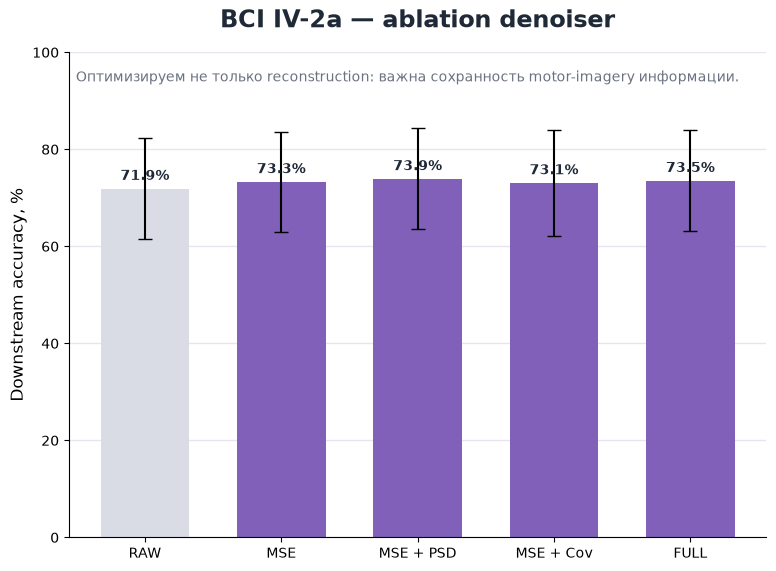

✓ 06_BCI_robustness.png


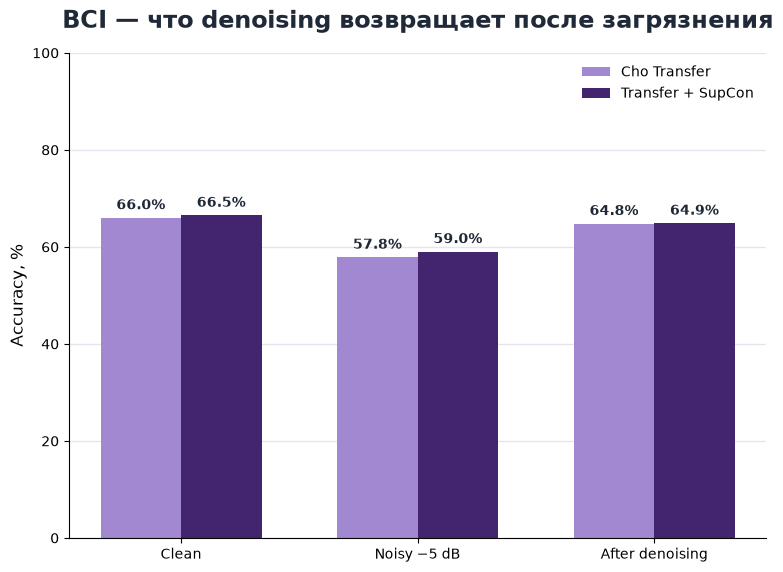

✓ 07_PhysioNet_robustness.png


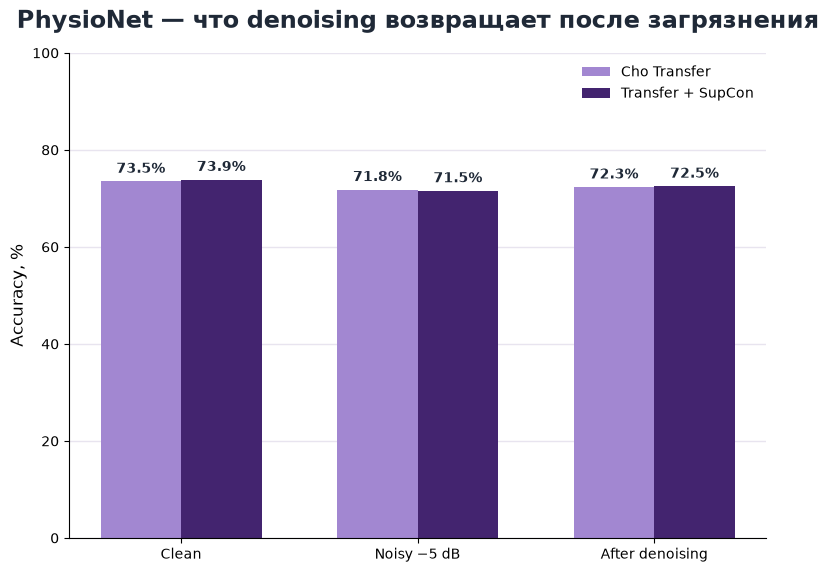

✓ 08_multiseed_stability.png


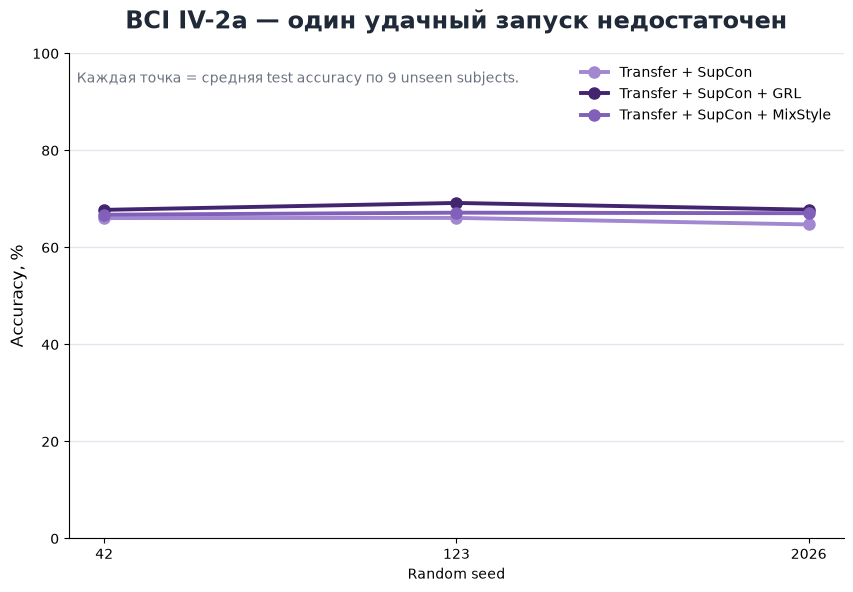

✓ 09_multiseed_selection.png


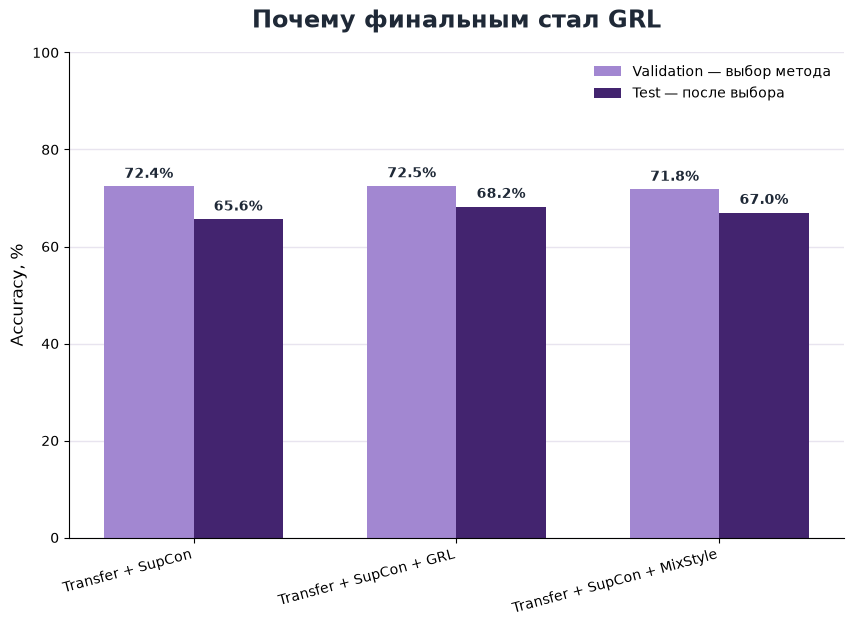

✓ 10_frozen_cross_dataset.png


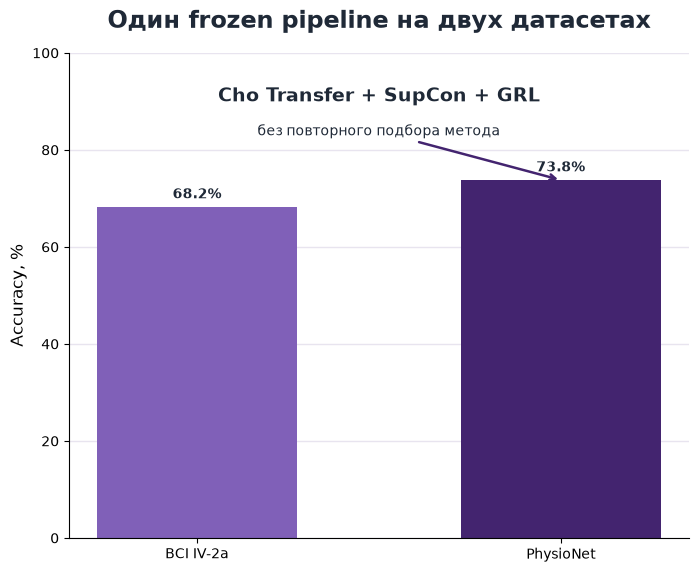

✓ 11_BCI_literature_comparison.png


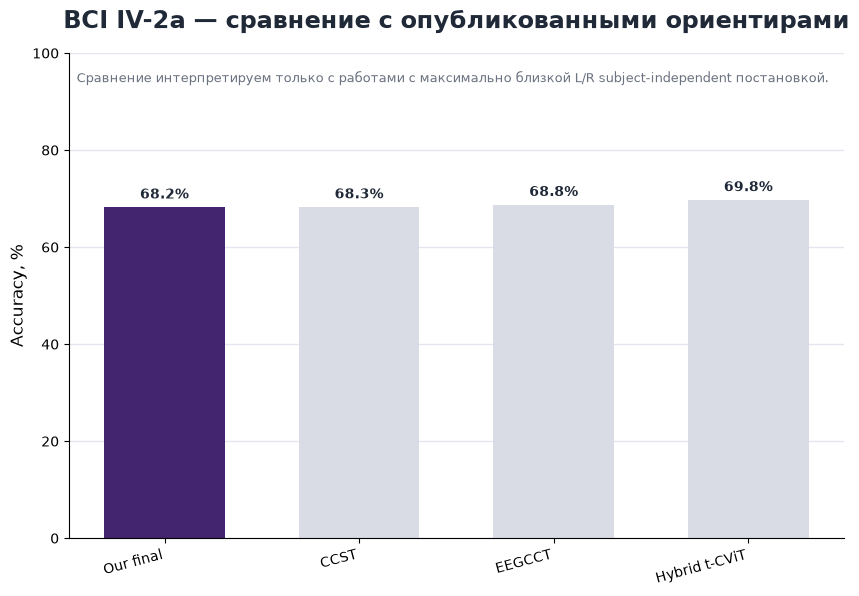

✓ 12_PhysioNet_literature_comparison.png


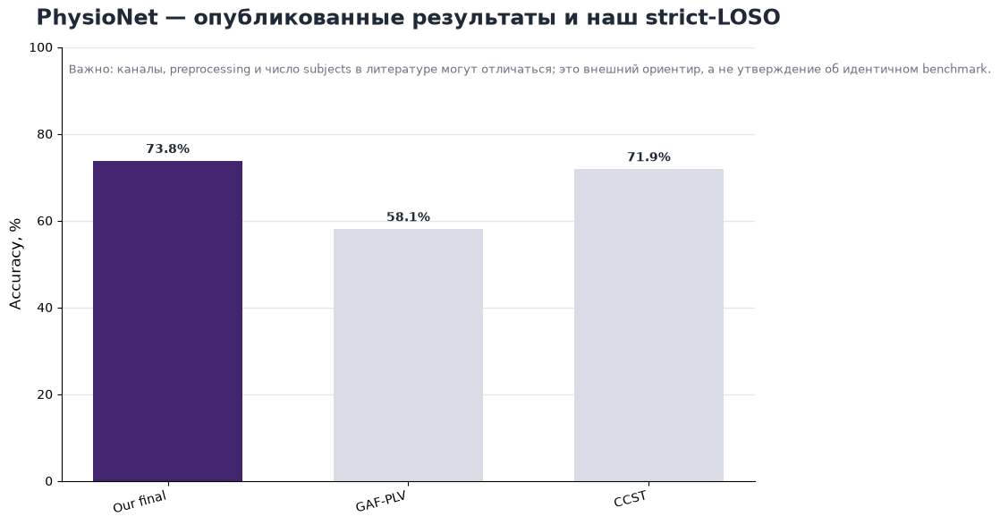


SLIDES FIGURES READY
01_protocol.png
02_BCI_internal_evolution.png
03_PhysioNet_internal_evolution.png
04_BCI_denoiser_ablation.png
06_BCI_robustness.png
07_PhysioNet_robustness.png
08_multiseed_stability.png
09_multiseed_selection.png
10_frozen_cross_dataset.png
11_BCI_literature_comparison.png
12_PhysioNet_literature_comparison.png

Folder:
/Users/irina/Desktop/master project/results_v2/universal_subject_invariant_pipeline/SLIDES_FINAL


In [150]:
# ============================================================
# PRESENTATION FIGURES — FINAL CLEAN VERSION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

PROJECT_ROOT = Path("/Users/irina/Desktop/master project")
ROOT = PROJECT_ROOT / "results_v2"

OUT = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "SLIDES_FINAL"
)

OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# COLORS
# ------------------------------------------------------------

PURPLE_LIGHT = "#DDD0ED"
PURPLE_MID   = "#A287D1"
PURPLE       = "#8060B8"
PURPLE_DARK  = "#5A388F"
PURPLE_DEEP  = "#43246F"

GREY         = "#6B7280"
DARK         = "#1F2937"
GRID         = "#E8E4EF"
NOISY        = "#C2AEE1"
RAW          = "#D9DCE5"

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

MULTI_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_multiseed_results.csv"
)

SELECTION_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "bci_method_selection_summary.csv"
)

PHYS_FINAL_PATH = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "physionet_frozen_recipe"
    / "physionet_frozen_recipe_summary.csv"
)

FROZEN_PATH = (
    ROOT
    / "strict_loso_frozen_final"
    / "strict_loso_frozen_summary.csv"
)

LITERATURE_PATH = (
    ROOT
    / "strict_loso_denoising_binary"
    / "tables"
    / "06_sota_reference.csv"
)

BCI_ABLATION_PATH = (
    ROOT
    / "ablation_task_informed"
    / "ablation_results.csv"
)

PHYS_ABLATION_PATH = (
    PROJECT_ROOT
    / "results_physionet_external"
    / "physionet_ablation"
    / "ablation_results.csv"
)

# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

multi = pd.read_csv(MULTI_PATH)
selection = pd.read_csv(SELECTION_PATH)
phys_final = pd.read_csv(PHYS_FINAL_PATH)
frozen = pd.read_csv(FROZEN_PATH)
literature = pd.read_csv(LITERATURE_PATH)

# method_summary уже собран нами сегодня.
# Если kernel не перезапускался — он есть.
assert "method_summary" in globals(), (
    "method_summary отсутствует. "
    "Запусти сегодняшнюю ячейку, которая собирала ALL METHODS — CLEAN CLASSIFICATION."
)


# ============================================================
# HELPERS
# ============================================================

def pct(v):
    v = float(v)
    return v * 100 if v <= 1.5 else v


def save(fig, name):
    path = OUT / name
    fig.savefig(
        path,
        dpi=240,
        bbox_inches="tight",
        facecolor="white",
    )
    print("✓", name)


def slide_axis(ax, title, ylabel="Accuracy, %"):
    ax.set_ylim(0, 100)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        color=DARK,
        pad=18,
    )
    ax.grid(
        axis="y",
        color=GRID,
        linewidth=1,
    )
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=10)


def bar_labels(ax, bars):
    for bar in bars:
        h = bar.get_height()
        if np.isfinite(h):
            ax.text(
                bar.get_x() + bar.get_width()/2,
                h + 1.1,
                f"{h:.1f}%",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold",
                color=DARK,
            )


def order_table(df, order):
    d = df.copy()
    d["_order"] = d["method"].map(
        {m: i for i, m in enumerate(order)}
    )
    return (
        d[d["_order"].notna()]
        .sort_values("_order")
        .reset_index(drop=True)
    )


# ============================================================
# SLIDE 1
# EXPERIMENTAL DESIGN
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))
ax.set_xlim(0, 14)
ax.set_ylim(0, 6)
ax.axis("off")

ax.text(
    7, 5.55,
    "Исследовательская постановка",
    ha="center",
    fontsize=22,
    fontweight="bold",
    color=DARK,
)

ax.text(
    7, 5.05,
    "Единый binary L/R pipeline • strict LOSO • новый человек полностью исключён из обучения",
    ha="center",
    fontsize=12,
    color=GREY,
)

boxes = [
    (0.6, 2.1, 2.3, 1.5, "Cho2017\npretraining"),
    (3.5, 2.1, 2.3, 1.5, "Transfer\nEEGNet"),
    (6.4, 2.1, 2.3, 1.5, "SupCon /\nGRL / MixStyle"),
    (9.3, 2.1, 2.3, 1.5, "Frozen\nclassifier"),
    (12.0, 2.1, 1.5, 1.5, "L / R"),
]

for i, (x, y, w, h, txt) in enumerate(boxes):
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        linewidth=1.5,
        edgecolor=PURPLE_DARK,
        facecolor=PURPLE_LIGHT if i == 0 else "#F8F5FC",
    )
    ax.add_patch(patch)

    ax.text(
        x+w/2, y+h/2,
        txt,
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
        color=DARK,
    )

for i in range(len(boxes)-1):
    x1 = boxes[i][0] + boxes[i][2]
    x2 = boxes[i+1][0]

    ax.add_patch(
        FancyArrowPatch(
            (x1+0.05, 2.85),
            (x2-0.05, 2.85),
            arrowstyle="->",
            mutation_scale=18,
            linewidth=2,
            color=PURPLE,
        )
    )

ax.text(
    7,
    0.8,
    "BCI IV-2a и PhysioNet: один принцип обучения → проверка переносимости между датасетами",
    ha="center",
    fontsize=13,
    color=DARK,
)

save(fig, "01_protocol.png")
plt.show()


# ============================================================
# SLIDE 2A
# BCI — OUR INTERNAL EXPERIMENTS
# ============================================================

METHOD_ORDER_BCI = [
    "Baseline",
    "Cho Transfer",
    "SupCon",
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
    "Cho Transfer + SupCon + MixStyle",
    "Cho Transfer + SupCon + GRL + MixStyle",
]

bci = method_summary[
    method_summary["dataset"] == "BCI"
].copy()

bci = order_table(
    bci,
    METHOD_ORDER_BCI,
)

fig, ax = plt.subplots(figsize=(14, 6.5))

colors = [
    PURPLE_LIGHT if m == "Baseline"
    else PURPLE_DEEP if m == "Cho Transfer + SupCon + GRL"
    else PURPLE_MID
    for m in bci["method"]
]

bars = ax.bar(
    np.arange(len(bci)),
    bci["mean_accuracy"],
    width=0.66,
    color=colors,
)

bar_labels(ax, bars)

ax.set_xticks(np.arange(len(bci)))
ax.set_xticklabels(
    bci["method"],
    rotation=18,
    ha="right",
)

slide_axis(
    ax,
    "BCI IV-2a — что дали последовательные изменения pipeline",
)

ax.text(
    0.01, 0.94,
    "Сначала проверяли идеи внутри одного strict-LOSO протокола — без сравнения разных benchmark setup.",
    transform=ax.transAxes,
    fontsize=10,
    color=GREY,
)

save(fig, "02_BCI_internal_evolution.png")
plt.show()


# ============================================================
# SLIDE 2B
# PHYSIONET — OUR INTERNAL EXPERIMENTS
# ============================================================

METHOD_ORDER_PHYS = [
    "Baseline",
    "Cho Transfer",
    "SupCon",
    "Cho Transfer + SupCon",
    "Cho Transfer + SupCon + GRL",
]

phys = method_summary[
    method_summary["dataset"] == "PhysioNet"
].copy()

phys = order_table(
    phys,
    METHOD_ORDER_PHYS,
)

fig, ax = plt.subplots(figsize=(11, 6.5))

colors = [
    PURPLE_LIGHT if m == "Baseline"
    else PURPLE_DEEP if m == "Cho Transfer + SupCon + GRL"
    else PURPLE_MID
    for m in phys["method"]
]

bars = ax.bar(
    np.arange(len(phys)),
    phys["mean_accuracy"],
    width=0.62,
    color=colors,
)

bar_labels(ax, bars)

ax.set_xticks(np.arange(len(phys)))
ax.set_xticklabels(
    phys["method"],
    rotation=18,
    ha="right",
)

slide_axis(
    ax,
    "PhysioNet — внутренняя сравнительная проверка методов",
)

ax.text(
    0.01, 0.94,
    "Главный эффект здесь не в большом приросте accuracy, а в проверке переносимости одного рецепта.",
    transform=ax.transAxes,
    fontsize=10,
    color=GREY,
)

save(fig, "03_PhysioNet_internal_evolution.png")
plt.show()


# ============================================================
# SLIDE 3
# DENOISER ABLATION
# ============================================================

def make_ablation(path):

    if not path.exists():
        return None

    d = pd.read_csv(path)

    method_col = next(
        (c for c in ["method", "variant", "loss", "model"] if c in d.columns),
        None,
    )

    acc_col = next(
        (
            c for c in
            ["accuracy", "test_accuracy", "downstream_accuracy"]
            if c in d.columns
        ),
        None,
    )

    if method_col is None or acc_col is None:
        return None

    d = d[[method_col, acc_col]].copy()

    d[acc_col] = pd.to_numeric(
        d[acc_col],
        errors="coerce",
    )

    if d[acc_col].max() <= 1.5:
        d[acc_col] *= 100

    result = (
        d.groupby(method_col, as_index=False)
        .agg(
            mean_accuracy=(acc_col, "mean"),
            std_accuracy=(acc_col, "std"),
        )
        .rename(columns={method_col: "method"})
    )

    def clean_name(x):
        s = str(x).upper()

        if "RAW" in s:
            return "RAW"
        if "FULL" in s:
            return "FULL"
        if "PSD" in s:
            return "MSE + PSD"
        if "COV" in s:
            return "MSE + Cov"
        if "MSE" in s:
            return "MSE"

        return str(x)

    result["method"] = result["method"].map(clean_name)

    order = {
        "RAW": 0,
        "MSE": 1,
        "MSE + PSD": 2,
        "MSE + Cov": 3,
        "FULL": 4,
    }

    result["_order"] = result["method"].map(order)

    return (
        result
        .sort_values("_order")
        .drop_duplicates("method")
    )


bci_abl = make_ablation(
    BCI_ABLATION_PATH
)

phys_abl = make_ablation(
    PHYS_ABLATION_PATH
)


for dataset, data, filename in [
    (
        "BCI IV-2a",
        bci_abl,
        "04_BCI_denoiser_ablation.png",
    ),
    (
        "PhysioNet",
        phys_abl,
        "05_PhysioNet_denoiser_ablation.png",
    ),
]:

    if data is None:
        continue

    fig, ax = plt.subplots(figsize=(9, 6.3))

    colors = [
        RAW if m == "RAW" else PURPLE
        for m in data["method"]
    ]

    bars = ax.bar(
        np.arange(len(data)),
        data["mean_accuracy"],
        yerr=data["std_accuracy"],
        capsize=5,
        width=0.65,
        color=colors,
    )

    bar_labels(ax, bars)

    ax.set_xticks(np.arange(len(data)))
    ax.set_xticklabels(data["method"])

    slide_axis(
        ax,
        f"{dataset} — ablation denoiser",
        ylabel="Downstream accuracy, %",
    )

    ax.text(
        0.01, 0.94,
        "Оптимизируем не только reconstruction: важна сохранность motor-imagery информации.",
        transform=ax.transAxes,
        fontsize=10,
        color=GREY,
    )

    save(fig, filename)
    plt.show()


# ============================================================
# SLIDE 4
# ROBUSTNESS — SEPARATE DATASET FIGURES
# ============================================================

COND = [
    "clean",
    "noisy",
    "noisy_denoised",
]

COND_LABELS = {
    "clean": "Clean",
    "noisy": "Noisy −5 dB",
    "noisy_denoised": "After denoising",
}

METHODS = {
    "transfer": "Cho Transfer",
    "transfer_supcon": "Transfer + SupCon",
}


for dataset, filename in [
    ("BCI", "06_BCI_robustness.png"),
    ("PhysioNet", "07_PhysioNet_robustness.png"),
]:

    d = frozen[
        (frozen["dataset"] == dataset)
        &
        frozen["method"].isin(METHODS)
        &
        frozen["condition"].isin(COND)
    ].copy()

    fig, ax = plt.subplots(figsize=(9, 6.3))

    x = np.arange(3)
    width = 0.34

    for offset, method, color in [
        (-width/2, "transfer", PURPLE_MID),
        (+width/2, "transfer_supcon", PURPLE_DEEP),
    ]:

        vals = []

        for c in COND:

            r = d[
                (d["method"] == method)
                &
                (d["condition"] == c)
            ]

            if len(r):
                vals.append(
                    pct(
                        r.iloc[0]["mean_accuracy"]
                    )
                )
            else:
                vals.append(np.nan)

        bars = ax.bar(
            x + offset,
            vals,
            width,
            label=METHODS[method],
            color=color,
        )

        bar_labels(ax, bars)

    ax.set_xticks(x)
    ax.set_xticklabels(
        [COND_LABELS[c] for c in COND]
    )

    slide_axis(
        ax,
        f"{dataset} — что denoising возвращает после загрязнения",
    )

    ax.legend(
        frameon=False,
        fontsize=10,
    )

    save(fig, filename)
    plt.show()


# ============================================================
# SLIDE 5
# MULTI-SEED — WHY WE DID NOT TRUST ONE RUN
# ============================================================

multi["method_label"] = multi["method"].map({
    "transfer_supcon_control":
        "Transfer + SupCon",

    "transfer_supcon_grl":
        "Transfer + SupCon + GRL",

    "transfer_supcon_mixstyle":
        "Transfer + SupCon + MixStyle",
})

seed = (
    multi
    .groupby(
        ["method_label", "seed_base"],
        as_index=False,
    )
    .agg(
        val=("best_val_accuracy", "mean"),
        test=("accuracy", "mean"),
    )
)

seed["val"] *= 100
seed["test"] *= 100

fig, ax = plt.subplots(figsize=(10, 6.3))

colors = {
    "Transfer + SupCon":
        PURPLE_MID,

    "Transfer + SupCon + GRL":
        PURPLE_DEEP,

    "Transfer + SupCon + MixStyle":
        PURPLE,
}

for method, d in seed.groupby("method_label"):

    d = d.sort_values("seed_base")

    ax.plot(
        d["seed_base"].astype(str),
        d["test"],
        marker="o",
        linewidth=2.8,
        markersize=8,
        label=method,
        color=colors[method],
    )

slide_axis(
    ax,
    "BCI IV-2a — один удачный запуск недостаточен",
)

ax.set_xlabel("Random seed")

ax.legend(
    frameon=False,
    fontsize=10,
)

ax.text(
    0.01, 0.94,
    "Каждая точка = средняя test accuracy по 9 unseen subjects.",
    transform=ax.transAxes,
    fontsize=10,
    color=GREY,
)

save(fig, "08_multiseed_stability.png")
plt.show()


# ============================================================
# SLIDE 6
# MODEL SELECTION — VALIDATION, NOT TEST
# ============================================================

summary = (
    seed
    .groupby(
        "method_label",
        as_index=False,
    )
    .agg(
        validation=("val", "mean"),
        test=("test", "mean"),
    )
)

order = [
    "Transfer + SupCon",
    "Transfer + SupCon + GRL",
    "Transfer + SupCon + MixStyle",
]

summary["_order"] = summary["method_label"].map(
    {m: i for i, m in enumerate(order)}
)

summary = summary.sort_values("_order")

fig, ax = plt.subplots(figsize=(10, 6.3))

x = np.arange(len(summary))
width = 0.34

bars1 = ax.bar(
    x-width/2,
    summary["validation"],
    width,
    color=PURPLE_MID,
    label="Validation — выбор метода",
)

bars2 = ax.bar(
    x+width/2,
    summary["test"],
    width,
    color=PURPLE_DEEP,
    label="Test — после выбора",
)

bar_labels(ax, bars1)
bar_labels(ax, bars2)

ax.set_xticks(x)
ax.set_xticklabels(
    summary["method_label"],
    rotation=15,
    ha="right",
)

slide_axis(
    ax,
    "Почему финальным стал GRL",
)

ax.legend(frameon=False)

save(fig, "09_multiseed_selection.png")
plt.show()


# ============================================================
# SLIDE 7
# FINAL FROZEN PIPELINE
# ============================================================

winner = (
    selection
    .sort_values("validation_rank")
    .iloc[0]
)

bci_final = pct(
    winner["mean_test_accuracy"]
)

phys_final_acc = pct(
    phys_final.iloc[0]["mean_accuracy"]
)

fig, ax = plt.subplots(figsize=(8, 6.3))

bars = ax.bar(
    ["BCI IV-2a", "PhysioNet"],
    [bci_final, phys_final_acc],
    width=0.55,
    color=[PURPLE, PURPLE_DEEP],
)

bar_labels(ax, bars)

slide_axis(
    ax,
    "Один frozen pipeline на двух датасетах",
)

ax.text(
    0.5, 90,
    "Cho Transfer + SupCon + GRL",
    ha="center",
    fontsize=14,
    fontweight="bold",
    color=DARK,
)

ax.annotate(
    "без повторного подбора метода",
    xy=(1, phys_final_acc),
    xytext=(0.50, 83),
    arrowprops={
        "arrowstyle": "->",
        "lw": 1.8,
        "color": PURPLE_DEEP,
    },
    ha="center",
    fontsize=10,
    color=DARK,
)

save(fig, "10_frozen_cross_dataset.png")
plt.show()


# ============================================================
# SLIDE 8
# LITERATURE COMPARISON — HONEST VERSION
#
# Не мешаем разные protocol в один якобы benchmark.
# ============================================================

lit = literature.copy()

lit["accuracy_pct"] = pd.to_numeric(
    lit["accuracy"],
    errors="coerce",
)

if lit["accuracy_pct"].max() <= 1.5:
    lit["accuracy_pct"] *= 100


# ------------------------------------------------------------
# BCI
# ------------------------------------------------------------

bci_lit = (
    lit[
        lit["dataset"]
        .astype(str)
        .str.lower()
        .str.contains("bci")
    ]
    .sort_values("accuracy_pct")
)

fig, ax = plt.subplots(figsize=(10, 6.3))

names = ["Our final"] + bci_lit["model"].tolist()

values = (
    [bci_final]
    +
    bci_lit["accuracy_pct"].tolist()
)

colors = (
    [PURPLE_DEEP]
    +
    [RAW] * len(bci_lit)
)

bars = ax.bar(
    np.arange(len(values)),
    values,
    color=colors,
    width=0.62,
)

bar_labels(ax, bars)

ax.set_xticks(
    np.arange(len(values))
)

ax.set_xticklabels(
    names,
    rotation=15,
    ha="right",
)

slide_axis(
    ax,
    "BCI IV-2a — сравнение с опубликованными ориентирами",
)

ax.text(
    0.01,
    0.94,
    "Сравнение интерпретируем только с работами с максимально близкой L/R subject-independent постановкой.",
    transform=ax.transAxes,
    fontsize=9.5,
    color=GREY,
)

save(fig, "11_BCI_literature_comparison.png")
plt.show()


# ------------------------------------------------------------
# PhysioNet
# ------------------------------------------------------------

phys_lit = (
    lit[
        lit["dataset"]
        .astype(str)
        .str.lower()
        .str.contains("phys")
    ]
    .sort_values("accuracy_pct")
)


fig, ax = plt.subplots(figsize=(10, 6.3))

names = (
    ["Our final"]
    +
    phys_lit["model"].tolist()
)

values = (
    [phys_final_acc]
    +
    phys_lit["accuracy_pct"].tolist()
)

bars = ax.bar(
    np.arange(len(values)),
    values,
    color=
        [PURPLE_DEEP]
        +
        [RAW] * len(phys_lit),
    width=0.62,
)

bar_labels(ax, bars)

ax.set_xticks(
    np.arange(len(values))
)

ax.set_xticklabels(
    names,
    rotation=15,
    ha="right",
)

slide_axis(
    ax,
    "PhysioNet — опубликованные результаты и наш strict-LOSO",
)

ax.text(
    0.01,
    0.94,
    (
        "Важно: каналы, preprocessing и число subjects в литературе могут отличаться; "
        "это внешний ориентир, а не утверждение об идентичном benchmark."
    ),
    transform=ax.transAxes,
    fontsize=9.3,
    color=GREY,
)

save(fig, "12_PhysioNet_literature_comparison.png")
plt.show()


# ============================================================
# MANIFEST
# ============================================================

print()
print("=" * 90)
print("SLIDES FIGURES READY")
print("=" * 90)

for p in sorted(
    OUT.glob("*.png")
):
    print(p.name)

print()
print("Folder:")
print(OUT)

In [152]:
# ============================================================
# FIX create_mixed_noisy_dataset COMPATIBILITY
#
# Не меняем существующий helper.
# Делаем адаптер под его РЕАЛЬНУЮ сигнатуру.
# ============================================================

import inspect

_ORIGINAL_CREATE_MIXED_NOISY_DATASET = create_mixed_noisy_dataset

_real_sig = inspect.signature(
    _ORIGINAL_CREATE_MIXED_NOISY_DATASET
)

_real_params = set(
    _real_sig.parameters.keys()
)

print(
    "Real create_mixed_noisy_dataset signature:",
    _real_sig
)


def _call_existing_noisy_helper(
    X,
    snr_db,
    seed,
    eog_source,
    emg_source,
):
    """
    Calls the notebook's existing create_mixed_noisy_dataset
    using only arguments that ACTUALLY exist in its signature.
    """

    kwargs = {}

    # --------------------------------------------------------
    # SNR
    # --------------------------------------------------------
    if "snr_db" in _real_params:
        kwargs["snr_db"] = snr_db

    elif "snr" in _real_params:
        kwargs["snr"] = snr_db


    # --------------------------------------------------------
    # SEED
    # --------------------------------------------------------
    if "seed" in _real_params:
        kwargs["seed"] = seed

    elif "random_state" in _real_params:
        kwargs["random_state"] = seed


    # --------------------------------------------------------
    # EOG pool — support names used in our older notebook cells
    # --------------------------------------------------------
    for name in [
        "eog_data",
        "eog_artifacts",
        "eog_pool",
        "eog_dataset",
        "eog",
    ]:
        if name in _real_params:
            kwargs[name] = eog_source
            break


    # --------------------------------------------------------
    # EMG pool
    # --------------------------------------------------------
    for name in [
        "emg_data",
        "emg_artifacts",
        "emg_pool",
        "emg_dataset",
        "emg",
    ]:
        if name in _real_params:
            kwargs[name] = emg_source
            break


    return _ORIGINAL_CREATE_MIXED_NOISY_DATASET(
        X,
        **kwargs,
    )


# ============================================================
# REDEFINE TRAIN DATASET
#
# IMPORTANT:
# training -> eog_train / emg_train
# ============================================================

class FinalTaskAwareDenoisingDataset(
    Dataset
):

    def __init__(
        self,
        X,
        y,
        eog_artifacts,
        emg_artifacts,
        snr_min=-5.0,
        snr_max=5.0,
        seed=42,
    ):

        self.X = np.asarray(
            X,
            dtype=np.float32,
        )

        self.y = np.asarray(
            y,
            dtype=np.int64,
        )

        self.eog = eog_artifacts
        self.emg = emg_artifacts

        self.snr_min = float(
            snr_min
        )

        self.snr_max = float(
            snr_max
        )

        self.seed = int(
            seed
        )

        self.epoch = 0


    def set_epoch(
        self,
        epoch,
    ):
        self.epoch = int(
            epoch
        )


    def __len__(
        self,
    ):
        return len(
            self.X
        )


    def __getitem__(
        self,
        idx,
    ):

        rng_seed = (
            self.seed
            + self.epoch * 1_000_003
            + idx * 97
        )

        rng = np.random.default_rng(
            rng_seed
        )

        clean = (
            self.X[idx]
            .copy()
        )

        label = int(
            self.y[idx]
        )

        snr = float(
            rng.uniform(
                self.snr_min,
                self.snr_max,
            )
        )


        # ====================================================
        # EXISTING NOTEBOOK NOISE GENERATOR
        # ====================================================

        noisy = _call_existing_noisy_helper(
            X=clean[None, ...],
            snr_db=snr,
            seed=rng_seed,

            # TRAIN artifact split
            eog_source=self.eog,
            emg_source=self.emg,
        )[0]


        noisy = np.asarray(
            noisy,
            dtype=np.float32,
        )


        # ====================================================
        # SAME NORMALIZATION AS OUR DENOISER PROTOCOL
        # ====================================================

        scale = float(
            noisy.std()
            + 1e-8
        )

        noisy_norm = (
            noisy / scale
        ).astype(
            np.float32
        )

        clean_norm = (
            clean / scale
        ).astype(
            np.float32
        )


        return (
            torch.from_numpy(
                noisy_norm
            ),

            torch.from_numpy(
                clean_norm
            ),

            torch.tensor(
                label,
                dtype=torch.long,
            ),

            torch.tensor(
                scale,
                dtype=torch.float32,
            ),
        )


# ============================================================
# REDEFINE FIXED VAL / TEST CORRUPTION
#
# IMPORTANT:
# validation/test -> eog_test / emg_test
# ============================================================

def make_fixed_corruption(
    X,
    y,
    snr_db,
    seed,
):

    X = np.asarray(
        X,
        dtype=np.float32,
    )

    y = np.asarray(
        y,
        dtype=np.int64,
    )


    noisy = _call_existing_noisy_helper(
        X=X,
        snr_db=snr_db,
        seed=seed,

        # TEST artifact split:
        # no artifact-fragment leakage from training
        eog_source=eog_test,
        emg_source=emg_test,
    )


    noisy = np.asarray(
        noisy,
        dtype=np.float32,
    )


    scales = (
        noisy.std(
            axis=(1, 2),
            keepdims=True,
        )
        + 1e-8
    ).astype(
        np.float32
    )


    noisy_norm = (
        noisy / scales
    ).astype(
        np.float32
    )


    clean_norm = (
        X / scales
    ).astype(
        np.float32
    )


    return {
        "clean":
            X,

        "noisy":
            noisy,

        "noisy_norm":
            noisy_norm,

        "clean_norm":
            clean_norm,

        "scales":
            scales,

        "y":
            y,
    }


print()
print("=" * 80)
print("PATCH APPLIED")
print("=" * 80)
print("train artifacts : eog_train / emg_train")
print("val/test artifacts: eog_test / emg_test")
print("Теперь запускай блок RUN BCI и всё ниже.")

Real create_mixed_noisy_dataset signature: (X_clean, snr_db=-5.0, seed=42)

PATCH APPLIED
train artifacts : eog_train / emg_train
val/test artifacts: eog_test / emg_test
Теперь запускай блок RUN BCI и всё ниже.


In [153]:
# ============================================================
# FINAL FULL RUN
# Cho Transfer + SupCon + GRL + Task-Aware Denoising
#
# FINAL EXPERIMENT:
#
#   Cho2017
#      ↓
#   Transfer EEGNet
#      ↓
#   SupCon + GRL
#      ↓
#   frozen classifier
#      ↑
#   task-aware MSE + PSD denoiser
#
# STRICT LOSO:
#   train subjects -> denoiser training
#   validation subject -> denoiser checkpoint selection
#   test subject -> ONLY final evaluation
#
# LOSS:
#   MSE
#   + 0.10 * PSD
#   + 0.25 * classifier CE
#
# BCI:
#   task CE averaged across 3 GRL classifier seeds
#
# PhysioNet:
#   one frozen GRL classifier per LOSO fold
#
# Evaluation:
#   Clean
#   Clean -> Denoiser
#   Noisy -5 dB
#   Noisy -5 dB -> Denoiser
#
# Resume-safe:
#   saves each completed fold immediately
# ============================================================

import gc
import copy
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader


# ============================================================
# CONFIG
# ============================================================

FINAL_SEED = 20261018

DENOISER_EPOCHS = 120
DENOISER_PATIENCE = 15

DENOISER_BATCH_SIZE = 64

DENOISER_LR = 1e-3
DENOISER_WEIGHT_DECAY = 1e-4

TRAIN_SNR_MIN = -5.0
TRAIN_SNR_MAX = +5.0

VAL_SNR = -5.0
TEST_SNR = -5.0

LAMBDA_PSD = 0.10
LAMBDA_TASK = 0.25

BCI_MULTI_SEEDS = [
    42,
    123,
    2026,
]


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(
    "/Users/irina/Desktop/master project"
)

ROOT = (
    PROJECT_ROOT
    / "results_v2"
)

OUT_ROOT = (
    ROOT
    / "final_grl_taskaware_denoising"
)

MODEL_DIR = (
    OUT_ROOT
    / "models"
)

HISTORY_DIR = (
    OUT_ROOT
    / "histories"
)

RESULT_DIR = (
    OUT_ROOT
    / "results"
)

for directory in [
    OUT_ROOT,
    MODEL_DIR,
    HISTORY_DIR,
    RESULT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


BCI_GRL_MODEL_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "bci_multiseed"
    / "models"
)

PHYS_GRL_MODEL_DIR = (
    ROOT
    / "universal_subject_invariant_pipeline"
    / "physionet_frozen_recipe"
    / "models"
)


print("=" * 100)
print("FINAL GRL + TASK-AWARE DENOISING")
print("=" * 100)

print("Device:", DEVICE)
print("Output:", OUT_ROOT)
print(
    f"Loss = MSE + {LAMBDA_PSD}*PSD + {LAMBDA_TASK}*TASK"
)
print(
    f"Train SNR = [{TRAIN_SNR_MIN}, {TRAIN_SNR_MAX}] dB"
)
print(
    f"Validation/Test SNR = {TEST_SNR} dB"
)


# ============================================================
# RANDOM SEED
# ============================================================

def set_seed(seed):

    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def clear_memory():

    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()

    elif DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# ============================================================
# PSD LOSS
# ============================================================

def final_psd_loss(
    pred,
    target,
    sfreq,
    fmin=8.0,
    fmax=30.0,
):

    n_times = pred.shape[-1]

    pred_fft = torch.fft.rfft(
        pred,
        dim=-1,
    )

    target_fft = torch.fft.rfft(
        target,
        dim=-1,
    )

    pred_psd = (
        pred_fft.abs() ** 2
    )

    target_psd = (
        target_fft.abs() ** 2
    )

    freqs = torch.fft.rfftfreq(
        n_times,
        d=1.0 / sfreq,
        device=pred.device,
    )

    mask = (
        (freqs >= fmin)
        &
        (freqs <= fmax)
    )

    pred_band = (
        pred_psd[..., mask]
    )

    target_band = (
        target_psd[..., mask]
    )

    pred_band = (
        pred_band
        /
        (
            pred_band.sum(
                dim=-1,
                keepdim=True,
            )
            + 1e-8
        )
    )

    target_band = (
        target_band
        /
        (
            target_band.sum(
                dim=-1,
                keepdim=True,
            )
            + 1e-8
        )
    )

    return F.mse_loss(
        pred_band,
        target_band,
    )


# ============================================================
# TRAIN DENOISING DATASET
#
# IMPORTANT:
# create_mixed_noisy_dataset has REAL signature:
#
# create_mixed_noisy_dataset(
#     X_clean,
#     snr_db=-5.0,
#     seed=42
# )
#
# so nothing else is passed to it.
# ============================================================

class FinalTaskAwareDenoisingDataset(
    Dataset
):

    def __init__(
        self,
        X,
        y,
        snr_min=-5.0,
        snr_max=5.0,
        seed=42,
    ):

        self.X = np.asarray(
            X,
            dtype=np.float32,
        )

        self.y = np.asarray(
            y,
            dtype=np.int64,
        )

        self.snr_min = float(
            snr_min
        )

        self.snr_max = float(
            snr_max
        )

        self.seed = int(
            seed
        )

        self.epoch = 0


    def set_epoch(
        self,
        epoch,
    ):

        self.epoch = int(
            epoch
        )


    def __len__(
        self,
    ):

        return len(
            self.X
        )


    def __getitem__(
        self,
        idx,
    ):

        # deterministic corruption for sample + epoch
        sample_seed = (
            self.seed
            + self.epoch * 1_000_003
            + idx * 97
        )

        rng = np.random.default_rng(
            sample_seed
        )

        clean = (
            self.X[idx]
            .copy()
        )

        label = int(
            self.y[idx]
        )

        snr_db = float(
            rng.uniform(
                self.snr_min,
                self.snr_max,
            )
        )

        # ----------------------------------------------------
        # Existing notebook helper — exact signature
        # ----------------------------------------------------

        noisy = create_mixed_noisy_dataset(
            clean[None, ...],
            snr_db=snr_db,
            seed=sample_seed,
        )[0]

        noisy = np.asarray(
            noisy,
            dtype=np.float32,
        )

        # ----------------------------------------------------
        # Same noisy-scale normalization used by our
        # denoising experiments
        # ----------------------------------------------------

        scale = float(
            noisy.std()
            + 1e-8
        )

        noisy_norm = (
            noisy / scale
        ).astype(
            np.float32
        )

        clean_norm = (
            clean / scale
        ).astype(
            np.float32
        )

        return (
            torch.from_numpy(
                noisy_norm
            ),
            torch.from_numpy(
                clean_norm
            ),
            torch.tensor(
                label,
                dtype=torch.long,
            ),
            torch.tensor(
                scale,
                dtype=torch.float32,
            ),
        )


# ============================================================
# FIXED VALIDATION / TEST CORRUPTION
# ============================================================

def make_fixed_corruption(
    X,
    y,
    snr_db,
    seed,
):

    X = np.asarray(
        X,
        dtype=np.float32,
    )

    y = np.asarray(
        y,
        dtype=np.int64,
    )

    noisy = create_mixed_noisy_dataset(
        X,
        snr_db=snr_db,
        seed=seed,
    )

    noisy = np.asarray(
        noisy,
        dtype=np.float32,
    )

    scales = (
        noisy.std(
            axis=(1, 2),
            keepdims=True,
        )
        + 1e-8
    ).astype(
        np.float32
    )

    return {
        "clean":
            X,

        "noisy":
            noisy,

        "noisy_norm":
            (
                noisy / scales
            ).astype(
                np.float32
            ),

        "clean_norm":
            (
                X / scales
            ).astype(
                np.float32
            ),

        "scales":
            scales,

        "y":
            y,
    }


# ============================================================
# FIND CLASSIFIER CHECKPOINT
#
# Do not depend on one exact filename.
# Find by subject / method / seed inside known model folders.
# ============================================================

def find_one_checkpoint(
    root,
    required_tokens,
):

    root = Path(root)

    candidates = []

    for path in root.rglob("*.pt"):

        text = (
            path.name
            .lower()
        )

        if all(
            str(token).lower()
            in text
            for token in required_tokens
        ):

            candidates.append(
                path
            )

    if len(candidates) == 0:

        raise FileNotFoundError(
            f"No checkpoint found in:\n"
            f"{root}\n"
            f"tokens={required_tokens}"
        )

    # prefer "best" if several exist
    best = [
        p
        for p in candidates
        if "best" in p.name.lower()
    ]

    if len(best):
        candidates = best

    # deterministic
    candidates = sorted(
        candidates
    )

    return candidates[0]


def resolve_bci_grl_checkpoints(
    test_subject,
):

    subject_token = str(
        test_subject
    ).lower()

    paths = []

    for seed in BCI_MULTI_SEEDS:

        # try seedbase first
        try:

            path = find_one_checkpoint(
                BCI_GRL_MODEL_DIR,
                [
                    subject_token,
                    "grl",
                    str(seed),
                ],
            )

        except FileNotFoundError:

            # fallback if filenames use another seed notation
            path = find_one_checkpoint(
                BCI_GRL_MODEL_DIR,
                [
                    subject_token,
                    "grl",
                ],
            )

            # avoid silently taking same checkpoint
            if path in paths:

                matching = [
                    p
                    for p in BCI_GRL_MODEL_DIR.rglob("*.pt")
                    if (
                        subject_token
                        in p.name.lower()
                        and
                        "grl"
                        in p.name.lower()
                        and
                        str(seed)
                        in p.name.lower()
                    )
                ]

                if len(matching):
                    path = sorted(
                        matching
                    )[0]

        paths.append(
            path
        )

    if len(
        set(paths)
    ) != len(
        BCI_MULTI_SEEDS
    ):

        raise RuntimeError(
            f"BCI {test_subject}: "
            f"could not resolve 3 different seed checkpoints:\n"
            + "\n".join(
                str(p)
                for p in paths
            )
        )

    return paths


def resolve_phys_grl_checkpoint(
    test_subject,
):

    subject_token = str(
        test_subject
    ).lower()

    return find_one_checkpoint(
        PHYS_GRL_MODEL_DIR,
        [
            subject_token,
            "grl",
        ],
    )


# ============================================================
# CHECKPOINT STATE
# ============================================================

def extract_state_dict(
    checkpoint,
):

    if (
        isinstance(
            checkpoint,
            dict,
        )
        and
        "model_state_dict"
        in checkpoint
    ):

        return checkpoint[
            "model_state_dict"
        ]

    if (
        isinstance(
            checkpoint,
            dict,
        )
        and
        "state_dict"
        in checkpoint
    ):

        return checkpoint[
            "state_dict"
        ]

    if isinstance(
        checkpoint,
        dict,
    ):

        return checkpoint

    raise TypeError(
        f"Unsupported checkpoint type: "
        f"{type(checkpoint)}"
    )


def load_matching_weights(
    model,
    state_dict,
):

    model_state = (
        model.state_dict()
    )

    compatible = {}

    for key, value in state_dict.items():

        # remove DataParallel prefix
        clean_key = (
            key[7:]
            if key.startswith(
                "module."
            )
            else key
        )

        if (
            clean_key
            in model_state
            and
            model_state[
                clean_key
            ].shape
            ==
            value.shape
        ):

            compatible[
                clean_key
            ] = value

    model_state.update(
        compatible
    )

    model.load_state_dict(
        model_state
    )

    return len(
        compatible
    )


# ============================================================
# FROZEN GRL MODEL
# ============================================================

def load_frozen_grl_classifier(
    checkpoint_path,
    n_train_subjects,
    input_samples,
):

    model = build_si_model(
        method=
            "transfer_supcon_grl",

        n_train_subjects=
            n_train_subjects,

        input_samples=
            input_samples,
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    state = extract_state_dict(
        checkpoint
    )

    loaded = load_matching_weights(
        model,
        state,
    )

    if loaded == 0:

        raise RuntimeError(
            f"No compatible tensors loaded:\n"
            f"{checkpoint_path}"
        )

    model = model.to(
        DEVICE
    )

    model.eval()

    for parameter in model.parameters():

        parameter.requires_grad = (
            False
        )

    return model


# ============================================================
# EXTRACT CLASSIFICATION LOGITS
# ============================================================

def get_class_logits(
    model,
    X,
):

    output = model(
        X
    )

    if torch.is_tensor(
        output
    ):

        return output

    if isinstance(
        output,
        dict,
    ):

        for key in [
            "logits",
            "class_logits",
            "classification_logits",
            "y_logits",
        ]:

            if key in output:

                return output[
                    key
                ]

    if isinstance(
        output,
        (
            tuple,
            list,
        ),
    ):

        return output[0]

    raise RuntimeError(
        f"Unsupported model output: "
        f"{type(output)}"
    )


# ============================================================
# LOAD CLASSIFIER ENSEMBLE
# ============================================================

def load_fold_classifiers(
    dataset,
    test_subject,
    n_train_subjects,
    input_samples,
):

    if dataset == "BCI":

        paths = (
            resolve_bci_grl_checkpoints(
                test_subject
            )
        )

    elif dataset == "PhysioNet":

        paths = [
            resolve_phys_grl_checkpoint(
                test_subject
            )
        ]

    else:

        raise ValueError(
            dataset
        )

    models = []

    for path in paths:

        model = load_frozen_grl_classifier(
            checkpoint_path=
                path,

            n_train_subjects=
                n_train_subjects,

            input_samples=
                input_samples,
        )

        models.append(
            model
        )

    return models


# ============================================================
# TASK LOSS
#
# gradients flow:
# denoised EEG -> frozen classifier -> CE
#
# classifier parameters stay frozen
# ============================================================

def frozen_classifier_task_loss(
    classifiers,
    denoised_signal,
    labels,
):

    losses = []

    for classifier in classifiers:

        logits = get_class_logits(
            classifier,
            denoised_signal,
        )

        losses.append(
            F.cross_entropy(
                logits,
                labels,
            )
        )

    return torch.stack(
        losses
    ).mean()


# ============================================================
# DENOISER INFERENCE
#
# X -> normalize by each trial std
#   -> denoiser
#   -> restore original scale
# ============================================================

@torch.no_grad()
def denoise_with_scale(
    model,
    X,
    batch_size=128,
):

    X = np.asarray(
        X,
        dtype=np.float32,
    )

    scales = (
        X.std(
            axis=(1, 2),
            keepdims=True,
        )
        + 1e-8
    ).astype(
        np.float32
    )

    X_norm = (
        X / scales
    ).astype(
        np.float32
    )

    outputs = []

    model.eval()

    for start in range(
        0,
        len(X_norm),
        batch_size,
    ):

        xb = torch.from_numpy(
            X_norm[
                start:
                start + batch_size
            ]
        ).to(
            DEVICE
        )

        denoised = model(
            xb
        )

        outputs.append(
            denoised
            .detach()
            .cpu()
            .numpy()
        )

    den_norm = np.concatenate(
        outputs,
        axis=0,
    )

    return (
        den_norm
        * scales
    ).astype(
        np.float32
    )


# ============================================================
# CLASSIFIER EVALUATION
#
# BCI:
# mean logits over 3 seed models
#
# PhysioNet:
# single classifier
# ============================================================

@torch.no_grad()
def evaluate_frozen_classifiers(
    classifiers,
    X,
    y,
    batch_size=128,
):

    X = np.asarray(
        X,
        dtype=np.float32,
    )

    y = np.asarray(
        y,
        dtype=np.int64,
    )

    all_pred = []

    for start in range(
        0,
        len(X),
        batch_size,
    ):

        xb = torch.from_numpy(
            X[
                start:
                start + batch_size
            ]
        ).to(
            DEVICE
        )

        logits = []

        for classifier in classifiers:

            logits.append(
                get_class_logits(
                    classifier,
                    xb,
                )
            )

        logits = torch.stack(
            logits,
            dim=0,
        ).mean(
            dim=0
        )

        pred = (
            logits
            .argmax(
                dim=1
            )
            .cpu()
            .numpy()
        )

        all_pred.append(
            pred
        )

    pred = np.concatenate(
        all_pred
    )

    accuracy = float(
        np.mean(
            pred == y
        )
    )

    recalls = []

    for cls in np.unique(
        y
    ):

        mask = (
            y == cls
        )

        recalls.append(
            np.mean(
                pred[
                    mask
                ]
                ==
                y[
                    mask
                ]
            )
        )

    balanced_accuracy = float(
        np.mean(
            recalls
        )
    )

    return {
        "accuracy":
            accuracy,

        "balanced_accuracy":
            balanced_accuracy,
    }


# ============================================================
# VALIDATION OF DENOISER
#
# Selection criterion:
# downstream frozen GRL accuracy
# ============================================================

@torch.no_grad()
def evaluate_denoiser_on_validation(
    denoiser,
    classifiers,
    X_val_noisy,
    y_val,
):

    X_den = denoise_with_scale(
        denoiser,
        X_val_noisy,
    )

    return evaluate_frozen_classifiers(
        classifiers,
        X_den,
        y_val,
    )


# ============================================================
# TRAIN ONE STRICT LOSO DENOISER
# ============================================================

def train_one_final_denoiser(
    dataset_name,
    fold_idx,
    test_subject,

    X_train,
    y_train,

    X_val,
    y_val,

    classifiers,

    sfreq,
):

    fold_seed = (
        FINAL_SEED
        + fold_idx * 10_000
    )

    set_seed(
        fold_seed
    )

    # --------------------------------------------------------
    # Train set
    # --------------------------------------------------------

    train_dataset = (
        FinalTaskAwareDenoisingDataset(
            X_train,
            y_train,

            snr_min=
                TRAIN_SNR_MIN,

            snr_max=
                TRAIN_SNR_MAX,

            seed=
                fold_seed,
        )
    )

    generator = (
        torch.Generator()
    )

    generator.manual_seed(
        fold_seed
    )

    train_loader = (
        DataLoader(
            train_dataset,

            batch_size=
                DENOISER_BATCH_SIZE,

            shuffle=True,

            num_workers=0,

            drop_last=False,

            generator=
                generator,
        )
    )

    # --------------------------------------------------------
    # Fixed validation corruption
    # --------------------------------------------------------

    fixed_val = make_fixed_corruption(
        X_val,
        y_val,

        snr_db=
            VAL_SNR,

        seed=
            fold_seed + 777,
    )

    # --------------------------------------------------------
    # Denoiser
    # --------------------------------------------------------

    denoiser = (
        MultichannelResidualDenoiser()
        .to(
            DEVICE
        )
    )

    optimizer = (
        torch.optim.AdamW(
            denoiser.parameters(),

            lr=
                DENOISER_LR,

            weight_decay=
                DENOISER_WEIGHT_DECAY,
        )
    )

    best_state = None

    best_epoch = 0
    best_val_acc = -np.inf
    best_val_bacc = -np.inf

    patience_counter = 0

    history = []

    # ========================================================
    # TRAIN
    # ========================================================

    for epoch in range(
        1,
        DENOISER_EPOCHS + 1,
    ):

        train_dataset.set_epoch(
            epoch
        )

        denoiser.train()

        loss_sum = 0.0
        mse_sum = 0.0
        psd_sum = 0.0
        task_sum = 0.0

        seen = 0

        for (
            noisy_norm,
            clean_norm,
            labels,
            scales,
        ) in train_loader:

            noisy_norm = (
                noisy_norm
                .to(
                    DEVICE
                )
            )

            clean_norm = (
                clean_norm
                .to(
                    DEVICE
                )
            )

            labels = (
                labels
                .to(
                    DEVICE
                )
            )

            scales = (
                scales
                .to(
                    DEVICE
                )
                .view(
                    -1,
                    1,
                    1,
                )
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            den_norm = denoiser(
                noisy_norm
            )

            # ---------------------------------------------
            # Reconstruction
            # ---------------------------------------------

            mse = F.mse_loss(
                den_norm,
                clean_norm,
            )

            psd = final_psd_loss(
                den_norm,
                clean_norm,
                sfreq=sfreq,
            )

            # ---------------------------------------------
            # Restore original amplitude before classifier
            # ---------------------------------------------

            den_restored = (
                den_norm
                * scales
            )

            # ---------------------------------------------
            # Task preservation
            # ---------------------------------------------

            task = frozen_classifier_task_loss(
                classifiers,
                den_restored,
                labels,
            )

            # ---------------------------------------------
            # Total loss
            # ---------------------------------------------

            loss = (
                mse
                +
                LAMBDA_PSD
                * psd
                +
                LAMBDA_TASK
                * task
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                denoiser.parameters(),
                max_norm=5.0,
            )

            optimizer.step()

            n = len(
                labels
            )

            loss_sum += (
                loss.item()
                * n
            )

            mse_sum += (
                mse.item()
                * n
            )

            psd_sum += (
                psd.item()
                * n
            )

            task_sum += (
                task.item()
                * n
            )

            seen += n

        # ====================================================
        # VALIDATION
        # ====================================================

        denoiser.eval()

        val_metrics = (
            evaluate_denoiser_on_validation(
                denoiser,
                classifiers,

                fixed_val[
                    "noisy"
                ],

                fixed_val[
                    "y"
                ],
            )
        )

        row = {
            "epoch":
                epoch,

            "loss":
                loss_sum / seen,

            "mse":
                mse_sum / seen,

            "psd":
                psd_sum / seen,

            "task":
                task_sum / seen,

            "val_accuracy":
                val_metrics[
                    "accuracy"
                ],

            "val_balanced_accuracy":
                val_metrics[
                    "balanced_accuracy"
                ],
        }

        history.append(
            row
        )

        print(
            f"{dataset_name:9s}"
            f" | fold={fold_idx:03d}"
            f" | test={str(test_subject):>4s}"
            f" | ep={epoch:03d}"
            f" | loss={row['loss']:.4f}"
            f" | mse={row['mse']:.4f}"
            f" | psd={row['psd']:.5f}"
            f" | task={row['task']:.4f}"
            f" | val={row['val_accuracy']:.4f}"
            f" | best={max(best_val_acc, row['val_accuracy']):.4f}"
        )

        improved_accuracy = (
            row[
                "val_accuracy"
            ]
            >
            best_val_acc
            + 1e-8
        )

        improved_tie = (
            abs(
                row[
                    "val_accuracy"
                ]
                -
                best_val_acc
            )
            <= 1e-8
            and
            row[
                "val_balanced_accuracy"
            ]
            >
            best_val_bacc
        )

        if (
            improved_accuracy
            or
            improved_tie
        ):

            best_val_acc = (
                row[
                    "val_accuracy"
                ]
            )

            best_val_bacc = (
                row[
                    "val_balanced_accuracy"
                ]
            )

            best_epoch = epoch

            best_state = {
                key:
                    value.detach()
                    .cpu()
                    .clone()

                for key, value
                in denoiser
                .state_dict()
                .items()
            }

            patience_counter = 0

        else:

            patience_counter += 1

        if (
            patience_counter
            >= DENOISER_PATIENCE
        ):

            print(
                f"EARLY STOP"
                f" | fold={fold_idx}"
                f" | best_epoch={best_epoch}"
                f" | best_val={best_val_acc:.4f}"
            )

            break

    # ========================================================
    # RESTORE BEST
    # ========================================================

    if best_state is None:

        raise RuntimeError(
            f"No checkpoint selected "
            f"for {dataset_name} "
            f"{test_subject}"
        )

    denoiser.load_state_dict(
        best_state
    )

    denoiser.eval()

    return {
        "model":
            denoiser,

        "best_epoch":
            best_epoch,

        "best_val_accuracy":
            best_val_acc,

        "best_val_balanced_accuracy":
            best_val_bacc,

        "history":
            pd.DataFrame(
                history
            ),
    }


# ============================================================
# LOSO PLAN NORMALIZER
#
# Supports the make_loso_plan() already used in notebook.
# ============================================================

def plan_test_val(
    plan_item,
):

    if isinstance(
        plan_item,
        dict,
    ):

        return (
            plan_item[
                "test_subject"
            ],
            plan_item[
                "val_subject"
            ],
        )

    if isinstance(
        plan_item,
        (
            tuple,
            list,
        )
    ):

        if len(
            plan_item
        ) >= 2:

            return (
                plan_item[0],
                plan_item[1],
            )

    raise TypeError(
        f"Unsupported LOSO plan item: "
        f"{plan_item}"
    )


# ============================================================
# RUN ONE DATASET
# ============================================================

def run_final_taskaware_dataset(
    dataset_name,
    X,
    y,
    subjects,
    sfreq,
):

    X = np.asarray(
        X,
        dtype=np.float32,
    )

    y = np.asarray(
        y,
        dtype=np.int64,
    )

    subjects = np.asarray(
        subjects
    )

    plan = make_loso_plan(
        subjects
    )

    verify_loso_plan(
        subjects,
        plan,
    )

    progress_path = (
        RESULT_DIR
        /
        (
            f"{dataset_name}_"
            f"GRL_TASK_DENOISING_progress.csv"
        )
    )

    final_path = (
        RESULT_DIR
        /
        (
            f"{dataset_name}_"
            f"GRL_TASK_DENOISING_results.csv"
        )
    )

    # --------------------------------------------------------
    # Resume
    # --------------------------------------------------------

    if progress_path.exists():

        previous = pd.read_csv(
            progress_path
        )

        rows = previous.to_dict(
            "records"
        )

        completed = set(
            previous[
                "test_subject"
            ]
            .astype(str)
        )

    else:

        rows = []
        completed = set()

    print()
    print("#" * 100)
    print(
        dataset_name,
        "— FINAL GRL + TASK-AWARE DENOISING"
    )
    print("#" * 100)

    print(
        "Folds:",
        len(plan)
    )

    # ========================================================
    # FOLDS
    # ========================================================

    for fold_idx, item in enumerate(
        plan,
        start=1,
    ):

        test_subject, val_subject = (
            plan_test_val(
                item
            )
        )

        if str(
            test_subject
        ) in completed:

            print(
                f"SKIP {dataset_name}"
                f" fold={fold_idx}"
                f" test={test_subject}"
                f" — already done"
            )

            continue

        print()
        print("=" * 100)
        print(
            f"{dataset_name}"
            f" | FOLD {fold_idx}/{len(plan)}"
            f" | TEST={test_subject}"
            f" | VAL={val_subject}"
        )
        print("=" * 100)

        # ----------------------------------------------------
        # STRICT LOSO masks
        # ----------------------------------------------------

        train_mask = (
            (subjects != test_subject)
            &
            (subjects != val_subject)
        )

        val_mask = (
            subjects
            == val_subject
        )

        test_mask = (
            subjects
            == test_subject
        )

        X_train = (
            X[
                train_mask
            ]
        )

        y_train = (
            y[
                train_mask
            ]
        )

        X_val = (
            X[
                val_mask
            ]
        )

        y_val = (
            y[
                val_mask
            ]
        )

        X_test = (
            X[
                test_mask
            ]
        )

        y_test = (
            y[
                test_mask
            ]
        )

        n_train_subjects = (
            len(
                np.unique(
                    subjects[
                        train_mask
                    ]
                )
            )
        )

        print(
            "train/val/test:",
            len(X_train),
            len(X_val),
            len(X_test),
        )

        print(
            "train subjects:",
            n_train_subjects
        )

        # ----------------------------------------------------
        # Frozen final classifiers
        # ----------------------------------------------------

        classifiers = (
            load_fold_classifiers(
                dataset=
                    dataset_name,

                test_subject=
                    test_subject,

                n_train_subjects=
                    n_train_subjects,

                input_samples=
                    X.shape[-1],
            )
        )

        print(
            "Frozen GRL classifiers:",
            len(classifiers)
        )

        # ----------------------------------------------------
        # Train denoiser
        # ----------------------------------------------------

        trained = train_one_final_denoiser(
            dataset_name=
                dataset_name,

            fold_idx=
                fold_idx,

            test_subject=
                test_subject,

            X_train=
                X_train,

            y_train=
                y_train,

            X_val=
                X_val,

            y_val=
                y_val,

            classifiers=
                classifiers,

            sfreq=
                sfreq,
        )

        denoiser = (
            trained[
                "model"
            ]
        )

        # ----------------------------------------------------
        # SAVE DENOISER
        # ----------------------------------------------------

        model_path = (
            MODEL_DIR
            /
            (
                f"{dataset_name}_"
                f"S{test_subject}_"
                f"GRL_TASK_MSE_PSD_best.pt"
            )
        )

        torch.save(
            {
                "model_state_dict":
                    denoiser.state_dict(),

                "dataset":
                    dataset_name,

                "fold":
                    fold_idx,

                "test_subject":
                    test_subject,

                "val_subject":
                    val_subject,

                "best_epoch":
                    trained[
                        "best_epoch"
                    ],

                "best_val_accuracy":
                    trained[
                        "best_val_accuracy"
                    ],

                "best_val_balanced_accuracy":
                    trained[
                        "best_val_balanced_accuracy"
                    ],

                "lambda_psd":
                    LAMBDA_PSD,

                "lambda_task":
                    LAMBDA_TASK,

                "train_snr_min":
                    TRAIN_SNR_MIN,

                "train_snr_max":
                    TRAIN_SNR_MAX,

                "val_snr":
                    VAL_SNR,

                "test_snr":
                    TEST_SNR,

                "sfreq":
                    sfreq,

                "classifier":
                    "Cho Transfer + SupCon + GRL",

                "classifier_frozen":
                    True,
            },

            model_path,
        )

        # ----------------------------------------------------
        # SAVE HISTORY
        # ----------------------------------------------------

        history_path = (
            HISTORY_DIR
            /
            (
                f"{dataset_name}_"
                f"S{test_subject}_"
                f"GRL_TASK_MSE_PSD_history.csv"
            )
        )

        trained[
            "history"
        ].to_csv(
            history_path,
            index=False,
        )

        # ====================================================
        # FINAL TEST NOISE
        # ====================================================

        test_seed = (
            9_000_000
            + fold_idx * 101
        )

        fixed_test = (
            make_fixed_corruption(
                X_test,
                y_test,

                snr_db=
                    TEST_SNR,

                seed=
                    test_seed,
            )
        )

        X_noisy = (
            fixed_test[
                "noisy"
            ]
        )

        # ====================================================
        # DENOISE CLEAN + NOISY
        # ====================================================

        X_clean_denoised = (
            denoise_with_scale(
                denoiser,
                X_test,
            )
        )

        X_noisy_denoised = (
            denoise_with_scale(
                denoiser,
                X_noisy,
            )
        )

        # ====================================================
        # 4 CONDITIONS
        # ====================================================

        evaluation_sets = {

            "clean":
                X_test,

            "clean_denoised":
                X_clean_denoised,

            "noisy":
                X_noisy,

            "noisy_denoised":
                X_noisy_denoised,
        }

        metrics = {}

        for (
            condition,
            X_eval,
        ) in evaluation_sets.items():

            result = (
                evaluate_frozen_classifiers(
                    classifiers,
                    X_eval,
                    y_test,
                )
            )

            metrics[
                condition
            ] = (
                result
            )

            print(
                f"{condition:18s}"
                f" | acc="
                f"{result['accuracy']:.4f}"
                f" | bacc="
                f"{result['balanced_accuracy']:.4f}"
            )

        # ====================================================
        # SAVE FOLD RESULT
        # ====================================================

        row = {

            "dataset":
                dataset_name,

            "fold":
                fold_idx,

            "test_subject":
                str(
                    test_subject
                ),

            "val_subject":
                str(
                    val_subject
                ),

            "method":
                "transfer_supcon_grl_taskaware_denoising",

            "n_test":
                len(
                    y_test
                ),

            "n_frozen_classifiers":
                len(
                    classifiers
                ),

            "best_epoch":
                trained[
                    "best_epoch"
                ],

            "best_val_accuracy":
                trained[
                    "best_val_accuracy"
                ],

            "best_val_balanced_accuracy":
                trained[
                    "best_val_balanced_accuracy"
                ],

            # ---------------- clean ----------------

            "clean_accuracy":
                metrics[
                    "clean"
                ][
                    "accuracy"
                ],

            "clean_balanced_accuracy":
                metrics[
                    "clean"
                ][
                    "balanced_accuracy"
                ],

            # ---------------- clean den ----------------

            "clean_denoised_accuracy":
                metrics[
                    "clean_denoised"
                ][
                    "accuracy"
                ],

            "clean_denoised_balanced_accuracy":
                metrics[
                    "clean_denoised"
                ][
                    "balanced_accuracy"
                ],

            # ---------------- noisy ----------------

            "noisy_accuracy":
                metrics[
                    "noisy"
                ][
                    "accuracy"
                ],

            "noisy_balanced_accuracy":
                metrics[
                    "noisy"
                ][
                    "balanced_accuracy"
                ],

            # ---------------- noisy den ----------------

            "noisy_denoised_accuracy":
                metrics[
                    "noisy_denoised"
                ][
                    "accuracy"
                ],

            "noisy_denoised_balanced_accuracy":
                metrics[
                    "noisy_denoised"
                ][
                    "balanced_accuracy"
                ],

            # ---------------- gains ----------------

            "clean_gain_pp":
                100.0
                * (
                    metrics[
                        "clean_denoised"
                    ][
                        "accuracy"
                    ]
                    -
                    metrics[
                        "clean"
                    ][
                        "accuracy"
                    ]
                ),

            "noisy_gain_pp":
                100.0
                * (
                    metrics[
                        "noisy_denoised"
                    ][
                        "accuracy"
                    ]
                    -
                    metrics[
                        "noisy"
                    ][
                        "accuracy"
                    ]
                ),
        }

        rows.append(
            row
        )

        progress = (
            pd.DataFrame(
                rows
            )
            .drop_duplicates(
                subset=[
                    "test_subject"
                ],
                keep="last",
            )
            .sort_values(
                "fold"
            )
            .reset_index(
                drop=True
            )
        )

        progress.to_csv(
            progress_path,
            index=False,
        )

        completed.add(
            str(
                test_subject
            )
        )

        print()
        print(
            f"SAVED FOLD {fold_idx}"
            f" | noisy gain = "
            f"{row['noisy_gain_pp']:+.2f} pp"
        )

        # ----------------------------------------------------
        # CLEANUP
        # ----------------------------------------------------

        del denoiser
        del trained

        for model in classifiers:
            del model

        del classifiers

        del X_train
        del X_val
        del X_test

        del X_noisy
        del X_clean_denoised
        del X_noisy_denoised

        clear_memory()

    # ========================================================
    # FINAL DATASET RESULTS
    # ========================================================

    final_df = pd.DataFrame(
        rows
    )

    final_df = (
        final_df
        .drop_duplicates(
            subset=[
                "test_subject"
            ],
            keep="last",
        )
        .sort_values(
            "fold"
        )
        .reset_index(
            drop=True
        )
    )

    final_df.to_csv(
        final_path,
        index=False,
    )

    return final_df


# ============================================================
# RUN BCI
# ============================================================

bci_grl_denoising_results = (
    run_final_taskaware_dataset(
        dataset_name=
            "BCI",

        X=
            X_bci,

        y=
            y_bci,

        subjects=
            subjects_bci,

        sfreq=
            250.0,
    )
)


# ============================================================
# RUN PHYSIONET
# ============================================================

phys_grl_denoising_results = (
    run_final_taskaware_dataset(
        dataset_name=
            "PhysioNet",

        X=
            X_phys,

        y=
            y_phys,

        subjects=
            subjects_phys,

        sfreq=
            160.0,
    )
)


# ============================================================
# FINAL SUMMARY
# ============================================================

combined_results = pd.concat(
    [
        bci_grl_denoising_results,
        phys_grl_denoising_results,
    ],
    ignore_index=True,
)


summary_rows = []


for dataset in [
    "BCI",
    "PhysioNet",
]:

    d = combined_results[
        combined_results[
            "dataset"
        ]
        == dataset
    ].copy()

    if len(d) == 0:
        continue

    summary_rows.append({

        "dataset":
            dataset,

        "n_subjects":
            d[
                "test_subject"
            ].nunique(),

        "clean_accuracy_pct":
            100
            * d[
                "clean_accuracy"
            ].mean(),

        "clean_denoised_accuracy_pct":
            100
            * d[
                "clean_denoised_accuracy"
            ].mean(),

        "noisy_accuracy_pct":
            100
            * d[
                "noisy_accuracy"
            ].mean(),

        "noisy_denoised_accuracy_pct":
            100
            * d[
                "noisy_denoised_accuracy"
            ].mean(),

        "clean_gain_pp":
            d[
                "clean_gain_pp"
            ].mean(),

        "noisy_gain_pp":
            d[
                "noisy_gain_pp"
            ].mean(),

        "noisy_improved":
            int(
                (
                    d[
                        "noisy_gain_pp"
                    ]
                    > 1e-9
                ).sum()
            ),

        "noisy_equal":
            int(
                np.isclose(
                    d[
                        "noisy_gain_pp"
                    ],
                    0,
                    atol=1e-9,
                ).sum()
            ),

        "noisy_worse":
            int(
                (
                    d[
                        "noisy_gain_pp"
                    ]
                    < -1e-9
                ).sum()
            ),

        "mean_best_epoch":
            d[
                "best_epoch"
            ].mean(),
    })


final_summary = pd.DataFrame(
    summary_rows
)


summary_path = (
    RESULT_DIR
    / "FINAL_GRL_TASKAWARE_DENOISING_SUMMARY.csv"
)


final_summary.to_csv(
    summary_path,
    index=False,
)


print()
print("=" * 100)
print("FINAL SUMMARY")
print("=" * 100)

display(
    final_summary.round(
        3
    )
)


print()
print(
    "Saved:",
    summary_path
)

print()
print(
    "Models:",
    MODEL_DIR
)

print(
    "Histories:",
    HISTORY_DIR
)

print(
    "Results:",
    RESULT_DIR
)

FINAL GRL + TASK-AWARE DENOISING
Device: mps
Output: /Users/irina/Desktop/master project/results_v2/final_grl_taskaware_denoising
Loss = MSE + 0.1*PSD + 0.25*TASK
Train SNR = [-5.0, 5.0] dB
Validation/Test SNR = -5.0 dB
OK — 9 strict LOSO folds, no subject leakage

####################################################################################################
BCI — FINAL GRL + TASK-AWARE DENOISING
####################################################################################################
Folds: 9

BCI | FOLD 1/9 | TEST=A01 | VAL=A02
train/val/test: 2016 288 288
train subjects: 7
Transferred tensors: 13
Transferred tensors: 13
Transferred tensors: 13
Frozen GRL classifiers: 3
BCI       | fold=001 | test= A01 | ep=001 | loss=0.3520 | mse=0.2256 | psd=0.00005 | task=0.5059 | val=0.5729 | best=0.5729
BCI       | fold=001 | test= A01 | ep=002 | loss=0.1959 | mse=0.0738 | psd=0.00004 | task=0.4882 | val=0.5521 | best=0.5729
BCI       | fold=001 | test= A01 | ep=003 | loss=0.185

,dataset,n_subjects,clean_accuracy_pct,clean_denoised_accuracy_pct,noisy_accuracy_pct,noisy_denoised_accuracy_pct,clean_gain_pp,noisy_gain_pp,noisy_improved,noisy_equal,noisy_worse,mean_best_epoch
0,BCI,9,69.522,70.370,64.969,70.139,0.849,5.170,8,0,1,10.778
1,PhysioNet,106,73.994,74.393,71.558,72.901,0.398,1.344,56,20,30,10.236



Saved: /Users/irina/Desktop/master project/results_v2/final_grl_taskaware_denoising/results/FINAL_GRL_TASKAWARE_DENOISING_SUMMARY.csv

Models: /Users/irina/Desktop/master project/results_v2/final_grl_taskaware_denoising/models
Histories: /Users/irina/Desktop/master project/results_v2/final_grl_taskaware_denoising/histories
Results: /Users/irina/Desktop/master project/results_v2/final_grl_taskaware_denoising/results


Loaded:


,dataset,n_subjects,clean_accuracy_pct,clean_denoised_accuracy_pct,noisy_accuracy_pct,noisy_denoised_accuracy_pct,clean_gain_pp,noisy_gain_pp,noisy_improved,noisy_equal,noisy_worse,mean_best_epoch
0,BCI,9,69.521605,70.370370,64.969136,70.138889,0.848765,5.169753,8,0,1,10.777778
1,PhysioNet,106,73.994442,74.392765,71.557701,72.901370,0.398323,1.343669,56,20,30,10.235849


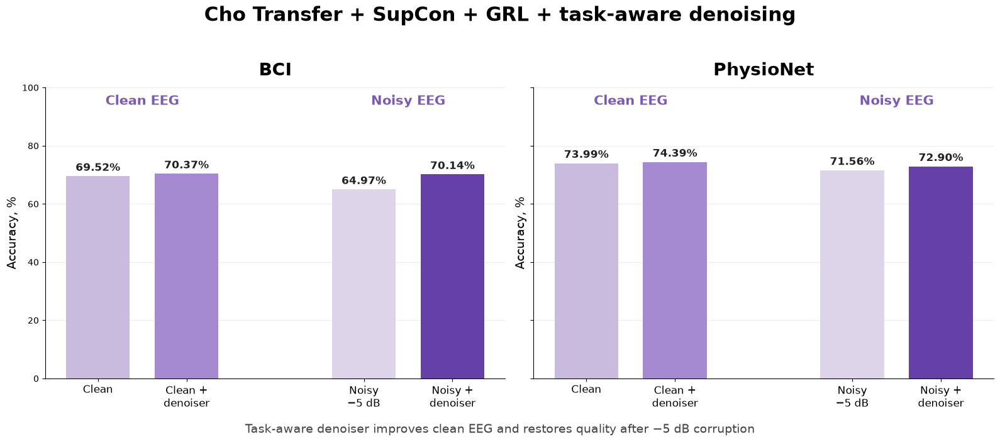

Saved to: /Users/irina/Desktop/master project/results_v2/final_grl_taskaware_denoising/results/final_grl_taskaware_denoising_grouped_purple_clean.png


: 

In [ ]:
# ============================================================
# FINAL PLOT: clean / clean+denoiser and noisy / noisy+denoiser
# without arrows and without +pp annotations
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# 1. PATHS
# -----------------------------
summary_path = Path(
    "/Users/irina/Desktop/master project/results_v2/final_grl_taskaware_denoising/results/FINAL_GRL_TASKAWARE_DENOISING_SUMMARY.csv"
)

out_dir = summary_path.parent
out_path = out_dir / "final_grl_taskaware_denoising_grouped_purple_clean.png"

# -----------------------------
# 2. LOAD DATA
# -----------------------------
df = pd.read_csv(summary_path)

print("Loaded:")
display(df)

# ожидаем строки для BCI и PhysioNet
# ожидаемые колонки:
# dataset
# clean_accuracy_pct
# clean_denoised_accuracy_pct
# noisy_accuracy_pct
# noisy_denoised_accuracy_pct

# -----------------------------
# 3. COLORS
# -----------------------------
# твои фиолетовые
c_clean = "#c8bbdd"             # светлый
c_clean_denoised = "#a68ad1"    # средний
c_noisy = "#ddd4ea"             # очень светлый
c_noisy_denoised = "#6540a8"    # тёмный

# -----------------------------
# 4. FIGURE
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
fig.suptitle(
    "Cho Transfer + SupCon + GRL + task-aware denoising",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

dataset_order = ["BCI", "PhysioNet"]

for ax, dataset in zip(axes, dataset_order):
    row = df[df["dataset"] == dataset]
    if row.empty:
        ax.set_title(f"{dataset}\n(no data)")
        ax.axis("off")
        continue

    row = row.iloc[0]

    values = [
        row["clean_accuracy_pct"],
        row["clean_denoised_accuracy_pct"],
        row["noisy_accuracy_pct"],
        row["noisy_denoised_accuracy_pct"],
    ]

    labels = [
        "Clean",
        "Clean +\ndenoiser",
        "Noisy\n−5 dB",
        "Noisy +\ndenoiser",
    ]

    colors = [
        c_clean,
        c_clean_denoised,
        c_noisy,
        c_noisy_denoised,
    ]

    # делаем две визуальные группы: clean и noisy
    x = np.array([0.0, 1.0, 3.0, 4.0])

    bars = ax.bar(
        x,
        values,
        width=0.72,
        color=colors,
        edgecolor="none"
    )

    # подписи значений
    for bar, v in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.0,
            f"{v:.2f}%",
            ha="center",
            va="bottom",
            fontsize=12,
            fontweight="bold",
            color="#222222"
        )

    # подписи групп сверху
    ax.text(
        0.5, 93, "Clean EEG",
        ha="center", va="bottom",
        fontsize=15, fontweight="bold",
        color="#7b5ab6"
    )
    ax.text(
        3.5, 93, "Noisy EEG",
        ha="center", va="bottom",
        fontsize=15, fontweight="bold",
        color="#7b5ab6"
    )

    ax.set_title(dataset, fontsize=20, fontweight="bold", pad=14)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Accuracy, %", fontsize=14)
    ax.grid(axis="y", alpha=0.22)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])

# нижняя подпись
fig.text(
    0.5,
    0.01,
    "Task-aware denoiser improves clean EEG and restores quality after −5 dB corruption",
    ha="center",
    fontsize=14,
    color="#444444"
)

plt.savefig(out_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved to:", out_path)